# Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import pickle
import os
import glob
import seaborn as sns
from project_support.csv_runs import load_ps_mapping, load_generation_path, load_full_fwd_path, active_model_tag, load_csv_path


In [2]:
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize,  TwoSlopeNorm
from matplotlib.cm import ScalarMappable
import pickle

In [3]:
from sklearn.decomposition import PCA

## df

In [4]:
df = pd.read_parquet(r'bert_trainset_squared_25.gzip')
print(df.shape)
df_uniques = [val for val in df['position_state'].unique()]
model_tag = active_model_tag('fixed')
ps_to_psid = load_ps_mapping(model_tag)
if not set(df['position_state']).issubset(ps_to_psid):
    raise ValueError('O mapeamento da execução não cobre todos os PS do dataset HardPos')
df['position_state_id'] = df['position_state'].map(ps_to_psid).astype(int)
print(len(df_uniques))
df.head(2)

(13134, 11)
947


,t,pos,distance_travelled,vel,rot_vel,head_direction,position_state,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
0,0.75,"[0.7, 0.89]",0.070249,"[-0.04648240511472945, -0.103916968250235]",-0.721635,"[-0.3147863504974622, -0.949162553802292]",XYCOAOWPMOWWNFTUVQEX,864,1.022175,973.0,1
1,0.80,"[0.699, 0.885]",0.075165,"[-0.02934323295077368, -0.09384195961539277]",2.351097,"[-0.3093471255142001, -0.9509491868318211]",XYCOAOWPMOWWNFTUKDZD,863,1.021119,968.0,1


In [5]:
df[['position_state_id', 'position_state']].nunique()

position_state_id    947
position_state       947
dtype: int64

## apd

In [6]:
ziped_apd = False

In [7]:
# if ziped_apd:
#     apd = pd.read_parquet('legacy/datasets/apd_ziped.gzip')
# else:
#     # apd = pd.read_parquet('legacy/datasets/apd_full.gzip')
#     pass

In [8]:
# print(apd.shape)
# apd_uniques = [val for val in apd['position_state'].unique()]
# print(len(apd_uniques))
# apd.head(2)

## model tag

In [9]:
model_tag = active_model_tag('fixed')

## ps_to_psid

In [10]:
# if 'position_state_id' not in apd.columns:
#     with open('ps_to_psid.pkl', 'rb') as file:
#         ps_to_psid = pickle.load(file)

In [11]:
# if 'position_state_id' not in apd.columns:
#     apd['position_state_id'] = [ps_to_psid[k] for k in apd['position_state']]

## embedd

In [12]:
embedd = pd.read_csv(load_csv_path(model_tag, f'embedded_repr_gpt_{model_tag}_post_train_.csv'))
embedd.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
0,1.886319,0.233336,2.802284,-0.242483,1.025219,1.979907,-0.094407,0.398704,-3.357631,-0.416332,-0.391563,0.261762,0.002882,0.054486,0.203981,-0.319169
1,2.512417,1.903164,1.506514,-1.796305,2.133879,-0.961400,-1.437213,-0.396162,-0.187099,-0.860769,0.182232,-0.754247,-0.154631,-0.758209,0.729075,-1.171603
2,1.236727,1.801739,0.703803,-1.189758,3.866140,-0.484955,1.694753,-0.552564,1.118507,0.050814,0.290727,-2.471865,-1.404263,-0.472266,-1.115611,1.985363
3,-2.066423,3.775364,2.377268,0.997272,2.538613,-0.004092,0.364976,1.583817,1.122885,-0.621693,0.840755,0.040218,-1.480299,-1.641287,-0.274392,1.711871
4,-0.026772,-1.127452,3.542208,0.330193,1.074454,-0.114597,-1.164997,2.276465,1.872326,1.424992,-0.199194,-1.812876,-0.482782,0.000328,0.326988,1.494101


## cossim

### pre train

In [13]:
coss_pre_train = pd.read_csv(load_csv_path(model_tag, f"cosine_similarity_matrix_gpt_pre_train_{model_tag}.csv"),)
print(coss_pre_train.shape)
coss_pre_train.head(5)

(948, 948)


,0,1,2,3,4,5,6,7,8,9,...,938,939,940,941,942,943,944,945,946,947
0,1.000000,0.044635,-0.124699,-0.118096,0.087774,-0.154702,0.292279,-0.393237,0.144094,0.018389,...,0.519528,0.443823,-0.125644,0.293885,-0.146256,-0.462000,0.420652,-0.174844,0.190064,0.0
1,0.044635,1.000000,0.372878,-0.206341,0.266927,-0.282136,-0.159818,0.210908,-0.073049,-0.111195,...,-0.025143,0.094237,-0.228535,-0.242449,-0.292494,0.114530,0.020957,-0.070048,0.484795,0.0
2,-0.124699,0.372878,1.000000,0.084410,0.362170,0.131163,0.002694,-0.117624,-0.164924,-0.197381,...,-0.044261,0.070680,0.055458,-0.166386,-0.340333,-0.043799,0.002834,0.202574,0.127705,0.0
3,-0.118096,-0.206341,0.084410,1.000000,-0.172358,-0.428509,-0.064528,0.224249,-0.213274,0.097782,...,-0.373769,0.409324,0.355733,0.114461,-0.033143,0.116396,-0.159492,-0.050039,0.163385,0.0
4,0.087774,0.266927,0.362170,-0.172358,1.000000,0.207259,-0.217128,-0.021895,-0.340553,-0.216390,...,0.244391,-0.218869,0.211245,-0.593633,0.045237,-0.247859,0.259121,0.280483,0.083597,0.0


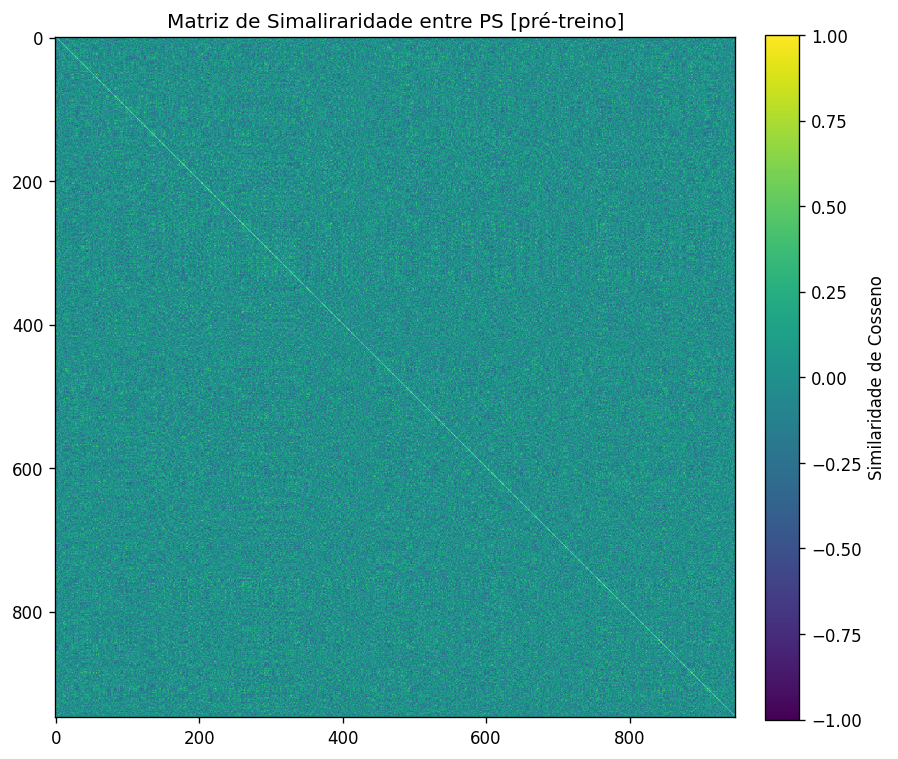

In [14]:
fig, ax = plt.subplots(figsize=(8, 8), dpi=120, )
p = plt.imshow(coss_pre_train,  vmin=-1, vmax=1)
cbar = plt.colorbar(p, fraction=0.046, pad=0.04,)
plt.title('Matriz de Simaliraridade entre PS [pré-treino]')
cbar.set_label("Similaridade de Cosseno")
plt.show()

In [15]:
coss_pre_train.columns

Index(['0', '1', '2', '3', '4', '5', '6', '7', '8', '9',
       ...
       '938', '939', '940', '941', '942', '943', '944', '945', '946', '947'],
      dtype='object', length=948)

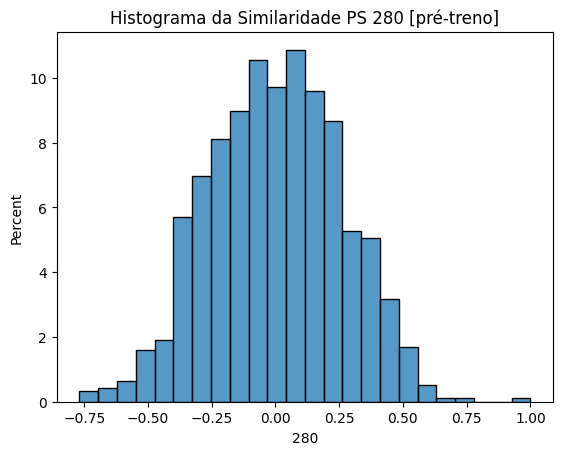

In [16]:
psid = 280
sns.histplot(coss_pre_train[f'{psid}'], stat='percent')
plt.title(f"Histograma da Similaridade PS {psid} [pré-treno]")
plt.show()

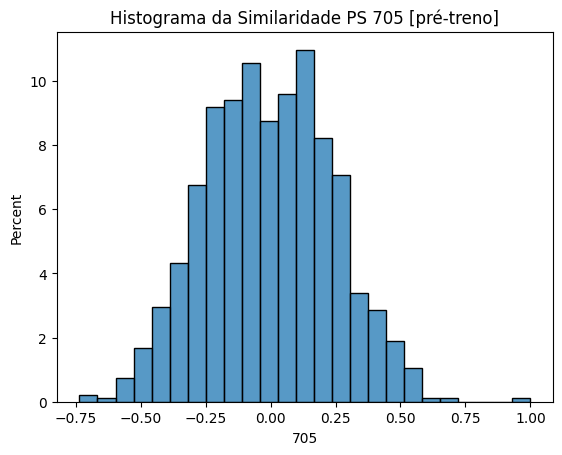

In [17]:
psid = 705
sns.histplot(coss_pre_train[f'{psid}'], stat='percent')
plt.title(f"Histograma da Similaridade PS {psid} [pré-treno]")
plt.show()

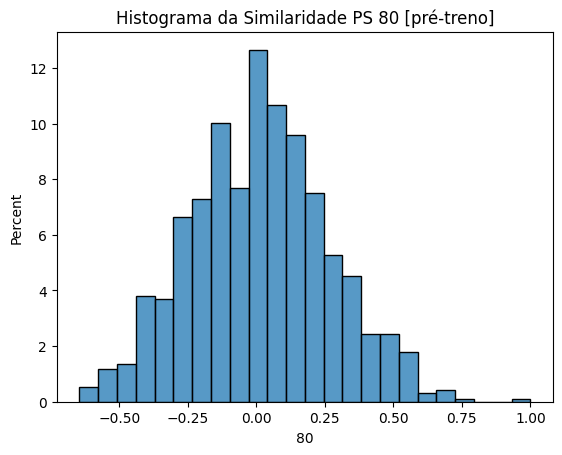

In [18]:
psid = 80
sns.histplot(coss_pre_train[f'{psid}'], stat='percent')
plt.title(f"Histograma da Similaridade PS {psid} [pré-treno]")
plt.show()

### mid train

In [19]:
coss_train_250 = pd.read_csv(load_csv_path(model_tag, f"cosine_similarity_matrix_gpt_{model_tag}_train_epoch_199.csv"),)
print(coss_train_250.shape)
coss_train_250.head(5)

(948, 948)


,0,1,2,3,4,5,6,7,8,9,...,938,939,940,941,942,943,944,945,946,947
0,1.000000,0.111174,-0.031946,-0.057153,0.064999,-0.196906,0.242611,-0.397829,-0.036204,0.248498,...,0.441852,0.118536,0.078637,0.066777,-0.365200,-0.432163,0.176622,-0.297483,-0.009345,0.0
1,0.111174,1.000000,0.435828,-0.043936,0.295160,-0.098897,-0.115837,-0.028554,-0.415171,-0.431911,...,0.226431,-0.032037,-0.016295,-0.263767,-0.426316,0.033254,0.058513,-0.116578,0.224895,0.0
2,-0.031946,0.435828,1.000000,0.031947,0.371938,0.206240,-0.143628,-0.228838,-0.408690,-0.454724,...,0.303023,0.021869,0.388775,-0.166862,-0.227336,-0.014613,0.051738,0.258463,0.199176,0.0
3,-0.057153,-0.043936,0.031947,1.000000,0.125294,-0.444982,0.058510,0.528877,-0.025582,0.094638,...,-0.177602,0.408702,0.400083,-0.099196,0.075637,0.107642,-0.033161,-0.194252,0.307720,0.0
4,0.064999,0.295160,0.371938,0.125294,1.000000,0.347418,-0.037670,0.149309,-0.039109,-0.090069,...,0.283556,-0.134001,0.145759,-0.573899,-0.120290,-0.189995,0.072231,0.104109,0.014866,0.0


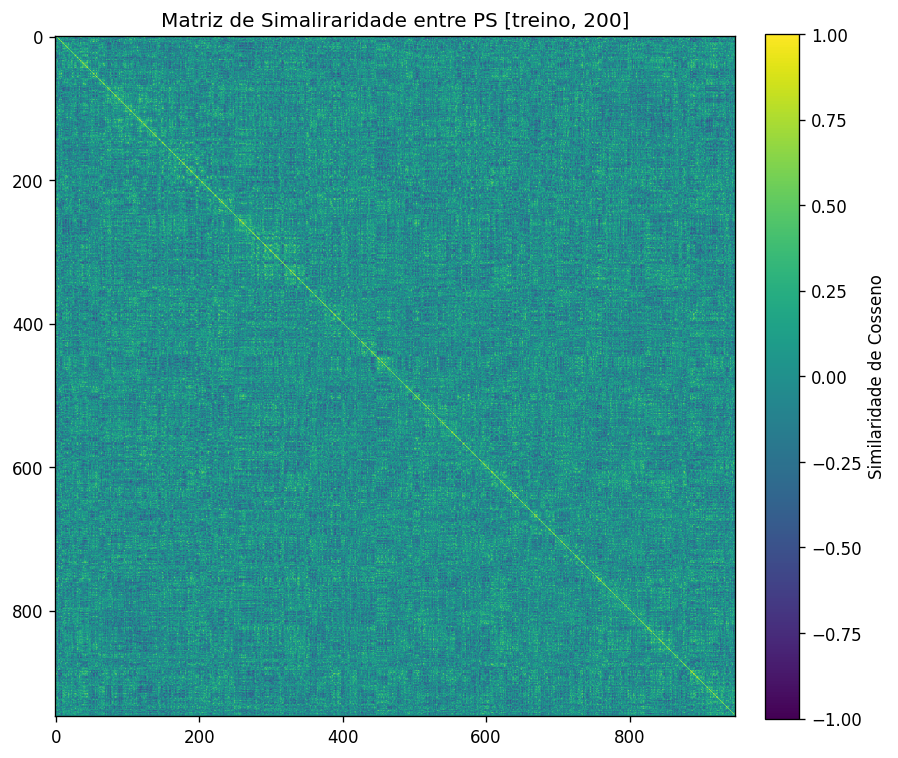

In [20]:
fig, ax = plt.subplots(figsize=(8,8), dpi=120, )
p = plt.imshow(coss_train_250,  vmin=-1, vmax=1)
cbar = plt.colorbar(p, fraction=0.046, pad=0.04,)
plt.title('Matriz de Simaliraridade entre PS [treino, 200]')
cbar.set_label("Similaridade de Cosseno")
plt.show()

### after train

In [21]:
coss = pd.read_csv(load_csv_path(model_tag, f"cosine_similarity_matrix_gpt_{model_tag}_post_train_.csv"),)
print(coss.shape)
coss.head(5)

(948, 948)


,0,1,2,3,4,5,6,7,8,9,...,938,939,940,941,942,943,944,945,946,947
0,1.000000,0.407463,0.065540,0.058100,0.121771,0.030879,0.201816,-0.172730,-0.277108,0.032971,...,-0.205722,-0.062995,-0.300353,-0.542470,-0.367430,-0.389151,0.157197,-0.426742,-0.080331,0.0
1,0.407463,1.000000,0.467194,0.224048,0.134575,0.420071,-0.239856,-0.125413,-0.536083,-0.491130,...,-0.025277,0.042701,0.138558,-0.336718,-0.254327,0.045946,0.152454,-0.068391,0.037229,0.0
2,0.065540,0.467194,1.000000,0.527499,0.299671,0.659297,-0.147061,-0.032726,-0.206529,-0.398774,...,0.148237,0.174043,0.500208,-0.070692,0.036207,0.110418,0.095447,0.210573,0.340779,0.0
3,0.058100,0.224048,0.527499,1.000000,0.380982,0.113801,0.034692,0.526354,0.046723,-0.219763,...,-0.080569,0.037008,0.397176,-0.189630,0.183232,-0.040472,-0.176949,-0.109744,0.111979,0.0
4,0.121771,0.134575,0.299671,0.380982,1.000000,0.469834,0.343063,0.559522,0.440797,0.239480,...,0.182120,0.004773,-0.070081,-0.395451,-0.013266,0.025975,-0.201188,0.005441,0.002946,0.0


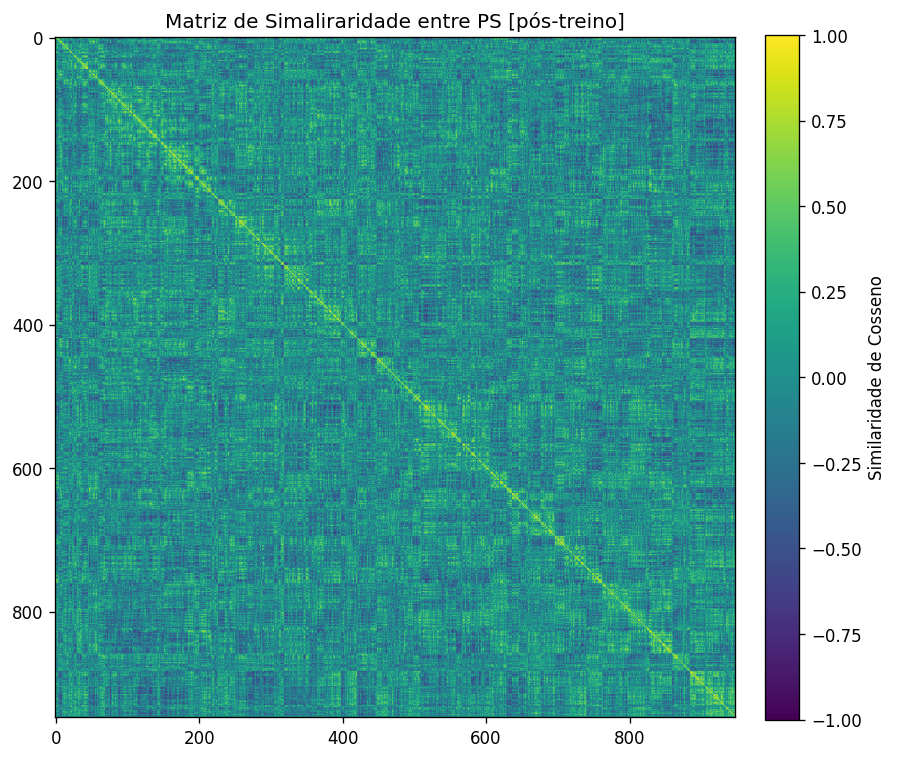

In [22]:
fig, ax = plt.subplots(figsize=(8, 8), dpi=120, )
p = plt.imshow(coss,  vmin=-1, vmax=1)
cbar = plt.colorbar(p, fraction=0.046, pad=0.04,)
plt.title('Matriz de Simaliraridade entre PS [pós-treino]')
cbar.set_label("Similaridade de Cosseno")
plt.show()

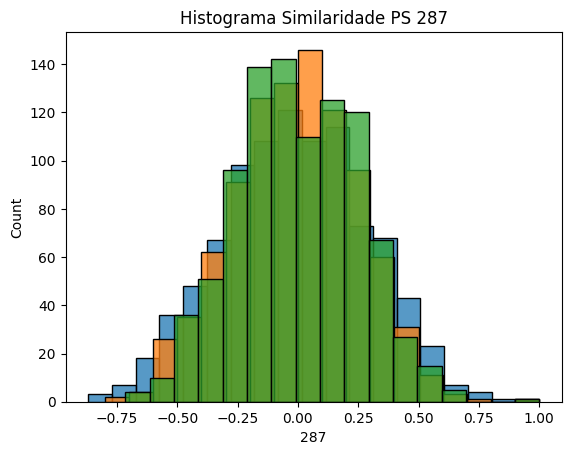

In [23]:
psid = 287

sns.histplot(coss[f'{psid}'], label='pós-treino', binwidth=0.1)
sns.histplot(coss_train_250[f'{psid}'], label='treino, 250', binwidth=0.1)
sns.histplot(coss_pre_train[f'{psid}'], label='pré-treino', binwidth=0.1)

plt.title(f'Histograma Similaridade PS {psid}')
plt.show()

In [24]:
coss_pre_train.sort_values(['287'], ascending=False).index[1:10]

Index([579, 757, 747, 393, 240, 814, 902, 642, 940], dtype='int64')

In [25]:
coss_train_250.sort_values(['287'], ascending=False).index[1:10]

Index([719, 512, 797, 579, 801, 593, 942, 336, 643], dtype='int64')

In [26]:
coss.sort_values(['287'], ascending=False).index[1:10]

Index([170, 195, 296, 312, 313, 282, 762, 821, 197], dtype='int64')

## distribs probs

In [27]:
distribs_probs = pd.read_csv(load_csv_path(model_tag, f'{model_tag}_gpt_probs_distribs_681.csv'),)
print(distribs_probs.shape)
distribs_probs.head(2)

(948, 10)


,Passo 01,Passo 02,Passo 03,Passo 04,Passo 05,Passo 06,Passo 07,Passo 08,Passo 09,Passo 10
0,7.370125e-21,1.976884e-20,2.497287e-21,1.573701e-20,1.467341e-20,3.350736e-21,6.415577e-21,8.922641e-23,2.268560e-19,6.891814e-22
1,2.862838e-13,2.661675e-13,6.980194e-14,5.030135e-14,3.973920e-14,8.324479e-14,1.416495e-13,5.723143e-14,1.274597e-11,6.194243e-14


In [28]:
distribs_probs507 = pd.read_csv(load_csv_path(model_tag, f'{model_tag}_gpt_probs_distribs_507.csv'),)
print(distribs_probs507.shape)
distribs_probs507.head(2)

(948, 10)


,Passo 01,Passo 02,Passo 03,Passo 04,Passo 05,Passo 06,Passo 07,Passo 08,Passo 09,Passo 10
0,4.685255e-12,1.172020e-15,1.898814e-15,2.240729e-17,1.954652e-13,4.376545e-19,6.449685e-17,2.480904e-15,2.602273e-17,2.395028e-15
1,8.826199e-13,1.413715e-16,1.251987e-17,7.394399e-14,5.233901e-18,2.089856e-15,4.902760e-21,2.148213e-17,8.405668e-22,1.135831e-17


## distrib logits

In [29]:
distribs_logits = pd.read_csv(load_csv_path(model_tag, f'{model_tag}_gpt_logits_distribs_681.csv'),)
print(distribs_logits.shape)
distribs_logits.head(2)

(948, 10)


,Passo 01,Passo 02,Passo 03,Passo 04,Passo 05,Passo 06,Passo 07,Passo 08,Passo 09,Passo 10
0,-16.262333,-16.190445,-17.796990,-17.216620,-16.934036,-17.309092,-16.776285,-17.176770,-11.571705,-16.227724
1,1.212725,0.225087,-0.651025,-2.239093,-2.122222,-0.280978,0.133853,3.102422,6.272460,2.086244


In [30]:
distribs_logits507 = pd.read_csv(load_csv_path(model_tag, f'{model_tag}_gpt_logits_distribs_507.csv'),)
print(distribs_logits507.shape)
distribs_logits507.head(2)

(948, 10)


,Passo 01,Passo 02,Passo 03,Passo 04,Passo 05,Passo 06,Passo 07,Passo 08,Passo 09,Passo 10
0,2.110952,-2.245926,-3.085356,-7.244628,3.930718,-13.343520,-2.929445,-2.824137,-3.681370,-2.724440
1,0.441671,-4.361021,-8.107024,0.857047,-6.597263,-4.872342,-12.414021,-7.573295,-14.021774,-8.075641


## raw logits

In [31]:
distribs_raw_logits = pd.read_csv(load_csv_path(model_tag, f'{model_tag}_gpt_logits_raw_distribs_681.csv'),)
print(distribs_raw_logits.shape)
distribs_raw_logits.head(2)

(948, 10)


,Passo 01,Passo 02,Passo 03,Passo 04,Passo 05,Passo 06,Passo 07,Passo 08,Passo 09,Passo 10
0,-16.262333,-16.190445,-17.796990,-17.216620,-16.934036,-17.309092,-16.776285,-17.176770,-11.571705,-16.227724
1,1.212725,0.225087,-0.651025,-2.239093,-2.122222,-0.280978,0.133853,3.102422,6.272460,2.086244


## full fwd

In [32]:
with open(load_full_fwd_path(model_tag, f'full_fwd_{model_tag}'), 'rb') as fil:
        full_fwd = pickle.load(fil)

In [33]:
with open(load_full_fwd_path(model_tag, f'full_fwd_pre_train_{model_tag}'), 'rb') as fil:
        full_fwd_pre_train = pickle.load(fil)

In [34]:
with open(load_full_fwd_path(model_tag, f'full_fwd_train_epoch_99_{model_tag}'), 'rb') as fil:
        full_fwd_100 = pickle.load(fil)

In [35]:
with open(load_full_fwd_path(model_tag, f'full_fwd_train_epoch_199_{model_tag}'), 'rb') as fil:
        full_fwd_200 = pickle.load(fil)

In [36]:
with open(load_full_fwd_path(model_tag, f'full_fwd_train_epoch_499_{model_tag}'), 'rb') as fil:
        full_fwd_500 = pickle.load(fil)

In [37]:
full_fwd_500.keys()

dict_keys(['tokens', 'token_embedding', 'position_embedding', 'embedding_plus_position', 'embedded_data', 'W_q', 'W_k', 'W_v', 'b_q', 'b_k', 'b_v', 'q', 'k', 'v', 'similarity_raw', 'similarity_masked', 'attention_probs', 'attention_output', 'after_attention_block', 'linear1', 'activation', 'linear2', 'after_ffn_block', 'logits', 'attn_weights', 'attention_weighted_values', 'W_linear1', 'b_linear1', 'W_linear2', 'b_linear2', 'W_fc_out', 'b_fc_out', 'probs', 'pred_ids'])

## q, k, v, s cossim

In [38]:
def build_token_cosine_matrices_df(embedded_data, full_fwd, use_positional=False, pos_index=0):
    """
    Retorna DataFrames V x V com similaridade de cosseno entre:
      - q_i
      - k_i
      - v_i
      - s_i  (assinatura relacional, linha de S = QK^T/sqrt(d))

    Saída:
        {
            "q_cos": pd.DataFrame,
            "k_cos": pd.DataFrame,
            "v_cos": pd.DataFrame,
            "s_cos": pd.DataFrame,
        }
    """

    def cosine_matrix(X):
        X = np.asarray(X, dtype=np.float64)
        norms = np.linalg.norm(X, axis=1, keepdims=True)
        norms = np.clip(norms, 1e-12, None)
        Xn = X / norms
        return Xn @ Xn.T

    E = np.asarray(embedded_data, dtype=np.float64).copy()   # [V, D]

    W_q = np.asarray(full_fwd["W_q"], dtype=np.float64)
    W_k = np.asarray(full_fwd["W_k"], dtype=np.float64)
    W_v = np.asarray(full_fwd["W_v"], dtype=np.float64)

    b_q = np.asarray(full_fwd["b_q"], dtype=np.float64)
    b_k = np.asarray(full_fwd["b_k"], dtype=np.float64)
    b_v = np.asarray(full_fwd["b_v"], dtype=np.float64)

    vocab_size, d_model = E.shape

    if use_positional:
        pos_mat = np.asarray(full_fwd["position_embedding"], dtype=np.float64)
        pos_vec = pos_mat[pos_index]                  # [D]
        X = E + pos_vec[None, :]
    else:
        X = E

    Q = X @ W_q.T + b_q[None, :]                      # [V, D]
    K = X @ W_k.T + b_k[None, :]                      # [V, D]
    V = X @ W_v.T + b_v[None, :]                      # [V, D]

    S = (Q @ K.T) / np.sqrt(d_model)                  # [V, V]

    q_cos = cosine_matrix(Q)
    k_cos = cosine_matrix(K)
    v_cos = cosine_matrix(V)
    s_cos = cosine_matrix(S)

    idx = np.arange(vocab_size)

    return {
        "q_cos": pd.DataFrame(q_cos, index=idx, columns=idx),
        "k_cos": pd.DataFrame(k_cos, index=idx, columns=idx),
        "v_cos": pd.DataFrame(v_cos, index=idx, columns=idx),
        "s_cos": pd.DataFrame(s_cos, index=idx, columns=idx),
    }

In [39]:
mechadf = build_token_cosine_matrices_df(embedd, full_fwd)
mechadf.keys()

dict_keys(['q_cos', 'k_cos', 'v_cos', 's_cos'])

# An

## funcs

In [40]:
def plot_position_states_w_title(
    apd: pd.DataFrame,
    grupos_destacados,
    title: str = None,
    cor_outros: str = "#e0e0e0",   # pontos não destacados
    s_outros: int = 10,
    s_destacados: int = 28,
    annotate: bool = True,
    cmap_name: str = "viridis",
):
    """
    Plota os pontos do DataFrame 'apd' (colunas: X, Y, position_state_id),
    destacando 'grupos_destacados' com cores oriundas do colormap viridis,
    respeitando a ordem de aparecimento na lista:

    - ids ANTERIORES: recebem as primeiras cores do colormap, na ordem.
    - id ÚLTIMO: recebe a cor final do colormap (mais destacada).
    - Anotações (labels) sempre em preto.

    Parâmetros:
    - apd: DataFrame com colunas ['X','Y','position_state_id']
    - grupos_destacados: lista ordenada de ids (ordem define a sequência de cores)
    - title: título opcional
    - cor_outros, s_outros: cor e tamanho dos pontos não-destacados
    - s_destacados: tamanho dos pontos destacados
    - annotate: desenhar anotações das médias por grupo
    - cmap_name: nome do colormap (default 'viridis')
    """

    if not {"X", "Y", "position_state_id"}.issubset(apd.columns):
        raise ValueError("apd deve conter as colunas: 'X', 'Y', 'position_state_id'")

    # Remove duplicados preservando a ordem
    ordem_unica = list(dict.fromkeys(grupos_destacados))
    n = len(ordem_unica)

    plt.figure(figsize=(12, 12))

    # 1) Plota todos os pontos não destacados
    destaque_mask = apd["position_state_id"].isin(ordem_unica)
    outros = apd[~destaque_mask]
    if not outros.empty:
        plt.scatter(outros["X"], outros["Y"], color=cor_outros, s=s_outros, label="Outros", zorder=1)

    if n > 0:
        cmap = plt.get_cmap(cmap_name, max(n, 2))

        # Mapeia cores: anteriores = cmap(0..n-2), último = cmap(n-1)
        anteriores_ids = ordem_unica[:-1]
        ultimo_id = ordem_unica[-1]

        # --- Anteriores (na ordem, cada um com sua cor do viridis) ---
        for i, gid in enumerate(anteriores_ids):
            cor_i = cmap(i / (max(n - 1, 1)))  # normaliza 0..1 mesmo quando n-1 = 1
            grp = apd[apd["position_state_id"] == gid]
            if not grp.empty:
                plt.scatter(
                    grp["X"], grp["Y"],
                    color=cor_i, s=s_destacados,
                    label=None if i else "Destacados (anteriores)",
                    zorder=2
                )

        # --- Último (usa a ponta do colormap) ---
        grp_last = apd[apd["position_state_id"] == ultimo_id]
        if not grp_last.empty:
            cor_last = cmap(1.0)  # última cor do viridis
            plt.scatter(
                grp_last["X"], grp_last["Y"],
                color=cor_last, s=s_destacados,
                label="Destacado (último)",
                zorder=3
            )

        # --- Anotações (sempre em preto) ---
        if annotate:
            medias = apd[apd["position_state_id"].isin(ordem_unica)] \
                        .groupby("position_state_id")[["X", "Y"]].mean().reset_index()
            for _, row in medias.iterrows():
                plt.annotate(
                    str(row["position_state_id"]),
                    (row["X"], row["Y"]),
                    fontsize=8, alpha=0.95,
                    ha="center", va="center",
                    fontweight="bold",
                    color="black",  # sempre preto
                    zorder=4
                )

    # Layout
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(title if title else "Grupos destacados por position_state_id (viridis por ordem)")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True, alpha=0.3)
    plt.gca().set_aspect("equal", adjustable="box")

    # Legenda enxuta, se houver algo além de "Outros"
    handles, labels = plt.gca().get_legend_handles_labels()
    if handles:
        # remove duplicatas mantendo ordem
        seen = set()
        uniq_handles, uniq_labels = [], []
        for h, l in zip(handles, labels):
            if l not in seen and l != "":
                uniq_handles.append(h)
                uniq_labels.append(l)
                seen.add(l)
        plt.legend(uniq_handles, uniq_labels, loc="upper right")

    # Não chama plt.show(); quem usa decide salvar/mostrar

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

def plot_position_states_emphasis_w_title(
    apd: pd.DataFrame,
    grupos_destacados,
    title: str = None,
    cor_outros: str = "#e0e0e0",   # fundo (não destacados)
    s_outros: int = 10,
    s_prev: int = 26,              # anteriores (cinza escuro)
    s_penultimo: int = 28,         # penúltimo (preto)
    s_ultimo: int = 30,            # último (vermelho)
    annotate: bool = True,
    cor_prev: str = "#4a4a4a",     # cinza escuro
    cor_penultimo: str = "#000000",# preto
    cor_ultimo: str = "#d32f2f",   # vermelho
):
    """
    Plota conforme regra fixa de cores (sem colormap), **considerando a ÚLTIMA ocorrência
    de cada id** em `grupos_destacados`:

      - último  (id cuja ÚLTIMA ocorrência é a maior)     -> vermelho
      - penúltimo (2ª maior última ocorrência)            -> preto
      - anteriores (demais ids)                           -> cinza escuro
      - demais (não destacados)                           -> cinza claro
    """
    required = {"X", "Y", "position_state_id"}
    if not required.issubset(apd.columns):
        raise ValueError("apd deve conter as colunas: 'X', 'Y', 'position_state_id'")

    # --- pega a ÚLTIMA ocorrência de cada id ---
    last_idx = {}
    for i, gid in enumerate(grupos_destacados):
        last_idx[gid] = i  # sobrescreve, guardando SEMPRE a última posição

    if len(last_idx) == 0:
        # nada a destacar: só fundo
        plt.figure(figsize=(12, 12))
        plt.scatter(apd["X"], apd["Y"], color=cor_outros, s=s_outros, zorder=1)
        _finalize_axes(title)
        return

    # ids ordenados pelo índice da última ocorrência (crescentemente “antigos” → “recentes”)
    ids_by_last = sorted(last_idx.keys(), key=lambda k: last_idx[k])
    n = len(ids_by_last)

    # define grupos por papel (anteriores / penúltimo / último)
    if n == 1:
        anteriores_ids = []
        penultimo_id = None
        ultimo_id = ids_by_last[-1]
    elif n == 2:
        anteriores_ids = []
        penultimo_id = ids_by_last[-2]
        ultimo_id = ids_by_last[-1]
    else:
        anteriores_ids = ids_by_last[:-2]
        penultimo_id = ids_by_last[-2]
        ultimo_id = ids_by_last[-1]

    plt.figure(figsize=(12, 12))

    # 1) fundo (não destacados)
    destaque_mask = apd["position_state_id"].isin(ids_by_last)
    outros = apd[~destaque_mask]
    if not outros.empty:
        plt.scatter(outros["X"], outros["Y"], color=cor_outros, s=s_outros, label="Outros", zorder=1)

    # 2) anteriores (cinza escuro)
    for gid in anteriores_ids:
        grp = apd[apd["position_state_id"] == gid]
        if not grp.empty:
            plt.scatter(grp["X"], grp["Y"], color=cor_prev, s=s_prev, zorder=2)

    # 3) penúltimo (preto)
    if penultimo_id is not None:
        grp_pen = apd[apd["position_state_id"] == penultimo_id]
        if not grp_pen.empty:
            plt.scatter(grp_pen["X"], grp_pen["Y"], color=cor_penultimo, s=s_penultimo, zorder=3)

    # 4) último (vermelho)
    grp_last = apd[apd["position_state_id"] == ultimo_id]
    if not grp_last.empty:
        plt.scatter(grp_last["X"], grp_last["Y"], color=cor_ultimo, s=s_ultimo, zorder=4, label="Último")

    # 5) anotações (opcional) – sobre ids distintos (pela última ocorrência)
    if annotate:
        
        medias = apd[apd["position_state_id"].isin(ids_by_last)] \
                    .groupby("position_state_id")[["X", "Y"]].mean().reset_index()
        for _, row in medias.iterrows():
            txt = plt.annotate(
                str(row["position_state_id"]),
                (row["X"], row["Y"]),
                fontsize=8, ha="center", va="center",
                color="black", fontweight="bold", zorder=5
            )
            txt.set_path_effects([pe.withStroke(linewidth=2.5, foreground="white")])

    _finalize_axes(title if title else "Grupos destacados (última ocorrência: cinza/preto/vermelho)")


def _finalize_axes(title):
    """Acabamento padrão do gráfico."""
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(title)
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True, alpha=0.3)
    plt.gca().set_aspect("equal", adjustable="box")
    handles, labels = plt.gca().get_legend_handles_labels()
    if handles:
        seen, uniq_h, uniq_l = set(), [], []
        for h, l in zip(handles, labels):
            if l not in seen and l != "":
                uniq_h.append(h); uniq_l.append(l); seen.add(l)
        plt.legend(uniq_h, uniq_l, loc="upper right")


In [42]:
def plot_position_states(apd, grupos_destacados):
    """
    Plota os pontos do DataFrame apd (com colunas X, Y e position_state_id),
    destacando apenas os grupos na lista grupos_destacados, com anotações.

    Parâmetros:
    - apd: DataFrame com colunas 'X', 'Y' e 'position_state_id'
    - grupos_destacados: lista de valores de position_state_id a serem coloridos e anotados
    """
    # Criação da máscara de seleção
    destaque_mask = apd['position_state_id'].isin(grupos_destacados)

    # Define cores: branco ou cinza claro para os pontos não destacados
    cor_base = '#e0e0e0'
    
    plt.figure(figsize=(12, 12))

    # Plota todos os pontos em cinza claro
    plt.scatter(apd['X'], apd['Y'], color=cor_base, s=10,)

    # Plota apenas os pontos destacados com colormap
    destacados = apd[destaque_mask]
    if not destacados.empty:
        scatter = plt.scatter(destacados['X'], destacados['Y'],
                              c=destacados['position_state_id'], cmap='tab10', s=25, label='Destacados')

        # Anotar a média dos grupos destacados
        medias = destacados.groupby('position_state_id')[['X', 'Y']].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(row['position_state_id']), (row['X'], row['Y']),
                         fontsize=7, alpha=0.9, ha='center', va='center', fontweight='bold')

        # Adiciona colorbar apenas se houver grupos destacados
        # cbar = plt.colorbar(scatter)
        # cbar.set_label('position_state_id destacado')

    # Layout
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.title('Grupos destacados por position_state_id')
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.legend(loc='upper right')
    plt.show()

In [43]:
# plot_position_states(apd, [0, 220, 221, 950])

# Embedding

## pca

In [44]:
df.head()

,t,pos,distance_travelled,vel,rot_vel,head_direction,position_state,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
0,0.75,"[0.7, 0.89]",0.070249,"[-0.04648240511472945, -0.103916968250235]",-0.721635,"[-0.3147863504974622, -0.949162553802292]",XYCOAOWPMOWWNFTUVQEX,864,1.022175,973.0,1
1,0.80,"[0.699, 0.885]",0.075165,"[-0.02934323295077368, -0.09384195961539277]",2.351097,"[-0.3093471255142001, -0.9509491868318211]",XYCOAOWPMOWWNFTUKDZD,863,1.021119,968.0,1
2,0.90,"[0.698, 0.879]",0.081759,"[-0.014781629317759393, -0.04886508440626436]",-2.718846,"[-0.2694234454470962, -0.9630218102636179]",AOWPXYCOMOWWNFTUKDZD,67,0.080253,967.0,1
3,1.75,"[0.666, 0.84]",0.133414,"[-0.07658095338432869, -0.03239162333011025]",-3.094691,"[-0.7753741537587893, -0.6315021153431248]",AOWPMOWWXYCONFTUKDZD,42,0.048574,76.0,1
4,2.20,"[0.63, 0.825]",0.172443,"[-0.07400184852546676, -0.006027612039467556]",-2.263985,"[-0.9719050362633794, -0.23537332152535723]",AOWPMOWWXYCONFTUCEPV,41,0.047518,46.0,1


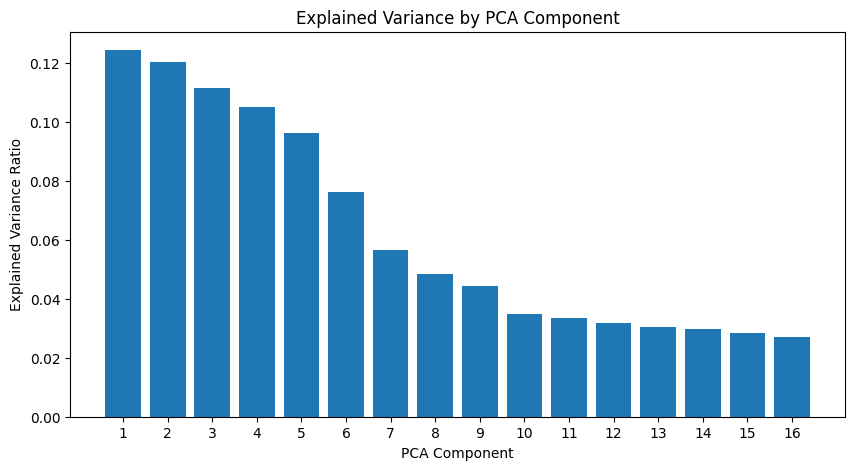

In [45]:
def parse_xy(pos_value):
    """
    Converts df['pos'] values into x, y.
    Works if pos is already a list/tuple/ndarray or a string like "[0.7, 0.89]".
    """
    if isinstance(pos_value, str):
        pos_value = ast.literal_eval(pos_value)
    return float(pos_value[0]), float(pos_value[1])


# =========================
# 1) Prepare embeddings
# =========================
# If embedd is already only numeric PCA-ready columns:
X = embedd.values

# Optional safety:
# X = embedd.select_dtypes(include=[np.number]).values

# =========================
# 2) Fit PCA
# =========================
pca = PCA()
X_pca = pca.fit_transform(X)

explained_var_ratio = pca.explained_variance_ratio_
cum_explained_var = np.cumsum(explained_var_ratio)

# =========================
# 3) Plot explained variance
# =========================
plt.figure(figsize=(10, 5))
plt.bar(
    range(1, len(explained_var_ratio) + 1),
    explained_var_ratio
)
plt.xlabel("PCA Component")
plt.ylabel("Explained Variance Ratio")
plt.title("Explained Variance by PCA Component")
plt.xticks(range(1, len(explained_var_ratio) + 1))
# plt.grid(alpha=0.3)
plt.show()



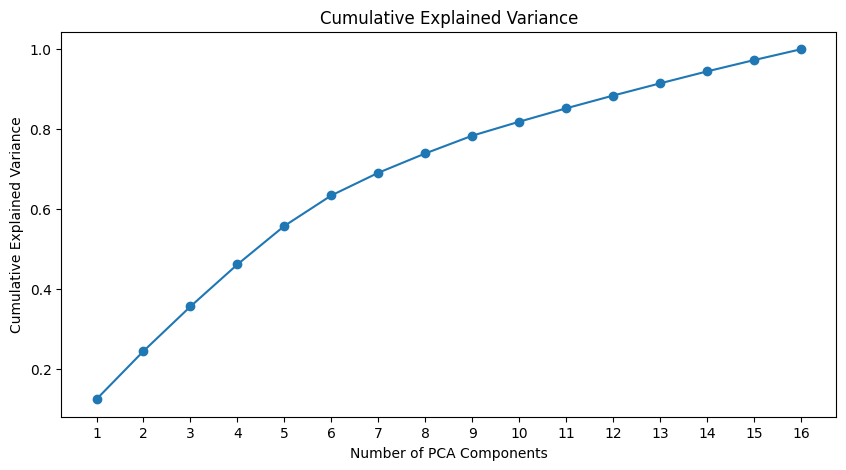

In [46]:
# Optional cumulative plot
plt.figure(figsize=(10, 5))
plt.plot(
    range(1, len(cum_explained_var) + 1),
    cum_explained_var,
    marker="o"
)
plt.xlabel("Number of PCA Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance")
plt.xticks(range(1, len(cum_explained_var) + 1))
# plt.grid(alpha=0.3)
plt.show()

In [47]:
def attach_pca_to_df_by_state_id(embedd, df, pos_col="pos", state_col="position_state_id"):

    def parse_xy(pos_value):
        if isinstance(pos_value, str):
            pos_value = ast.literal_eval(pos_value)
        return float(pos_value[0]), float(pos_value[1])

    X = embedd.select_dtypes(include=[np.number]).values

    pca = PCA()
    X_pca = pca.fit_transform(X)

    pca_df = pd.DataFrame(
        X_pca,
        index=embedd.index,
        columns=[f"PC{i+1}" for i in range(X_pca.shape[1])]
    )

    df_out = df.merge(
        pca_df,
        left_on=state_col,
        right_index=True,
        how="left"
    )

    xy = df_out[pos_col].apply(parse_xy)
    df_out["x_pos"] = xy.apply(lambda v: v[0])
    df_out["y_pos"] = xy.apply(lambda v: v[1])

    state_means = (
        df_out.groupby(state_col)
        .agg(
            mean_x=("x_pos", "mean"),
            mean_y=("y_pos", "mean")
        )
    )

    state_summary = pca_df.join(state_means, how="left")

    df_out = df_out.merge(
        state_means,
        left_on=state_col,
        right_index=True,
        how="left"
    )

    return pca, pca_df, df_out, state_summary

In [48]:
pca, pca_df, df_with_pca, state_pca_summary = attach_pca_to_df_by_state_id(embedd, df)

In [49]:
state_pca_summary[["PC1", "PC2", "mean_x", "mean_y"]].head()

,PC1,PC2,mean_x,mean_y
0,1.198741,1.488301,0.601500,0.611250
1,1.773978,-0.737063,0.612000,0.606000
2,0.744042,-1.332254,0.744500,0.724000
3,-3.642251,-0.842871,0.746571,0.740571
4,0.426257,2.147461,0.782143,0.688000


<Axes: xlabel='PC1', ylabel='PC2'>

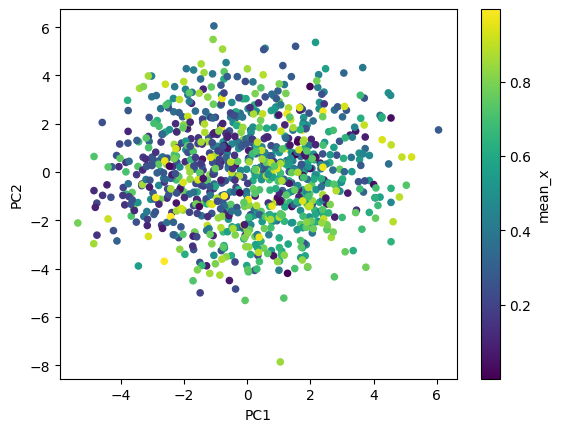

In [50]:
state_pca_summary.plot.scatter(x='PC1',y='PC2', c='mean_x')

<Axes: xlabel='mean_x', ylabel='mean_y'>

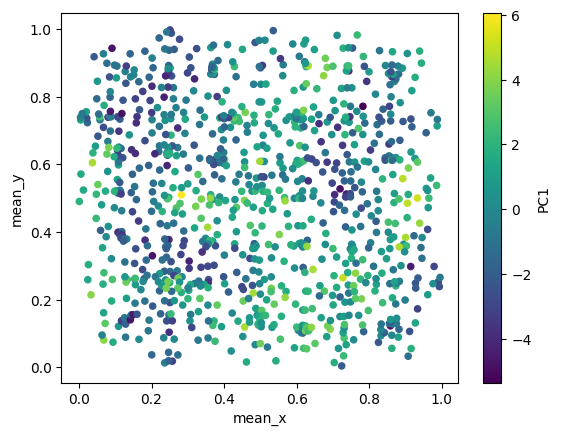

In [51]:
state_pca_summary.plot.scatter(x='mean_x',y='mean_y', c='PC1')

<Axes: xlabel='mean_x', ylabel='mean_y'>

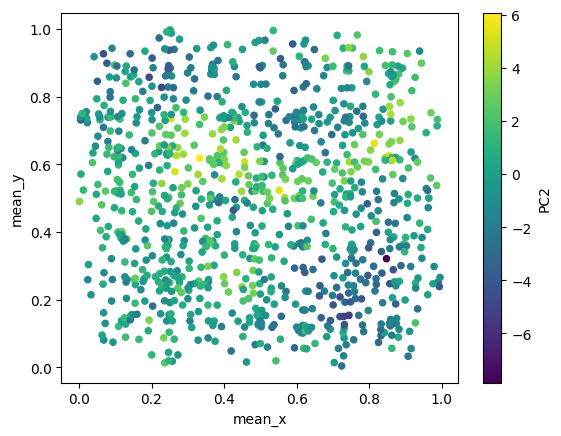

In [52]:
state_pca_summary.plot.scatter(x='mean_x',y='mean_y', c='PC2')

<Axes: xlabel='PC1', ylabel='PC2'>

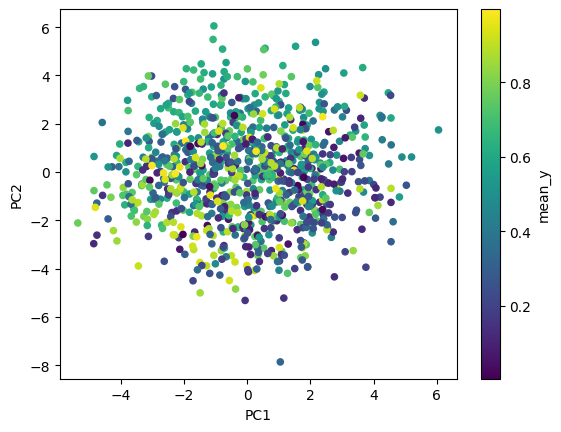

In [53]:
state_pca_summary.plot.scatter(x='PC1',y='PC2', c='mean_y')

## similarity

In [54]:
def _parse_xy(v):
    """
    Converte `pos` para (x, y).
    Aceita:
      - [x, y]
      - (x, y)
      - np.array([x, y])
      - string "[x, y]"
    """
    if isinstance(v, str):
        v = ast.literal_eval(v)

    if isinstance(v, (list, tuple, np.ndarray)) and len(v) == 2:
        return float(v[0]), float(v[1])

    raise ValueError(f"Valor inválido em pos: {v}")


def plot_cosine_similarity_map_no_env(
    df_states,
    cossim_df,
    current_id,
    *,
    pos_col="pos",
    id_col="position_state_id",
    xlim=(0.0, 1.0),
    ylim=(0.0, 1.0),
    figsize=(10, 10),
    cmap="coolwarm",
    current_color="lightgray",
    current_alpha=0.95,
    current_size=20,
    show_current_label=True,
    smooth_sigma=0.03,
    grid_size=250,
    min_support=1e-6,
    sim_power=1.0,
    use_abs_for_smoothing=False,
    clip_similarity=None,
    show_colorbar=True,
    env_linewidth=2.0,
    env_color="gray",
    grid=True,
    grid_alpha=0.7,
    interpolation="bilinear",
    similarity_id_offset=1,
    use_column_instead_of_row=False,
    title_tag = ''
):
    """
    Plota um mapa espacial suavizado de similaridade cosseno em relação a `current_id`,
    sem depender de Env.

    Regras:
    - o id atual é pintado em cinza
    - os outros ids são pintados pela similaridade cosseno com o id atual
    - a pintura é suavizada espacialmente com kernel gaussiano
    - o ambiente é desenhado manualmente entre 0 e 1 em x e y

    Parâmetros
    ----------
    df_states : pd.DataFrame
        DataFrame com colunas como [position_state_id, pos]
    cossim_df : pd.DataFrame
        Matriz quadrada de similaridade cosseno.
        Linhas e colunas representam ids deslocados por -1.
    current_id : int | str
        id atual do animal
    similarity_id_offset : int
        deslocamento entre o id do dataframe de estados e o índice/coluna da matriz.
        Ex.: se state_id=1 corresponde a índice 0, use 1.
    use_column_instead_of_row : bool
        se True, pega a coluna do id atual em vez da linha.
        Em matriz simétrica, tanto faz.
    use_abs_for_smoothing : bool
        se True, usa |similaridade| para espalhar intensidade espacial,
        mas mantém o sinal no mapa final.
    clip_similarity : tuple | None
        ex.: (-1, 1) ou (-0.5, 0.8)
    """

    # ----------------------------
    # prepara df_states
    # ----------------------------
    df = df_states.copy()

    xy = df[pos_col].apply(_parse_xy)
    df["_x"] = [p[0] for p in xy]
    df["_y"] = [p[1] for p in xy]

    if len(df[df[id_col] == current_id]) == 0:
        raise ValueError(f"Nenhuma linha encontrada para current_id={current_id}")

    # ----------------------------
    # resolve id atual na matriz de similaridade
    # ----------------------------
    current_sim_idx = int(current_id) - similarity_id_offset

    if current_sim_idx not in cossim_df.index and current_sim_idx not in cossim_df.columns:
        raise ValueError(
            f"O id atual {current_id} mapeia para {current_sim_idx}, "
            f"mas esse valor não existe no índice/colunas de cossim_df."
        )

    # linha ou coluna de similaridade
    if use_column_instead_of_row:
        sim_series = cossim_df[current_sim_idx].copy()
    else:
        sim_series = cossim_df.loc[current_sim_idx].copy()

    # garante índice numérico quando possível
    try:
        sim_series.index = sim_series.index.astype(int)
    except Exception:
        pass

    # ----------------------------
    # mapeia similarity para os ids reais do dataframe
    # id_real -> idx_matriz = id_real - offset
    # ----------------------------
    df["_sim_idx"] = df[id_col].astype(int) - similarity_id_offset
    sim_map = sim_series.to_dict()
    df["_sim"] = df["_sim_idx"].map(sim_map).fillna(0.0)

    if clip_similarity is not None:
        lo, hi = clip_similarity
        df["_sim"] = df["_sim"].clip(lo, hi)

    # separa id atual e outros
    df_current = df[df[id_col] == current_id].copy()
    df_other = df.copy()# df[df[id_col] != current_id].copy()

    # ajuste opcional de contraste
    if sim_power != 1.0:
        sign = np.sign(df_other["_sim"].to_numpy())
        mag = np.abs(df_other["_sim"].to_numpy())
        mag = np.power(mag, sim_power)
        df_other["_sim"] = sign * mag

    # ----------------------------
    # malha do ambiente
    # ----------------------------
    xmin, xmax = xlim
    ymin, ymax = ylim

    gx = np.linspace(xmin, xmax, grid_size)
    gy = np.linspace(ymin, ymax, grid_size)
    XX, YY = np.meshgrid(gx, gy)

    field = np.zeros_like(XX, dtype=float)
    support = np.zeros_like(XX, dtype=float)

    # ----------------------------
    # suavização espacial
    # ----------------------------
    if len(df_other) > 0 and np.any(np.abs(df_other["_sim"].to_numpy()) > 0):
        xs = df_other["_x"].to_numpy(float)
        ys = df_other["_y"].to_numpy(float)
        ws = df_other["_sim"].to_numpy(float)

        for x0, y0, w in zip(xs, ys, ws):
            d2 = (XX - x0) ** 2 + (YY - y0) ** 2
            k = np.exp(-0.5 * d2 / (smooth_sigma ** 2))
            field += w * k

            if use_abs_for_smoothing:
                support += np.abs(w) * k
            else:
                support += k

        smoothed = np.zeros_like(field)
        valid = support > min_support
        smoothed[valid] = field[valid] / support[valid]

        mask = ~valid
        smoothed = np.ma.array(smoothed, mask=mask)
    else:
        smoothed = np.ma.array(np.zeros_like(field), mask=np.ones_like(field, dtype=bool))

    # ----------------------------
    # normalização da escala de cor
    # ----------------------------
    if len(df_other) > 0:
        sim_vals = df_other["_sim"].to_numpy(float)
        vmax_abs = np.nanmax(np.abs(sim_vals)) if len(sim_vals) else 1.0
    else:
        vmax_abs = 1.0

    if not np.isfinite(vmax_abs) or vmax_abs <= 0:
        vmax_abs = 1.0

    norm = TwoSlopeNorm(vmin=-1., vcenter=0.0, vmax=1.)

    # ----------------------------
    # plot
    # ----------------------------
    fig, ax = plt.subplots(figsize=figsize)

    im = ax.imshow(
        smoothed,
        extent=[xmin, xmax, ymin, ymax],
        origin="lower",
        cmap=cmap,
        norm=norm,
        interpolation=interpolation,
        alpha=0.95,
        zorder=1,
    )

    # id atual em cinza
    ax.scatter(
        df_current["_x"],
        df_current["_y"],
        s=current_size,
        color=current_color,
        alpha=current_alpha,
        zorder=3,
        label=f"token={current_id}",
    )

    if show_current_label:
        cx = df_current["_x"].mean()
        cy = df_current["_y"].mean()
        ax.text(
            cx,
            cy,
            str(current_id),
            fontsize=10,
            color="black",
            ha="center",
            va="center",
            zorder=4,
        )

    # moldura manual do ambiente
    ax.plot([xmin, xmax], [ymin, ymin], color=env_color, linewidth=env_linewidth, zorder=5)
    ax.plot([xmin, xmax], [ymax, ymax], color=env_color, linewidth=env_linewidth, zorder=5)
    ax.plot([xmin, xmin], [ymin, ymax], color=env_color, linewidth=env_linewidth, zorder=5)
    ax.plot([xmax, xmax], [ymin, ymax], color=env_color, linewidth=env_linewidth, zorder=5)

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_aspect("equal")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    if len(title_tag) > 0:
        ax.set_title(f"Mapa de Similaridade PS {current_id} {title_tag}")
    else:
        ax.set_title(f"Mapa de Similaridade PS {current_id}")

    if grid:
        ax.grid(True, alpha=grid_alpha)

    ax.legend(loc="upper right", frameon=True)

    if show_colorbar:
        cbar = plt.colorbar(im, ax=ax,  fraction=0.046, pad=0.04,)
        cbar.set_label("Similaridade cosseno")

    plt.tight_layout()
    plt.show()

    return fig, ax

In [55]:
coss.head()

,0,1,2,3,4,5,6,7,8,9,...,938,939,940,941,942,943,944,945,946,947
0,1.000000,0.407463,0.065540,0.058100,0.121771,0.030879,0.201816,-0.172730,-0.277108,0.032971,...,-0.205722,-0.062995,-0.300353,-0.542470,-0.367430,-0.389151,0.157197,-0.426742,-0.080331,0.0
1,0.407463,1.000000,0.467194,0.224048,0.134575,0.420071,-0.239856,-0.125413,-0.536083,-0.491130,...,-0.025277,0.042701,0.138558,-0.336718,-0.254327,0.045946,0.152454,-0.068391,0.037229,0.0
2,0.065540,0.467194,1.000000,0.527499,0.299671,0.659297,-0.147061,-0.032726,-0.206529,-0.398774,...,0.148237,0.174043,0.500208,-0.070692,0.036207,0.110418,0.095447,0.210573,0.340779,0.0
3,0.058100,0.224048,0.527499,1.000000,0.380982,0.113801,0.034692,0.526354,0.046723,-0.219763,...,-0.080569,0.037008,0.397176,-0.189630,0.183232,-0.040472,-0.176949,-0.109744,0.111979,0.0
4,0.121771,0.134575,0.299671,0.380982,1.000000,0.469834,0.343063,0.559522,0.440797,0.239480,...,0.182120,0.004773,-0.070081,-0.395451,-0.013266,0.025975,-0.201188,0.005441,0.002946,0.0


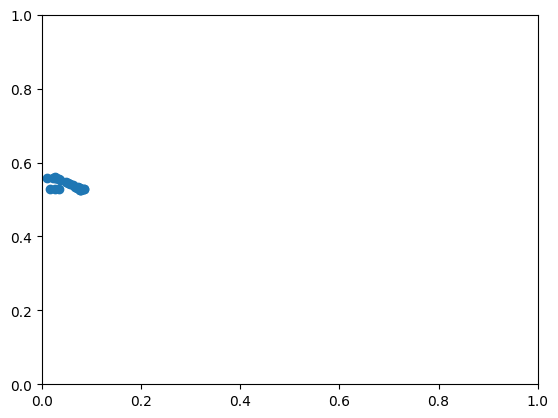

In [56]:
x_values = [val[0] for val in df[df['position_state_id'] == 339]['pos']]
y_values = [val[1] for val in df[df['position_state_id'] == 339]['pos']]

fig, ax = plt.subplots()
plt.scatter(x_values, y_values)
plt.ylim(0, 1)
plt.xlim(0, 1)
plt.show()

### pre train embedd

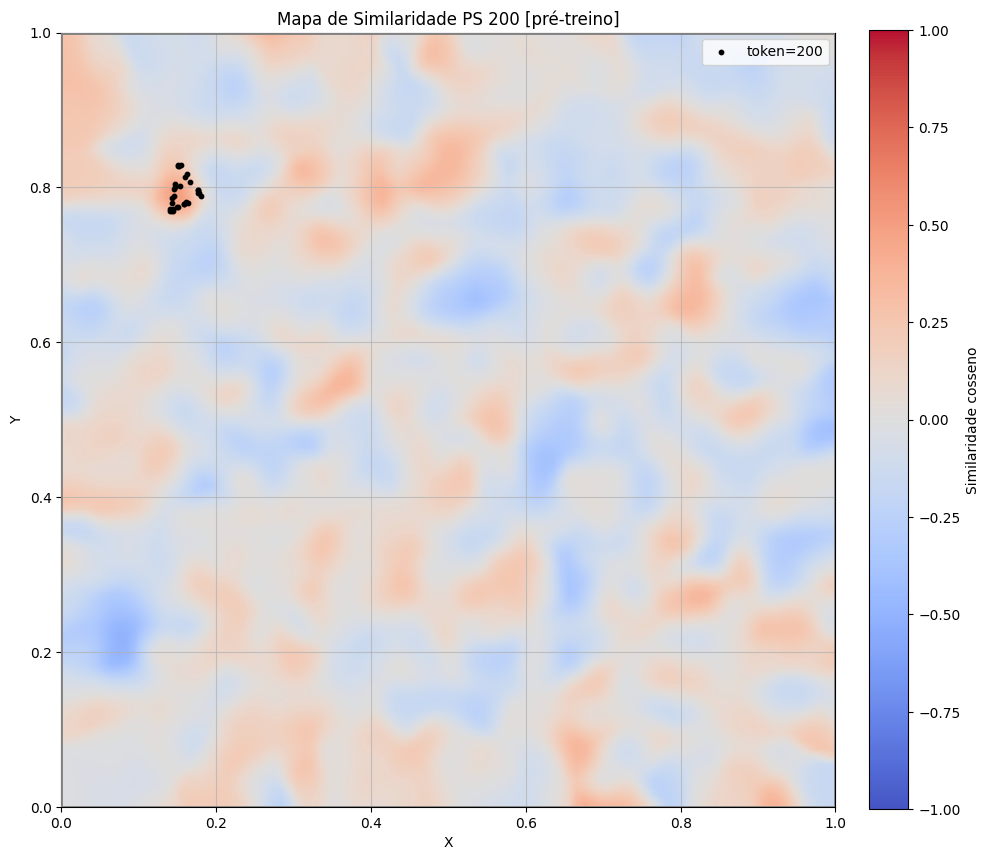

In [57]:
plot_cosine_similarity_map_no_env(
    df_states=df,
    cossim_df=coss_pre_train,
    current_id=200,
    similarity_id_offset=0,
    cmap="coolwarm",
    smooth_sigma=0.015,
    grid_size=100,
    sim_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag = '[pré-treino]'
)
plt.show()

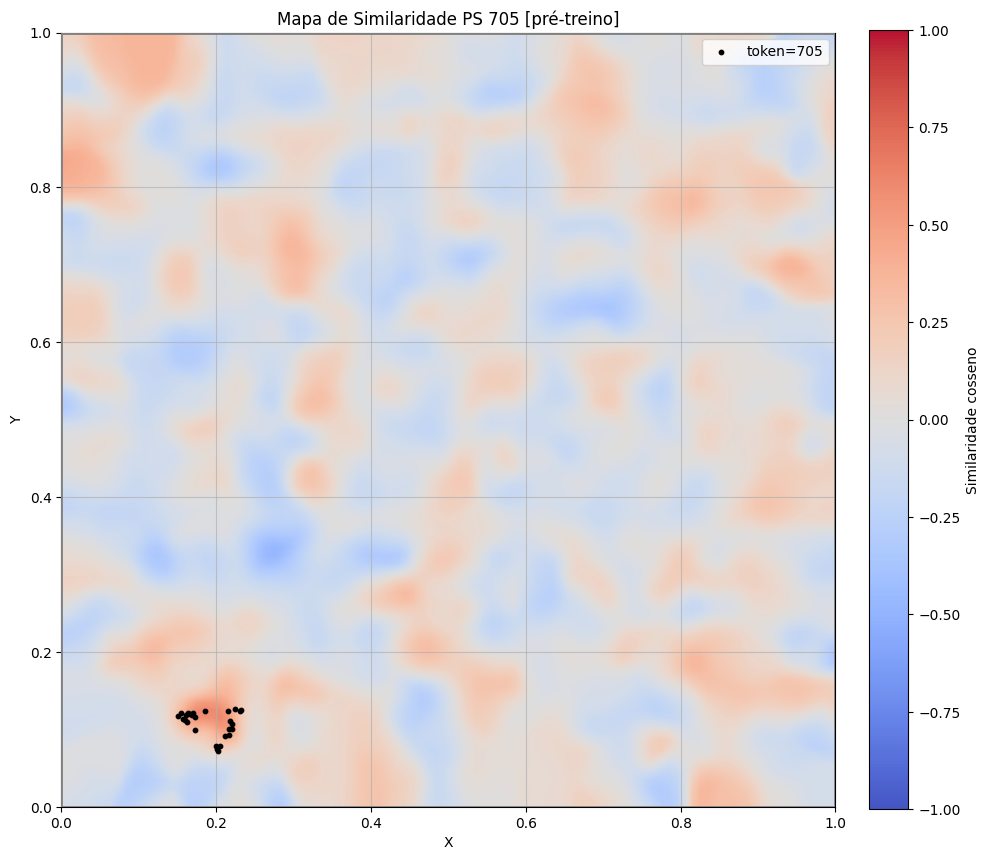

In [58]:
plot_cosine_similarity_map_no_env(
    df_states=df,
    cossim_df=coss_pre_train,
    current_id=705,
    similarity_id_offset=0,
    cmap="coolwarm",
    smooth_sigma=0.015,
    grid_size=100,
    sim_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag = '[pré-treino]'
)
plt.show()

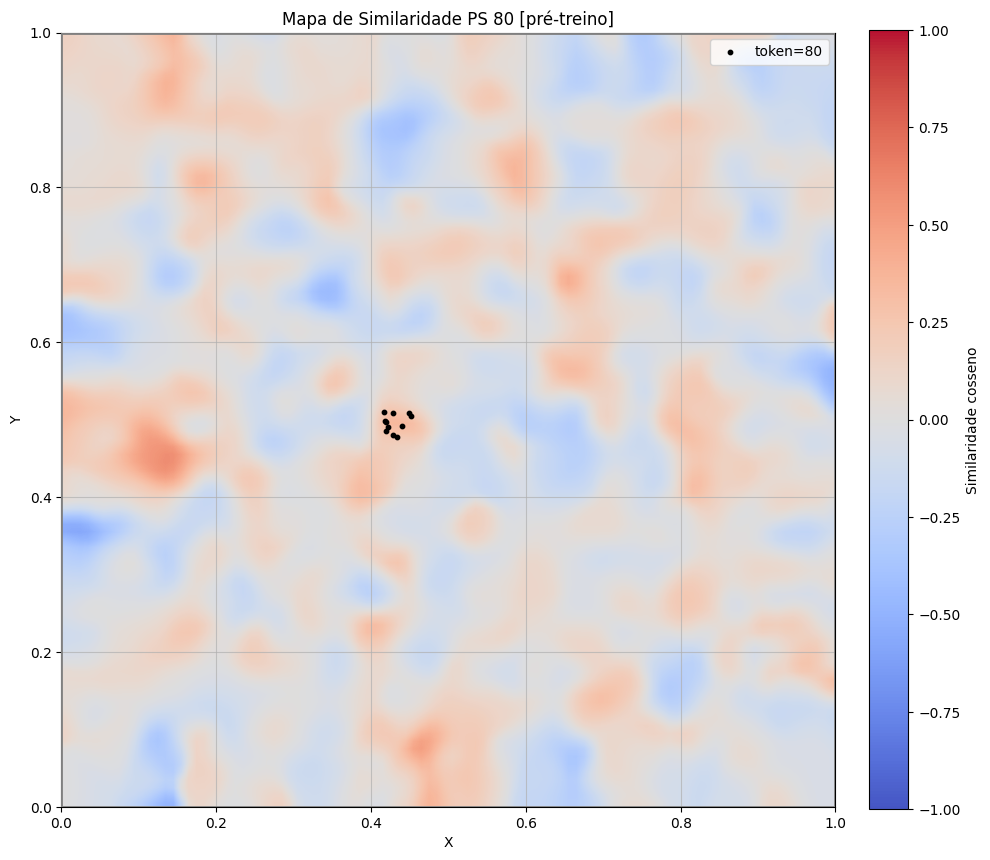

In [59]:
plot_cosine_similarity_map_no_env(
    df_states=df,
    cossim_df=coss_pre_train,
    current_id=80,
    similarity_id_offset=0,
    cmap="coolwarm",
    smooth_sigma=0.015,
    grid_size=100,
    sim_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag = '[pré-treino]'
)
plt.show()

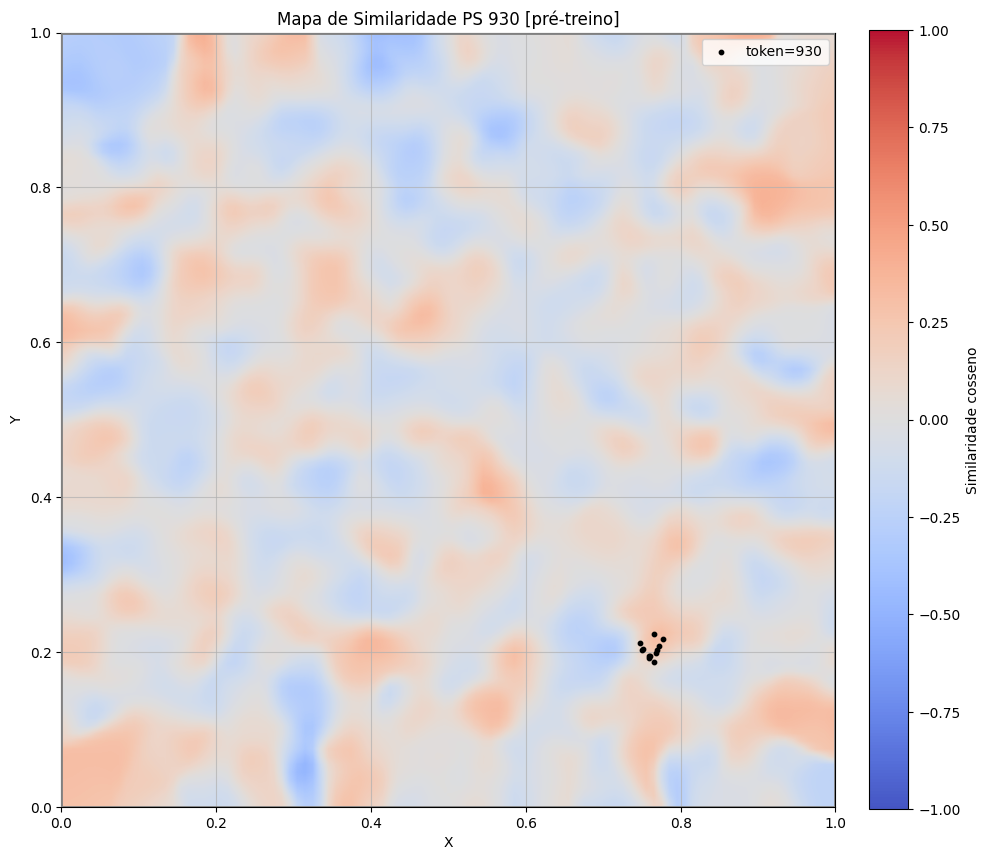

In [60]:
plot_cosine_similarity_map_no_env(
    df_states=df,
    cossim_df=coss_pre_train,
    current_id=930,
    similarity_id_offset=0,
    cmap="coolwarm",
    smooth_sigma=0.015,
    grid_size=100,
    sim_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag = '[pré-treino]'
)
plt.show()

### mid train embedd

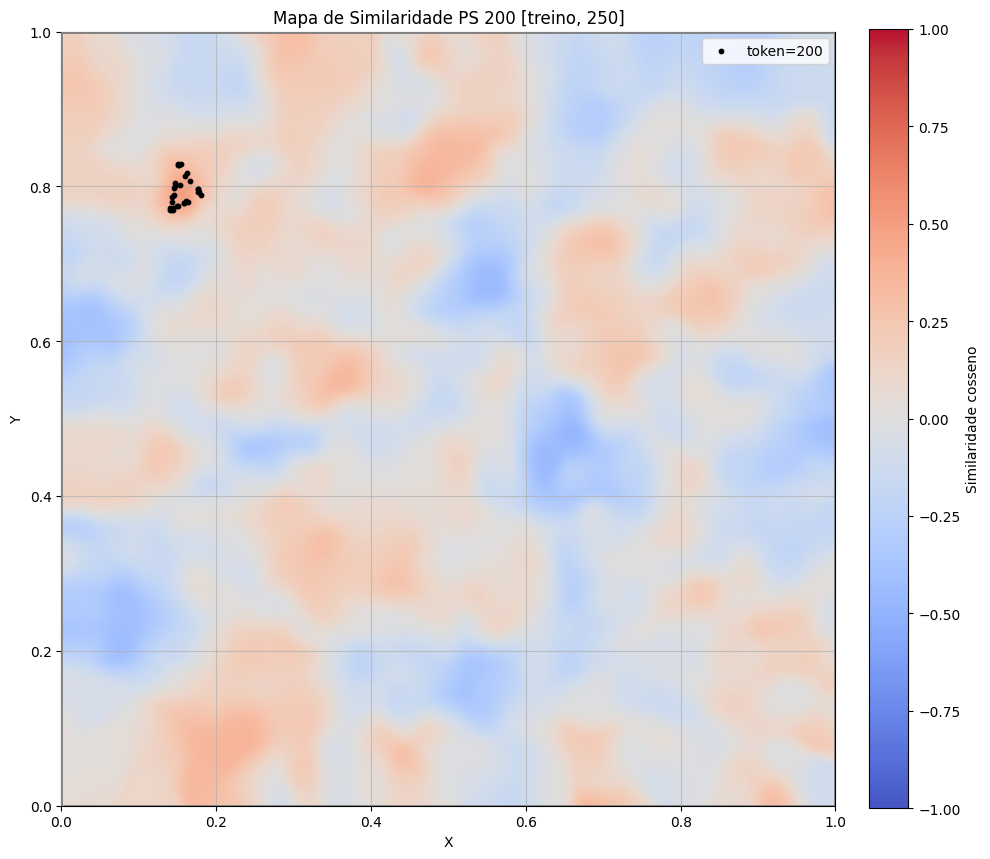

In [61]:
plot_cosine_similarity_map_no_env(
    df_states=df,
    cossim_df=coss_train_250,
    current_id=200,
    similarity_id_offset=0,
    cmap="coolwarm",
    smooth_sigma=0.015,
    grid_size=100,
    sim_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag = '[treino, 250]'
)
plt.show()

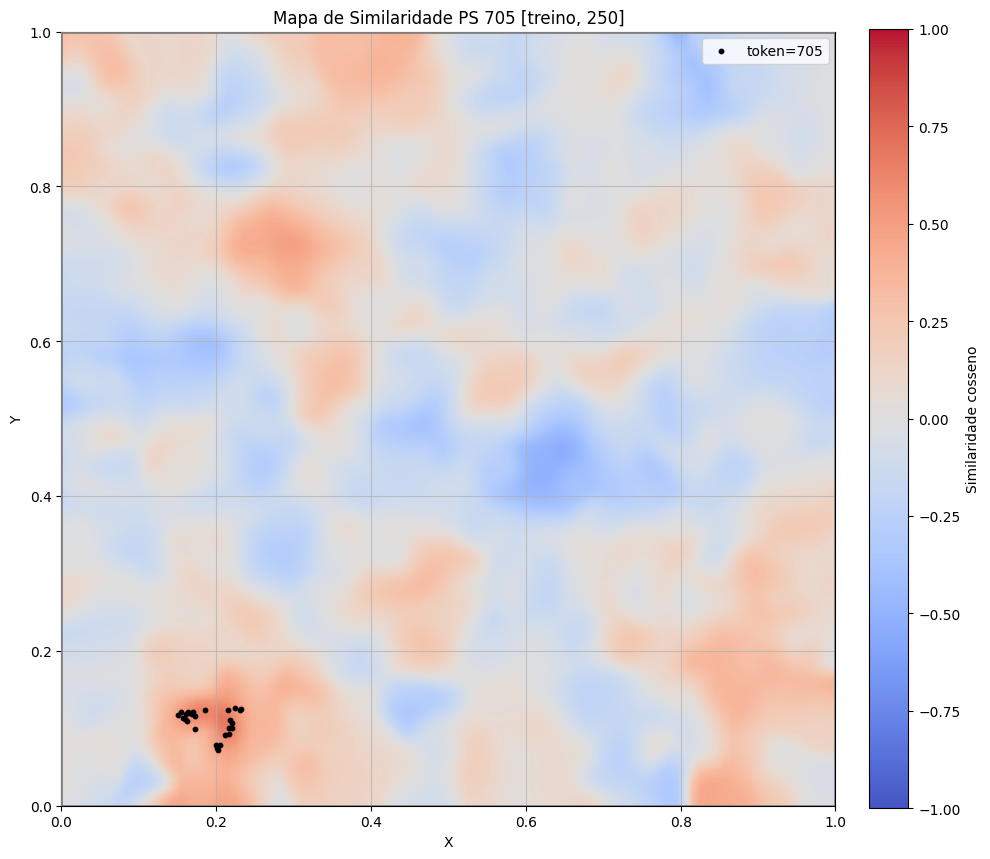

In [62]:
plot_cosine_similarity_map_no_env(
    df_states=df,
    cossim_df=coss_train_250,
    current_id=705,
    similarity_id_offset=0,
    cmap="coolwarm",
    smooth_sigma=0.015,
    grid_size=100,
    sim_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag = '[treino, 250]'
)
plt.show()

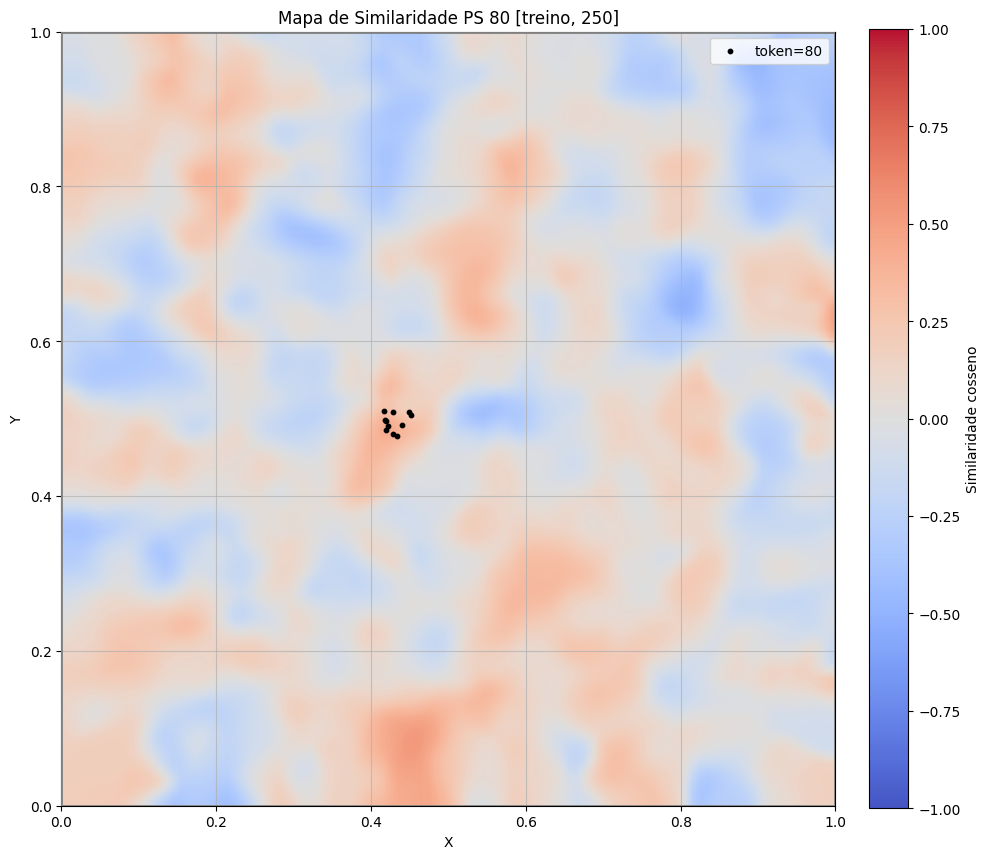

In [63]:
plot_cosine_similarity_map_no_env(
    df_states=df,
    cossim_df=coss_train_250,
    current_id=80,
    similarity_id_offset=0,
    cmap="coolwarm",
    smooth_sigma=0.015,
    grid_size=100,
    sim_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag = '[treino, 250]'
)
plt.show()

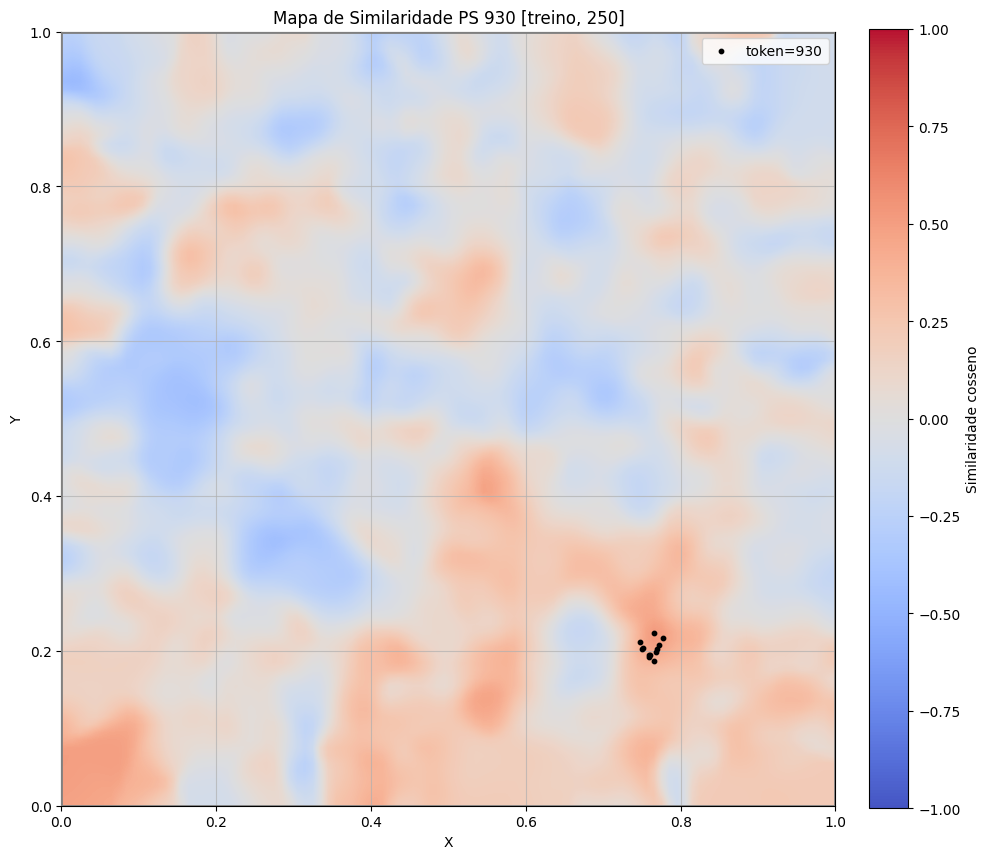

In [64]:
plot_cosine_similarity_map_no_env(
    df_states=df,
    cossim_df=coss_train_250,
    current_id=930,
    similarity_id_offset=0,
    cmap="coolwarm",
    smooth_sigma=0.015,
    grid_size=100,
    sim_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag = '[treino, 250]'
)
plt.show()

### after train embedd

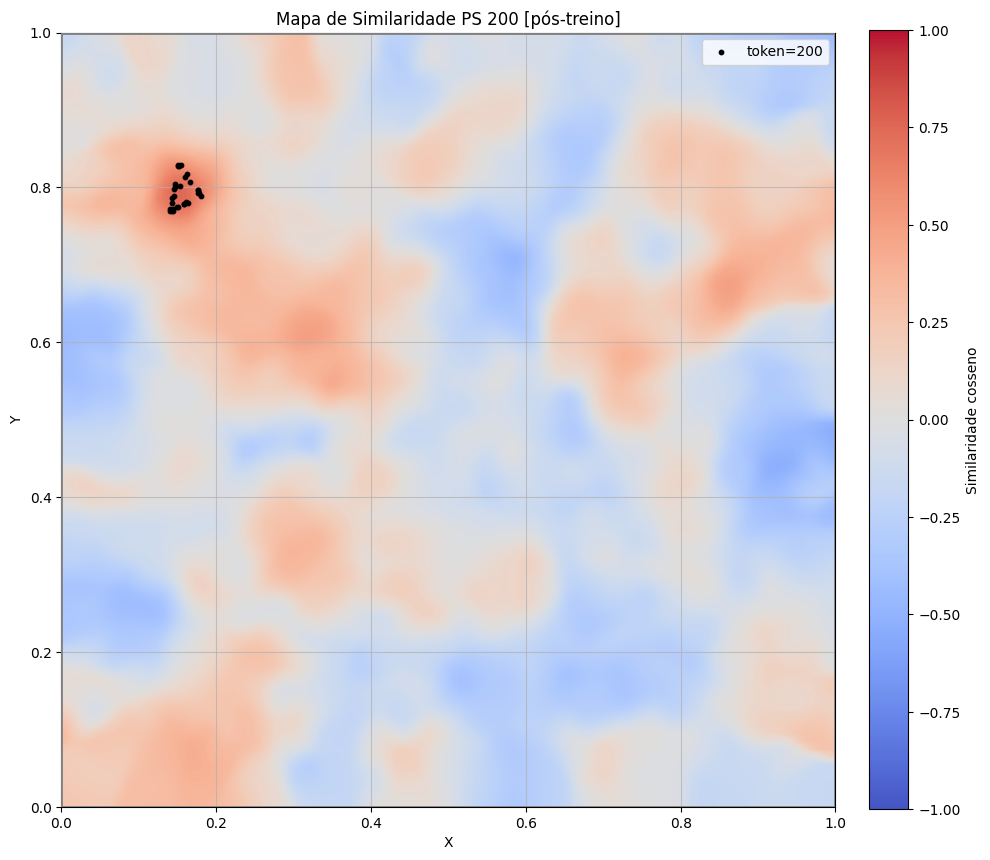

In [65]:
plot_cosine_similarity_map_no_env(
    df_states=df,
    cossim_df=coss,
    current_id=200,
    similarity_id_offset=0,
    cmap="coolwarm",
    smooth_sigma=0.015,
    grid_size=100,
    sim_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag = '[pós-treino]'
)
plt.show()

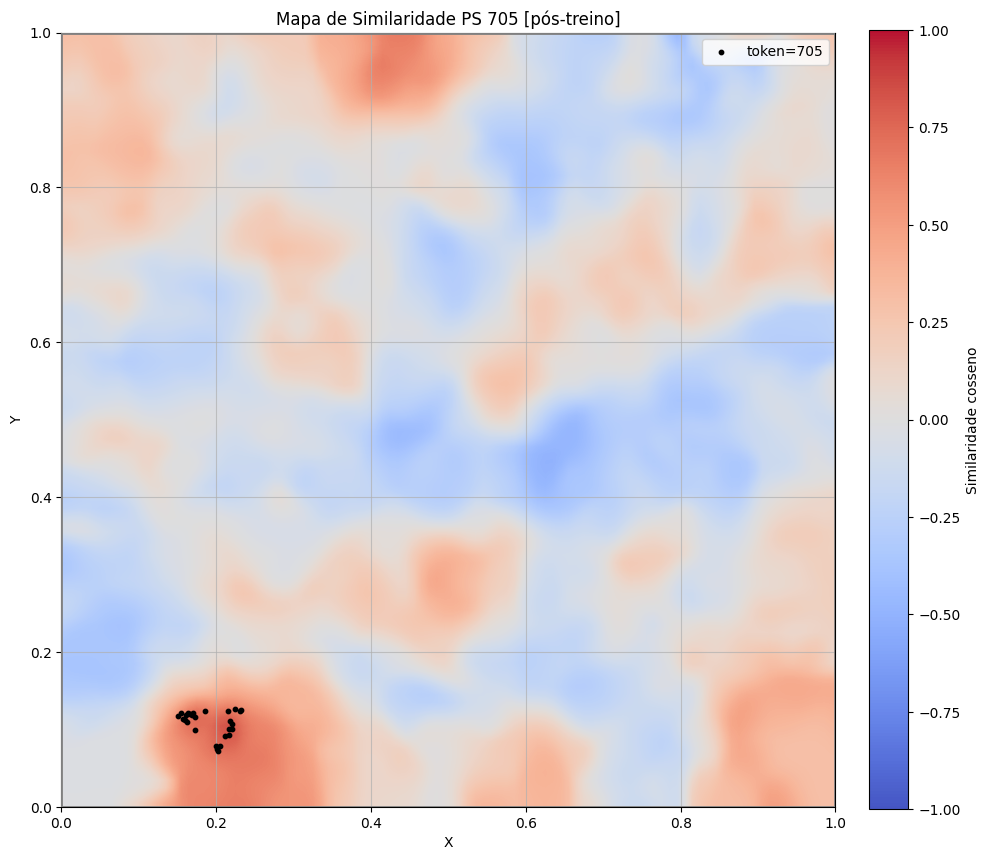

In [66]:
plot_cosine_similarity_map_no_env(
    df_states=df,
    cossim_df=coss,
    current_id=705,
    similarity_id_offset=0,
    cmap="coolwarm",
    smooth_sigma=0.015,
    grid_size=100,
    sim_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag = '[pós-treino]'
)
plt.show()

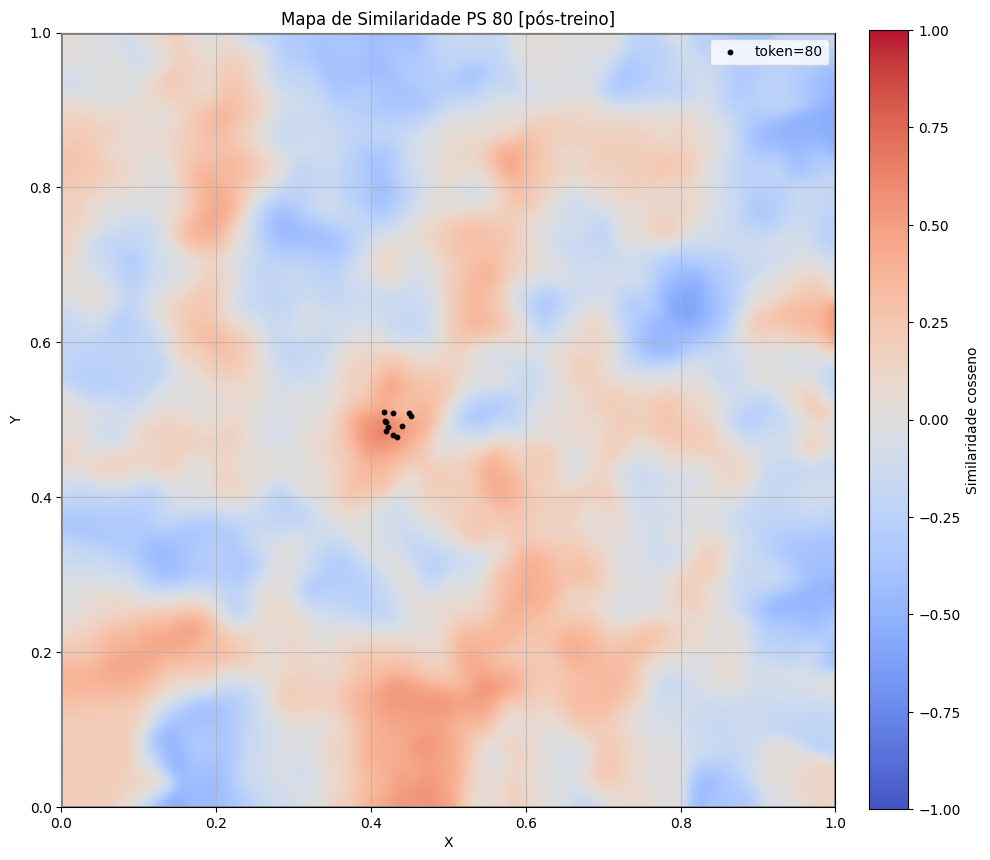

In [67]:
plot_cosine_similarity_map_no_env(
    df_states=df,
    cossim_df=coss,
    current_id=80,
    similarity_id_offset=0,
    cmap="coolwarm",
    smooth_sigma=0.015,
    grid_size=100,
    sim_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag = '[pós-treino]'
)
plt.show()

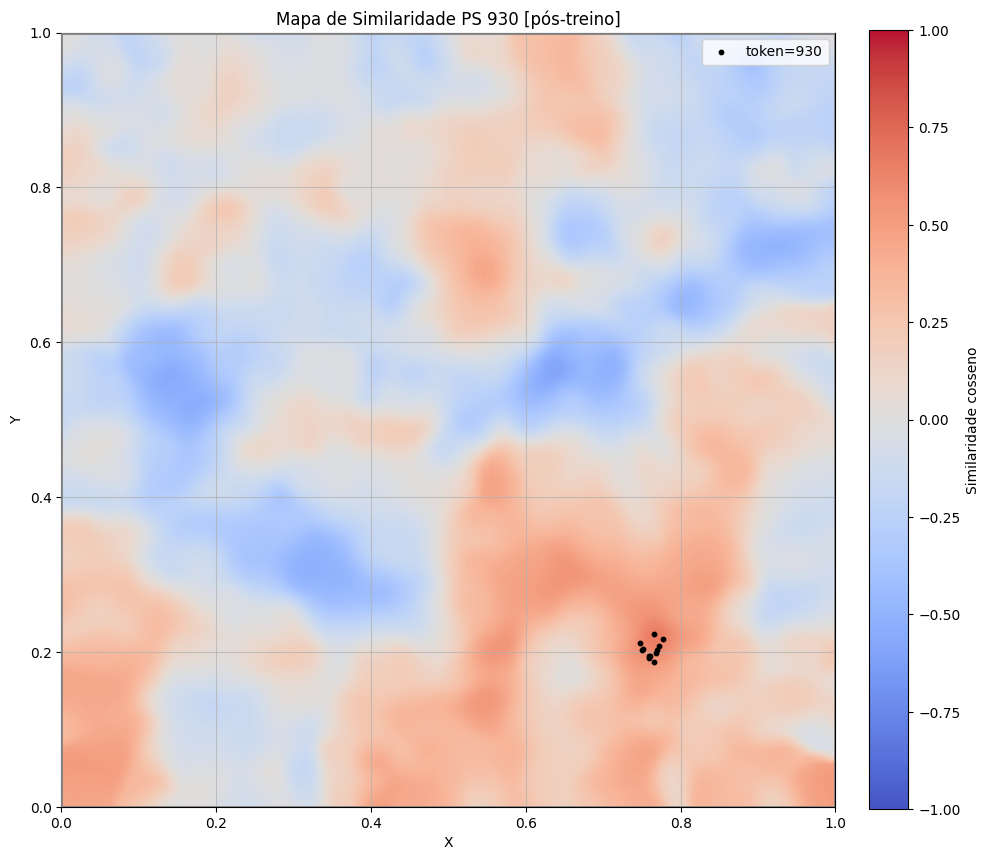

In [68]:
plot_cosine_similarity_map_no_env(
    df_states=df,
    cossim_df=coss,
    current_id=930,
    similarity_id_offset=0,
    cmap="coolwarm",
    smooth_sigma=0.015,
    grid_size=100,
    sim_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag = '[pós-treino]'
)
plt.show()

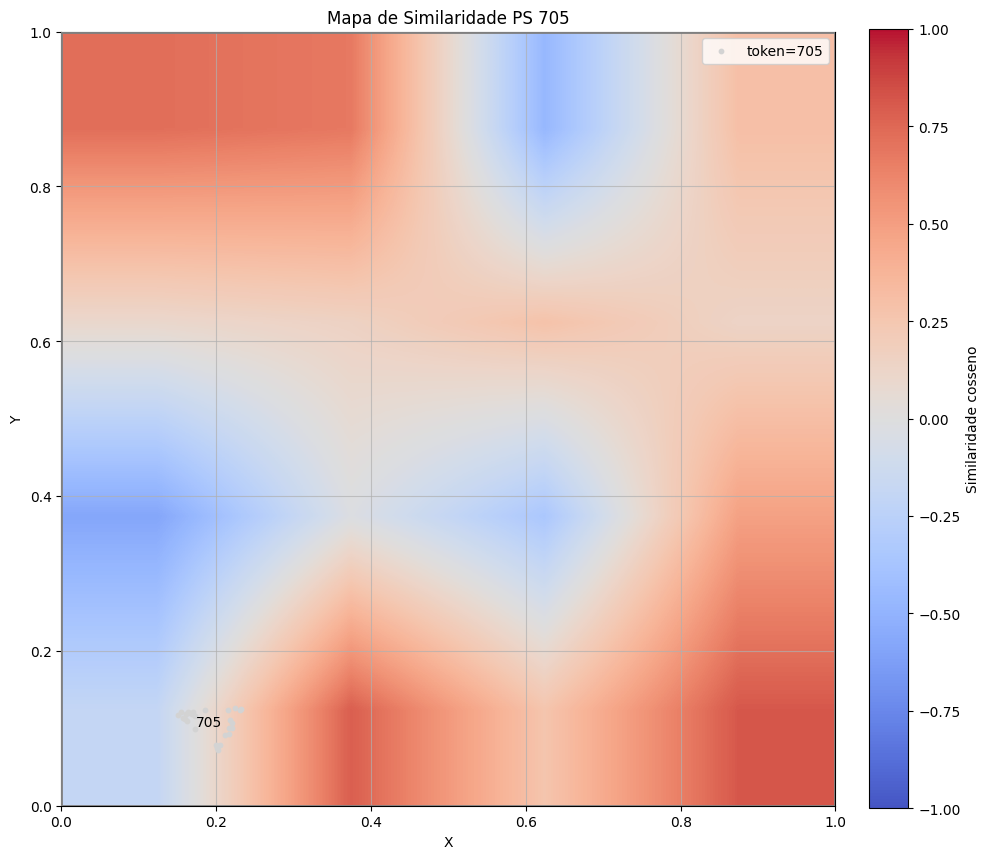

(<Figure size 1000x1000 with 2 Axes>,
 <Axes: title={'center': 'Mapa de Similaridade PS 705'}, xlabel='X', ylabel='Y'>)

In [69]:
plot_cosine_similarity_map_no_env(
    df_states=df,
    cossim_df=coss,
    current_id=705,
    similarity_id_offset=0,
    cmap="coolwarm",
    smooth_sigma=0.05,
    grid_size=4,
    sim_power=0.2,
    current_color="lightgray",
    current_size=10,
    current_alpha=1
)

In [70]:
coss_pre_train

,0,1,2,3,4,5,6,7,8,9,...,938,939,940,941,942,943,944,945,946,947
0,1.000000,0.044635,-0.124699,-0.118096,0.087774,-0.154702,0.292279,-0.393237,0.144094,0.018389,...,0.519528,0.443823,-0.125644,0.293885,-0.146256,-0.462000,0.420652,-0.174844,0.190064,0.0
1,0.044635,1.000000,0.372878,-0.206341,0.266927,-0.282136,-0.159818,0.210908,-0.073049,-0.111195,...,-0.025143,0.094237,-0.228535,-0.242449,-0.292494,0.114530,0.020957,-0.070048,0.484795,0.0
2,-0.124699,0.372878,1.000000,0.084410,0.362170,0.131163,0.002694,-0.117624,-0.164924,-0.197381,...,-0.044261,0.070680,0.055458,-0.166386,-0.340333,-0.043799,0.002834,0.202574,0.127705,0.0
3,-0.118096,-0.206341,0.084410,1.000000,-0.172358,-0.428509,-0.064528,0.224249,-0.213274,0.097782,...,-0.373769,0.409324,0.355733,0.114461,-0.033143,0.116396,-0.159492,-0.050039,0.163385,0.0
4,0.087774,0.266927,0.362170,-0.172358,1.000000,0.207259,-0.217128,-0.021895,-0.340553,-0.216390,...,0.244391,-0.218869,0.211245,-0.593633,0.045237,-0.247859,0.259121,0.280483,0.083597,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
943,-0.462000,0.114530,-0.043799,0.116396,-0.247859,0.222423,0.143156,0.260995,0.460322,-0.074632,...,-0.550971,-0.120946,-0.014904,0.148033,0.041702,1.000000,-0.044521,-0.126300,0.090777,0.0
944,0.420652,0.020957,0.002834,-0.159492,0.259121,0.272947,0.718341,-0.320901,0.021849,-0.459690,...,-0.011991,-0.091306,-0.207053,-0.103227,0.006186,-0.044521,1.000000,0.131736,-0.063346,0.0
945,-0.174844,-0.070048,0.202574,-0.050039,0.280483,0.198153,-0.217528,0.290297,-0.152370,-0.393445,...,-0.013669,-0.027633,-0.264999,-0.395194,0.496310,-0.126300,0.131736,1.000000,-0.465203,0.0
946,0.190064,0.484795,0.127705,0.163385,0.083597,-0.307116,-0.083539,-0.013734,0.137299,-0.142190,...,-0.041096,0.357933,0.090623,-0.070674,-0.162404,0.090777,-0.063346,-0.465203,1.000000,0.0


# Head Projections

In [71]:
def _parse_xy(v):
    if isinstance(v, str):
        v = ast.literal_eval(v)
    if isinstance(v, (list, tuple, np.ndarray)) and len(v) == 2:
        return float(v[0]), float(v[1])
    raise ValueError(f"Invalid value in pos: {v}")

def plot_representation_similarity_map_no_env(
    df_states,
    sim_df,
    current_id,
    *,
    repr_name="Q",
    pos_col="pos",
    id_col="position_state_id",
    xlim=(0.0, 1.0),
    ylim=(0.0, 1.0),
    figsize=(10, 10),
    cmap="coolwarm",
    current_color="lightgray",
    current_alpha=0.95,
    current_size=20,
    show_current_label=True,
    smooth_sigma=0.03,
    grid_size=250,
    min_support=1e-6,
    sim_power=1.0,
    use_abs_for_smoothing=False,
    clip_similarity=None,
    show_colorbar=True,
    env_linewidth=2.0,
    env_color="gray",
    grid=True,
    grid_alpha=0.7,
    interpolation="bilinear",
    similarity_id_offset=0,
    use_column_instead_of_row=False,
    title_tag="",
):
    """
    Spatially smooth similarity map using a token-token cosine similarity matrix
    such as q_cos, k_cos, v_cos, or s_cos.

    Parameters
    ----------
    df_states : pd.DataFrame
        Must contain at least [position_state_id, pos]
    sim_df : pd.DataFrame
        Square cosine similarity matrix, vocab x vocab
    current_id : int
        Token / position_state_id to visualize
    repr_name : str
        Name of the representation being plotted, e.g. "Q", "K", "V", "S"
    similarity_id_offset : int
        Offset between state ids and matrix indices/columns
    """

    df = df_states.copy()

    xy = df[pos_col].apply(_parse_xy)
    df["_x"] = [p[0] for p in xy]
    df["_y"] = [p[1] for p in xy]

    if len(df[df[id_col] == current_id]) == 0:
        raise ValueError(f"No row found for current_id={current_id}")

    current_sim_idx = int(current_id) - similarity_id_offset

    # robust handling in case csv was loaded with string column names
    sim_df_local = sim_df.copy()
    try:
        sim_df_local.index = sim_df_local.index.astype(int)
    except Exception:
        pass
    try:
        sim_df_local.columns = sim_df_local.columns.astype(int)
    except Exception:
        pass

    if current_sim_idx not in sim_df_local.index and current_sim_idx not in sim_df_local.columns:
        raise ValueError(
            f"current_id={current_id} maps to {current_sim_idx}, "
            f"but that value is not present in sim_df index/columns."
        )

    if use_column_instead_of_row:
        sim_series = sim_df_local[current_sim_idx].copy()
    else:
        sim_series = sim_df_local.loc[current_sim_idx].copy()

    try:
        sim_series.index = sim_series.index.astype(int)
    except Exception:
        pass

    df["_sim_idx"] = df[id_col].astype(int) - similarity_id_offset
    sim_map = sim_series.to_dict()
    df["_sim"] = df["_sim_idx"].map(sim_map).fillna(0.0)

    if clip_similarity is not None:
        lo, hi = clip_similarity
        df["_sim"] = df["_sim"].clip(lo, hi)

    df_current = df[df[id_col] == current_id].copy()
    df_other = df.copy()

    if sim_power != 1.0:
        sign = np.sign(df_other["_sim"].to_numpy())
        mag = np.abs(df_other["_sim"].to_numpy())
        mag = np.power(mag, sim_power)
        df_other["_sim"] = sign * mag

    xmin, xmax = xlim
    ymin, ymax = ylim

    gx = np.linspace(xmin, xmax, grid_size)
    gy = np.linspace(ymin, ymax, grid_size)
    XX, YY = np.meshgrid(gx, gy)

    field = np.zeros_like(XX, dtype=float)
    support = np.zeros_like(XX, dtype=float)

    if len(df_other) > 0 and np.any(np.abs(df_other["_sim"].to_numpy()) > 0):
        xs = df_other["_x"].to_numpy(float)
        ys = df_other["_y"].to_numpy(float)
        ws = df_other["_sim"].to_numpy(float)

        for x0, y0, w in zip(xs, ys, ws):
            d2 = (XX - x0) ** 2 + (YY - y0) ** 2
            k = np.exp(-0.5 * d2 / (smooth_sigma ** 2))
            field += w * k

            if use_abs_for_smoothing:
                support += np.abs(w) * k
            else:
                support += k

        smoothed = np.zeros_like(field)
        valid = support > min_support
        smoothed[valid] = field[valid] / support[valid]
        mask = ~valid
        smoothed = np.ma.array(smoothed, mask=mask)
    else:
        smoothed = np.ma.array(np.zeros_like(field), mask=np.ones_like(field, dtype=bool))

    norm = TwoSlopeNorm(vmin=-1.0, vcenter=0.0, vmax=1.0)

    fig, ax = plt.subplots(figsize=figsize)

    im = ax.imshow(
        smoothed,
        extent=[xmin, xmax, ymin, ymax],
        origin="lower",
        cmap=cmap,
        norm=norm,
        interpolation=interpolation,
        alpha=0.95,
        zorder=1,
    )

    ax.scatter(
        df_current["_x"],
        df_current["_y"],
        s=current_size,
        color=current_color,
        alpha=current_alpha,
        zorder=3,
        label=f"token={current_id}",
    )

    if show_current_label:
        cx = df_current["_x"].mean()
        cy = df_current["_y"].mean()
        ax.text(
            cx,
            cy,
            str(current_id),
            fontsize=10,
            color="black",
            ha="center",
            va="center",
            zorder=4,
        )

    ax.plot([xmin, xmax], [ymin, ymin], color=env_color, linewidth=env_linewidth, zorder=5)
    ax.plot([xmin, xmax], [ymax, ymax], color=env_color, linewidth=env_linewidth, zorder=5)
    ax.plot([xmin, xmin], [ymin, ymax], color=env_color, linewidth=env_linewidth, zorder=5)
    ax.plot([xmax, xmax], [ymin, ymax], color=env_color, linewidth=env_linewidth, zorder=5)

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_aspect("equal")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")

    if len(title_tag) > 0:
        ax.set_title(f"{repr_name}-space cosine similarity map for PS {current_id} {title_tag}")
    else:
        ax.set_title(f"{repr_name}-space cosine similarity map for PS {current_id}")

    if grid:
        ax.grid(True, alpha=grid_alpha)

    ax.legend(loc="upper right", frameon=True)

    if show_colorbar:
        cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        cbar.set_label(f"Cosine similarity in {repr_name}-space")

    plt.tight_layout()
    plt.show()

    return fig, ax

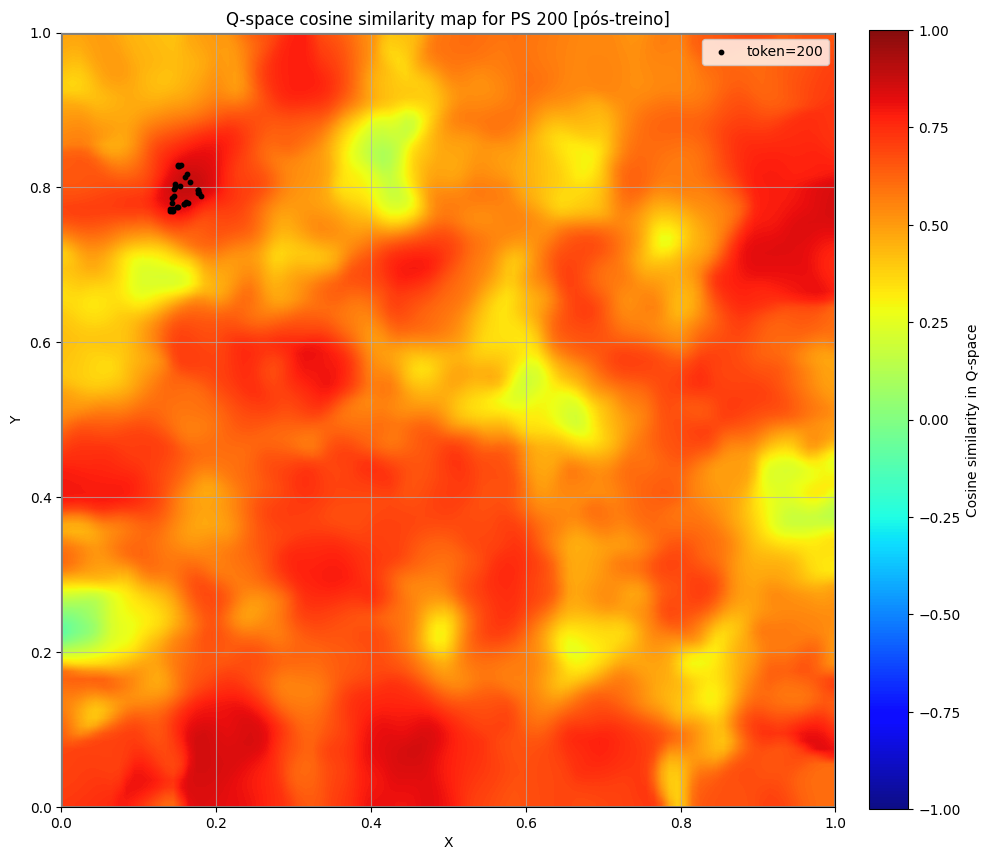

In [72]:
plot_representation_similarity_map_no_env(
    df_states=df,
    sim_df=mechadf['q_cos'],
    current_id=200,
    similarity_id_offset=0,
    repr_name="Q",
    cmap="jet",
    smooth_sigma=0.015,
    grid_size=100,
    sim_power=1.0,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag="[pós-treino]"
)
plt.show()

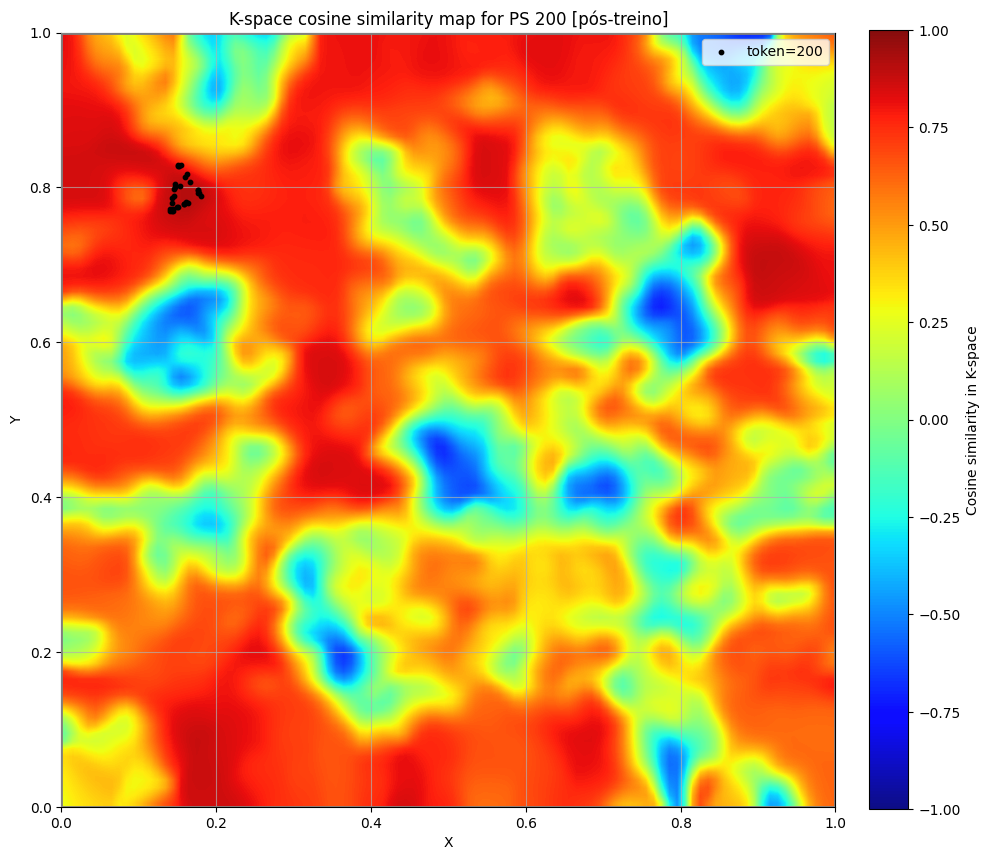

In [73]:
plot_representation_similarity_map_no_env(
    df_states=df,
    sim_df=mechadf['k_cos'],
    current_id=200,
    similarity_id_offset=0,
    repr_name="K",
    cmap="jet",
    smooth_sigma=0.015,
    grid_size=100,
    sim_power=1.0,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag="[pós-treino]"
)
plt.show()

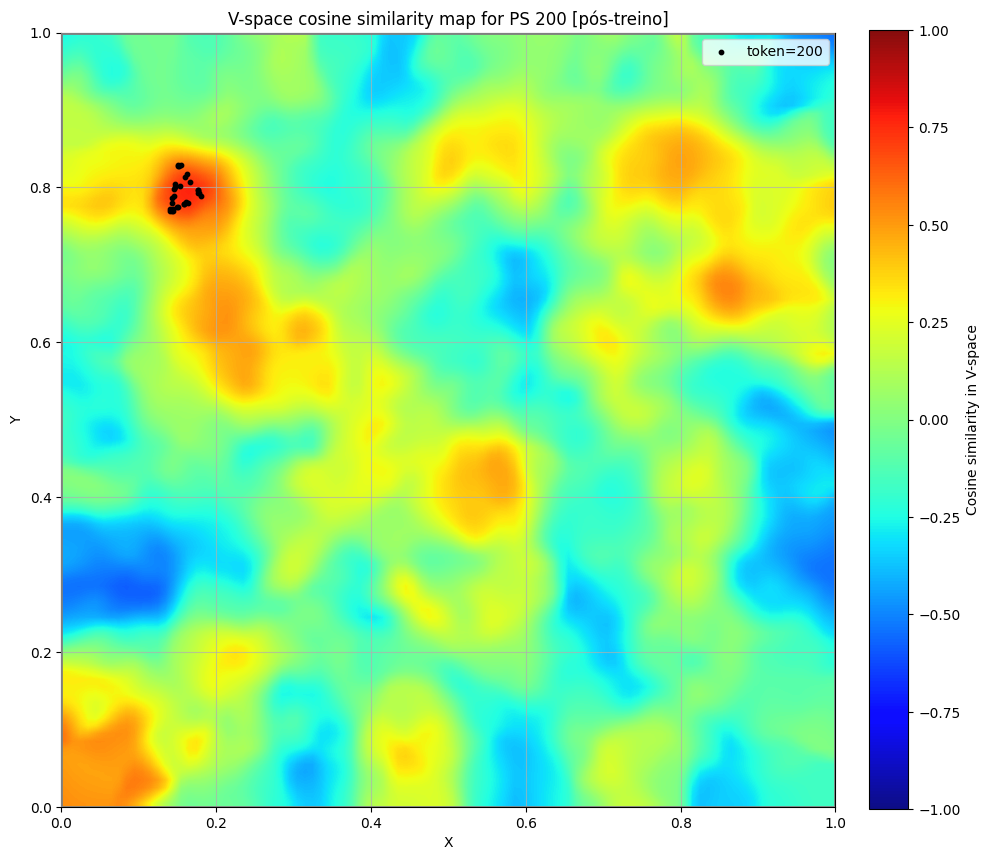

In [74]:
plot_representation_similarity_map_no_env(
    df_states=df,
    sim_df=mechadf['v_cos'],
    current_id=200,
    similarity_id_offset=0,
    repr_name="V",
    cmap="jet",
    smooth_sigma=0.015,
    grid_size=100,
    sim_power=1.0,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag="[pós-treino]"
)
plt.show()

# Head Attentions

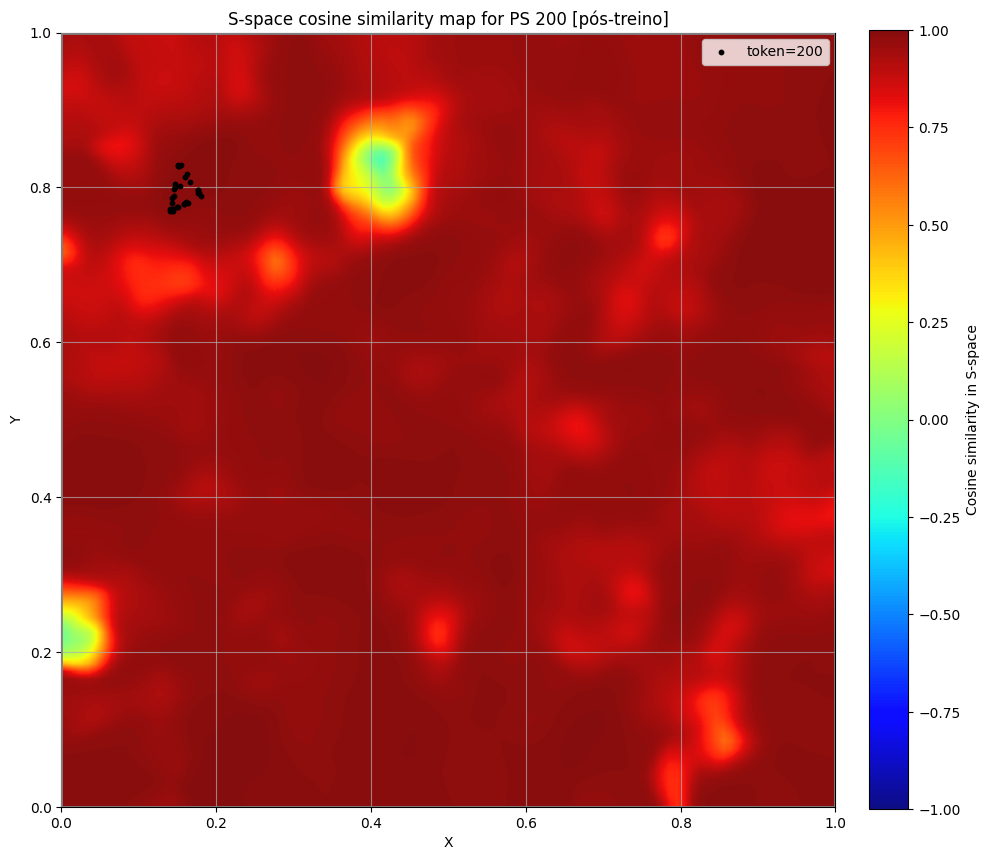

In [75]:
plot_representation_similarity_map_no_env(
    df_states=df,
    sim_df=mechadf['s_cos'],
    current_id=200,
    similarity_id_offset=0,
    repr_name="S",
    cmap="jet",
    smooth_sigma=0.015,
    grid_size=100,
    sim_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag="[pós-treino]"
)
plt.show()

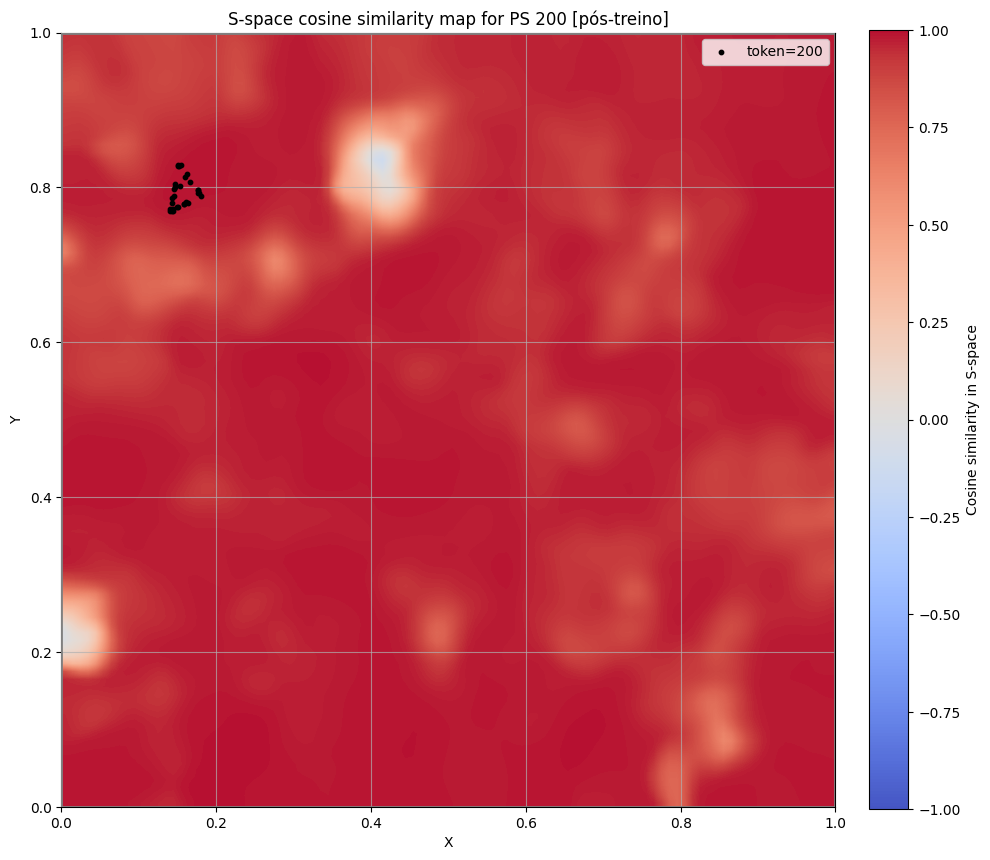

In [76]:
plot_representation_similarity_map_no_env(
    df_states=df,
    sim_df=mechadf['s_cos'],
    current_id=200,
    similarity_id_offset=0,
    repr_name="S",
    cmap="coolwarm",
    smooth_sigma=0.015,
    grid_size=100,
    sim_power=1.0,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag="[pós-treino]"
)
plt.show()

# Probs Distribs

In [77]:
def _parse_xy(v):
    """
    Converte `pos` para (x, y).
    Aceita:
      - [x, y]
      - (x, y)
      - np.array([x, y])
      - string "[x, y]"
    """
    if isinstance(v, str):
        v = ast.literal_eval(v)

    if isinstance(v, (list, tuple, np.ndarray)) and len(v) == 2:
        return float(v[0]), float(v[1])

    raise ValueError(f"Valor inválido em pos: {v}")


def _resolve_step_col(step):
    """
    Aceita:
      - 'Passo 01'
      - 1, 2, ..., 10
    """
    if isinstance(step, str):
        return step
    if isinstance(step, int):
        return f"Passo {step:02d}"
    raise ValueError("`step` deve ser int ou str.")


def plot_next_id_probability_map_no_env(
    df_states,
    probs_df,
    current_id,
    *,
    step="Passo 01",
    pos_col="pos",
    id_col="position_state_id",
    probs_id_col=None,          # use se probs_df tiver o id em coluna
    xlim=(0.0, 1.0),
    ylim=(0.0, 1.0),
    figsize=(10, 10),
    cmap="viridis",
    current_color="lightgray",
    current_alpha=0.95,
    current_size=20,
    show_current_label=True,
    smooth_sigma=0.03,
    grid_size=250,
    min_support=1e-6,
    prob_power=1.0,
    show_colorbar=True,
    env_linewidth=2.0,
    env_color="gray",
    grid=True,
    grid_alpha=0.7,
    interpolation="bilinear",
):
    """
    Plota um mapa espacial suavizado de probabilidade do próximo id, sem depender de Env.

    Regras:
    - o id atual é pintado em cinza
    - os outros ids são pintados pela probabilidade do passo escolhido
    - a pintura é suavizada espacialmente com kernel gaussiano
    - o ambiente é desenhado manualmente entre 0 e 1 em x e y

    Parâmetros
    ----------
    df_states : pd.DataFrame
        DataFrame com colunas como [position_state_id, pos]
    probs_df : pd.DataFrame
        DataFrame com uma linha por id e colunas "Passo 01", "Passo 02", ...
    current_id : int | str
        id atual do animal
    step : str | int
        passo a visualizar
    """

    step_col = _resolve_step_col(step)

    # ----------------------------
    # prepara probs_df
    # ----------------------------
    probs = probs_df.copy()

    if probs_id_col is not None:
        probs = probs.set_index(probs_id_col)

    if step_col not in probs.columns:
        raise ValueError(
            f"Coluna '{step_col}' não encontrada em probs_df. "
            f"Colunas disponíveis: {list(probs.columns)}"
        )

    # ----------------------------
    # prepara df_states
    # ----------------------------
    df = df_states.copy()

    xy = df[pos_col].apply(_parse_xy)
    df["_x"] = [p[0] for p in xy]
    df["_y"] = [p[1] for p in xy]

    # tenta compatibilizar tipos do índice das probabilidades com o id do dataframe
    try:
        probs.index = probs.index.astype(df[id_col].dtype, copy=False)
    except Exception:
        pass

    # mapa de probabilidade do passo escolhido
    prob_map = probs[step_col].to_dict()
    df["_prob"] = df[id_col].map(prob_map).fillna(0.0)

    # separa id atual e outros
    df_current = df[df[id_col] == current_id].copy()
    df_other = df.copy() #df[df[id_col] != current_id].copy()

    if len(df_current) == 0:
        raise ValueError(f"Nenhuma linha encontrada para current_id={current_id}")

    # ajuste opcional de contraste
    if prob_power != 1.0:
        df_other["_prob"] = np.power(df_other["_prob"].clip(lower=0), prob_power)

    # ----------------------------
    # malha do ambiente
    # ----------------------------
    xmin, xmax = xlim
    ymin, ymax = ylim

    gx = np.linspace(xmin, xmax, grid_size)
    gy = np.linspace(ymin, ymax, grid_size)
    XX, YY = np.meshgrid(gx, gy)

    field = np.zeros_like(XX, dtype=float)
    support = np.zeros_like(XX, dtype=float)

    # ----------------------------
    # suavização espacial
    # ----------------------------
    if len(df_other) > 0 and df_other["_prob"].sum() > 0:
        xs = df_other["_x"].to_numpy(float)
        ys = df_other["_y"].to_numpy(float)
        ws = df_other["_prob"].to_numpy(float)

        for x0, y0, w in zip(xs, ys, ws):
            d2 = (XX - x0) ** 2 + (YY - y0) ** 2
            k = np.exp(-0.5 * d2 / (smooth_sigma ** 2))
            field += w * k
            support += k

        smoothed = np.zeros_like(field)
        valid = support > min_support
        smoothed[valid] = field[valid] / support[valid]

        # mascara regiões sem suporte para não “lavar” o ambiente todo
        mask = ~valid
        smoothed = np.ma.array(smoothed, mask=mask)
    else:
        smoothed = np.ma.array(np.zeros_like(field), mask=np.ones_like(field, dtype=bool))

    # ----------------------------
    # plot
    # ----------------------------
    fig, ax = plt.subplots(figsize=figsize)

    vmax = float(df_other["_prob"].max()) if len(df_other) > 0 else 1.0
    if vmax <= 0:
        vmax = 1.0

    im = ax.imshow(
        smoothed,
        extent=[xmin, xmax, ymin, ymax],
        origin="lower",
        cmap=cmap,
        norm=Normalize(vmin=0.0, vmax=1.0),
        interpolation=interpolation,
        alpha=0.95,
        zorder=1,
    )

    # # pontos do id atual em cinza
    # ax.scatter(
    #     df_current["_x"],
    #     df_current["_y"],
    #     s=current_size,
    #     color=current_color,
    #     alpha=current_alpha,
    #     zorder=3,
    #     label=f"token={current_id}",
    # )

    if show_current_label:
        cx = df_current["_x"].mean()
        cy = df_current["_y"].mean()
        ax.text(
            cx,
            cy,
            str(current_id),
            fontsize=10,
            color="black",
            ha="center",
            va="center",
            zorder=4,
        )

    # moldura manual do ambiente
    ax.plot([xmin, xmax], [ymin, ymin], color=env_color, linewidth=env_linewidth, zorder=5)
    ax.plot([xmin, xmax], [ymax, ymax], color=env_color, linewidth=env_linewidth, zorder=5)
    ax.plot([xmin, xmin], [ymin, ymax], color=env_color, linewidth=env_linewidth, zorder=5)
    ax.plot([xmax, xmax], [ymin, ymax], color=env_color, linewidth=env_linewidth, zorder=5)

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_aspect("equal")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_title(f"Probabilidade no {step_col}")

    if grid:
        ax.grid(True, alpha=grid_alpha)

    ax.legend(loc="upper right", frameon=True)

    if show_colorbar:
        cbar = plt.colorbar(im, ax=ax)
        cbar.set_label(f"Probabilidade ({step_col})")

    plt.tight_layout()
    plt.show()

    return fig, ax

In [78]:
def _parse_xy(v):
    """
    Converte `pos` para (x, y).
    Aceita:
      - [x, y]
      - (x, y)
      - np.array([x, y])
      - string "[x, y]"
    """
    if isinstance(v, str):
        v = ast.literal_eval(v)

    if isinstance(v, (list, tuple, np.ndarray)) and len(v) == 2:
        return float(v[0]), float(v[1])

    raise ValueError(f"Valor inválido em pos: {v}")


def _resolve_step_col(step):
    """
    Aceita:
      - 'Passo 01'
      - 1, 2, ..., 10
    """
    if isinstance(step, str):
        return step
    if isinstance(step, int):
        return f"Passo {step:02d}"
    raise ValueError("`step` deve ser int ou str.")


def plot_next_id_probability_map_no_env(
    df_states,
    probs_df,
    current_id,
    *,
    step="Passo 01",
    pos_col="pos",
    id_col="position_state_id",
    xlim=(0.0, 1.0),
    ylim=(0.0, 1.0),
    figsize=(10, 10),
    cmap="viridis",
    current_color="lightgray",
    current_alpha=1.0,
    current_size=20,
    current_edgecolor="black",
    current_linewidth=0.8,
    show_current_label=True,
    smooth_sigma=0.03,
    grid_size=250,
    min_support=1e-6,
    prob_power=1.0,
    include_current_in_field=True,
    show_colorbar=True,
    colorbar_ticks=(0.0, 0.25, 0.5, 0.75, 1.0),
    env_linewidth=2.0,
    env_color="gray",
    grid=True,
    grid_alpha=0.7,
    interpolation="bilinear",
    show=True,
    title_tag = '',
):
    """
    Plota um mapa espacial suavizado de probabilidade do próximo id, sem depender de Env.

    Suposição sobre probs_df:
    - índice = id
    - colunas = passos ("Passo 01", ..., "Passo 10")

    Parâmetros
    ----------
    df_states : pd.DataFrame
        DataFrame com colunas como [position_state_id, pos]
    probs_df : pd.DataFrame
        DataFrame com índice = id e colunas = passos
    current_id : int | str
        id atual do animal
    step : str | int
        passo a visualizar
    include_current_in_field : bool
        se True, o current_id também contribui para o mapa
    """

    step_col = _resolve_step_col(step)

    # ----------------------------
    # valida probs_df
    # ----------------------------
    probs = probs_df.copy()

    if step_col not in probs.columns:
        raise ValueError(
            f"Coluna '{step_col}' não encontrada em probs_df. "
            f"Colunas disponíveis: {list(probs.columns)}"
        )

    # ----------------------------
    # prepara df_states
    # ----------------------------
    df = df_states.copy()

    xy = df[pos_col].apply(_parse_xy)
    df["_x"] = [p[0] for p in xy]
    df["_y"] = [p[1] for p in xy]

    if len(df[df[id_col] == current_id]) == 0:
        raise ValueError(f"Nenhuma linha encontrada para current_id={current_id}")

    # tenta compatibilizar o índice do probs_df com o tipo do id do df
    try:
        probs.index = probs.index.astype(df[id_col].dtype, copy=False)
    except Exception:
        pass

    # ----------------------------
    # mapa de probabilidade do passo escolhido
    # cada linha do probs_df é um id
    # ----------------------------
    prob_map = probs[step_col].to_dict()
    df["_prob"] = df[id_col].map(prob_map).fillna(0.0)

    df_current = df[df[id_col] == current_id].copy()

    if include_current_in_field:
        df_field = df.copy()
    else:
        df_field = df[df[id_col] != current_id].copy()

    # ----------------------------
    # ajuste opcional de contraste
    # ----------------------------
    if prob_power != 1.0:
        df_field["_prob"] = np.power(df_field["_prob"].clip(lower=0), prob_power)

    # ----------------------------
    # malha do ambiente
    # ----------------------------
    xmin, xmax = xlim
    ymin, ymax = ylim

    gx = np.linspace(xmin, xmax, grid_size)
    gy = np.linspace(ymin, ymax, grid_size)
    XX, YY = np.meshgrid(gx, gy)

    field = np.zeros_like(XX, dtype=float)
    support = np.zeros_like(XX, dtype=float)

    # ----------------------------
    # suavização espacial
    # ----------------------------
    if len(df_field) > 0 and np.any(df_field["_prob"].to_numpy(float) > 0):
        xs = df_field["_x"].to_numpy(float)
        ys = df_field["_y"].to_numpy(float)
        ws = df_field["_prob"].to_numpy(float)

        for x0, y0, w in zip(xs, ys, ws):
            d2 = (XX - x0) ** 2 + (YY - y0) ** 2
            k = np.exp(-0.5 * d2 / (smooth_sigma ** 2))
            field += w * k
            support += k

        smoothed = np.zeros_like(field)
        valid = support > min_support
        smoothed[valid] = field[valid] / support[valid]
        smoothed = np.ma.array(smoothed, mask=~valid)
    else:
        smoothed = np.ma.array(np.zeros_like(field), mask=np.ones_like(field, dtype=bool))


    # ----------------------------
    # plot
    # ----------------------------
    fig, ax = plt.subplots(figsize=figsize)

    im = ax.imshow(
        smoothed/np.max(smoothed),
        extent=[xmin, xmax, ymin, ymax],
        origin="lower",
        cmap=cmap,
        norm=Normalize(vmin=0.0, vmax=1.),
        interpolation=interpolation,
        alpha=0.95,
        zorder=1,
    )

    # current_id destacado
    ax.scatter(
        df_current["_x"],
        df_current["_y"],
        s=current_size,
        color=current_color,
        alpha=current_alpha,
        edgecolors=current_edgecolor,
        linewidths=current_linewidth,
        zorder=3,
        label=f"PS {current_id}",
    )

    if show_current_label:
        cx = df_current["_x"].mean()
        cy = df_current["_y"].mean()
        ax.text(
            cx,
            cy,
            str(current_id),
            fontsize=10,
            color="black",
            ha="center",
            va="center",
            zorder=4,
        )

    # moldura manual do ambiente
    ax.plot([xmin, xmax], [ymin, ymin], color=env_color, linewidth=env_linewidth, zorder=5)
    ax.plot([xmin, xmax], [ymax, ymax], color=env_color, linewidth=env_linewidth, zorder=5)
    ax.plot([xmin, xmin], [ymin, ymax], color=env_color, linewidth=env_linewidth, zorder=5)
    ax.plot([xmax, xmax], [ymin, ymax], color=env_color, linewidth=env_linewidth, zorder=5)

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_aspect("equal")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_title(f"Probabilidade no {step_col} {title_tag}")

    if grid:
        ax.grid(True, alpha=grid_alpha)

    ax.legend(loc="upper right", frameon=True)

    if show_colorbar:
        cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        cbar.set_label(f"Probabilidade ({step_col})")
        cbar.set_ticks(list(colorbar_ticks))

    plt.tight_layout()

    if show:
        plt.show()

    return fig, ax

In [79]:
distribs_probs.idxmax()

Passo 01    685
Passo 02    893
Passo 03    685
Passo 04    681
Passo 05    893
Passo 06    685
Passo 07    893
Passo 08    894
Passo 09    892
Passo 10    894
dtype: int64

In [80]:
with open(load_generation_path(model_tag, f'{model_tag}_gpt_generation_tokens_681.pkl'), 'rb') as fil:
    generation_681 = pickle.load(fil)
ids_sequence_list = generation_681['tokens']

def generated_current_id(generation, step):
    tokens = generation['tokens']
    prompt_length = generation['prompt_length']
    index = prompt_length + step - 2
    if not 0 <= index < len(tokens):
        raise ValueError(f'Invalid generation step {step}')
    return int(tokens[index])


### train loop

In [81]:
train_loop_snapshots = {
    'pre': full_fwd_pre_train,
    'epoch_100': full_fwd_100,
    'epoch_200': full_fwd_200,
    'epoch_500': full_fwd_500,
    'post': full_fwd,
}
ids_sequence_list_train_loop = np.asarray(full_fwd_pre_train['tokens']).tolist()
for period, snapshot in train_loop_snapshots.items():
    if np.asarray(snapshot['tokens']).tolist() != ids_sequence_list_train_loop:
        raise ValueError(f'{period}: different prompt')

def snapshot_steps_df(snapshot, key):
    values = np.asarray(snapshot[key])
    tokens = np.asarray(snapshot['tokens'])
    if values.ndim != 2 or values.shape[0] != len(tokens):
        raise ValueError(f'{key}: shape incompatible with prompt')
    return pd.DataFrame(
        values.T,
        index=np.arange(values.shape[1]),
        columns=[f'Passo {i + 1:02d}' for i in range(len(tokens))],
    )

def current_id_for_step(snapshot, step):
    tokens = np.asarray(snapshot['tokens'])
    if not 1 <= step <= len(tokens):
        raise ValueError(f'Invalid step {step} for {len(tokens)} tokens')
    return int(tokens[step - 1])


#### pre train

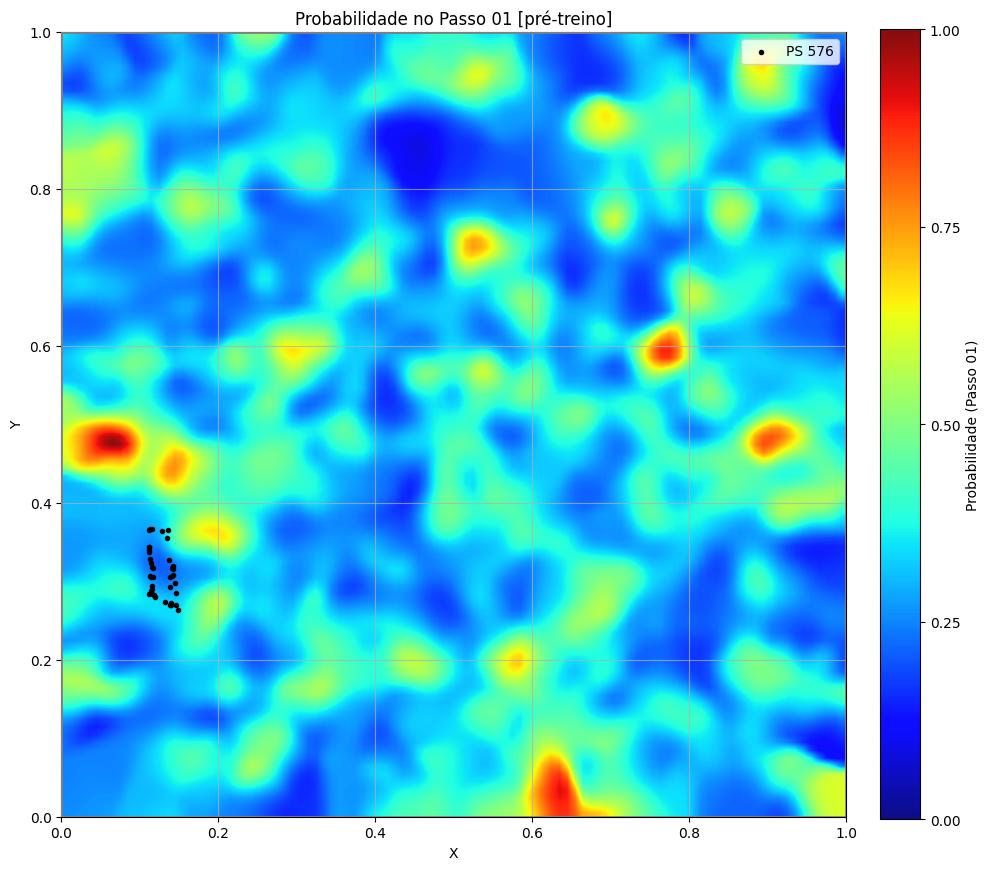

In [82]:
step_to_plot = 1
plot_next_id_probability_map_no_env(
    df_states=df,
    probs_df=snapshot_steps_df(full_fwd_pre_train, 'probs'),
    current_id=current_id_for_step(full_fwd_pre_train, step_to_plot),
    step=step_to_plot,
    cmap="jet",
    smooth_sigma=0.015,
    grid_size=100,
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag = '[pré-treino]'
)
plt.show()

#### mid train 100

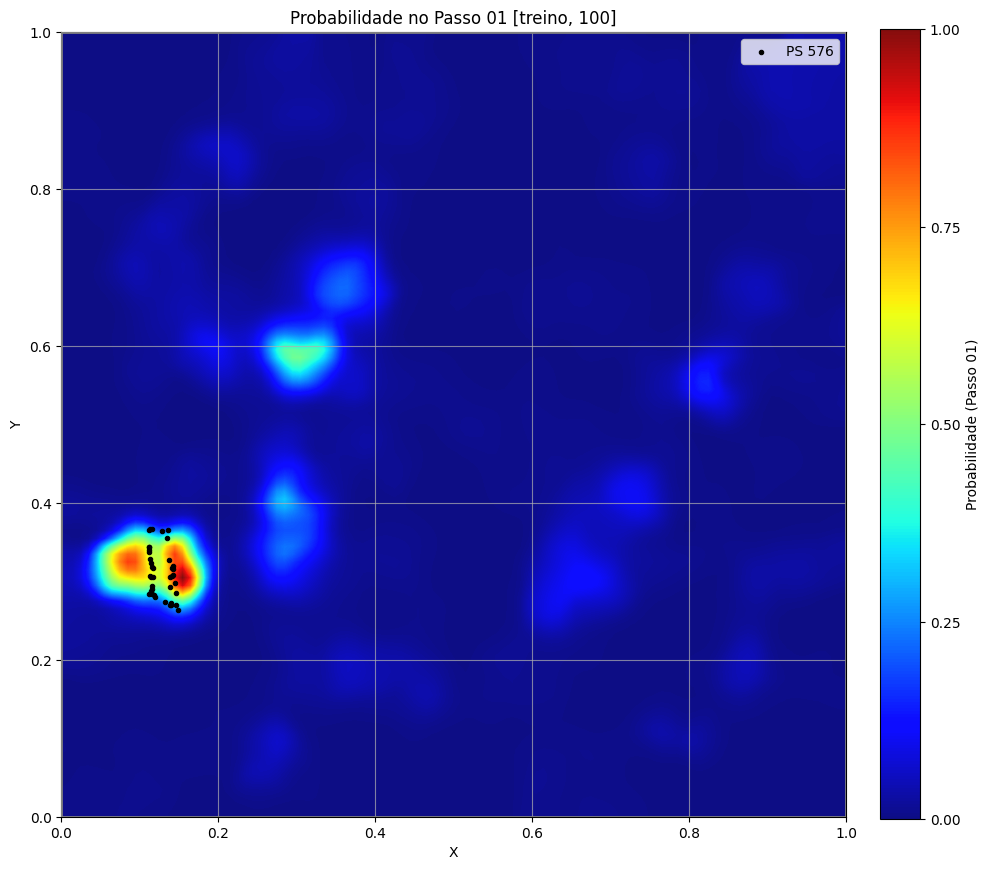

In [83]:
step_to_plot = 1
plot_next_id_probability_map_no_env(
    df_states=df,
    probs_df=snapshot_steps_df(full_fwd_100, 'probs'),
    current_id=current_id_for_step(full_fwd_100, step_to_plot),
    step=step_to_plot,
    cmap="jet",
    smooth_sigma=0.015,
    grid_size=100,
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag = '[treino, 100]'
)
plt.show()

#### mid train 200

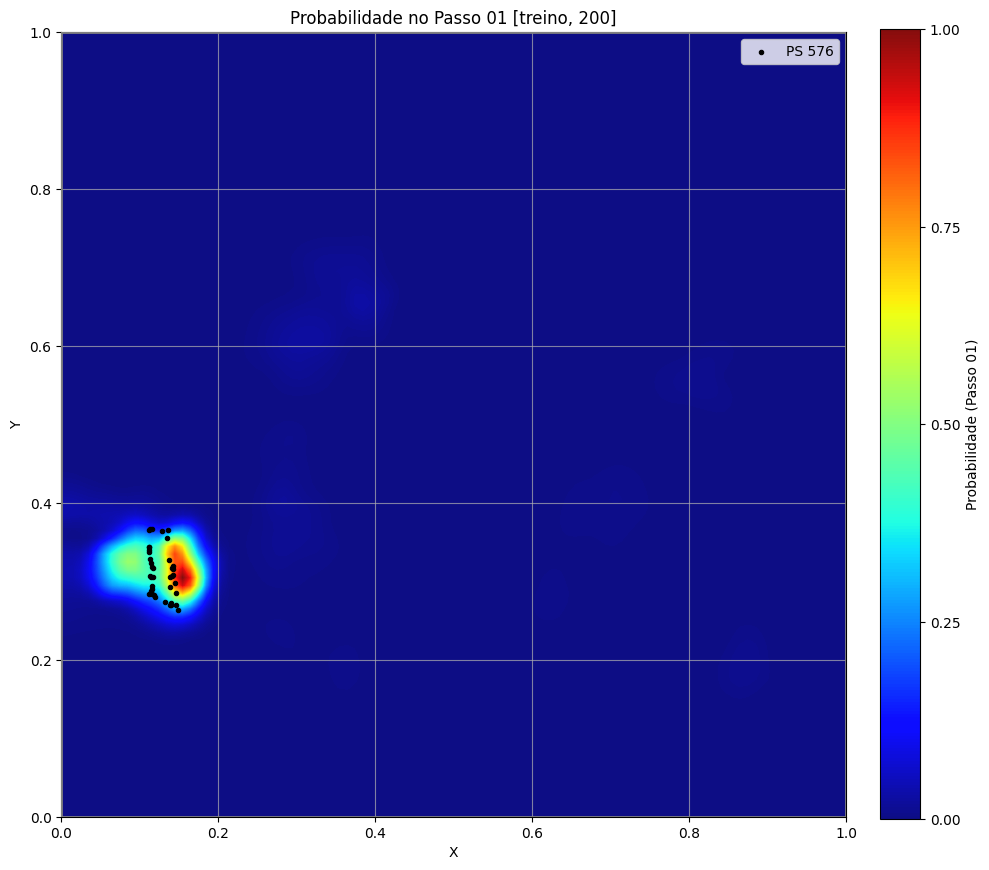

In [84]:
step_to_plot = 1
plot_next_id_probability_map_no_env(
    df_states=df,
    probs_df=snapshot_steps_df(full_fwd_200, 'probs'),
    current_id=current_id_for_step(full_fwd_200, step_to_plot),
    step=step_to_plot,
    cmap="jet",
    smooth_sigma=0.015,
    grid_size=100,
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag = '[treino, 200]'
)
plt.show()

#### mid train 500

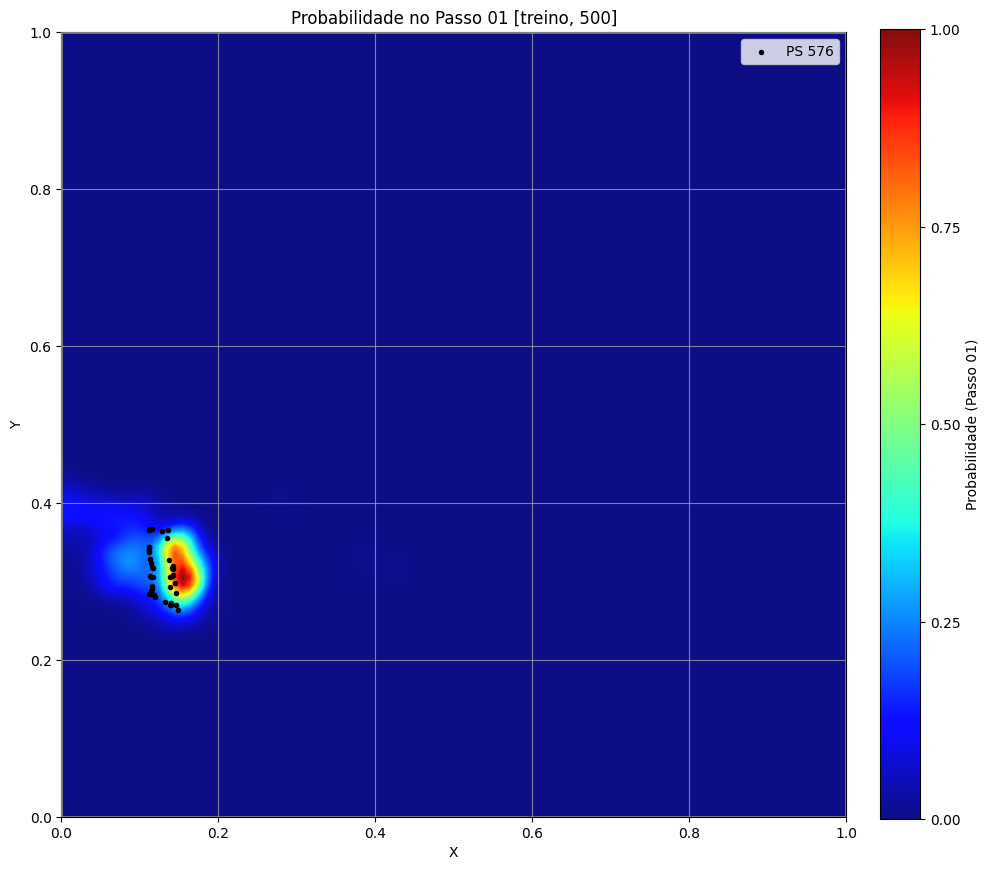

In [85]:
step_to_plot = 1
plot_next_id_probability_map_no_env(
    df_states=df,
    probs_df=snapshot_steps_df(full_fwd_500, 'probs'),
    current_id=current_id_for_step(full_fwd_500, step_to_plot),
    step=step_to_plot,
    cmap="jet",
    smooth_sigma=0.015,
    grid_size=100,
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag = '[treino, 500]'
)
plt.show()

#### post train

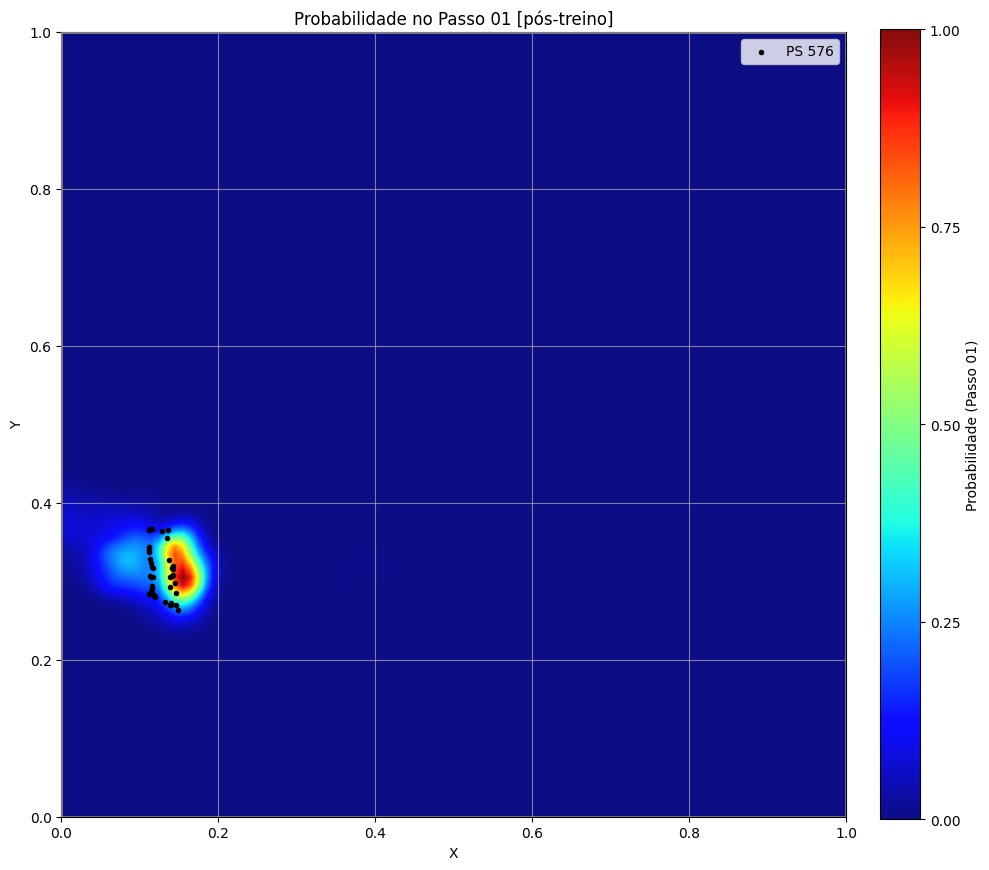

In [86]:
step_to_plot = 1
plot_next_id_probability_map_no_env(
    df_states=df,
    probs_df=snapshot_steps_df(full_fwd, 'probs'),
    current_id=current_id_for_step(full_fwd, step_to_plot),
    step=step_to_plot,
    cmap="jet",
    smooth_sigma=0.015,
    grid_size=100,
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag = '[pós-treino]'
)
plt.show()

## 681

In [87]:
ids_sequence_list_681 = generation_681['tokens']


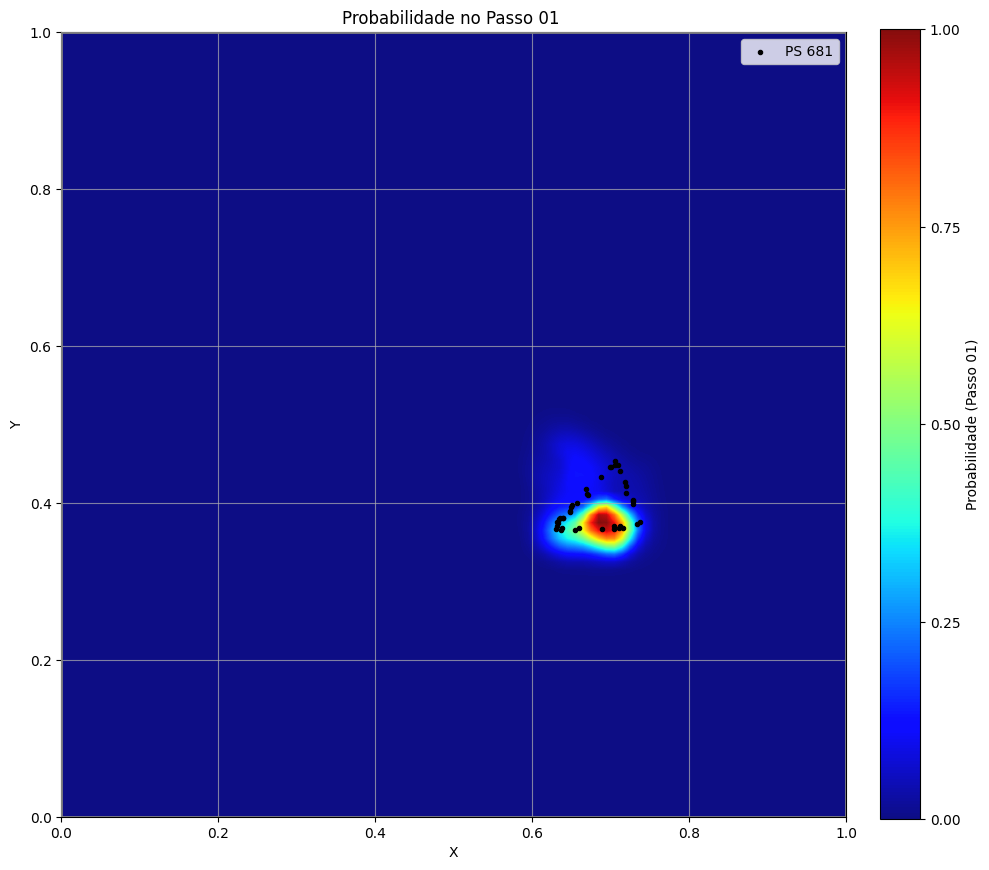

In [88]:
step_to_plot = 1
plot_next_id_probability_map_no_env(
    df_states=df,
    probs_df=distribs_probs,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="jet",
    smooth_sigma=0.015,
    grid_size=100,
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
)
plt.show()

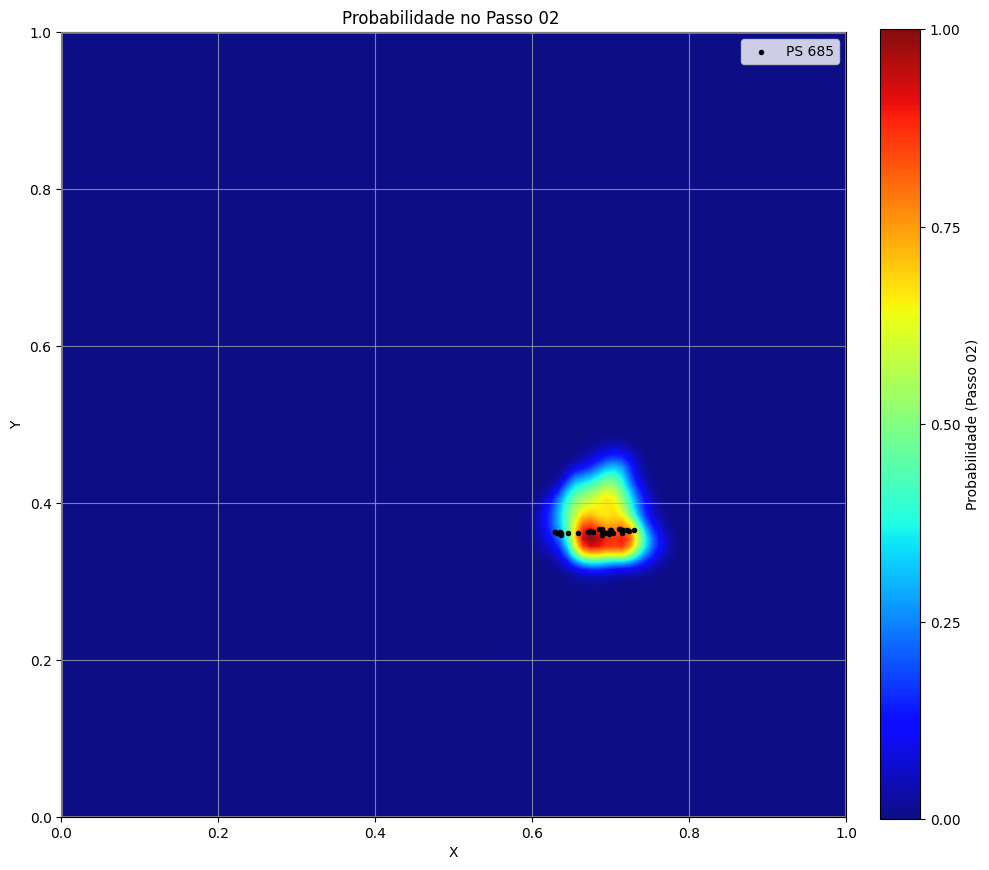

In [89]:
step_to_plot = 2
plot_next_id_probability_map_no_env(
    df_states=df,
    probs_df=distribs_probs,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="jet",
    smooth_sigma=0.015,
    grid_size=100,
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
)
plt.show()

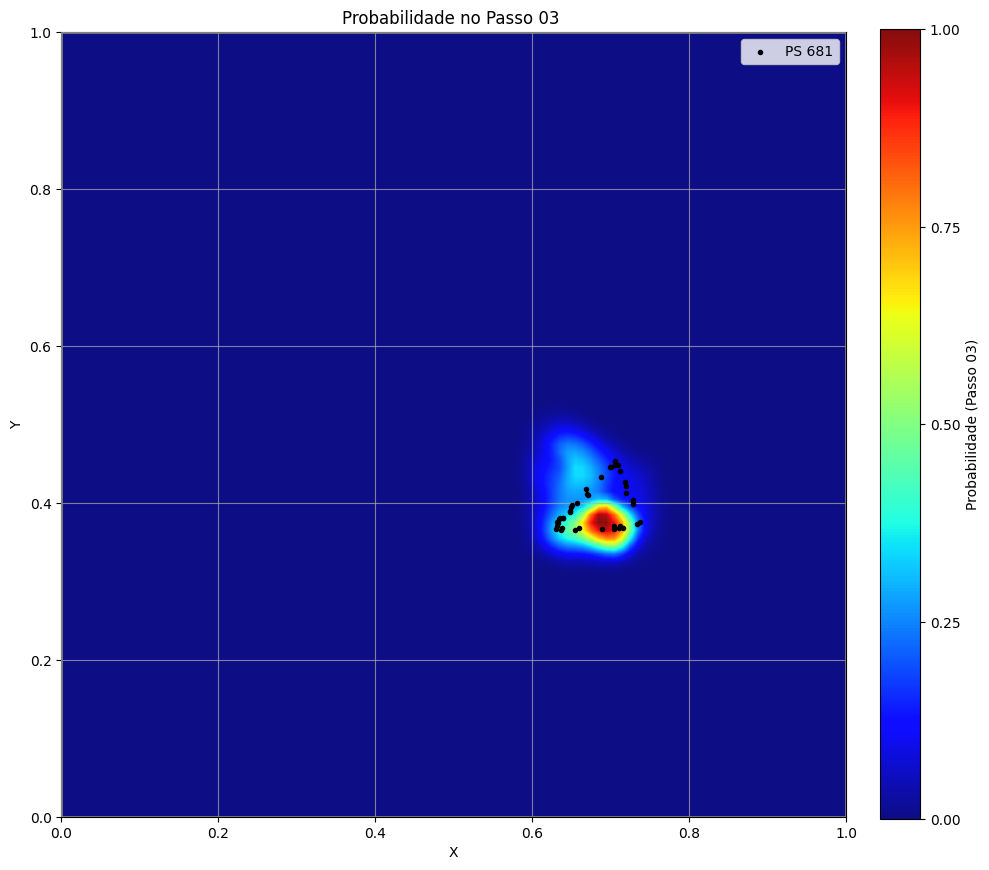

In [90]:
step_to_plot = 3
plot_next_id_probability_map_no_env(
    df_states=df,
    probs_df=distribs_probs,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="jet",
    smooth_sigma=0.015,
    grid_size=100,
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
)
plt.show()

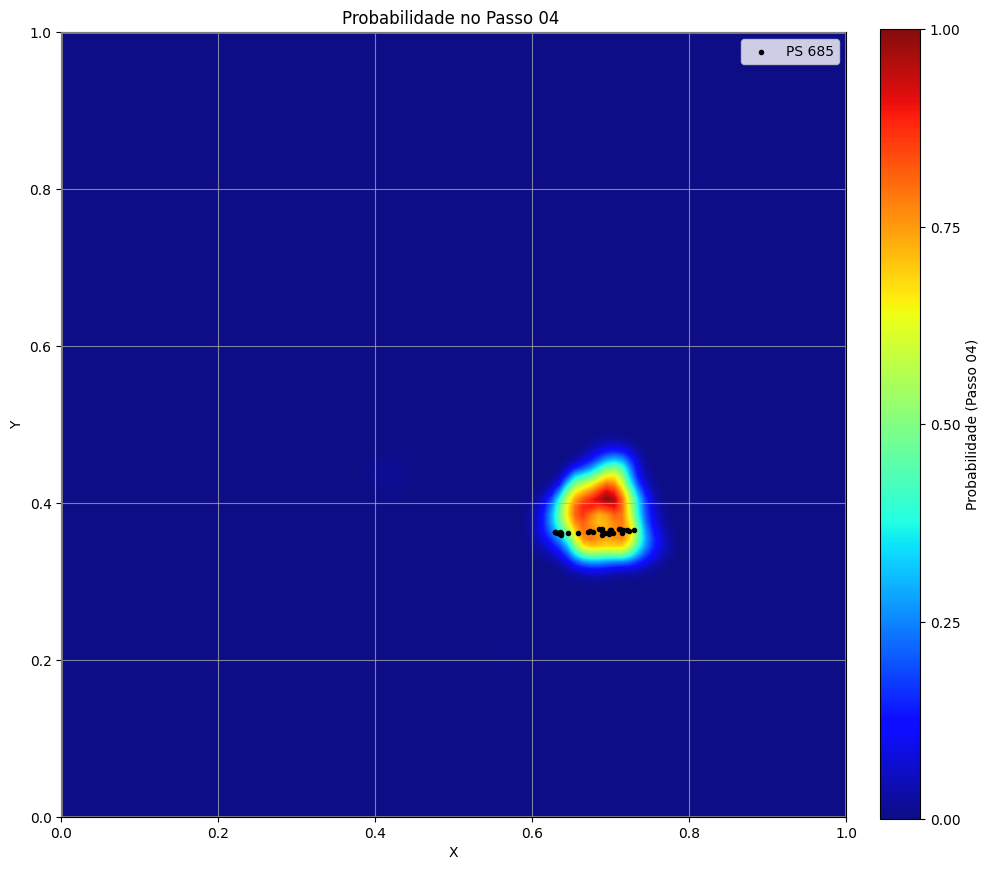

(<Figure size 1000x1000 with 2 Axes>,
 <Axes: title={'center': 'Probabilidade no Passo 04 '}, xlabel='X', ylabel='Y'>)

In [91]:
step_to_plot = 4
plot_next_id_probability_map_no_env(
    df_states=df,
    probs_df=distribs_probs,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="jet",
    smooth_sigma=0.015,
    grid_size=100,
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
)

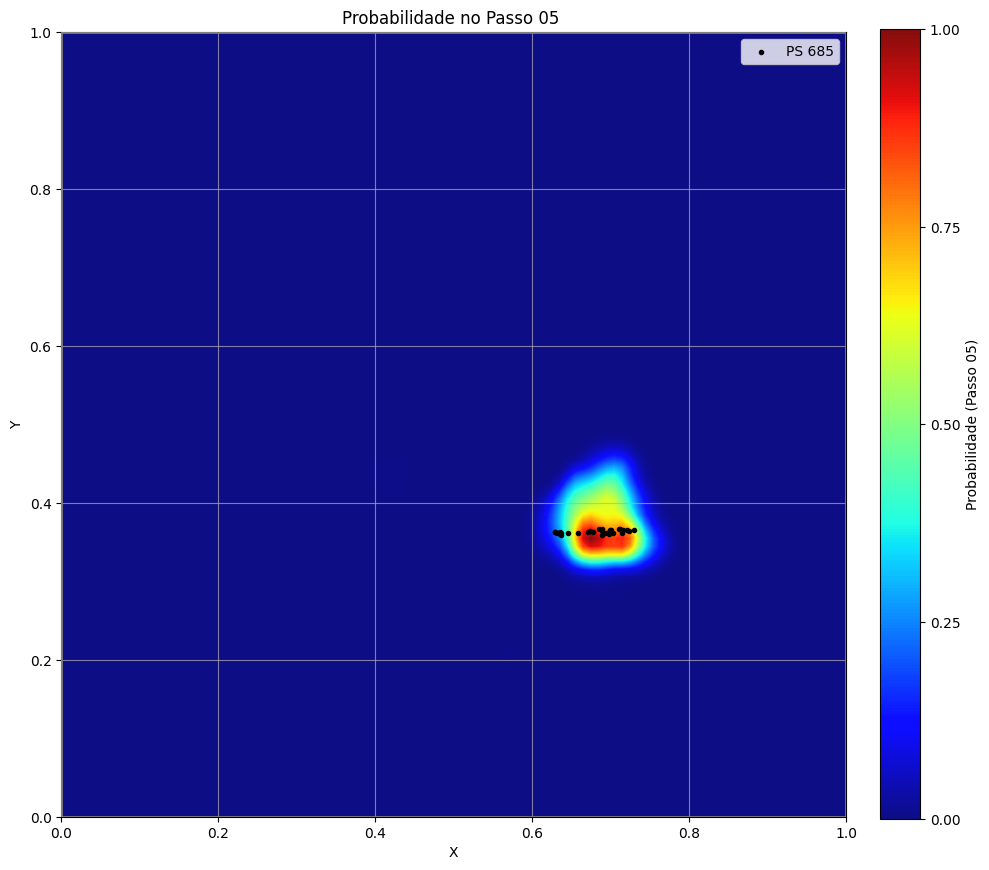

(<Figure size 1000x1000 with 2 Axes>,
 <Axes: title={'center': 'Probabilidade no Passo 05 '}, xlabel='X', ylabel='Y'>)

In [92]:
step_to_plot = 5
plot_next_id_probability_map_no_env(
    df_states=df,
    probs_df=distribs_probs,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="jet",
    smooth_sigma=0.015,
    grid_size=100,
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
)

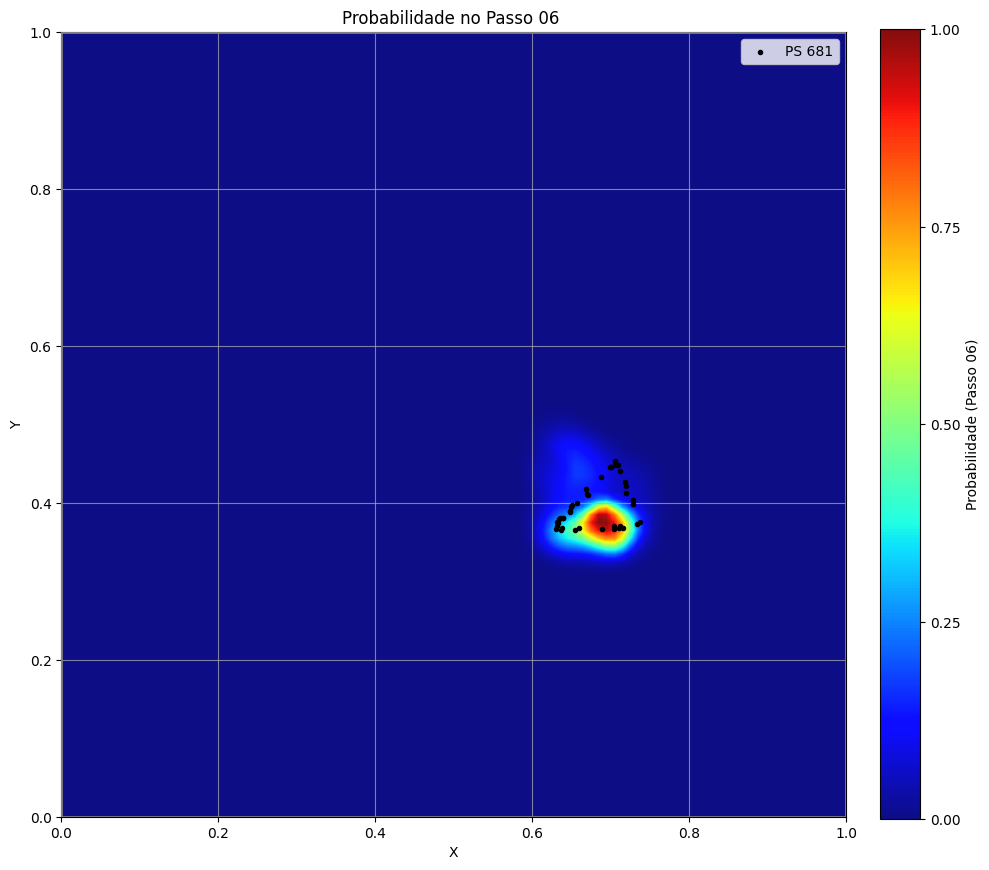

(<Figure size 1000x1000 with 2 Axes>,
 <Axes: title={'center': 'Probabilidade no Passo 06 '}, xlabel='X', ylabel='Y'>)

In [93]:
step_to_plot = 6
plot_next_id_probability_map_no_env(
    df_states=df,
    probs_df=distribs_probs,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="jet",
    smooth_sigma=0.015,
    grid_size=100,
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
)

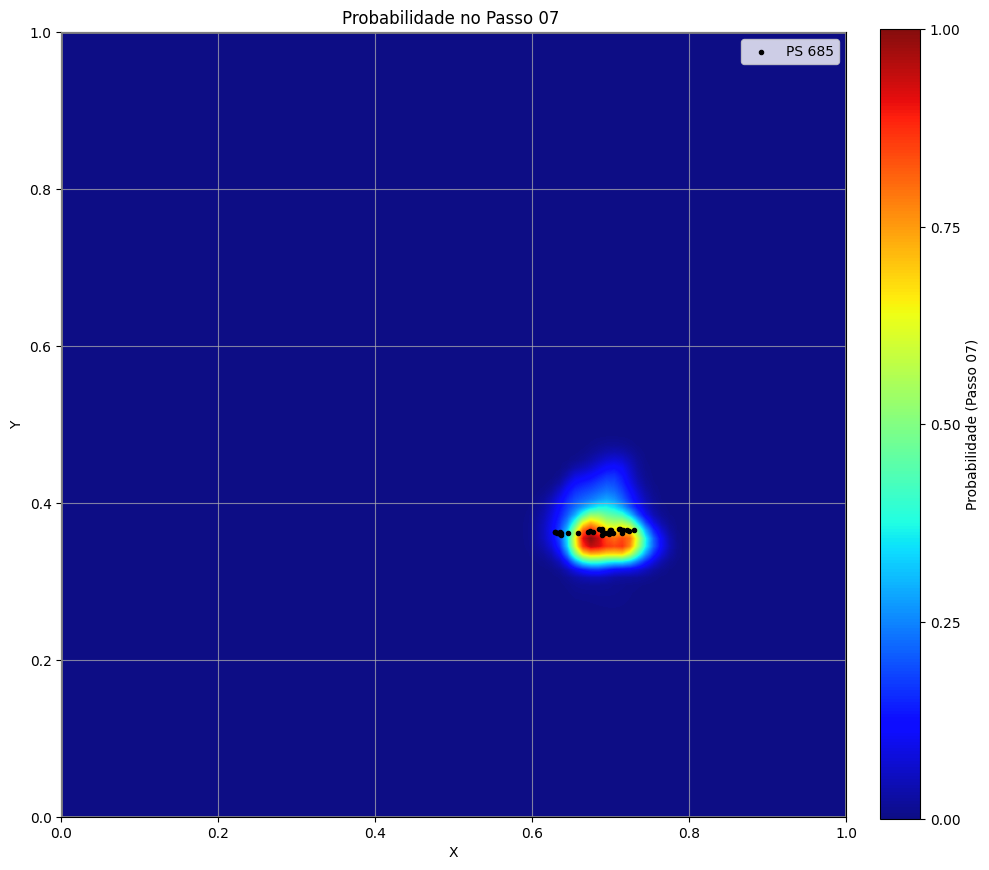

(<Figure size 1000x1000 with 2 Axes>,
 <Axes: title={'center': 'Probabilidade no Passo 07 '}, xlabel='X', ylabel='Y'>)

In [94]:
step_to_plot = 7
plot_next_id_probability_map_no_env(
    df_states=df,
    probs_df=distribs_probs,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="jet",
    smooth_sigma=0.015,
    grid_size=100,
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
)

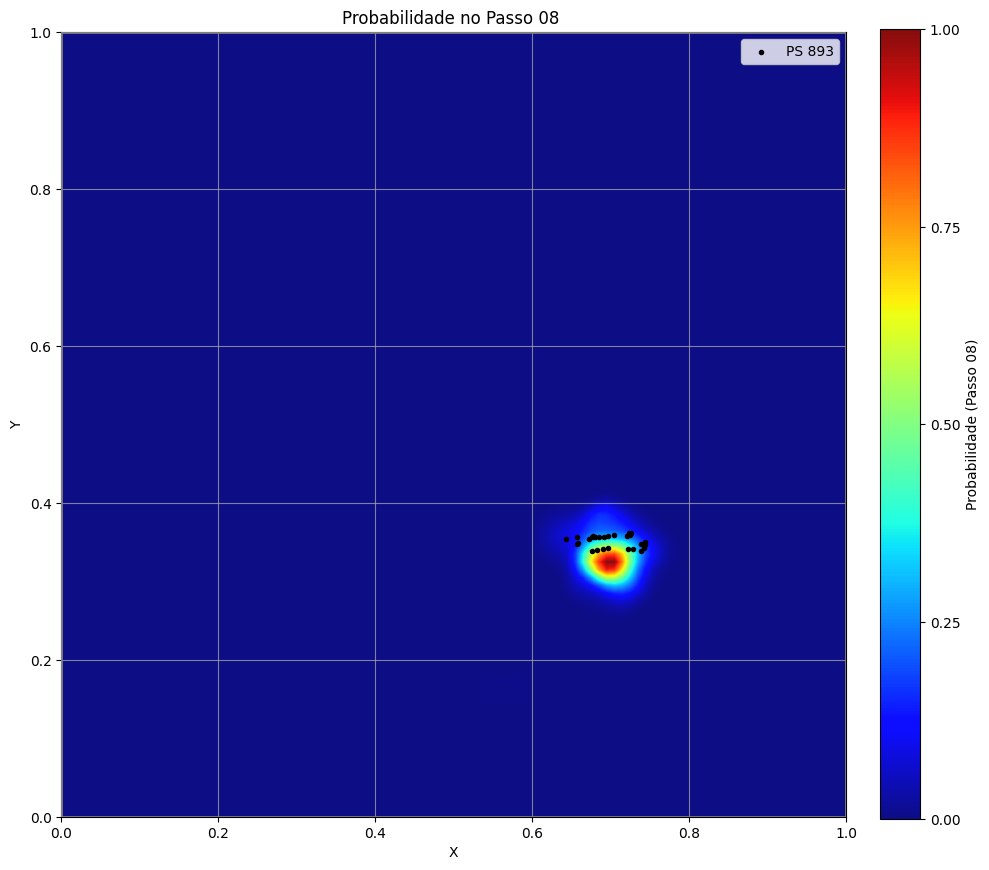

(<Figure size 1000x1000 with 2 Axes>,
 <Axes: title={'center': 'Probabilidade no Passo 08 '}, xlabel='X', ylabel='Y'>)

In [95]:
step_to_plot = 8
plot_next_id_probability_map_no_env(
    df_states=df,
    probs_df=distribs_probs,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="jet",
    smooth_sigma=0.015,
    grid_size=100,
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
)

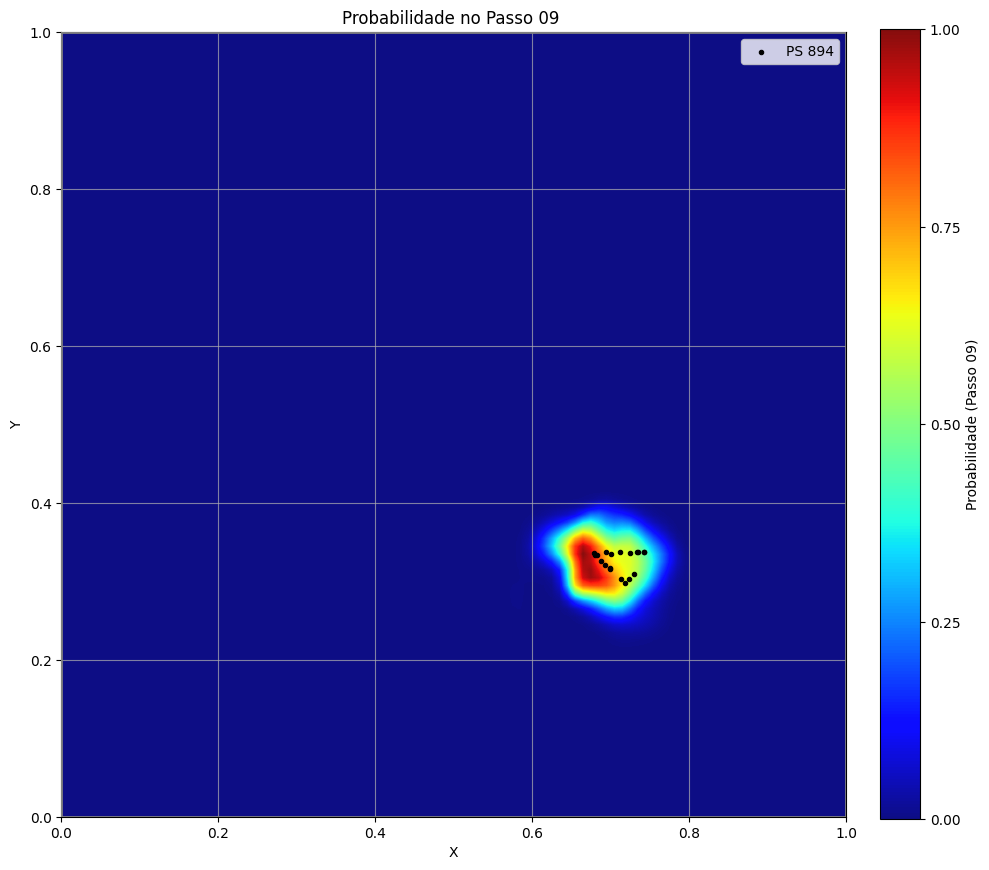

(<Figure size 1000x1000 with 2 Axes>,
 <Axes: title={'center': 'Probabilidade no Passo 09 '}, xlabel='X', ylabel='Y'>)

In [96]:
step_to_plot = 9
plot_next_id_probability_map_no_env(
    df_states=df,
    probs_df=distribs_probs,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="jet",
    smooth_sigma=0.015,
    grid_size=100,
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
)

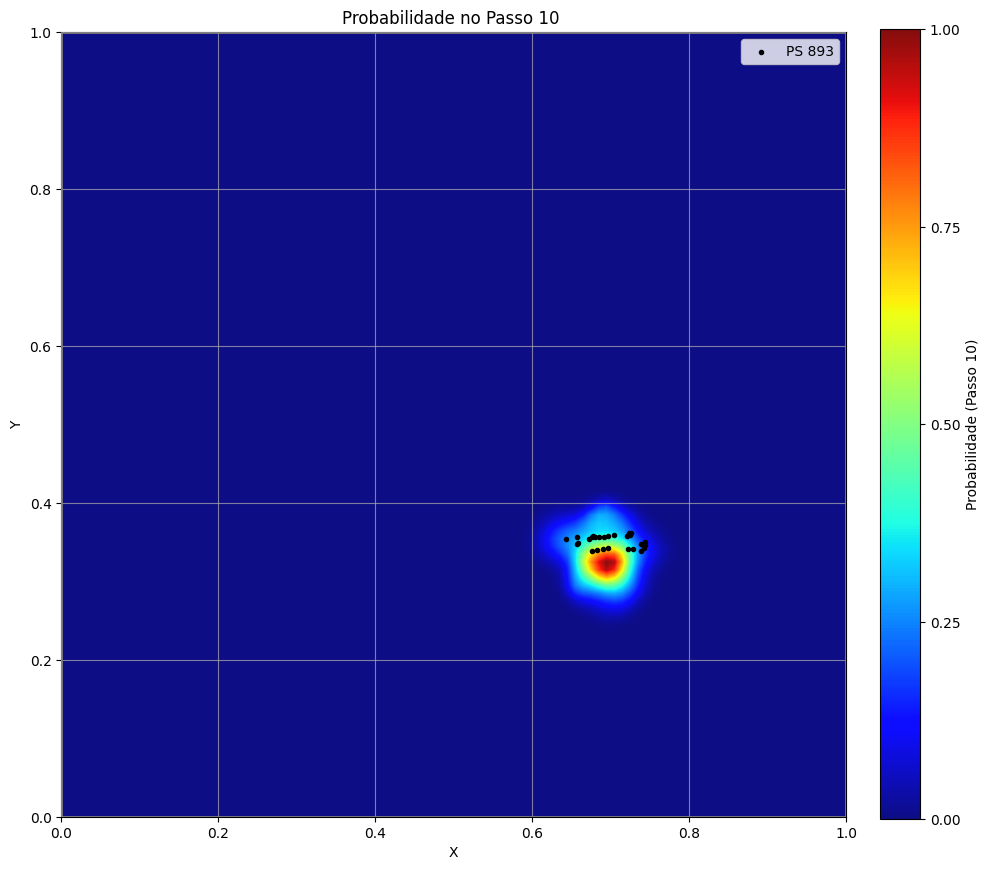

(<Figure size 1000x1000 with 2 Axes>,
 <Axes: title={'center': 'Probabilidade no Passo 10 '}, xlabel='X', ylabel='Y'>)

In [97]:
step_to_plot = 10
plot_next_id_probability_map_no_env(
    df_states=df,
    probs_df=distribs_probs,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="jet",
    smooth_sigma=0.015,
    grid_size=100,
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
)

## 507

In [98]:
with open(load_generation_path(model_tag, f'{model_tag}_gpt_generation_tokens_507.pkl'), 'rb') as fil:
    generation_507 = pickle.load(fil)
ids_sequence_list507 = generation_507['tokens']


In [99]:
ids_sequence_list507[1+7]

295

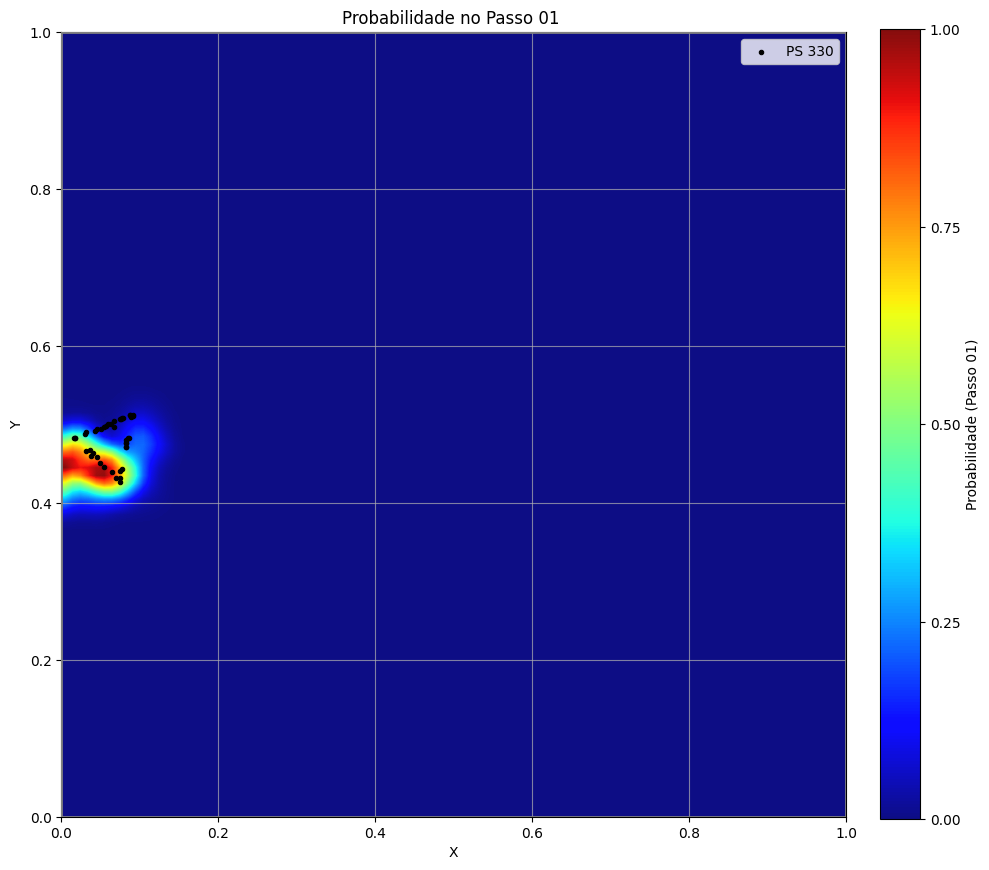

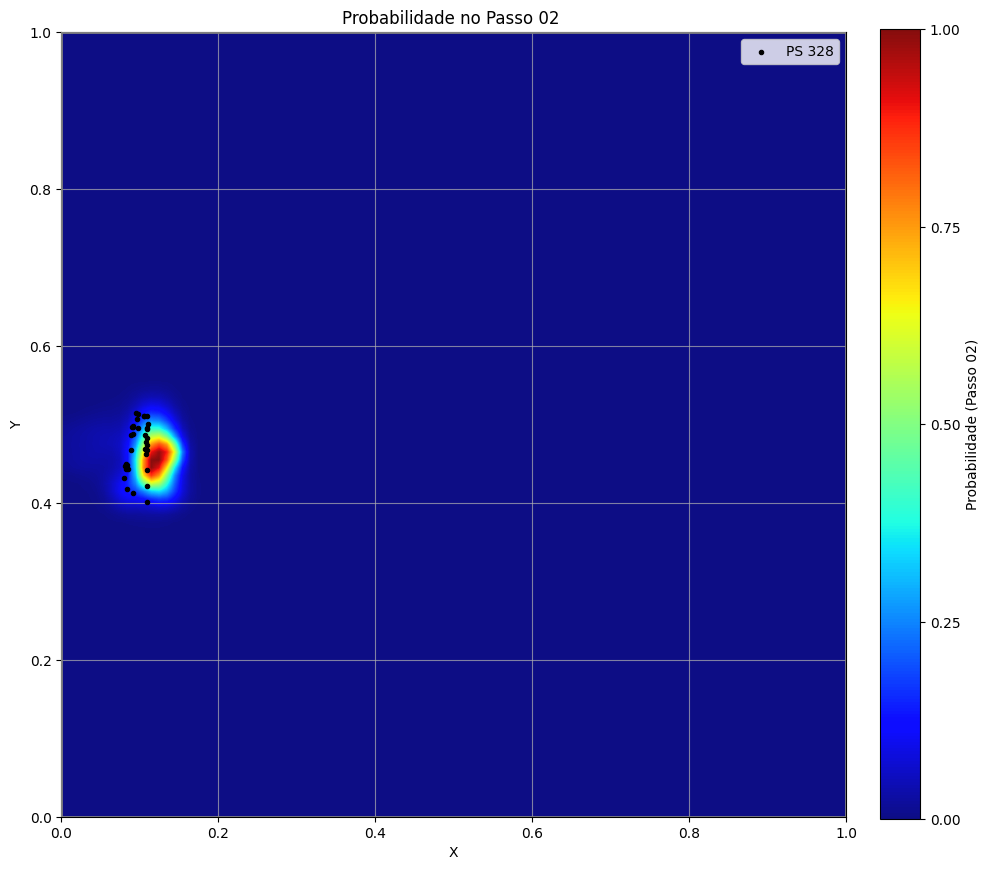

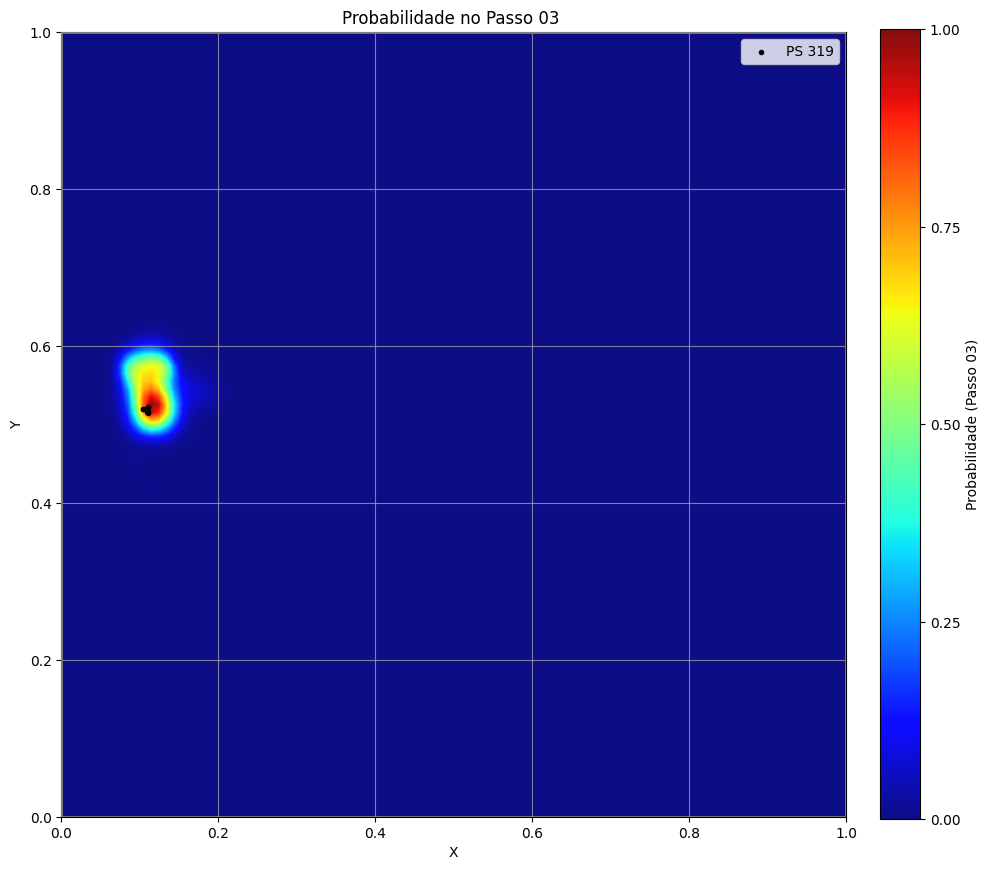

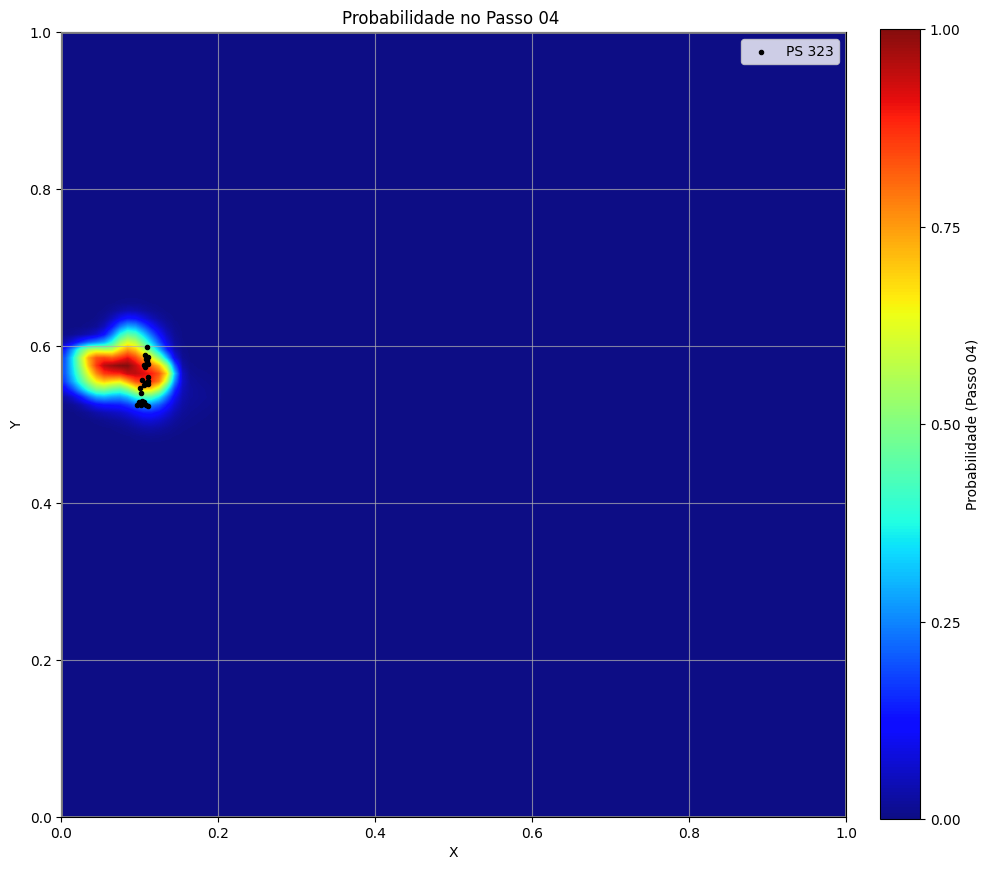

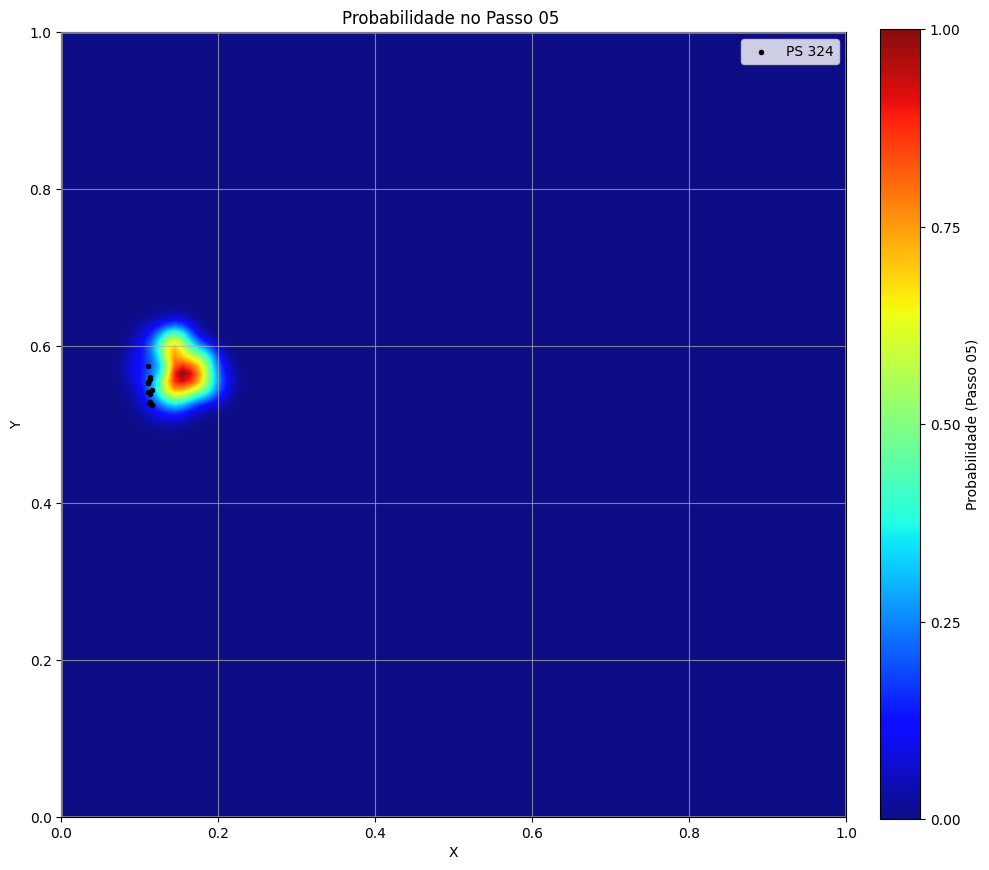

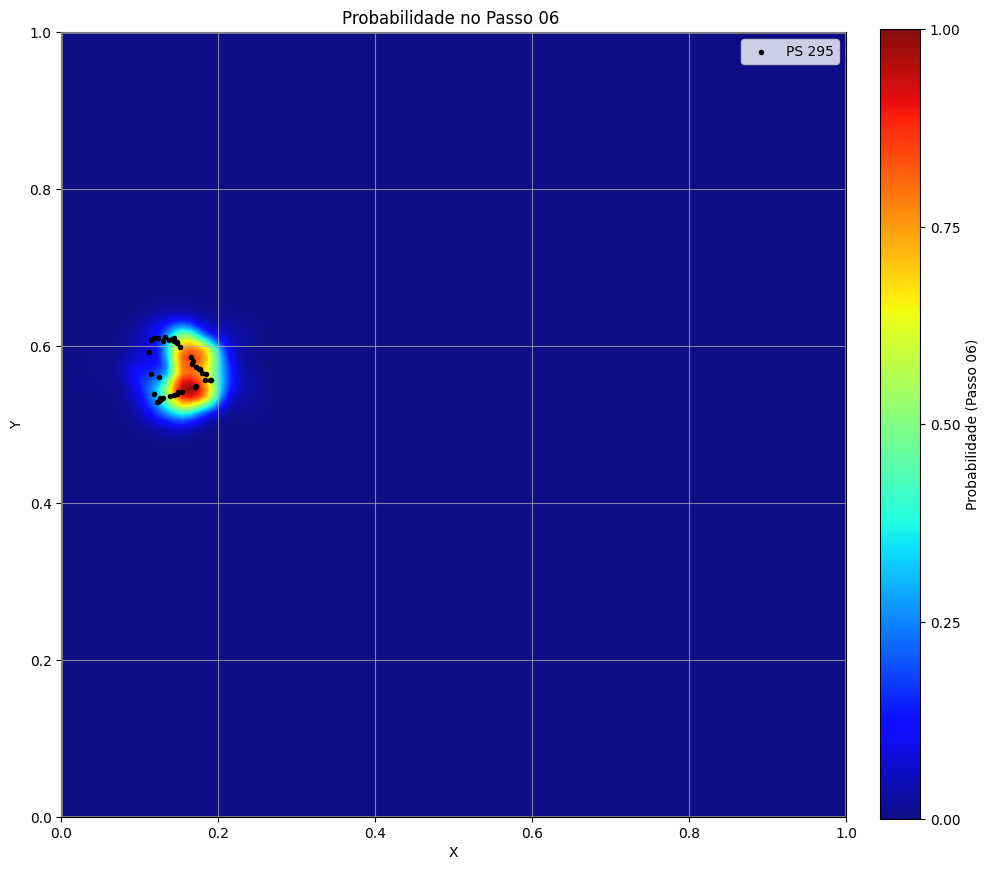

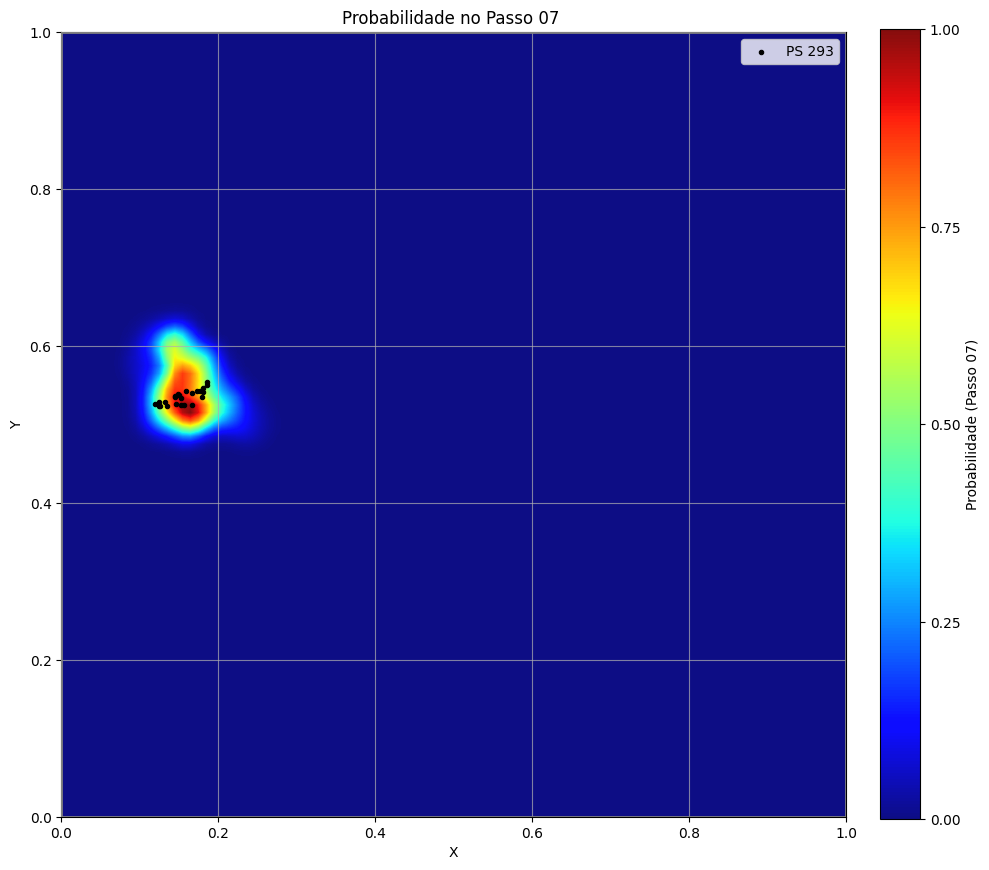

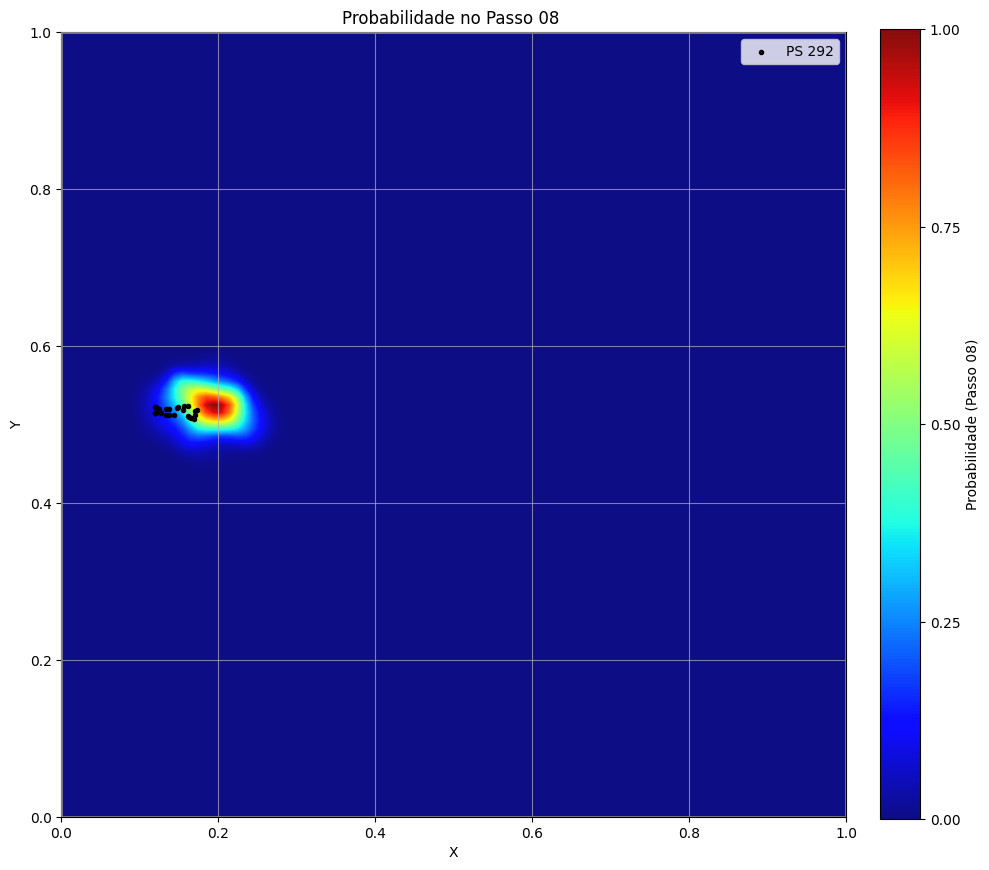

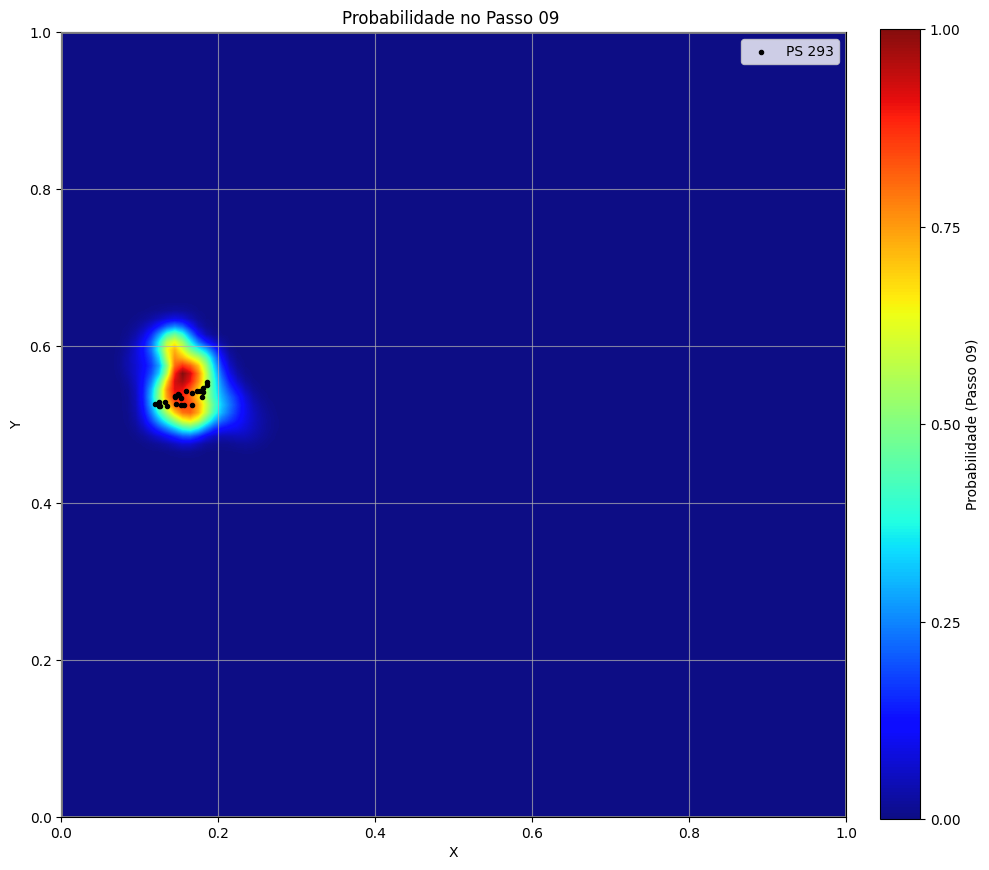

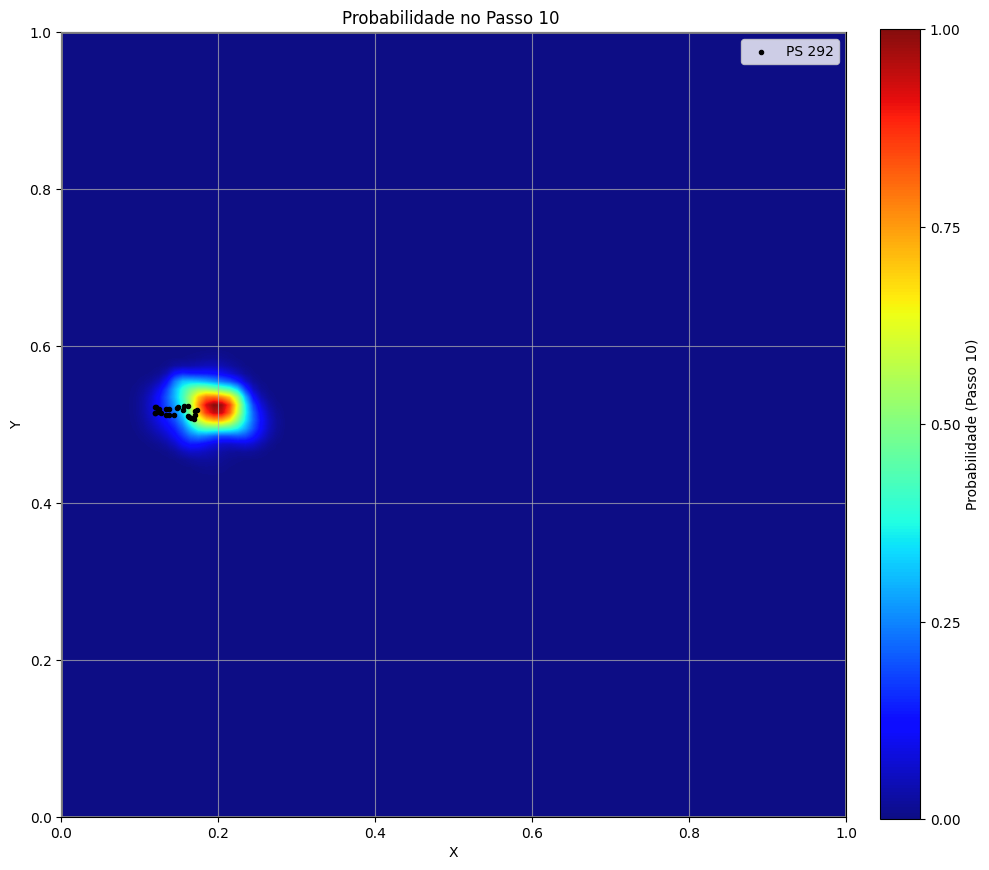

In [100]:
for i in range(1, 11):
    step_to_plot = i
    plot_next_id_probability_map_no_env(
        df_states=df,
        probs_df=distribs_probs507,
        current_id=generated_current_id(generation_507, step_to_plot),
        step=step_to_plot,
        cmap="jet",
        smooth_sigma=0.015,
        grid_size=100,
        prob_power=1.,
        current_color="k",
        current_size=10,
        current_alpha=1,
        show_current_label=False,
    )

# Logits Distrib

In [101]:
def _parse_xy(v):
    """
    Converte `pos` para (x, y).
    Aceita:
      - [x, y]
      - (x, y)
      - np.array([x, y])
      - string "[x, y]"
    """
    if isinstance(v, str):
        v = ast.literal_eval(v)

    if isinstance(v, (list, tuple, np.ndarray)) and len(v) == 2:
        return float(v[0]), float(v[1])

    raise ValueError(f"Valor inválido em pos: {v}")


def _resolve_step_col(step):
    """
    Aceita:
      - 'Passo 01'
      - 1, 2, ..., 10
    """
    if isinstance(step, str):
        return step
    if isinstance(step, int):
        return f"Passo {step:02d}"
    raise ValueError("`step` deve ser int ou str.")


def plot_next_id_logits_map_no_env(
    df_states,
    logits_df,
    current_id,
    *,
    step="Passo 01",
    pos_col="pos",
    id_col="position_state_id",
    logits_id_col=None,
    xlim=(0.0, 1.0),
    ylim=(0.0, 1.0),
    figsize=(10, 10),
    cmap="coolwarm",
    current_color="lightgray",
    current_alpha=0.95,
    current_size=20,
    show_current_label=True,
    smooth_sigma=0.03,
    grid_size=250,
    min_support=1e-6,
    logit_power=1.0,
    preserve_sign=True,
    include_current_in_field=True,
    center_colormap_at_zero=True,
    show_colorbar=True,
    env_linewidth=2.0,
    env_color="gray",
    grid=True,
    grid_alpha=0.7,
    interpolation="bilinear",
    colorbar_num_ticks=5,
    title_tag = '',
):
    """
    Plota um mapa espacial suavizado de logits do próximo id, sem depender de Env.

    Regras:
    - plota apenas a coluna selecionada por `step`
    - mas a escala da colorbar é calculada usando TODO o dataframe de logits
    - assim, todos os plots compartilham a mesma escala de cores
    """

    step_col = _resolve_step_col(step)

    # ----------------------------
    # prepara logits_df
    # ----------------------------
    logits = logits_df.copy()

    if logits_id_col is not None:
        logits = logits.set_index(logits_id_col)

    if step_col not in logits.columns:
        raise ValueError(
            f"Coluna '{step_col}' não encontrada em logits_df. "
            f"Colunas disponíveis: {list(logits.columns)}"
        )

    # ----------------------------
    # prepara df_states
    # ----------------------------
    df = df_states.copy()

    xy = df[pos_col].apply(_parse_xy)
    df["_x"] = [p[0] for p in xy]
    df["_y"] = [p[1] for p in xy]

    try:
        logits.index = logits.index.astype(df[id_col].dtype, copy=False)
    except Exception:
        pass

    # mapa de logits apenas do passo escolhido
    logit_map = logits[step_col].to_dict()
    df["_logit"] = df[id_col].map(logit_map).fillna(0.0)

    df_current = df[df[id_col] == current_id].copy()
    df_field = df.copy() if include_current_in_field else df[df[id_col] != current_id].copy()

    if len(df_current) == 0:
        raise ValueError(f"Nenhuma linha encontrada para current_id={current_id}")

    # ----------------------------
    # ajuste opcional de contraste
    # ----------------------------
    if logit_power != 1.0:
        vals = df_field["_logit"].to_numpy(float)
        if preserve_sign:
            vals = np.sign(vals) * (np.abs(vals) ** logit_power)
        else:
            vals = vals ** logit_power
        df_field["_logit"] = vals

    # ----------------------------
    # malha do ambiente
    # ----------------------------
    xmin, xmax = xlim
    ymin, ymax = ylim

    gx = np.linspace(xmin, xmax, grid_size)
    gy = np.linspace(ymin, ymax, grid_size)
    XX, YY = np.meshgrid(gx, gy)

    field = np.zeros_like(XX, dtype=float)
    support = np.zeros_like(XX, dtype=float)

    # ----------------------------
    # suavização espacial
    # ----------------------------
    if len(df_field) > 0 and np.any(np.abs(df_field["_logit"].to_numpy(float)) > 0):
        xs = df_field["_x"].to_numpy(float)
        ys = df_field["_y"].to_numpy(float)
        ws = df_field["_logit"].to_numpy(float)

        for x0, y0, w in zip(xs, ys, ws):
            d2 = (XX - x0) ** 2 + (YY - y0) ** 2
            k = np.exp(-0.5 * d2 / (smooth_sigma ** 2))
            field += w * k
            support += k

        smoothed = np.zeros_like(field)
        valid = support > min_support
        smoothed[valid] = field[valid] / support[valid]
        smoothed = np.ma.array(smoothed, mask=~valid)
    else:
        smoothed = np.ma.array(np.zeros_like(field), mask=np.ones_like(field, dtype=bool))

    # ----------------------------
    # escala global da cor
    # usa TODO o dataframe de logits
    # ----------------------------
    all_logits = logits.to_numpy(dtype=float)
    finite_logits = all_logits[np.isfinite(all_logits)]

    if finite_logits.size == 0:
        vmin_global, vmax_global = -1.0, 1.0
    else:
        vmin_global = float(finite_logits.min())
        vmax_global = float(finite_logits.max())

        if vmin_global == vmax_global:
            eps = 1e-6 if vmin_global == 0 else abs(vmin_global) * 1e-6
            vmin_global -= eps
            vmax_global += eps

    if center_colormap_at_zero and (vmin_global < 0 < vmax_global):
        vmax_abs = max(abs(vmin_global), abs(vmax_global))
        norm = TwoSlopeNorm(vmin=-vmax_abs, vcenter=0.0, vmax=vmax_abs)
        tick_min, tick_max = -vmax_abs, vmax_abs
    else:
        norm = Normalize(vmin=vmin_global, vmax=vmax_global)
        tick_min, tick_max = vmin_global, vmax_global

    # ----------------------------
    # plot
    # ----------------------------
    fig, ax = plt.subplots(figsize=figsize)

    im = ax.imshow(
        smoothed,
        extent=[xmin, xmax, ymin, ymax],
        origin="lower",
        cmap=cmap,
        norm=norm,
        interpolation=interpolation,
        alpha=0.95,
        zorder=1,
    )

    # current_id destacado
    ax.scatter(
        df_current["_x"],
        df_current["_y"],
        s=current_size,
        color=current_color,
        alpha=current_alpha,
        zorder=3,
        label=f"PS {current_id}",
    )

    if show_current_label:
        cx = df_current["_x"].mean()
        cy = df_current["_y"].mean()
        ax.text(
            cx,
            cy,
            str(current_id),
            fontsize=10,
            color="black",
            ha="center",
            va="center",
            zorder=4,
        )

    # moldura manual do ambiente
    ax.plot([xmin, xmax], [ymin, ymin], color=env_color, linewidth=env_linewidth, zorder=5)
    ax.plot([xmin, xmax], [ymax, ymax], color=env_color, linewidth=env_linewidth, zorder=5)
    ax.plot([xmin, xmin], [ymin, ymax], color=env_color, linewidth=env_linewidth, zorder=5)
    ax.plot([xmax, xmax], [ymin, ymax], color=env_color, linewidth=env_linewidth, zorder=5)

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_aspect("equal")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_title(f"Logits no {step_col} {title_tag}")

    if grid:
        ax.grid(True, alpha=grid_alpha)

    ax.legend(loc="upper right", frameon=True)

    if show_colorbar:
        cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        cbar.set_label(f"Logit ({step_col})")
        cbar.set_ticks(np.linspace(tick_min, tick_max, colorbar_num_ticks))

    plt.tight_layout()
    plt.show()

    return fig, ax

In [102]:
# plot_logits_from_logits_df_w_pos(apd, distribs_logits, passo=0, token_atual=15)

In [103]:
distribs_logits.describe()

,Passo 01,Passo 02,Passo 03,Passo 04,Passo 05,Passo 06,Passo 07,Passo 08,Passo 09,Passo 10
count,948.000000,948.000000,948.000000,948.000000,948.000000,948.000000,948.000000,948.000000,948.000000,948.000000
mean,0.309680,-0.155432,0.099888,-0.331968,-0.300987,0.189670,-0.216390,0.221385,0.221463,-0.091306
std,10.360270,10.407240,10.666090,10.427608,10.433282,10.407085,10.378700,10.802385,10.211565,11.279083
min,-23.560556,-28.686617,-24.605898,-29.237860,-28.773670,-23.670200,-27.482735,-27.321117,-24.757280,-29.430908
25%,-7.092647,-7.535493,-7.700435,-7.521260,-7.640739,-7.191985,-7.667290,-7.088661,-7.035792,-8.178162
50%,0.559299,0.227021,0.496149,0.285187,0.188367,0.333626,0.121475,0.029224,-0.498693,-0.330960
75%,7.661715,7.406494,7.959578,7.334866,7.297082,7.571896,7.487047,8.012572,7.610290,8.252780
max,29.692514,28.726954,29.013190,27.599870,28.256754,29.451511,29.458982,33.388980,30.196800,31.948769


### train loop

In [104]:
full_fwd_pre_train['logits'].shape

(9, 948)

#### pre train

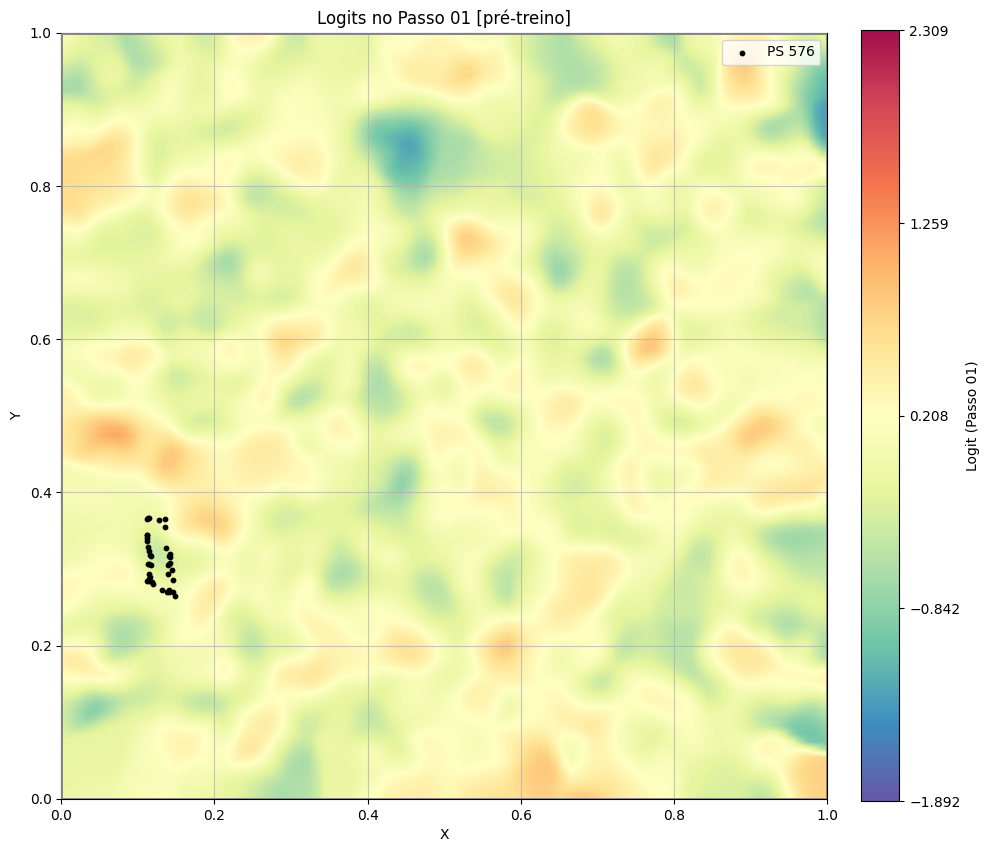

In [105]:
step_to_plot = 1
plot_next_id_logits_map_no_env(
    df_states=df,
    logits_df=snapshot_steps_df(full_fwd_pre_train, 'logits'),
    current_id=current_id_for_step(full_fwd_pre_train, step_to_plot),
    step=step_to_plot,
    cmap="Spectral_r",
    smooth_sigma=0.015,
    grid_size=100,
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
    title_tag = '[pré-treino]'
)
plt.show()

#### mid train 100

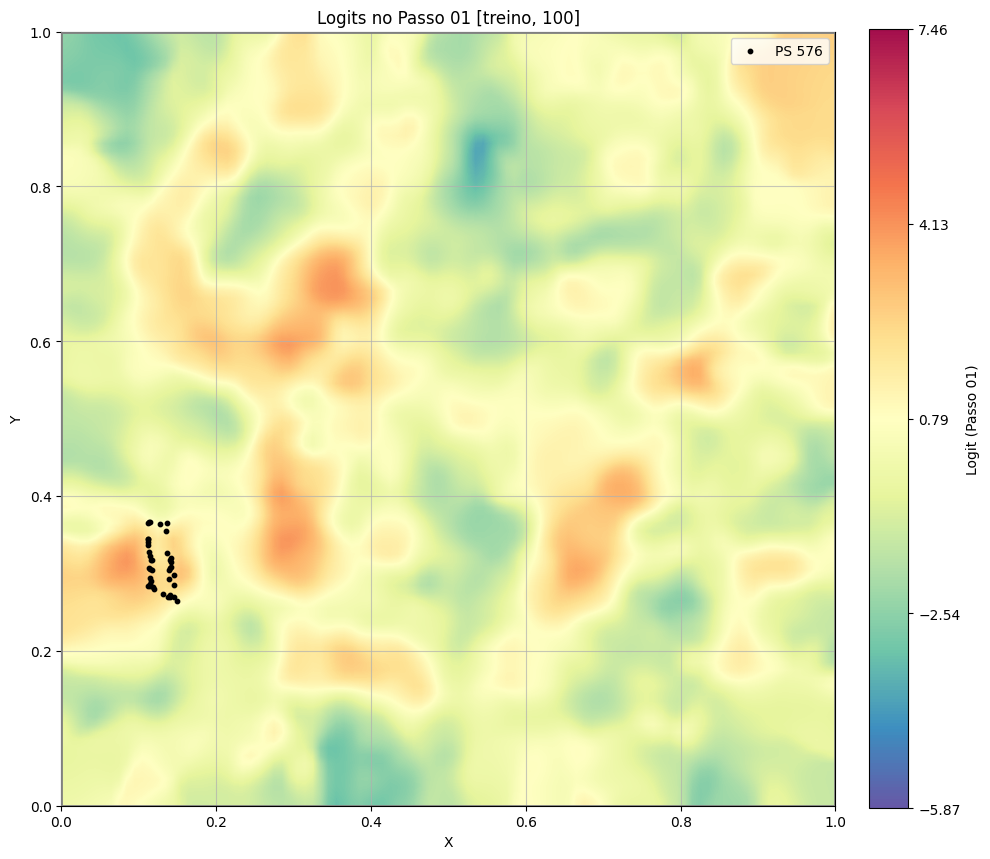

In [106]:
step_to_plot = 1
plot_next_id_logits_map_no_env(
    df_states=df,
    logits_df=snapshot_steps_df(full_fwd_100, 'logits'),
    current_id=current_id_for_step(full_fwd_100, step_to_plot),
    step=step_to_plot,
    cmap="Spectral_r",
    smooth_sigma=0.015,
    grid_size=100,
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
    title_tag = '[treino, 100]'
)
plt.show()

#### mid train 200

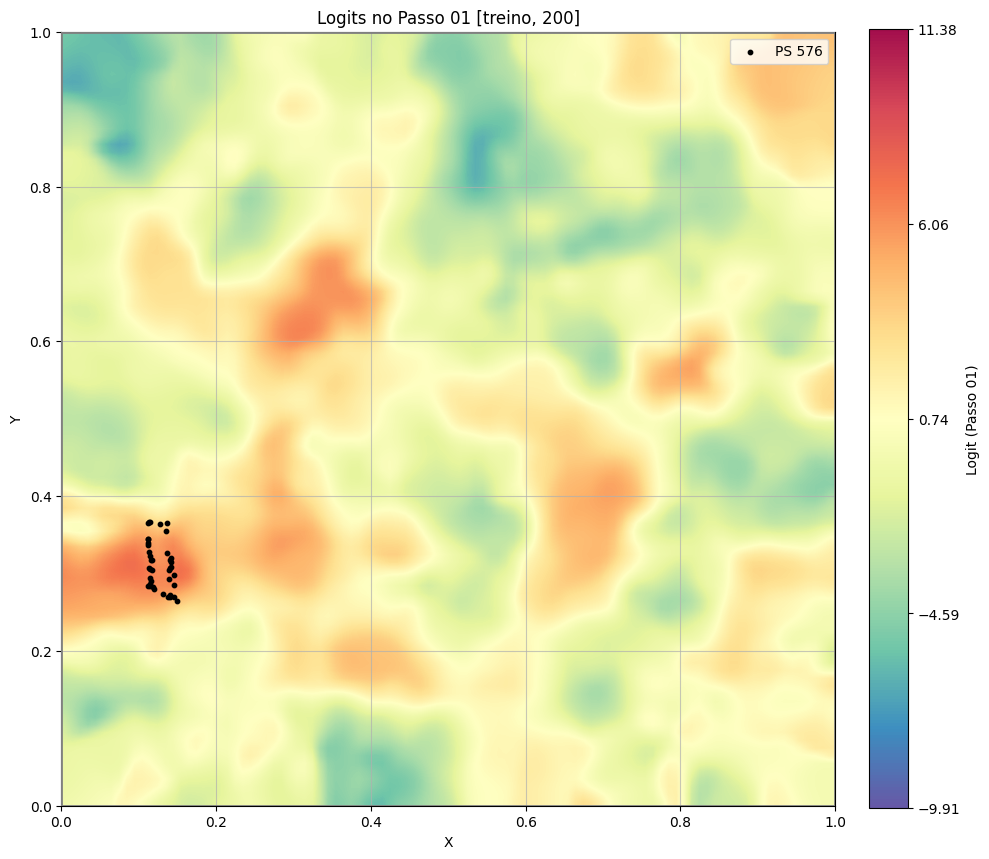

In [107]:
step_to_plot = 1
plot_next_id_logits_map_no_env(
    df_states=df,
    logits_df=snapshot_steps_df(full_fwd_200, 'logits'),
    current_id=current_id_for_step(full_fwd_200, step_to_plot),
    step=step_to_plot,
    cmap="Spectral_r",
    smooth_sigma=0.015,
    grid_size=100,
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
    title_tag = '[treino, 200]'
)
plt.show()

#### mid train 500

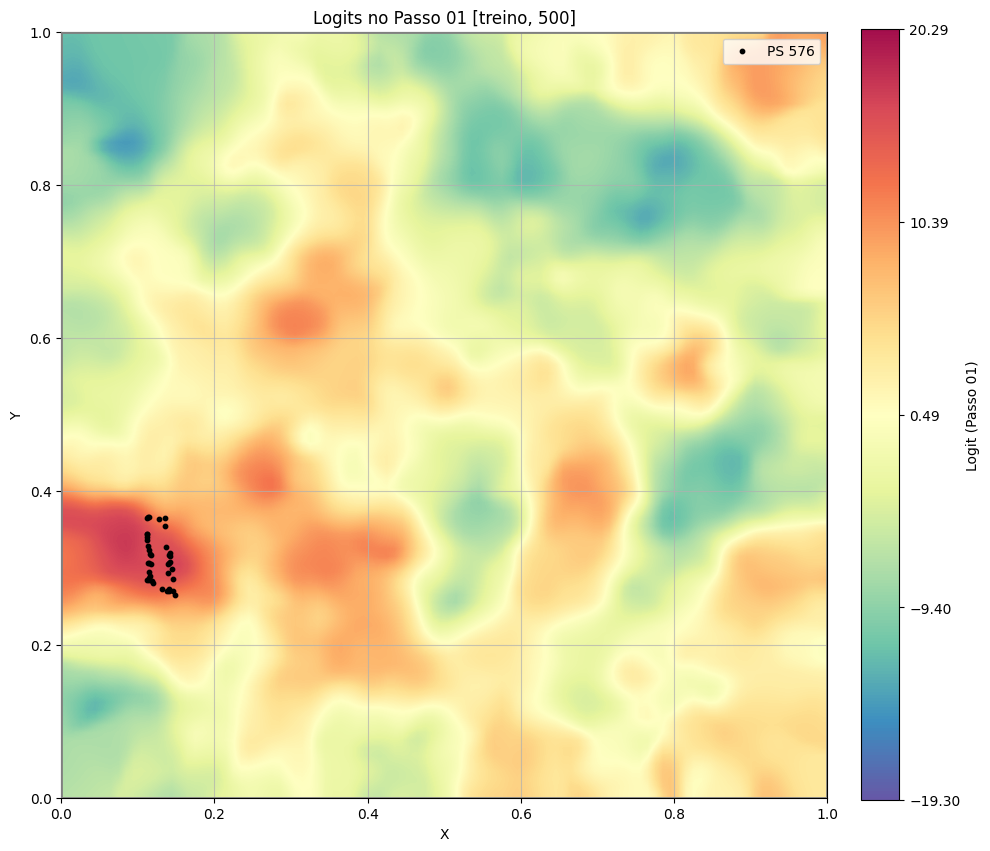

In [108]:
step_to_plot = 1
plot_next_id_logits_map_no_env(
    df_states=df,
    logits_df=snapshot_steps_df(full_fwd_500, 'logits'),
    current_id=current_id_for_step(full_fwd_500, step_to_plot),
    step=step_to_plot,
    cmap="Spectral_r",
    smooth_sigma=0.015,
    grid_size=100,
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
    title_tag = '[treino, 500]'
)
plt.show()

#### post train

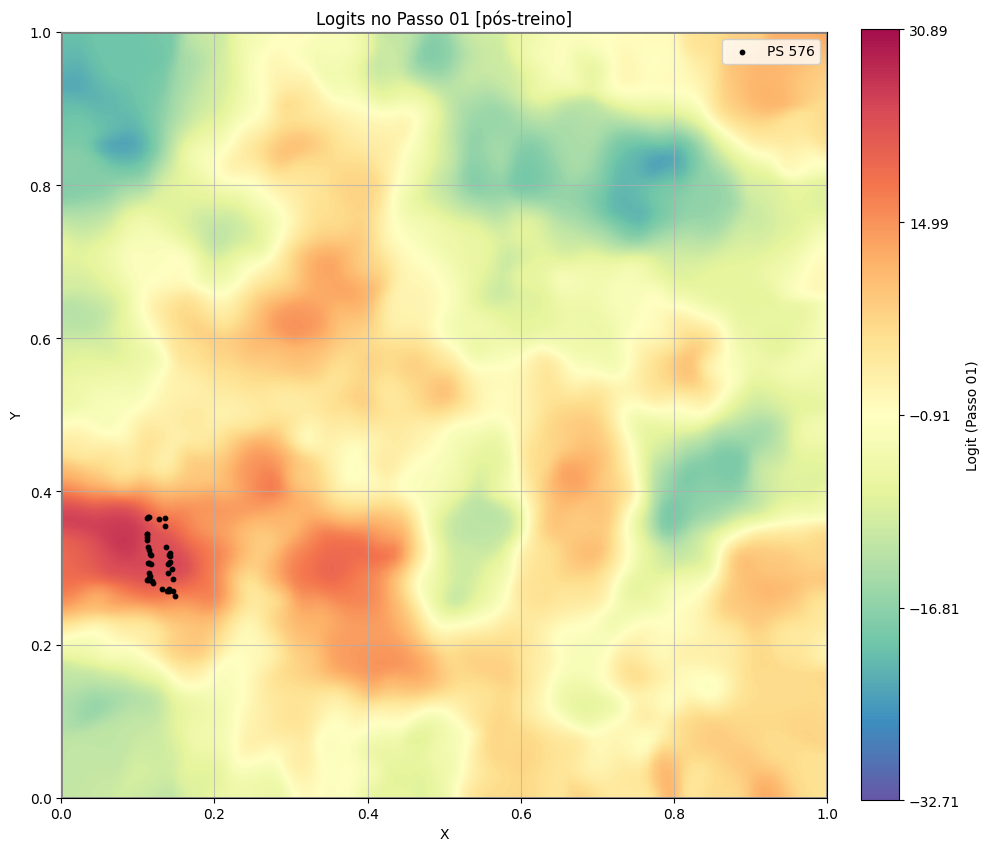

In [109]:
step_to_plot = 1
plot_next_id_logits_map_no_env(
    df_states=df,
    logits_df=snapshot_steps_df(full_fwd, 'logits'),
    current_id=current_id_for_step(full_fwd, step_to_plot),
    step=step_to_plot,
    cmap="Spectral_r",
    smooth_sigma=0.015,
    grid_size=100,
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
    title_tag = '[pós-treino]'
)
plt.show()

### 681

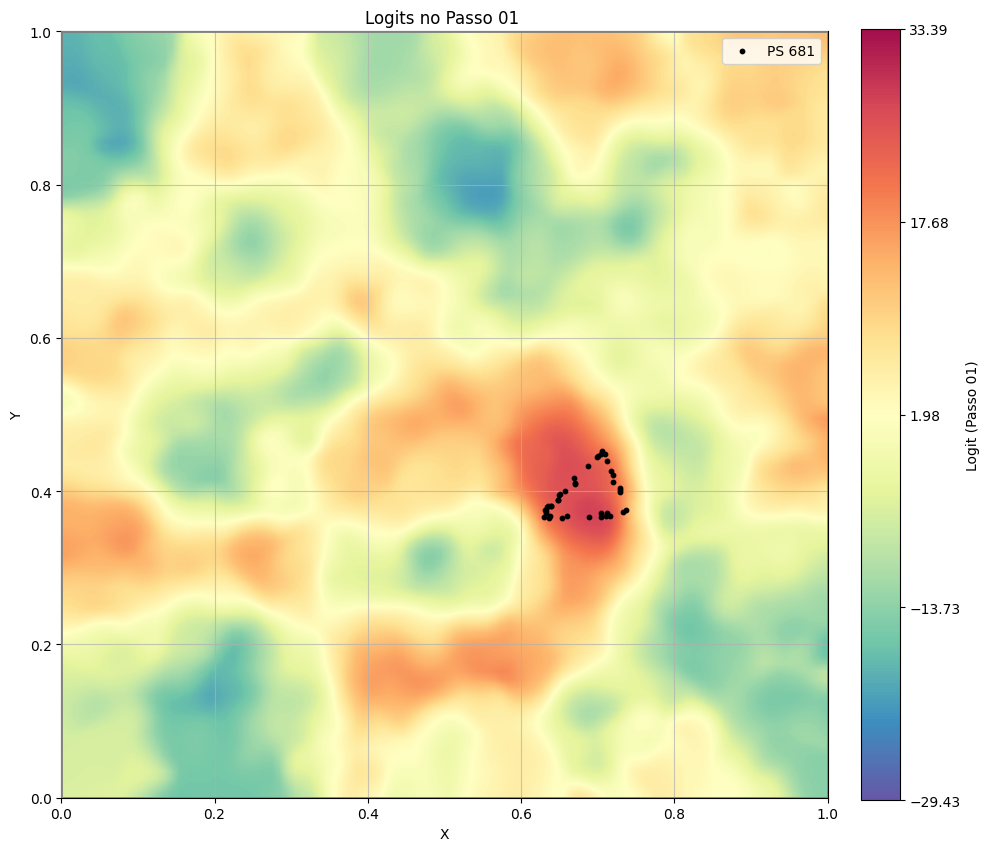

In [110]:
step_to_plot = 1
plot_next_id_logits_map_no_env(
    df_states=df,
    logits_df=distribs_logits,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="Spectral_r",
    smooth_sigma=0.015,
    grid_size=100,
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
)
plt.show()

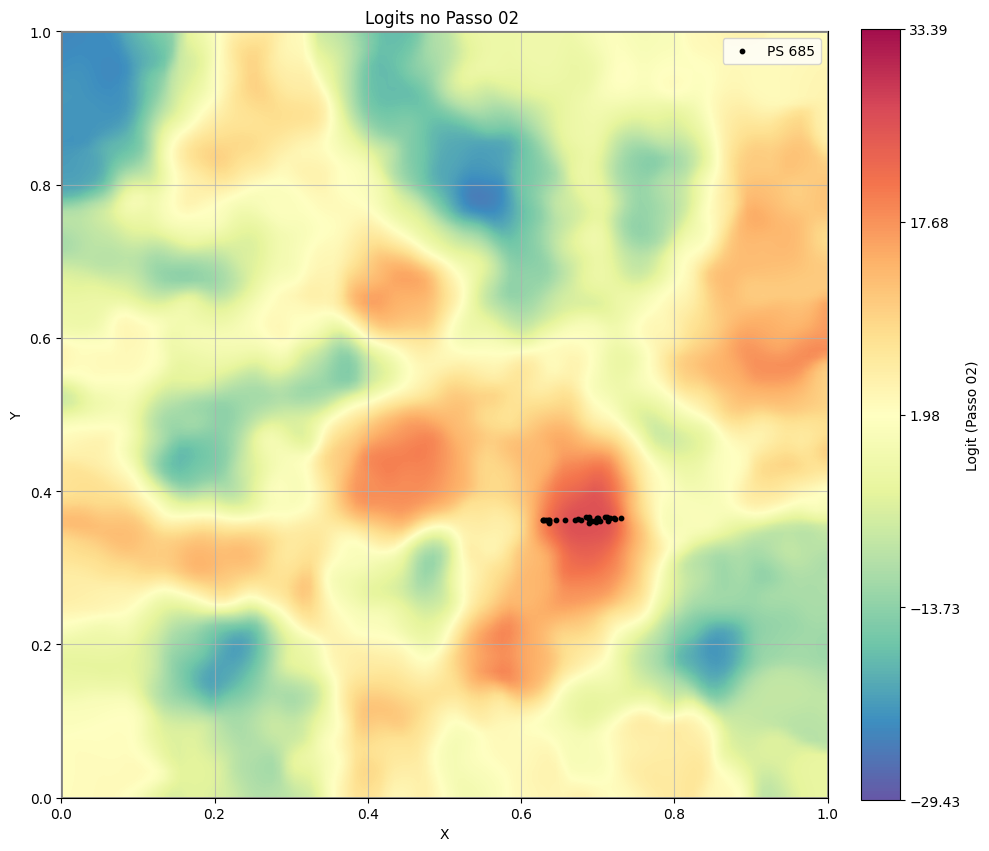

In [111]:
step_to_plot = 2
plot_next_id_logits_map_no_env(
    df_states=df,
    logits_df=distribs_logits,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="Spectral_r",
    smooth_sigma=0.015,
    grid_size=100,
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
)
plt.show()

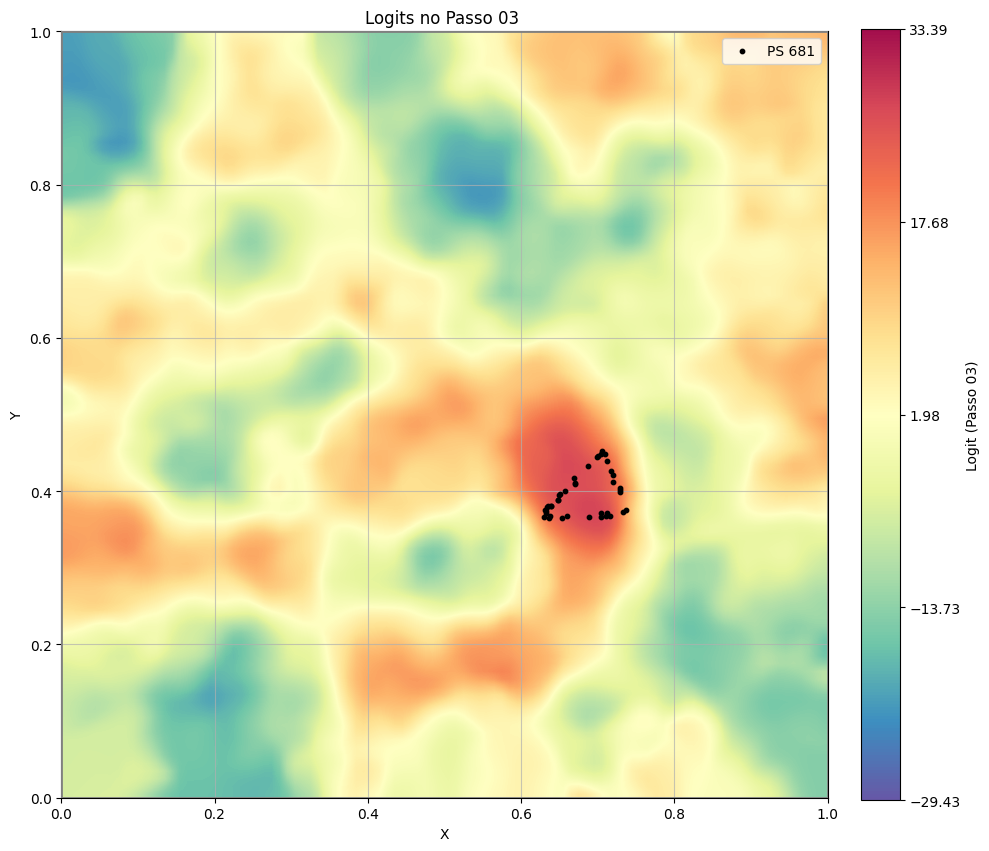

In [112]:
step_to_plot = 3
plot_next_id_logits_map_no_env(
    df_states=df,
    logits_df=distribs_logits,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="Spectral_r",
    smooth_sigma=0.015,
    grid_size=100,
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
)
plt.show()

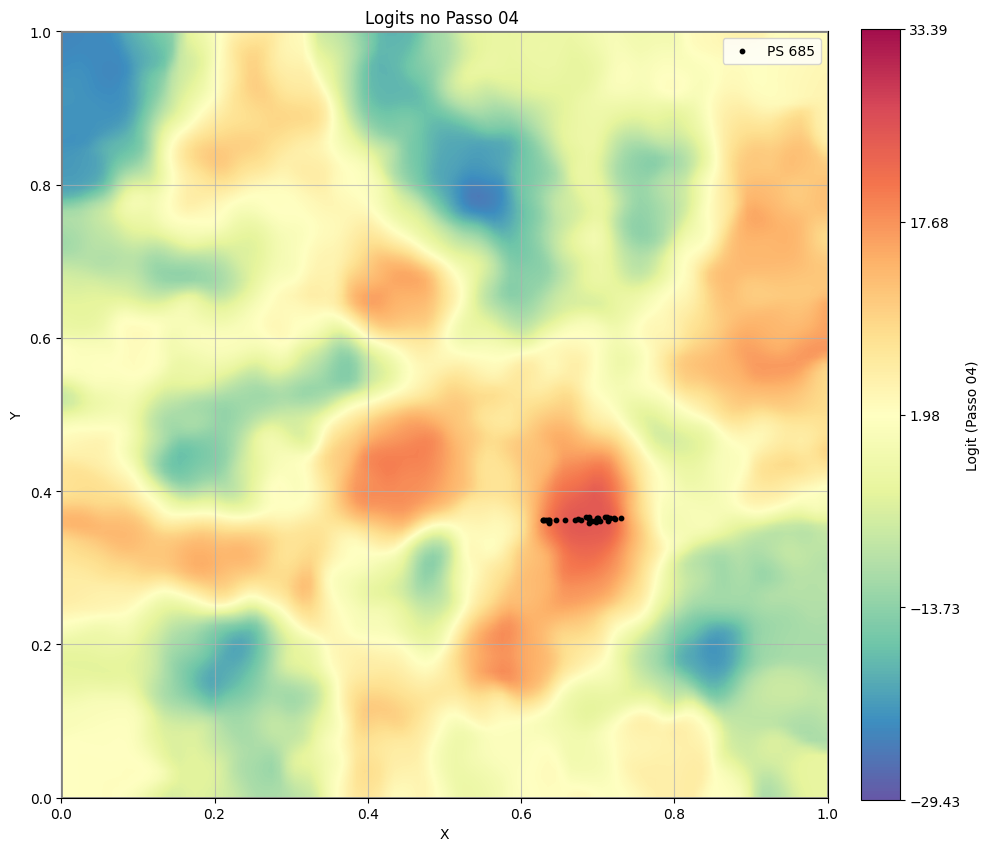

In [113]:
step_to_plot = 4
plot_next_id_logits_map_no_env(
    df_states=df,
    logits_df=distribs_logits,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="Spectral_r",
    smooth_sigma=0.015,
    grid_size=100,
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
)
plt.show()

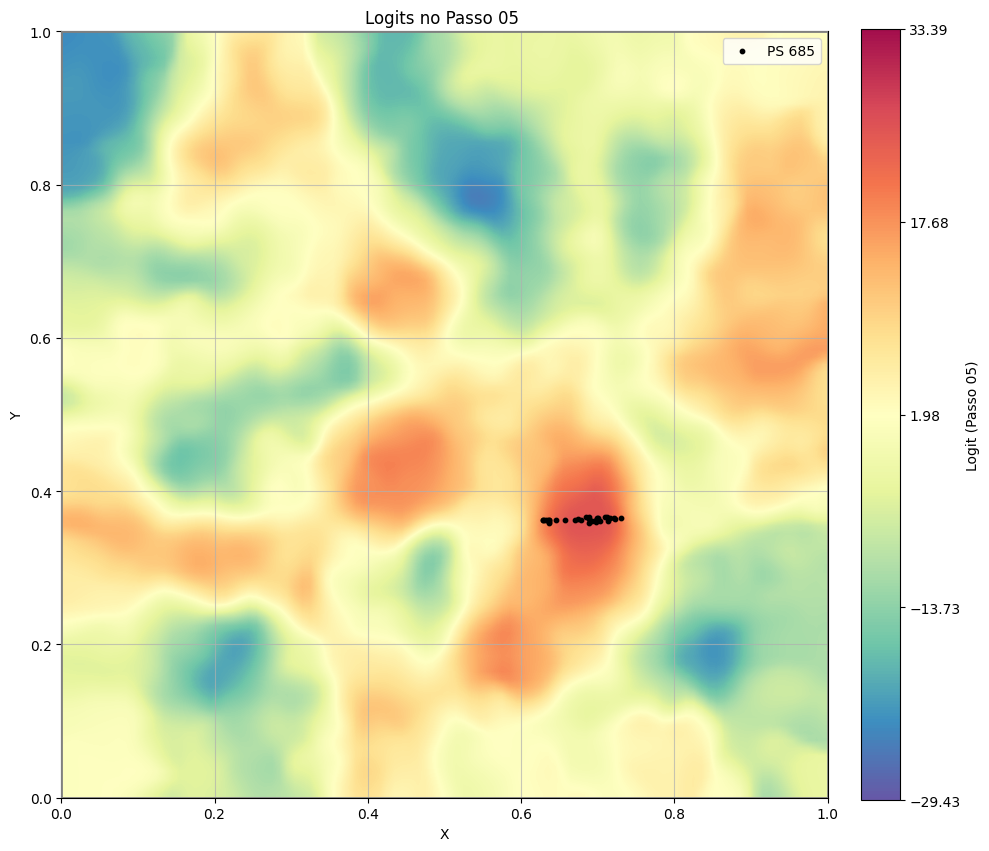

In [114]:
step_to_plot = 5
plot_next_id_logits_map_no_env(
    df_states=df,
    logits_df=distribs_logits,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="Spectral_r",
    smooth_sigma=0.015,
    grid_size=100,
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
)
plt.show()

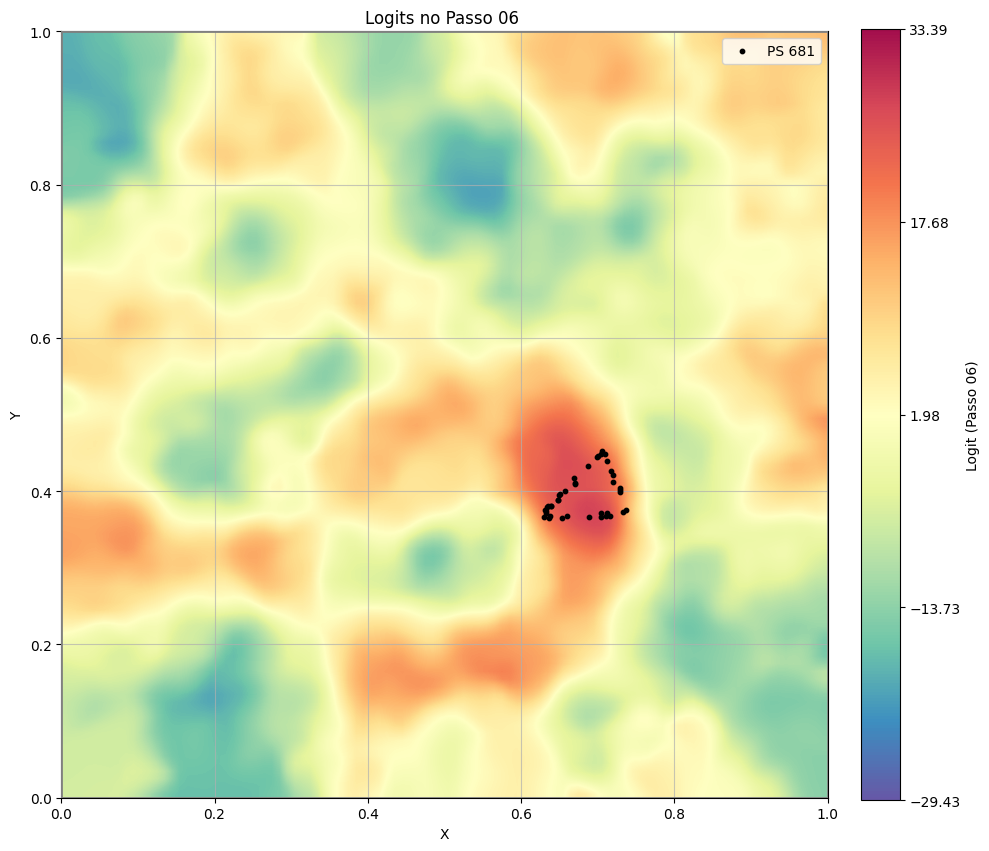

In [115]:
step_to_plot = 6
plot_next_id_logits_map_no_env(
    df_states=df,
    logits_df=distribs_logits,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="Spectral_r",
    smooth_sigma=0.015,
    grid_size=100,
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
)
plt.show()

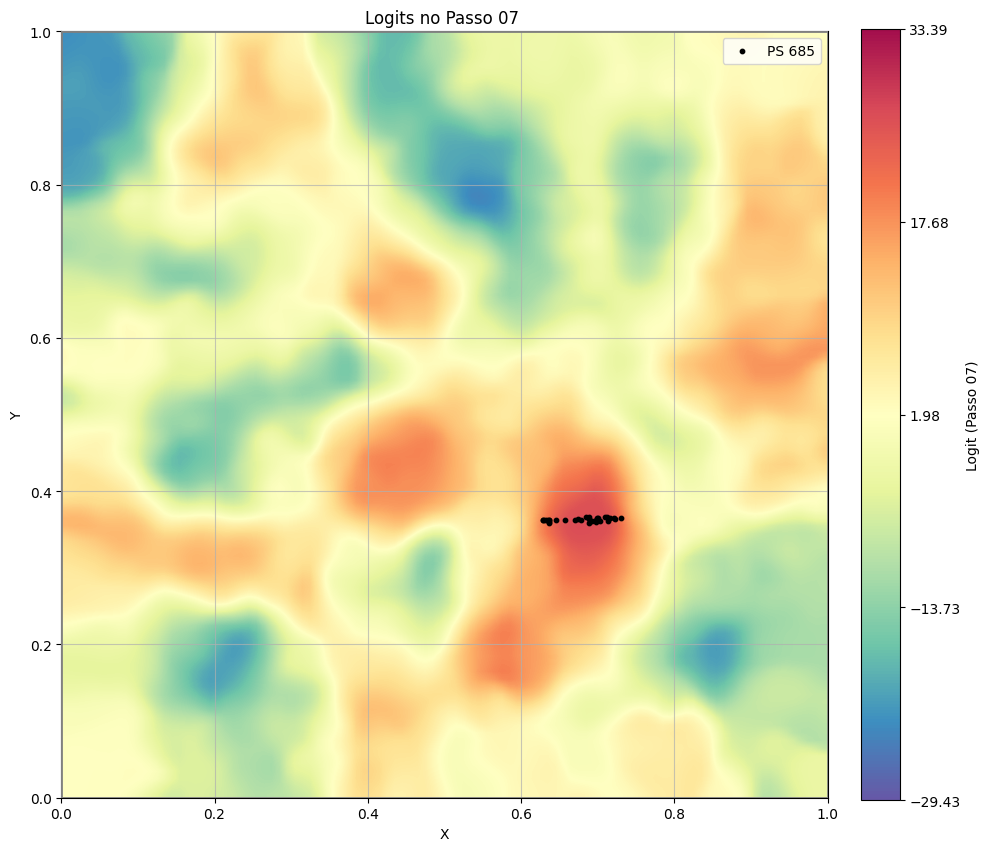

In [116]:
step_to_plot = 7
plot_next_id_logits_map_no_env(
    df_states=df,
    logits_df=distribs_logits,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="Spectral_r",
    smooth_sigma=0.015,
    grid_size=100,
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
)
plt.show()

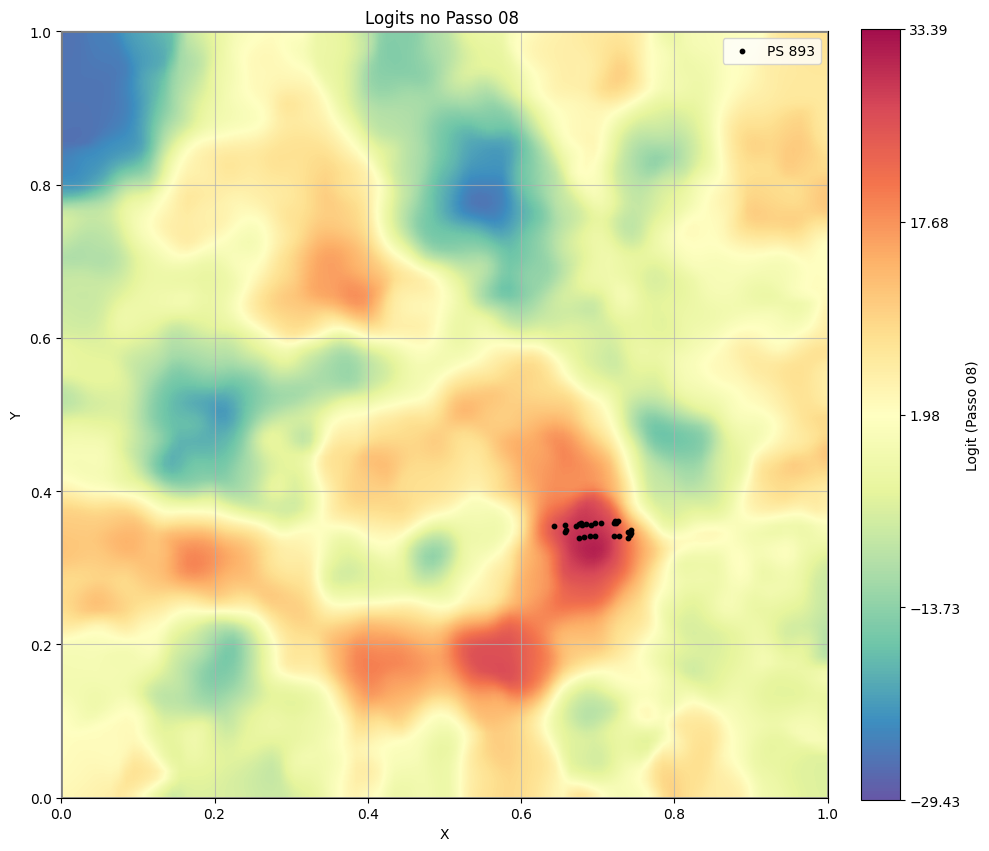

In [117]:
step_to_plot = 8
plot_next_id_logits_map_no_env(
    df_states=df,
    logits_df=distribs_logits,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="Spectral_r",
    smooth_sigma=0.015,
    grid_size=100,
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
)
plt.show()

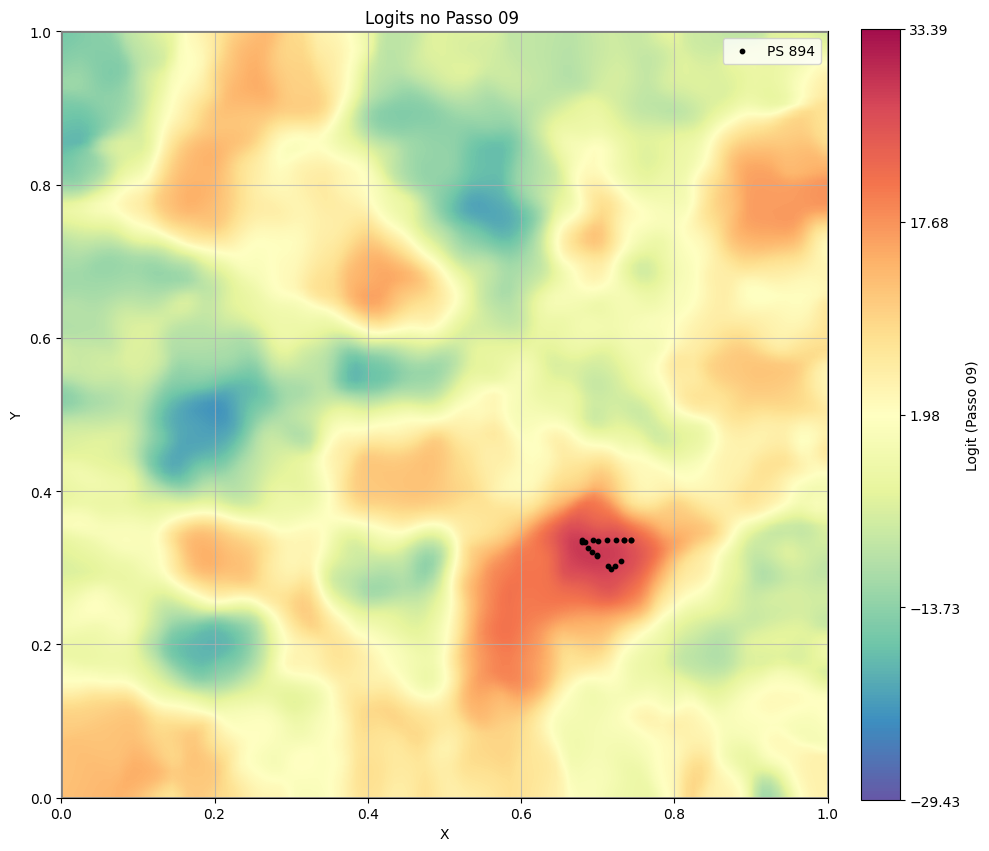

In [118]:
step_to_plot = 9
plot_next_id_logits_map_no_env(
    df_states=df,
    logits_df=distribs_logits,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="Spectral_r",
    smooth_sigma=0.015,
    grid_size=100,
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
)
plt.show()

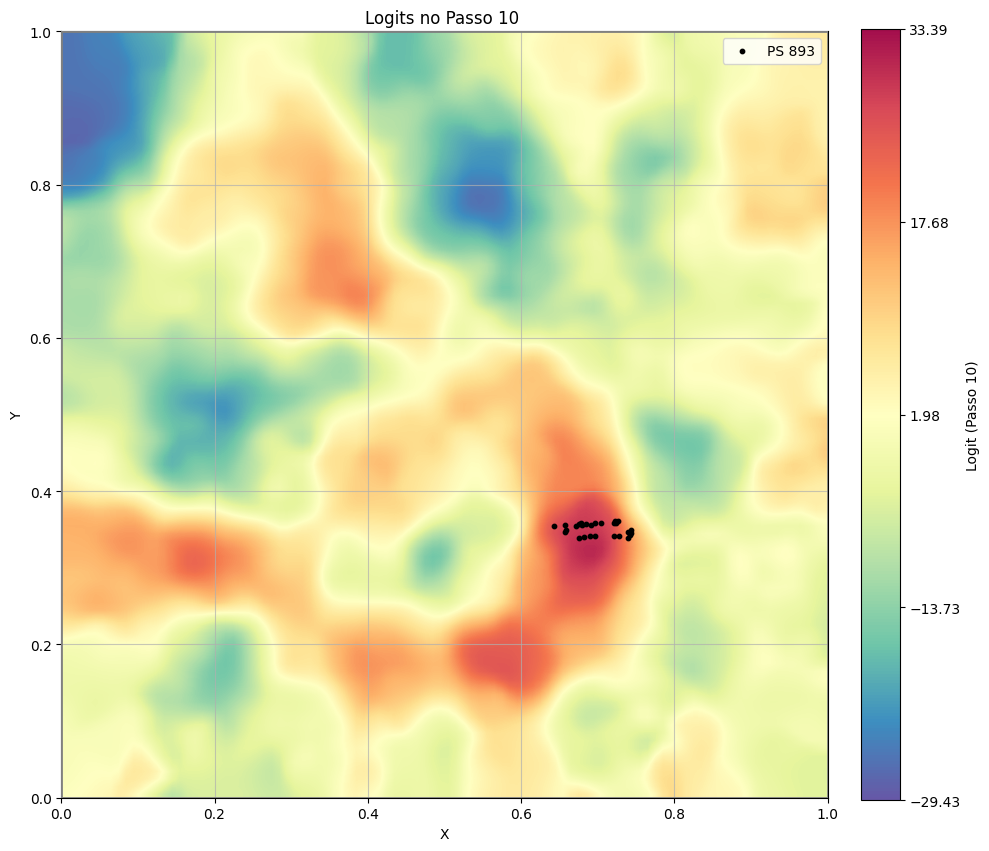

In [119]:
step_to_plot = 10
plot_next_id_logits_map_no_env(
    df_states=df,
    logits_df=distribs_logits,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="Spectral_r",
    smooth_sigma=0.015,
    grid_size=100,
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
)
plt.show()

## 507

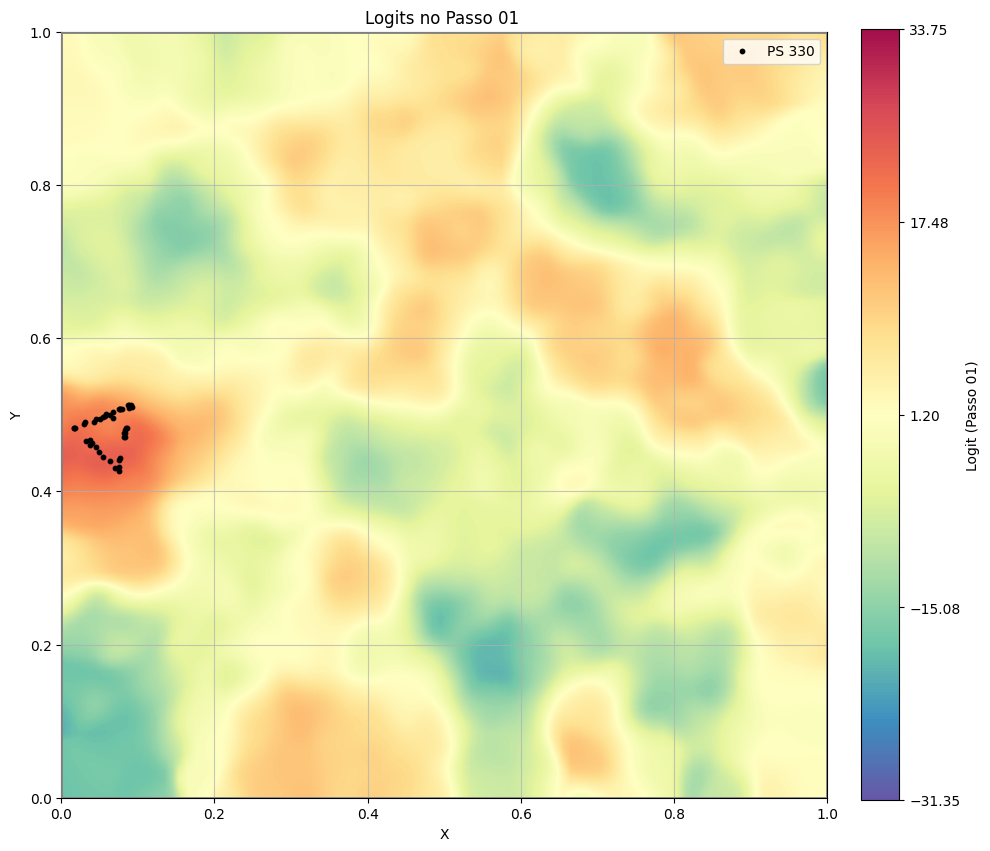

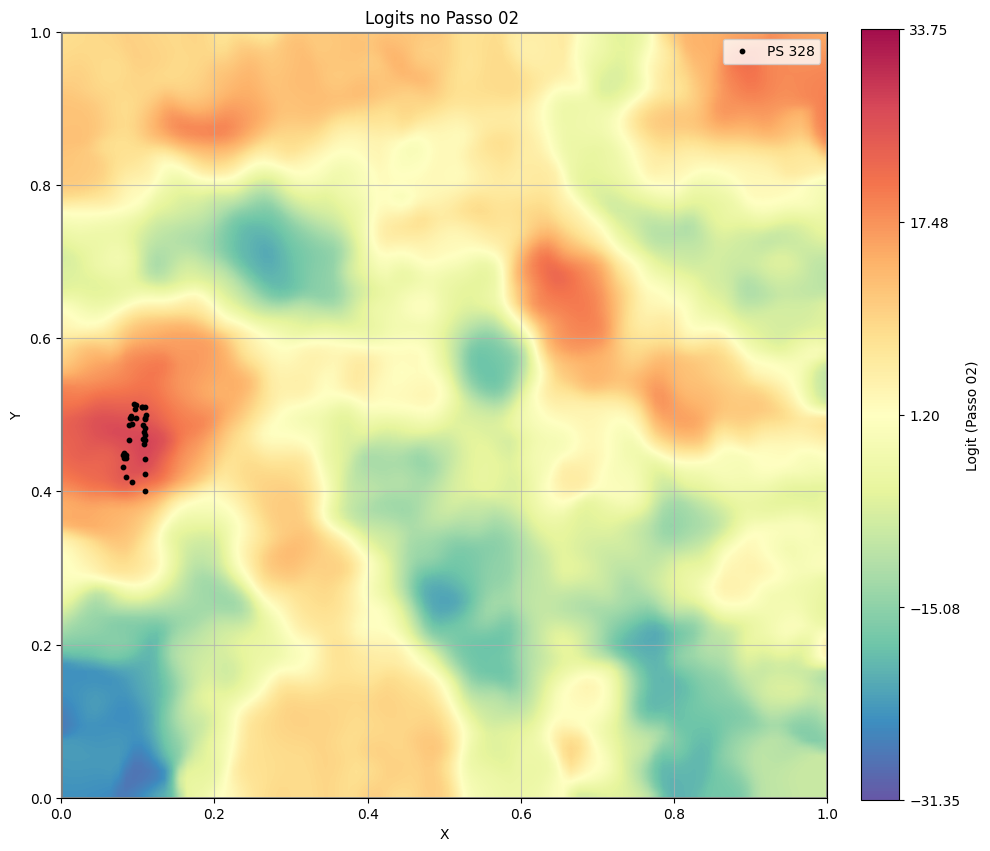

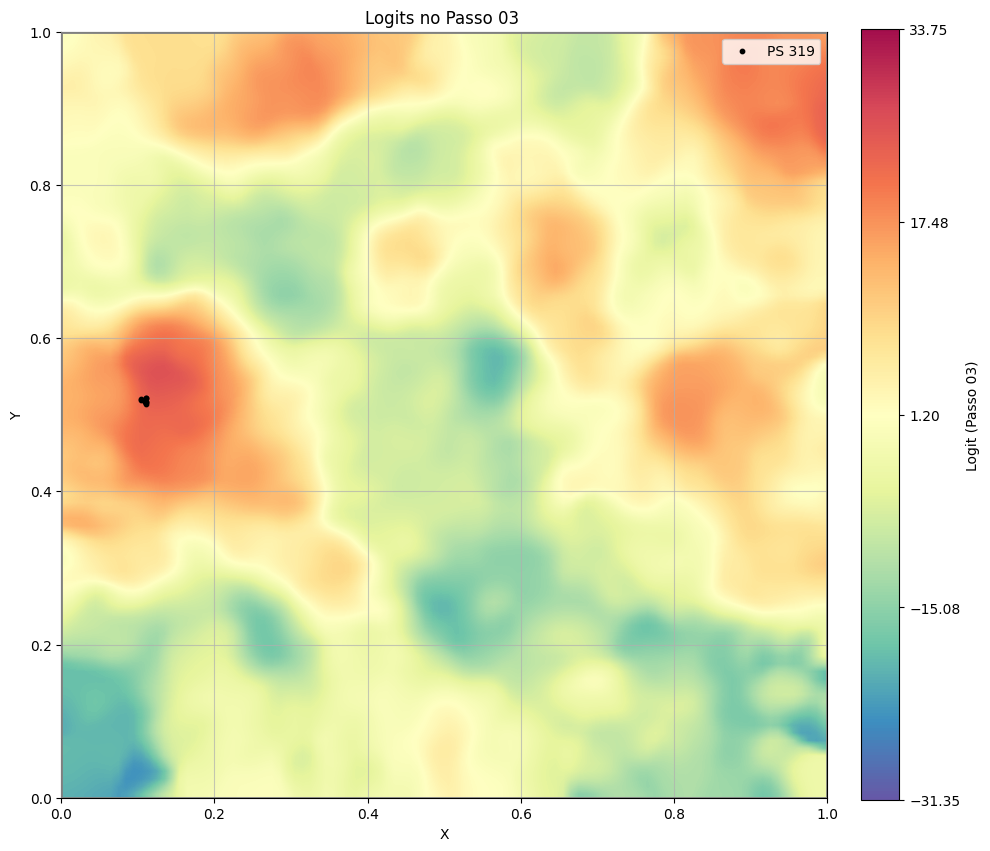

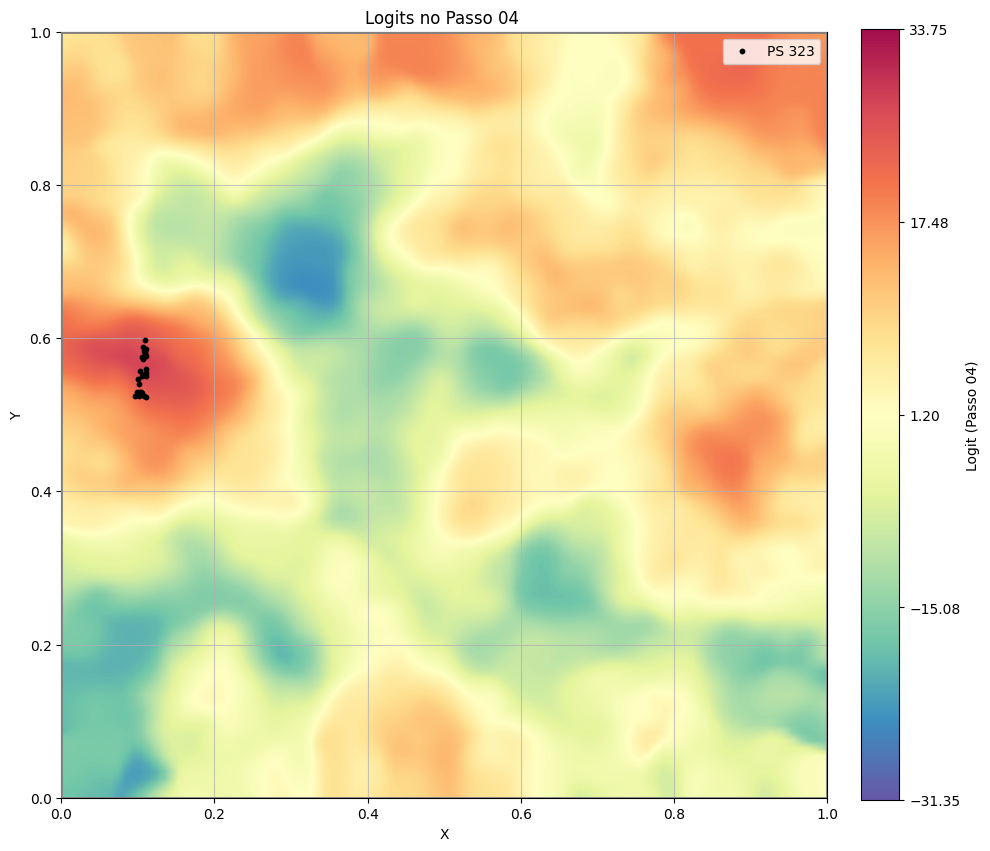

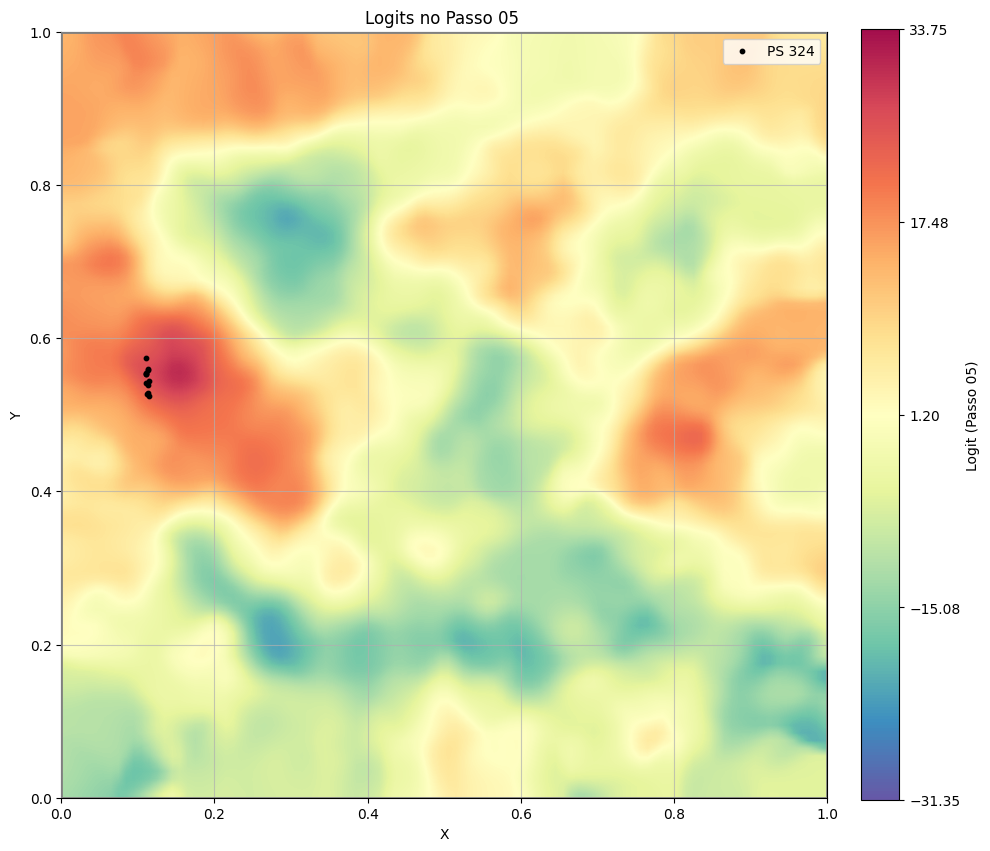

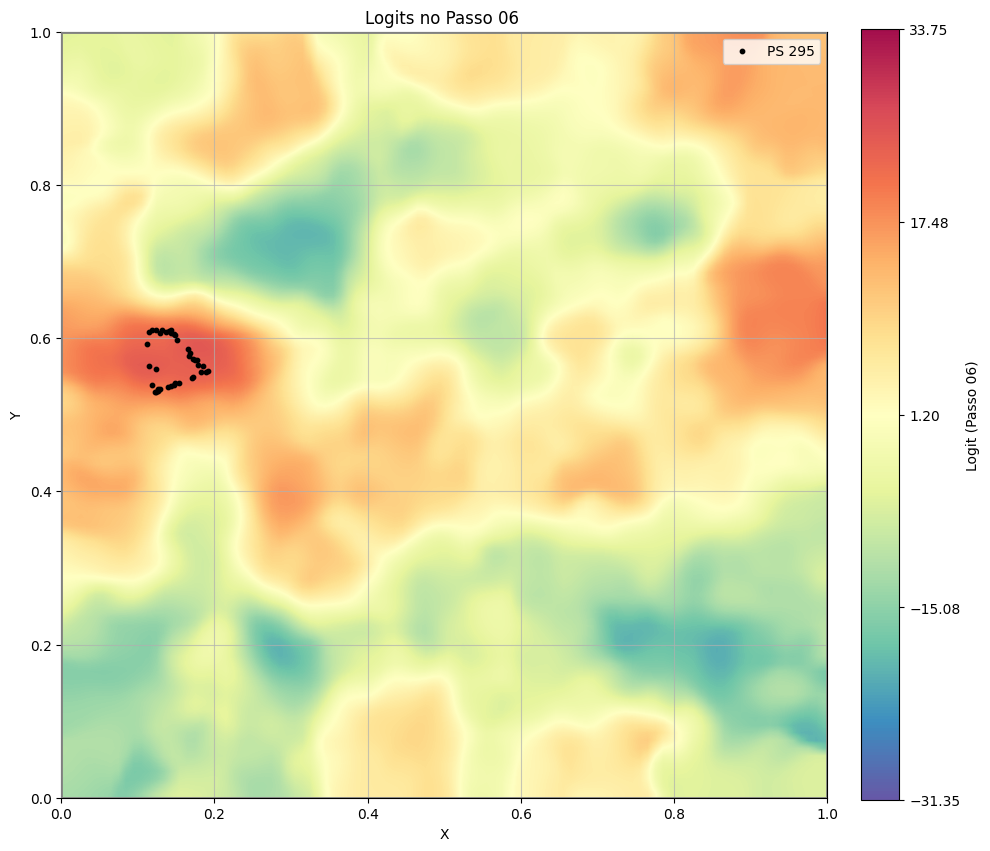

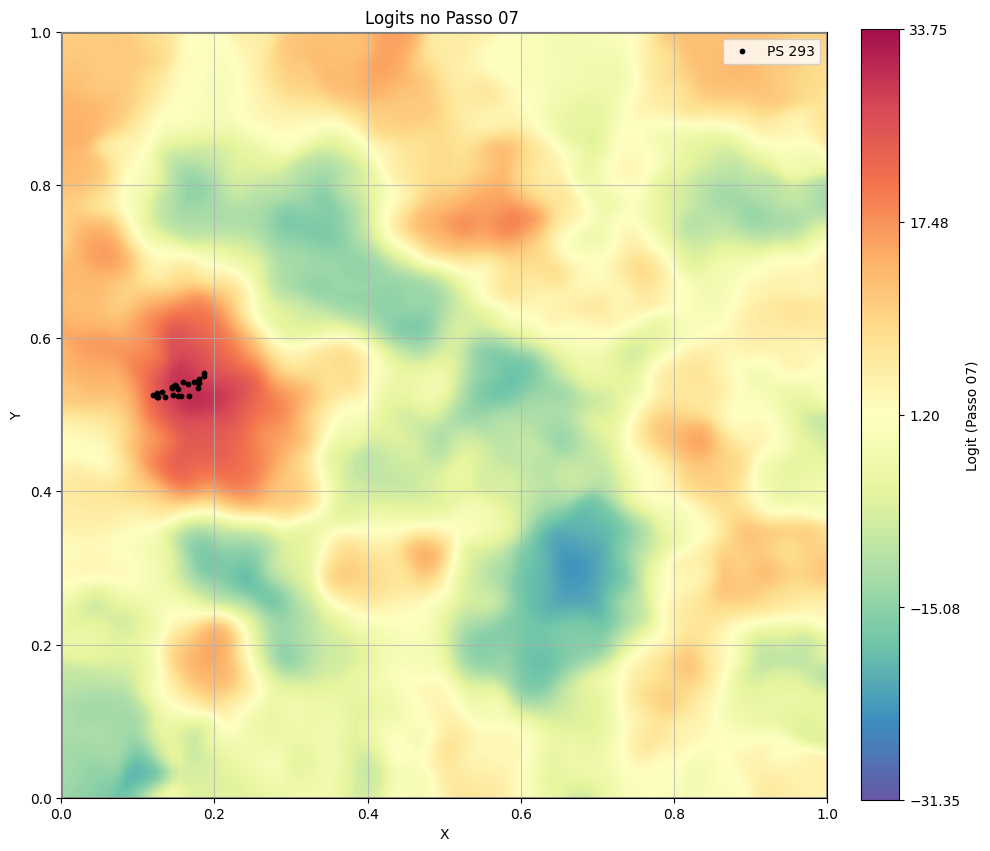

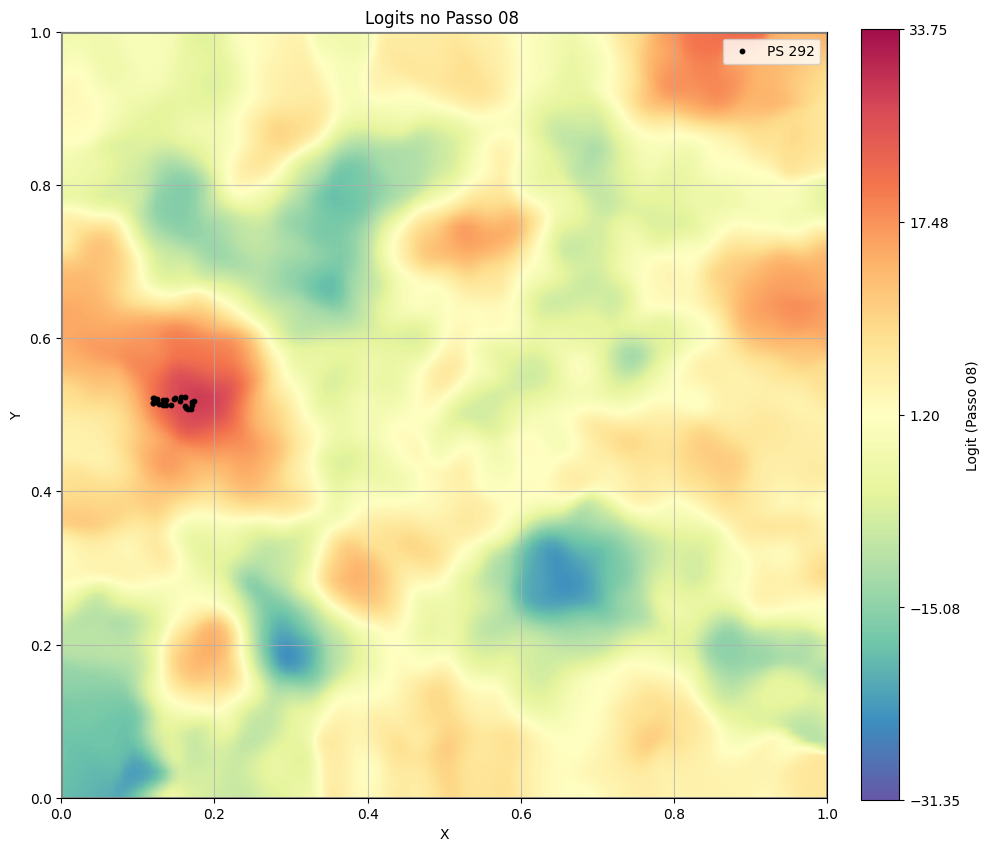

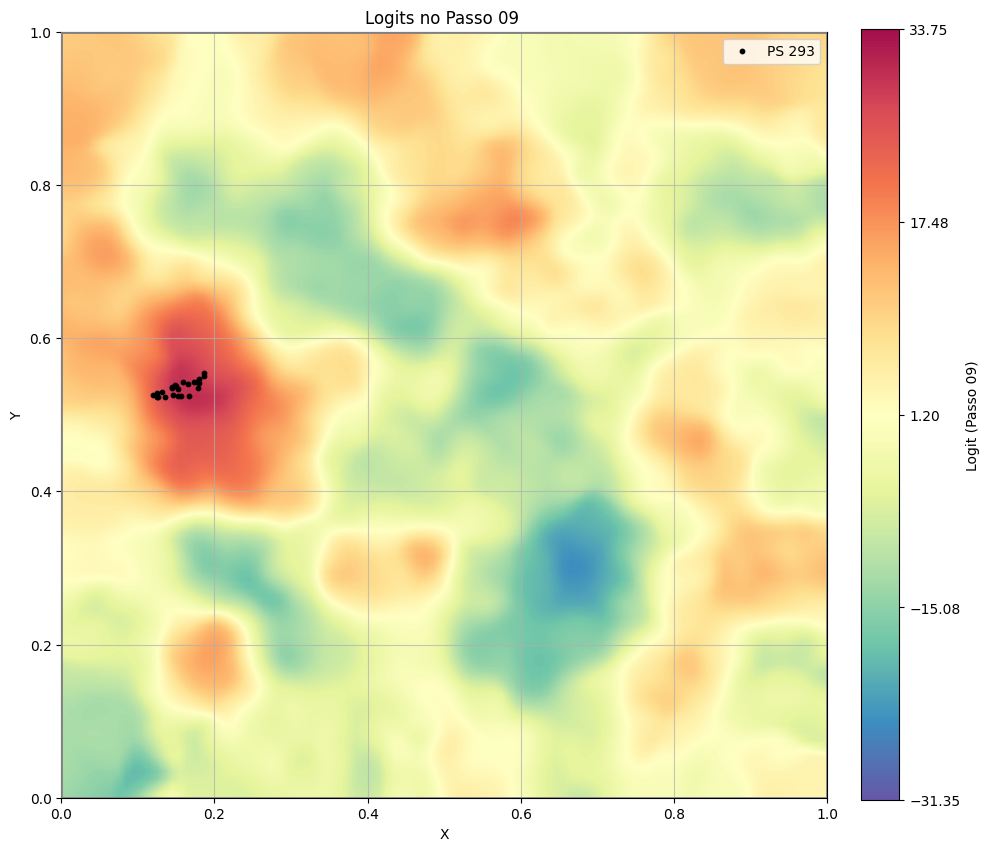

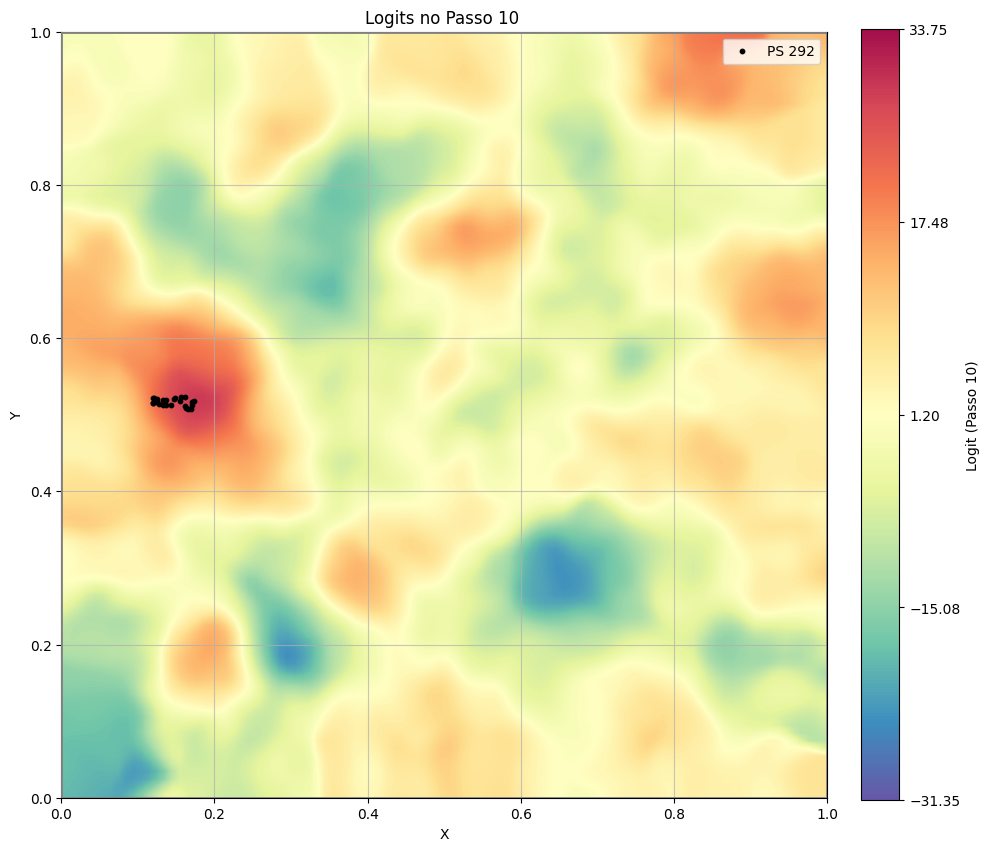

In [120]:
for i in range(1, 11):
    step_to_plot = i
    plot_next_id_logits_map_no_env(
        df_states=df,
        logits_df=distribs_logits507,
        current_id=generated_current_id(generation_507, step_to_plot),
        step=step_to_plot,
        cmap="Spectral_r",
        smooth_sigma=0.015,
        grid_size=100,
        logit_power=1.,
        current_color="k",
        current_size=10,
        current_alpha=1,
        show_current_label=False,
        center_colormap_at_zero=False,
    )
    plt.show()

# FIM

In [121]:
df.head()

,t,pos,distance_travelled,vel,rot_vel,head_direction,position_state,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
0,0.75,"[0.7, 0.89]",0.070249,"[-0.04648240511472945, -0.103916968250235]",-0.721635,"[-0.3147863504974622, -0.949162553802292]",XYCOAOWPMOWWNFTUVQEX,864,1.022175,973.0,1
1,0.80,"[0.699, 0.885]",0.075165,"[-0.02934323295077368, -0.09384195961539277]",2.351097,"[-0.3093471255142001, -0.9509491868318211]",XYCOAOWPMOWWNFTUKDZD,863,1.021119,968.0,1
2,0.90,"[0.698, 0.879]",0.081759,"[-0.014781629317759393, -0.04886508440626436]",-2.718846,"[-0.2694234454470962, -0.9630218102636179]",AOWPXYCOMOWWNFTUKDZD,67,0.080253,967.0,1
3,1.75,"[0.666, 0.84]",0.133414,"[-0.07658095338432869, -0.03239162333011025]",-3.094691,"[-0.7753741537587893, -0.6315021153431248]",AOWPMOWWXYCONFTUKDZD,42,0.048574,76.0,1
4,2.20,"[0.63, 0.825]",0.172443,"[-0.07400184852546676, -0.006027612039467556]",-2.263985,"[-0.9719050362633794, -0.23537332152535723]",AOWPMOWWXYCONFTUCEPV,41,0.047518,46.0,1


# Mapas adicionais por regioes discretas

Os plots anteriores com suavizacao gaussiana permanecem acima. Nesta secao, cada pixel da malha original de 0,001 recebe diretamente o valor do seu PS, sem media espacial. As linhas finas revelam as fronteiras entre estados; cinza marca os 110 PS da malha ausentes do treino.

In [122]:

# Malha espacial original: cada pixel recebe exatamente o ID do seu PS.
from matplotlib.colors import Normalize, TwoSlopeNorm
from matplotlib.patches import Patch

with open('ps_to_psid.pkl', 'rb') as fil:
    ps_to_psid_regioes = pickle.load(fil)
estados_treinados = set(df['position_state'].unique())
malha = pd.read_parquet('legacy/datasets/apd_full.gzip', columns=['X', 'Y', 'position_state'])
if not estados_treinados.issubset(set(malha['position_state'].unique())):
    raise ValueError('A malha nao contem todos os PS do treino')
ids_malha = malha['position_state'].map(ps_to_psid_regioes)
if ids_malha.isna().any():
    raise ValueError('PS da malha ausente em ps_to_psid.pkl')
x_malha = np.sort(malha['X'].unique())
y_malha = np.sort(malha['Y'].unique())
if len(malha) != len(x_malha) * len(y_malha):
    raise ValueError('Malha espacial incompleta')
if not (np.allclose(malha['X'].to_numpy().reshape(len(y_malha), len(x_malha)), x_malha[None, :])
        and np.allclose(malha['Y'].to_numpy().reshape(len(y_malha), len(x_malha)), y_malha[:, None])):
    raise ValueError('Ordem espacial inesperada em legacy/datasets/apd_full.gzip')
ps_grid = ids_malha.to_numpy(dtype=np.int16).reshape(len(y_malha), len(x_malha))
train_id_set = {int(ps_to_psid_regioes[state]) for state in estados_treinados}
if train_id_set != set(df['position_state_id'].unique()):
    raise ValueError('IDs da analise diferem dos IDs do treino')
untrained_id_set = set(np.unique(ps_grid)) - train_id_set
dx = float(np.median(np.diff(x_malha)))
dy = float(np.median(np.diff(y_malha)))
ps_extent = (x_malha[0] - dx / 2, x_malha[-1] + dx / 2,
             y_malha[0] - dy / 2, y_malha[-1] + dy / 2)
ps_edges = np.zeros_like(ps_grid, dtype=bool)
ps_edges[:, 1:] |= ps_grid[:, 1:] != ps_grid[:, :-1]
ps_edges[1:, :] |= ps_grid[1:, :] != ps_grid[:-1, :]
ps_edge_rgba = np.zeros((*ps_grid.shape, 4), dtype=np.float32)
ps_edge_rgba[ps_edges, 3] = 0.20
print(f'Malha: {ps_grid.shape}; PS treinados: {len(train_id_set)}; '
      f'PS sem treino (cinza): {len(untrained_id_set)}')
del malha, ids_malha

def _xy_discreto(value):
    if isinstance(value, str):
        value = ast.literal_eval(value)
    if isinstance(value, (list, tuple, np.ndarray)) and len(value) == 2:
        return float(value[0]), float(value[1])
    raise ValueError(f'Posicao invalida: {value}')

def _step_discreto(step):
    return step if isinstance(step, str) else f'Passo {step:02d}'

def _field_discreto(values):
    values = pd.Series(values, dtype=float)
    values.index = values.index.astype(int)
    lut = np.full(int(ps_grid.max()) + 1, np.nan, dtype=np.float32)
    indices = values.index.to_numpy()
    valid = (indices >= 0) & (indices < len(lut))
    lut[indices[valid]] = values.to_numpy(dtype=np.float32)[valid]
    lut[list(untrained_id_set)] = np.nan
    return np.ma.masked_invalid(lut[ps_grid])

def _plot_regioes(
    df_states, values, current_id, *, title, colorbar_label, norm, cmap,
    pos_col='pos', id_col='position_state_id', xlim=(0., 1.), ylim=(0., 1.),
    figsize=(10, 10), current_color='lightgray', current_alpha=0.95,
    current_size=20, current_edgecolor='black', current_linewidth=0.8,
    show_current_label=True, show_colorbar=True, colorbar_ticks=None,
    env_linewidth=2., env_color='gray', grid=True, grid_alpha=0.7,
    show_boundaries=True, show=True
):
    current = df_states.loc[df_states[id_col] == current_id, pos_col]
    if current.empty:
        raise ValueError(f'PS {current_id} nao encontrado na trajetoria')
    field = _field_discreto(values)
    colormap = plt.get_cmap(cmap).copy()
    colormap.set_bad('#d9d9d9')
    fig, ax = plt.subplots(figsize=figsize, dpi=150)
    image = ax.imshow(field, extent=ps_extent, origin='lower', cmap=colormap,
                      norm=norm, interpolation='nearest', resample=False, zorder=1)
    if show_boundaries:
        ax.imshow(ps_edge_rgba, extent=ps_extent, origin='lower',
                  interpolation='nearest', resample=False, zorder=2)
    xy = np.asarray([_xy_discreto(v) for v in current], dtype=float)
    ax.scatter(xy[:, 0], xy[:, 1], s=current_size, color=current_color,
               alpha=current_alpha, edgecolors=current_edgecolor,
               linewidths=current_linewidth, zorder=3, label=f'PS {current_id}')
    if show_current_label:
        ax.text(*xy.mean(axis=0), str(current_id), ha='center', va='center', zorder=4)
    xmin, xmax = xlim
    ymin, ymax = ylim
    ax.plot([xmin, xmax, xmax, xmin, xmin], [ymin, ymin, ymax, ymax, ymin],
            color=env_color, linewidth=env_linewidth, zorder=5)
    ax.set(xlim=xlim, ylim=ylim, xlabel='X', ylabel='Y', title='Regioes discretas: ' + title)
    ax.set_aspect('equal')
    if grid:
        ax.grid(True, alpha=grid_alpha)
    ax.legend(handles=[*ax.get_legend_handles_labels()[0],
                       Patch(facecolor='#d9d9d9', label='PS sem treino')],
              loc='upper right', frameon=True)
    if show_colorbar:
        bar = fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
        bar.set_label(colorbar_label)
        if colorbar_ticks is not None:
            bar.set_ticks(colorbar_ticks)
    fig.tight_layout()
    if show:
        plt.show()
    return fig, ax

def _similaridade_por_id(matrix, current_id, offset, use_column, power, clip):
    matrix = matrix.copy()
    matrix.index = matrix.index.astype(int)
    matrix.columns = matrix.columns.astype(int)
    key = int(current_id) - offset
    values = matrix[key].copy() if use_column else matrix.loc[key].copy()
    values.index = values.index.astype(int) + offset
    if clip is not None:
        values = values.clip(*clip)
    if power != 1:
        values = np.sign(values) * np.abs(values) ** power
    return values

def plot_cosine_similarity_map_discreto(
    df_states, cossim_df, current_id, *, similarity_id_offset=0,
    use_column_instead_of_row=False, sim_power=1., clip_similarity=None,
    title_tag='', cmap='coolwarm', **style
):
    values = _similaridade_por_id(cossim_df, current_id, similarity_id_offset,
                                  use_column_instead_of_row, sim_power, clip_similarity)
    return _plot_regioes(
        df_states, values, current_id,
        title=f'Mapa de Similaridade PS {current_id} {title_tag}',
        colorbar_label='Similaridade cosseno',
        norm=TwoSlopeNorm(vmin=-1., vcenter=0., vmax=1.),
        cmap=cmap, **style)

def plot_representation_similarity_map_discreto(
    df_states, sim_df, current_id, *, repr_name='Q', similarity_id_offset=0,
    use_column_instead_of_row=False, sim_power=1., clip_similarity=None,
    title_tag='', cmap='coolwarm', **style
):
    values = _similaridade_por_id(sim_df, current_id, similarity_id_offset,
                                  use_column_instead_of_row, sim_power, clip_similarity)
    return _plot_regioes(
        df_states, values, current_id,
        title=f'{repr_name}-space cosine similarity map for PS {current_id} {title_tag}',
        colorbar_label=f'Cosine similarity in {repr_name}-space',
        norm=TwoSlopeNorm(vmin=-1., vcenter=0., vmax=1.),
        cmap=cmap, **style)

def plot_next_id_probability_map_discreto(
    df_states, probs_df, current_id, *, step='Passo 01', prob_power=1.,
    include_current_in_field=True, title_tag='', cmap='viridis',
    colorbar_ticks=(0., 0.25, 0.5, 0.75, 1.), **style
):
    column = _step_discreto(step)
    values = probs_df[column].copy()
    values.index = values.index.astype(int)
    if prob_power != 1:
        values = values.clip(lower=0) ** prob_power
    if not include_current_in_field:
        values.loc[int(current_id)] = np.nan
    visible_ids = [state_id for state_id in values.index if state_id in train_id_set]
    peak = float(values.loc[visible_ids].max()) if visible_ids else 0.
    if np.isfinite(peak) and peak > 0:
        values = values / peak
    return _plot_regioes(
        df_states, values, current_id,
        title=f'Probabilidade no {column} {title_tag}',
        colorbar_label=f'Probabilidade relativa ao maximo ({column})',
        norm=Normalize(vmin=0., vmax=1.), cmap=cmap,
        colorbar_ticks=colorbar_ticks, **style)

def plot_next_id_logits_map_discreto(
    df_states, logits_df, current_id, *, step='Passo 01', logits_id_col=None,
    logit_power=1., preserve_sign=True, include_current_in_field=True,
    center_colormap_at_zero=True, colorbar_num_ticks=5,
    title_tag='', cmap='coolwarm', **style
):
    logits = logits_df.set_index(logits_id_col) if logits_id_col else logits_df
    column = _step_discreto(step)
    values = logits[column].copy()
    values.index = values.index.astype(int)
    if logit_power != 1:
        values = (np.sign(values) * np.abs(values) ** logit_power
                  if preserve_sign else values ** logit_power)
    if not include_current_in_field:
        values.loc[int(current_id)] = np.nan
    finite = logits.to_numpy(dtype=float)
    finite = finite[np.isfinite(finite)]
    low, high = (float(finite.min()), float(finite.max())) if finite.size else (-1., 1.)
    if low == high:
        low -= 1e-6
        high += 1e-6
    if center_colormap_at_zero and low < 0 < high:
        limit = max(abs(low), abs(high))
        norm = TwoSlopeNorm(vmin=-limit, vcenter=0., vmax=limit)
        ticks = np.linspace(-limit, limit, colorbar_num_ticks)
    else:
        norm = Normalize(vmin=low, vmax=high)
        ticks = np.linspace(low, high, colorbar_num_ticks)
    return _plot_regioes(
        df_states, values, current_id,
        title=f'Logits no {column} {title_tag}',
        colorbar_label=f'Logit ({column})', norm=norm, cmap=cmap,
        colorbar_ticks=ticks, **style)


Malha: (1001, 1001); PS treinados: 947; PS sem treino (cinza): 110


## Similaridade cosseno dos embeddings por região discreta

Cada mapa usa a similaridade cosseno entre o embedding do PS de referência e os embeddings dos demais PSs. Compare o PS 200 no pré-treino (primeiro gráfico desta seção) e no pós-treino (após os gráficos da época 200). As duas imagens usam o mesmo `coolwarm`, escala fixa de −1 a 1 e a mesma malha de PS sem suavização gaussiana. Os mapas gaussianos anteriores permanecem nas células acima.

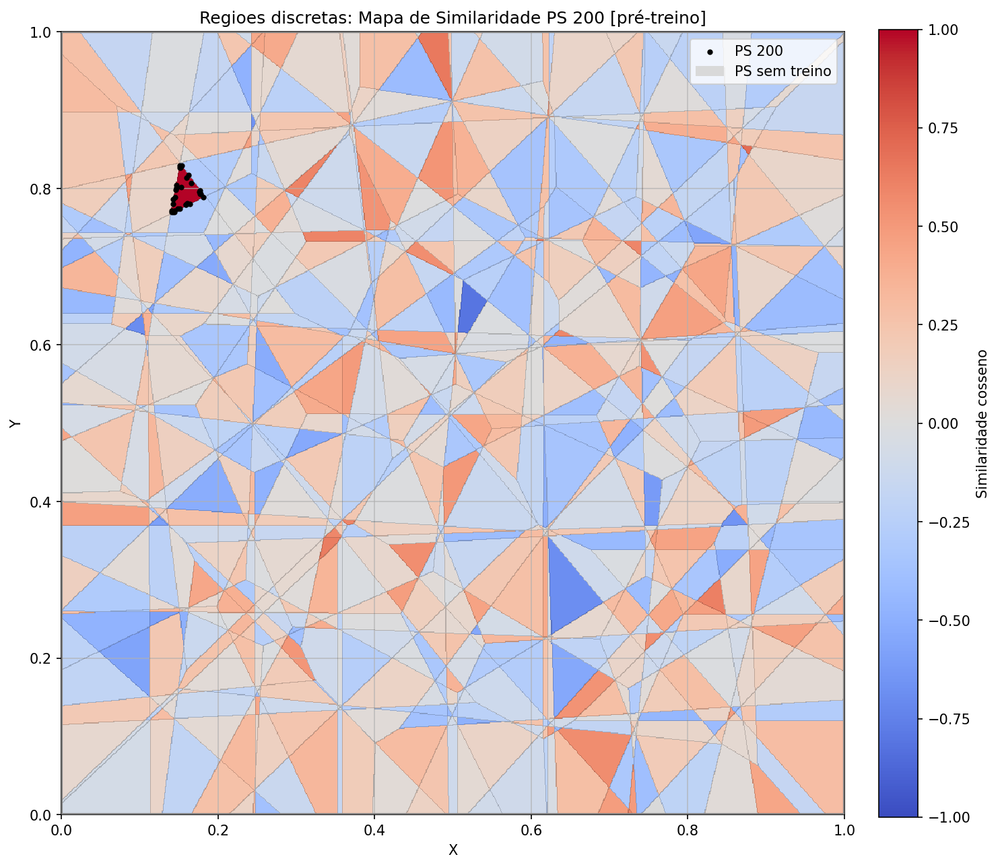

In [123]:
plot_cosine_similarity_map_discreto(
    df_states=df,
    cossim_df=coss_pre_train,
    current_id=200,
    similarity_id_offset=0,
    cmap="coolwarm",
    sim_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag = '[pré-treino]'
)
plt.show()

Referencia: celula original 79

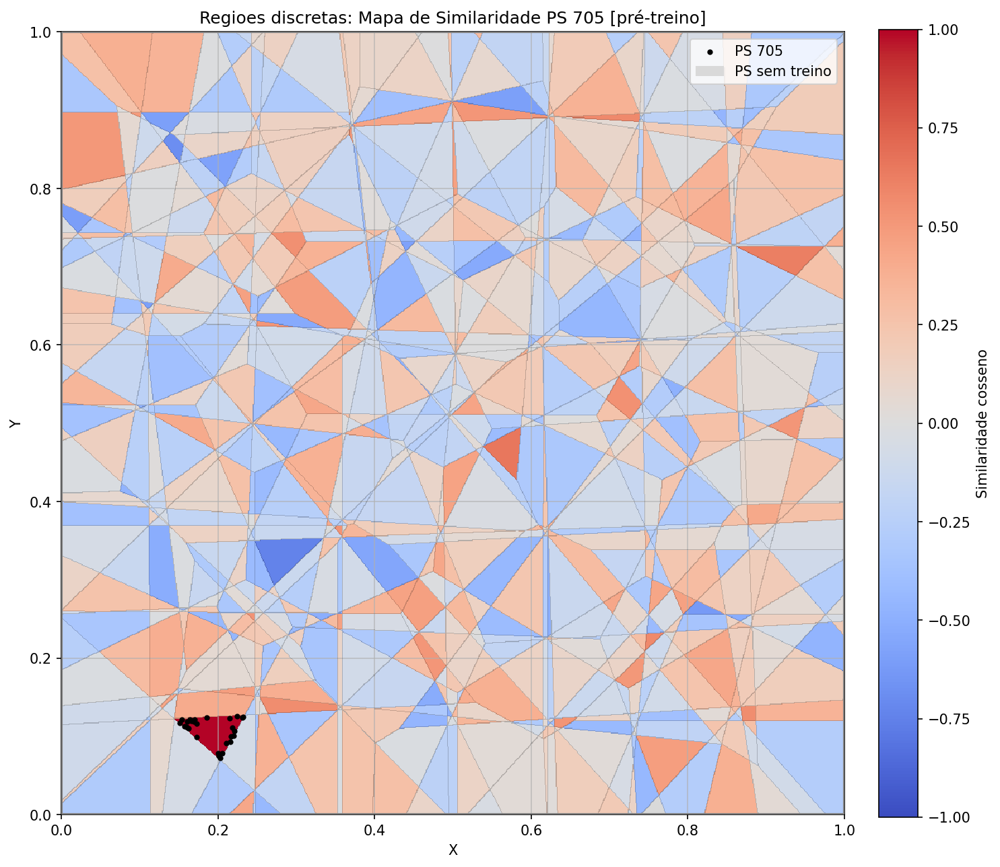

In [124]:
plot_cosine_similarity_map_discreto(
    df_states=df,
    cossim_df=coss_pre_train,
    current_id=705,
    similarity_id_offset=0,
    cmap="coolwarm",
    sim_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag = '[pré-treino]'
)
plt.show()

Referencia: celula original 80

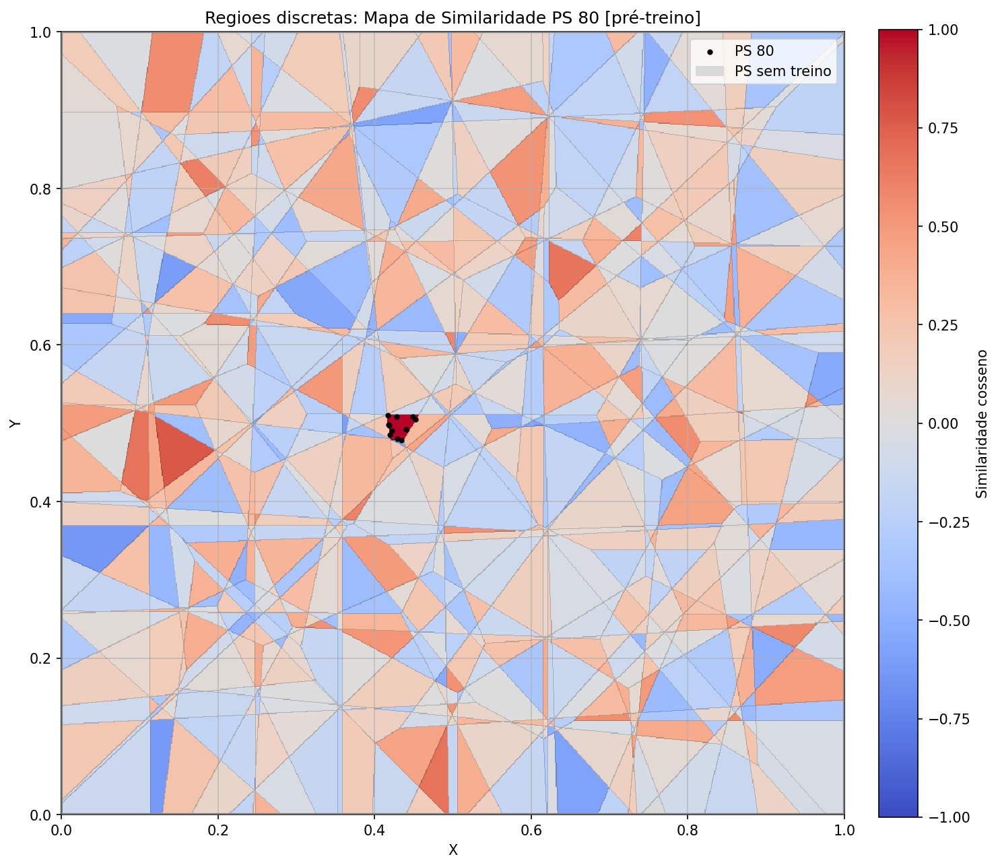

In [125]:
plot_cosine_similarity_map_discreto(
    df_states=df,
    cossim_df=coss_pre_train,
    current_id=80,
    similarity_id_offset=0,
    cmap="coolwarm",
    sim_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag = '[pré-treino]'
)
plt.show()

Referencia: celula original 81

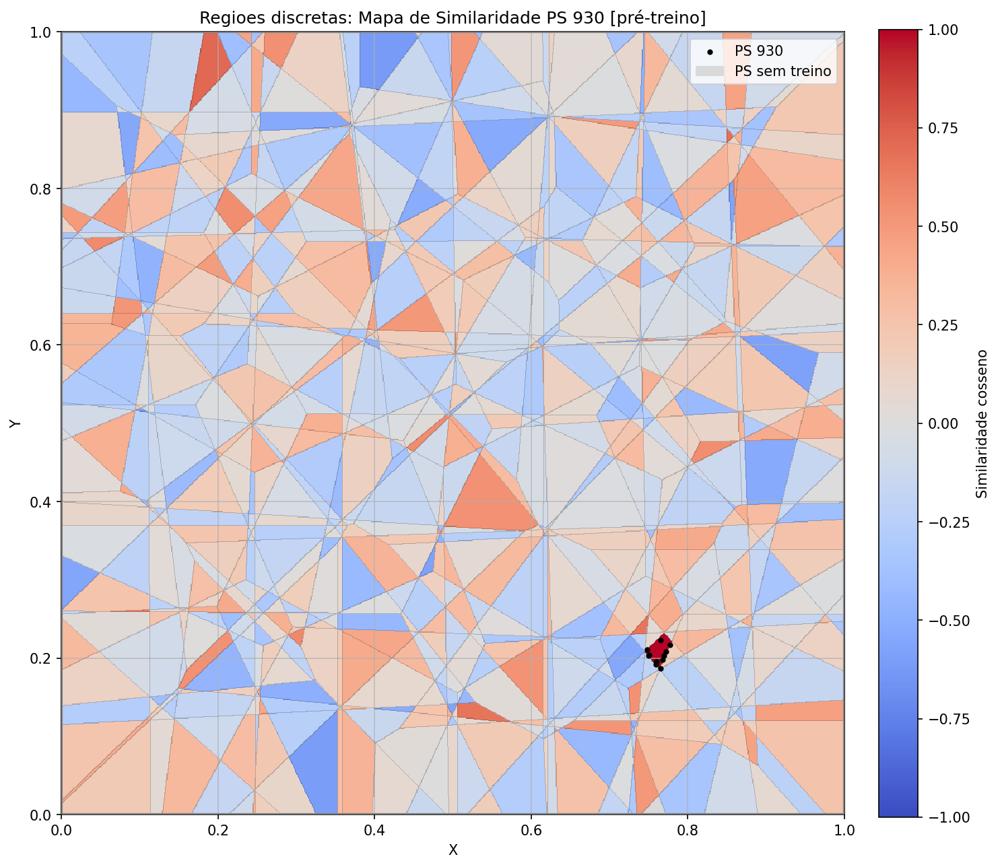

In [126]:
plot_cosine_similarity_map_discreto(
    df_states=df,
    cossim_df=coss_pre_train,
    current_id=930,
    similarity_id_offset=0,
    cmap="coolwarm",
    sim_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag = '[pré-treino]'
)
plt.show()

Referencia: celula original 83

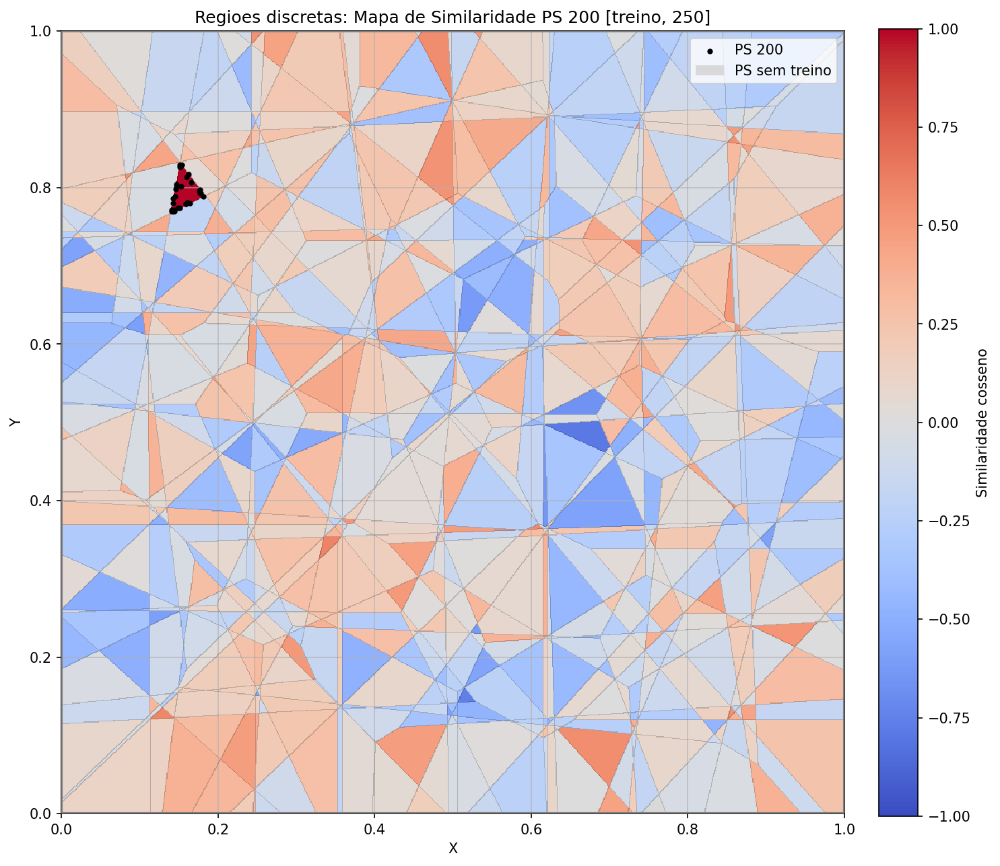

In [127]:
plot_cosine_similarity_map_discreto(
    df_states=df,
    cossim_df=coss_train_250,
    current_id=200,
    similarity_id_offset=0,
    cmap="coolwarm",
    sim_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag = '[treino, 250]'
)
plt.show()

Referencia: celula original 84

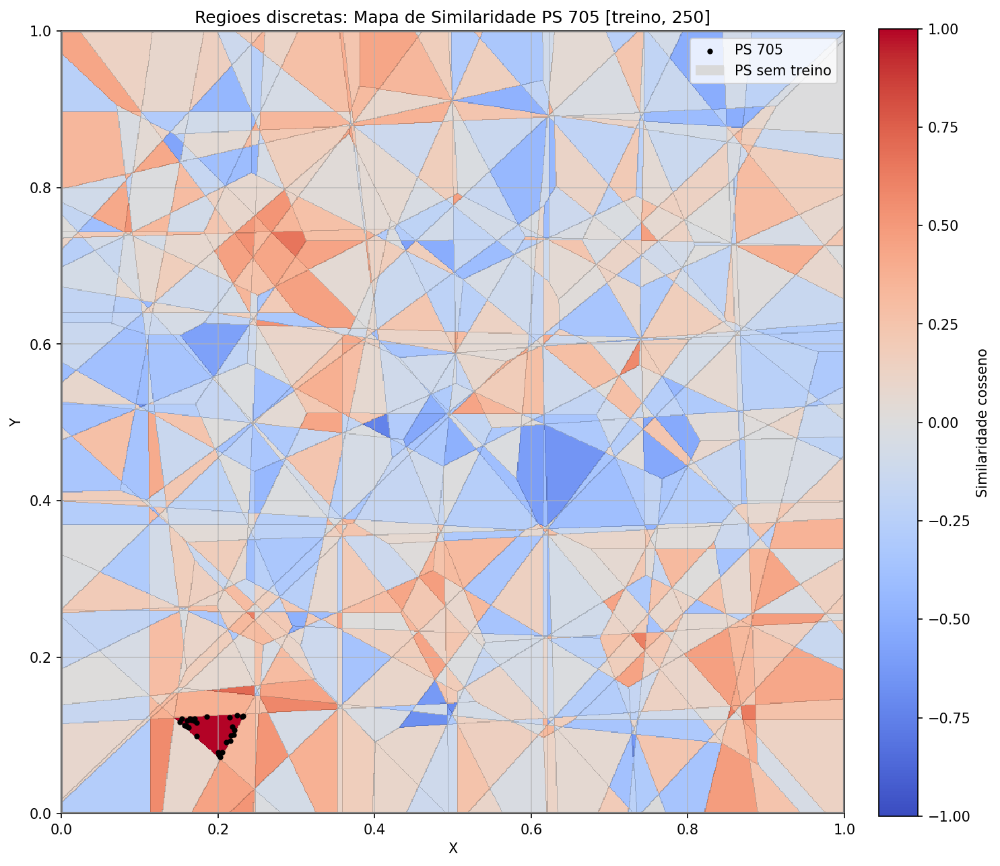

In [128]:
plot_cosine_similarity_map_discreto(
    df_states=df,
    cossim_df=coss_train_250,
    current_id=705,
    similarity_id_offset=0,
    cmap="coolwarm",
    sim_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag = '[treino, 250]'
)
plt.show()

Referencia: celula original 85

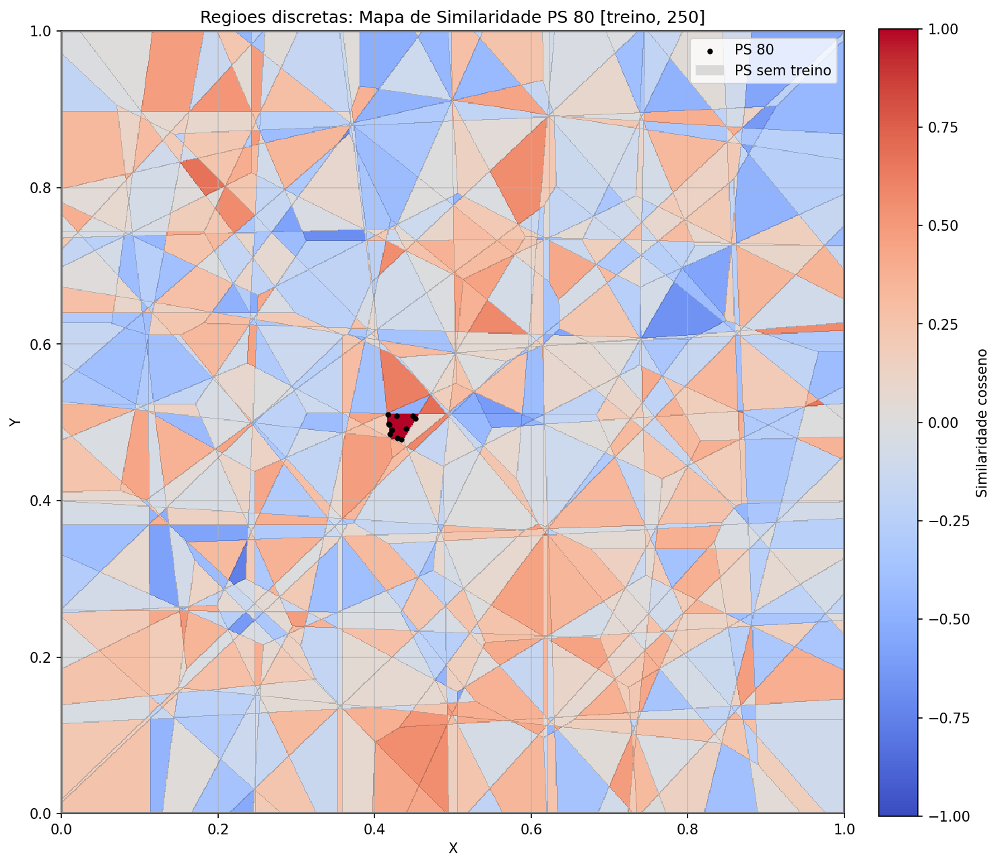

In [129]:
plot_cosine_similarity_map_discreto(
    df_states=df,
    cossim_df=coss_train_250,
    current_id=80,
    similarity_id_offset=0,
    cmap="coolwarm",
    sim_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag = '[treino, 250]'
)
plt.show()

Referencia: celula original 86

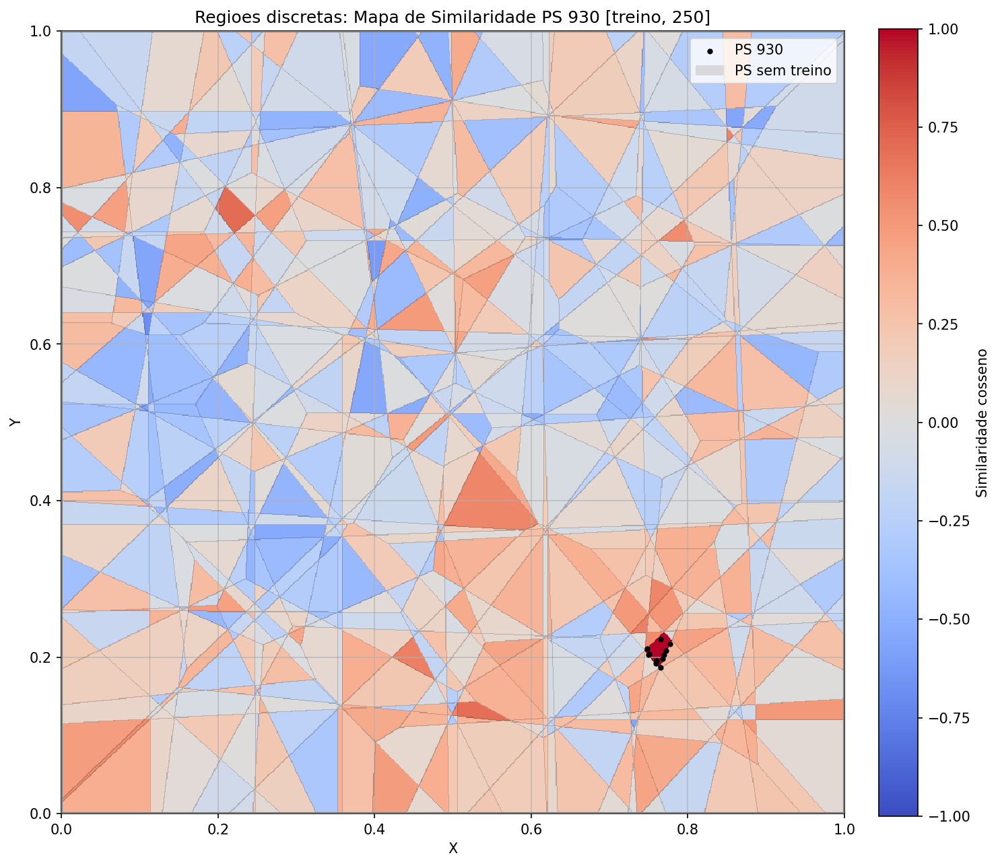

In [130]:
plot_cosine_similarity_map_discreto(
    df_states=df,
    cossim_df=coss_train_250,
    current_id=930,
    similarity_id_offset=0,
    cmap="coolwarm",
    sim_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag = '[treino, 250]'
)
plt.show()

Referencia: celula original 90

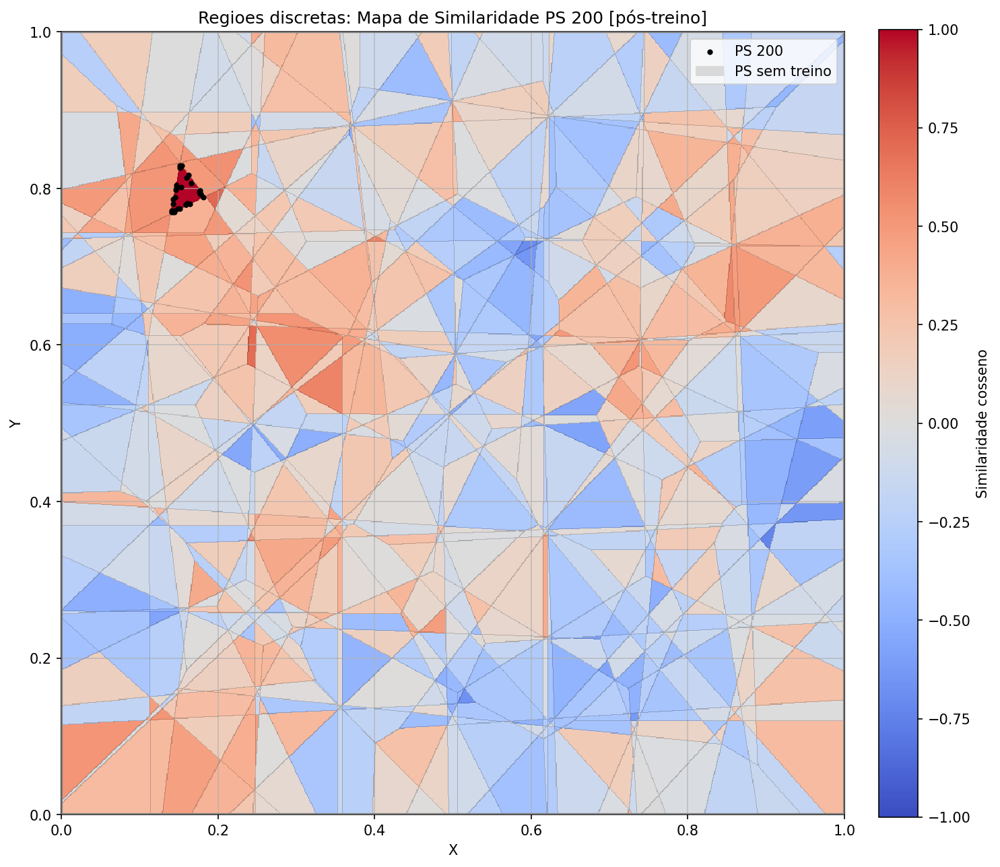

In [131]:
plot_cosine_similarity_map_discreto(
    df_states=df,
    cossim_df=coss,
    current_id=200,
    similarity_id_offset=0,
    cmap="coolwarm",
    sim_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag = '[pós-treino]'
)
plt.show()

Referencia: celula original 91

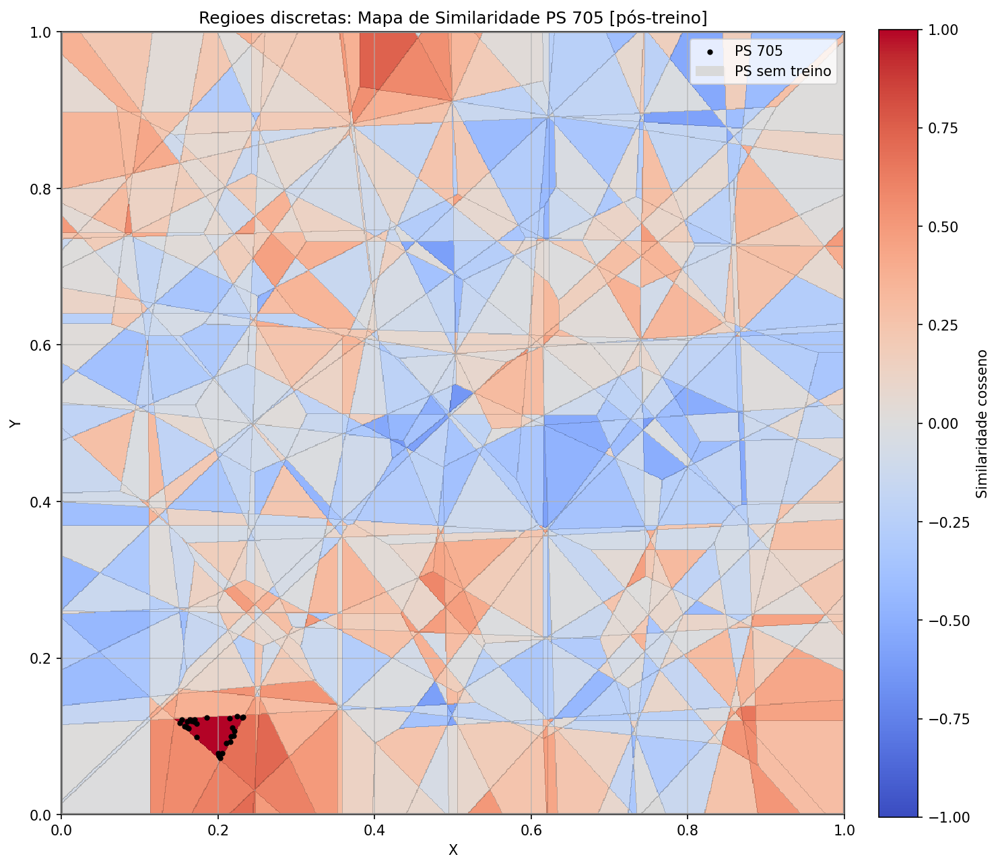

In [132]:
plot_cosine_similarity_map_discreto(
    df_states=df,
    cossim_df=coss,
    current_id=705,
    similarity_id_offset=0,
    cmap="coolwarm",
    sim_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag = '[pós-treino]'
)
plt.show()

Referencia: celula original 92

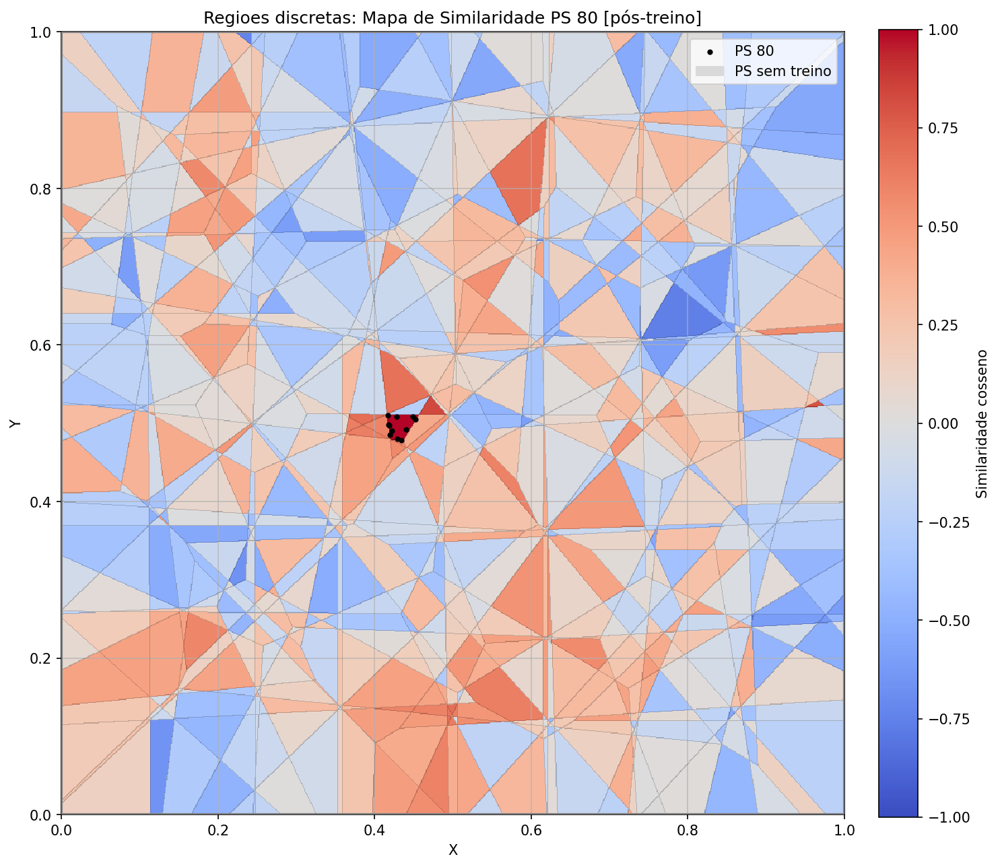

In [133]:
plot_cosine_similarity_map_discreto(
    df_states=df,
    cossim_df=coss,
    current_id=80,
    similarity_id_offset=0,
    cmap="coolwarm",
    sim_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag = '[pós-treino]'
)
plt.show()

Referencia: celula original 93

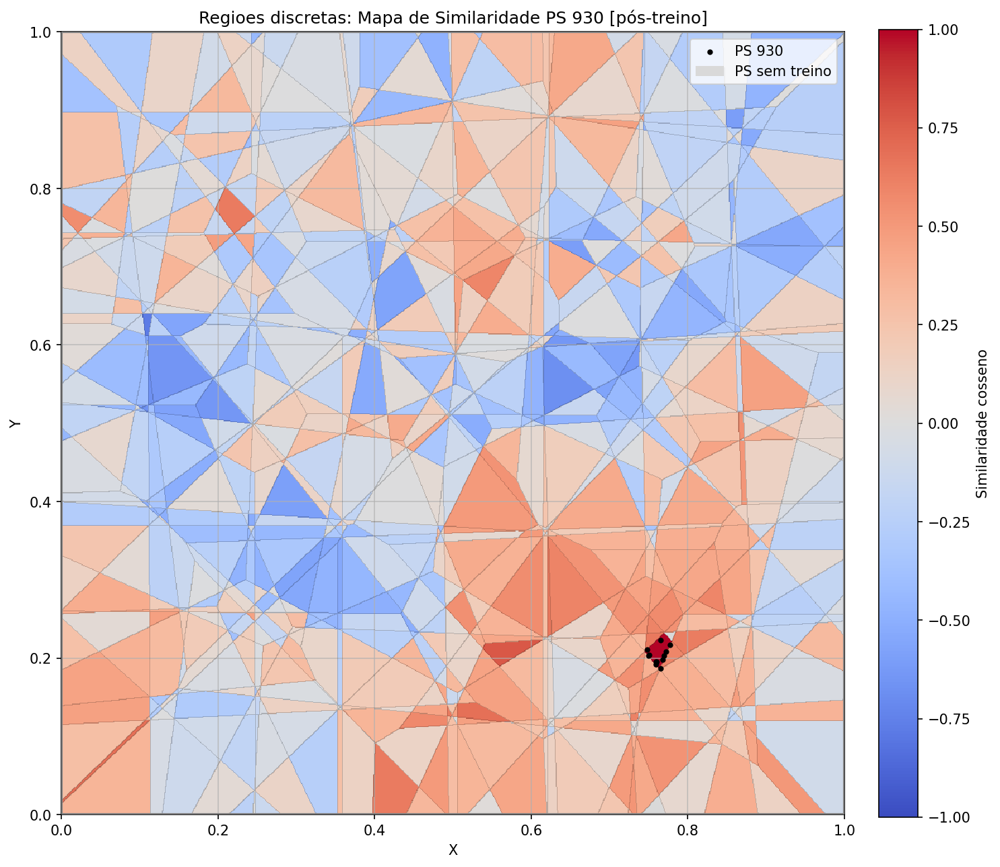

In [134]:
plot_cosine_similarity_map_discreto(
    df_states=df,
    cossim_df=coss,
    current_id=930,
    similarity_id_offset=0,
    cmap="coolwarm",
    sim_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag = '[pós-treino]'
)
plt.show()

Referencia: celula original 94

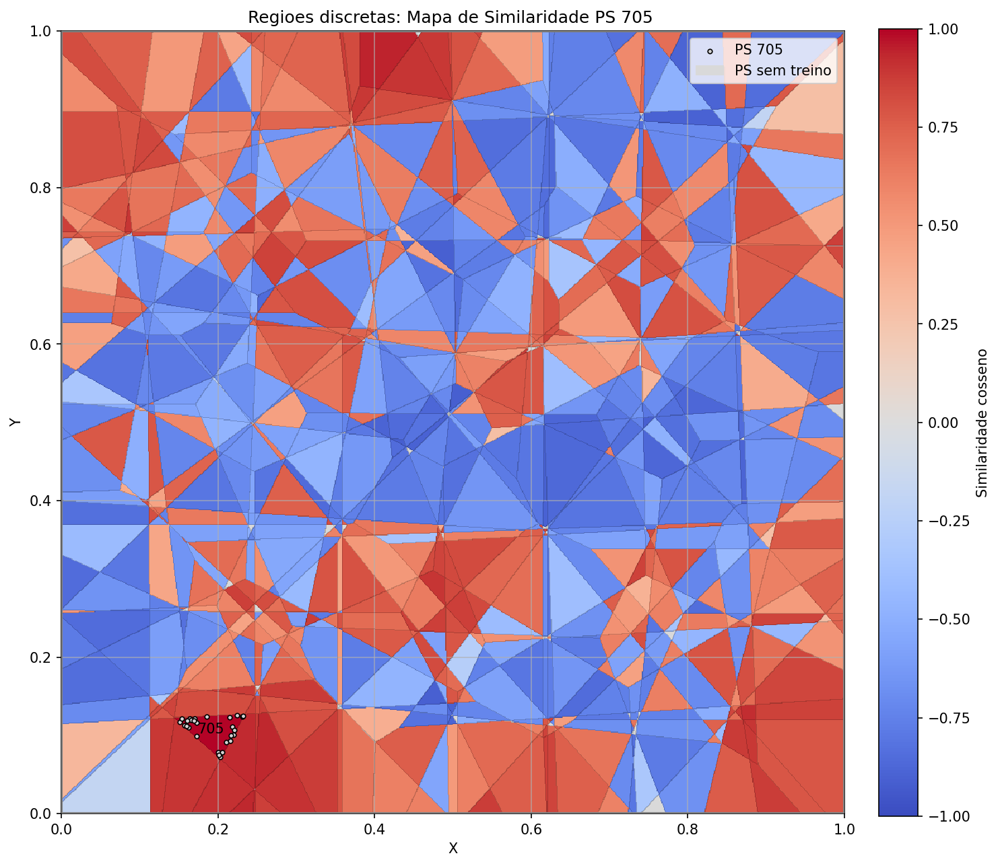

(<Figure size 1500x1500 with 2 Axes>,
 <Axes: title={'center': 'Regioes discretas: Mapa de Similaridade PS 705 '}, xlabel='X', ylabel='Y'>)

In [135]:
plot_cosine_similarity_map_discreto(
    df_states=df,
    cossim_df=coss,
    current_id=705,
    similarity_id_offset=0,
    cmap="coolwarm",
    sim_power=0.2,
    current_color="lightgray",
    current_size=10,
    current_alpha=1
)

## Similaridade das representacoes sem gaussiana

Referencia: celula original 100

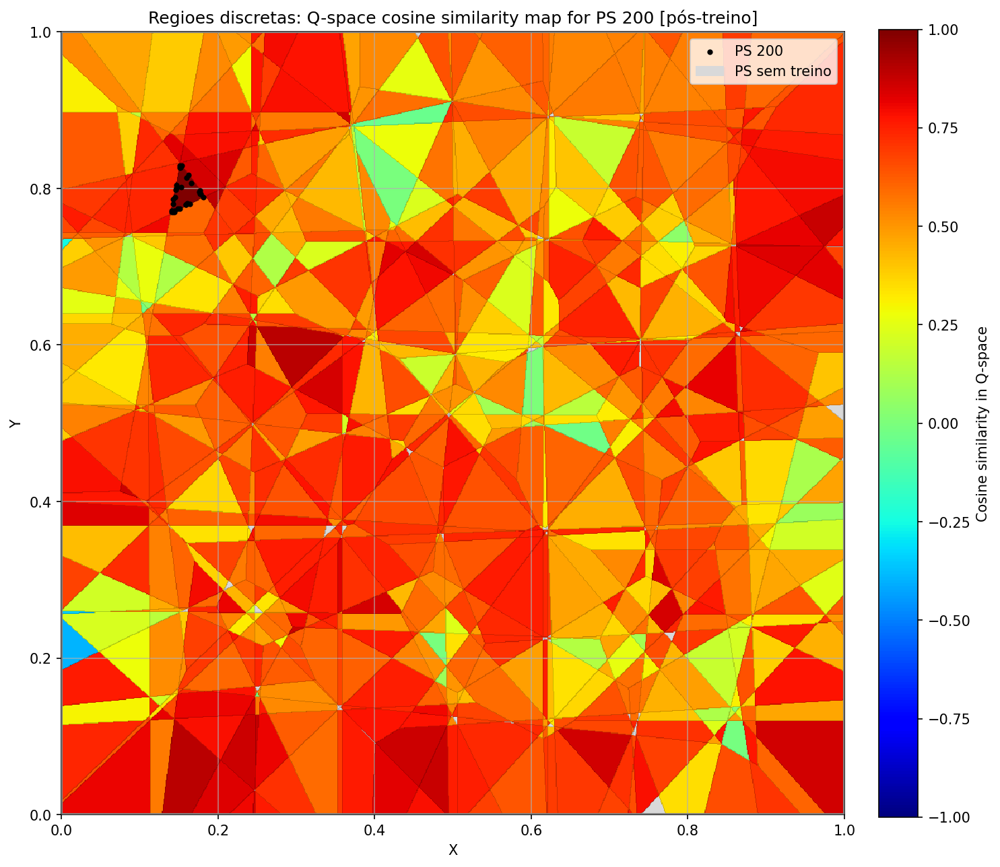

In [136]:
plot_representation_similarity_map_discreto(
    df_states=df,
    sim_df=mechadf['q_cos'],
    current_id=200,
    similarity_id_offset=0,
    repr_name="Q",
    cmap="jet",
    sim_power=1.0,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag="[pós-treino]"
)
plt.show()

Referencia: celula original 101

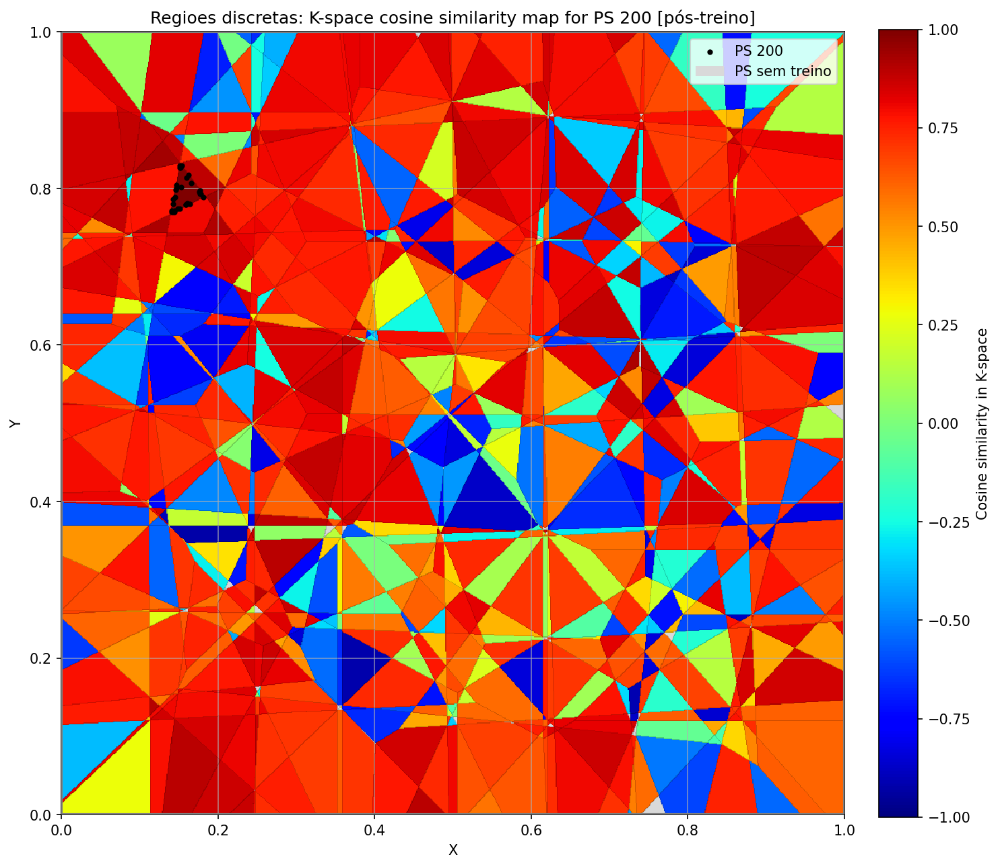

In [137]:
plot_representation_similarity_map_discreto(
    df_states=df,
    sim_df=mechadf['k_cos'],
    current_id=200,
    similarity_id_offset=0,
    repr_name="K",
    cmap="jet",
    sim_power=1.0,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag="[pós-treino]"
)
plt.show()

Referencia: celula original 102

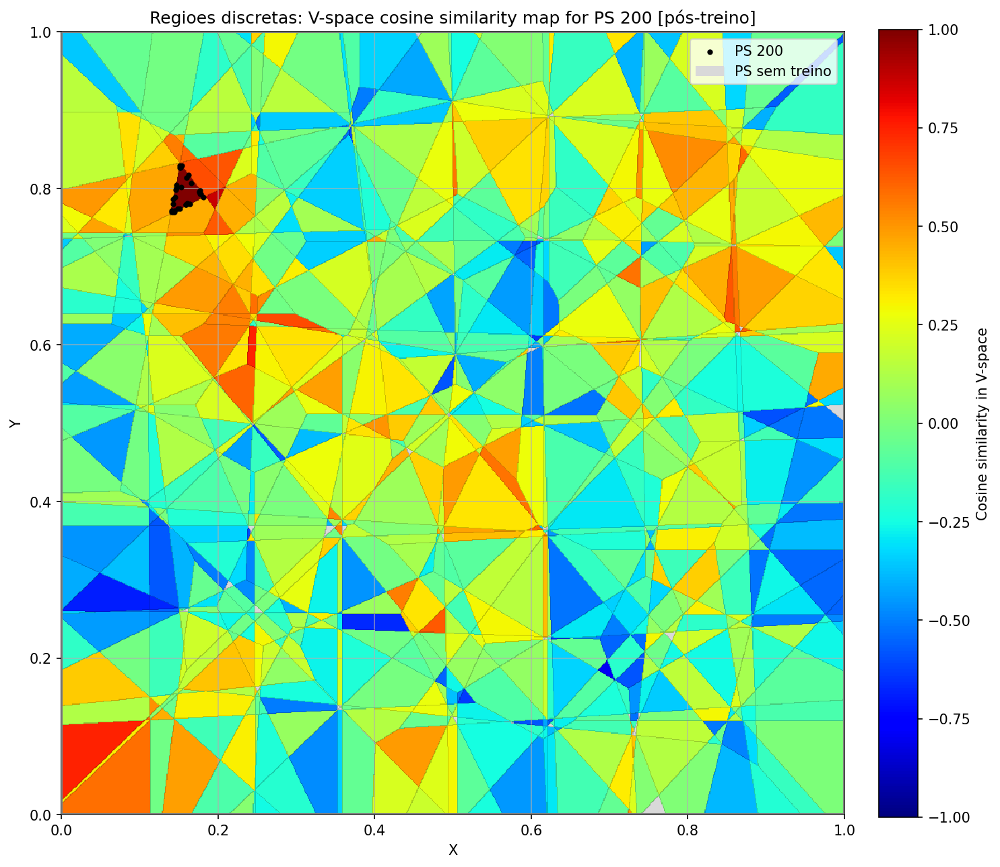

In [138]:
plot_representation_similarity_map_discreto(
    df_states=df,
    sim_df=mechadf['v_cos'],
    current_id=200,
    similarity_id_offset=0,
    repr_name="V",
    cmap="jet",
    sim_power=1.0,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag="[pós-treino]"
)
plt.show()

Referencia: celula original 105

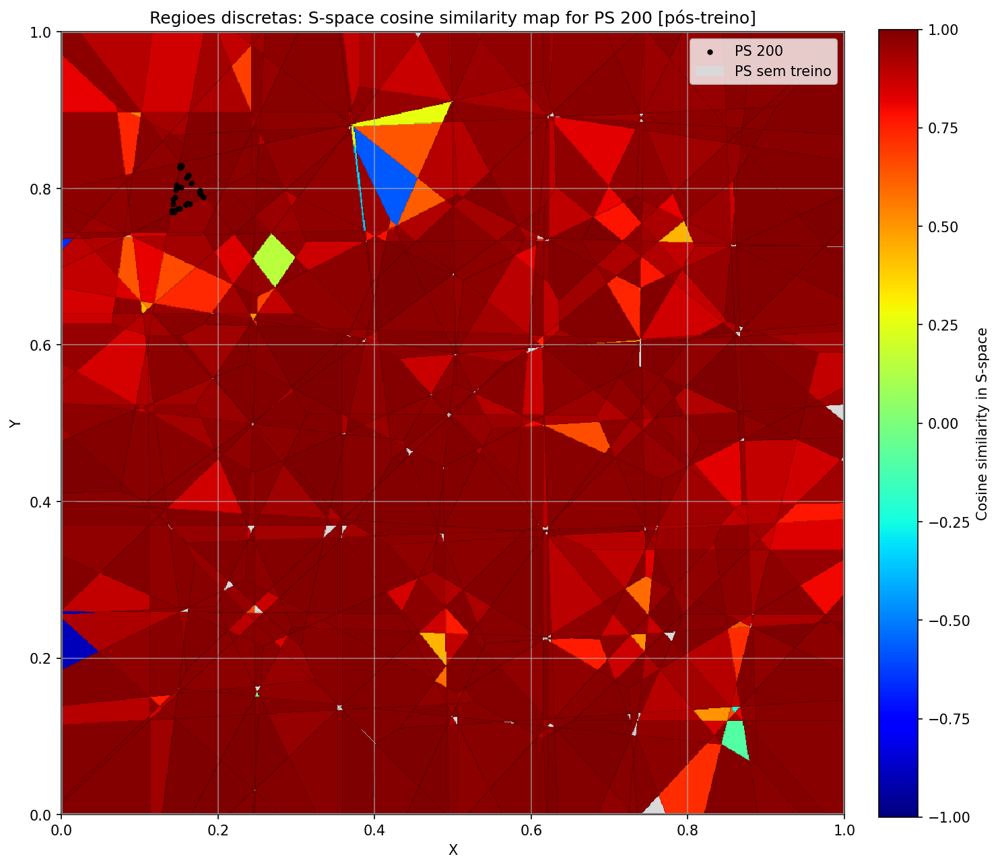

In [139]:
plot_representation_similarity_map_discreto(
    df_states=df,
    sim_df=mechadf['s_cos'],
    current_id=200,
    similarity_id_offset=0,
    repr_name="S",
    cmap="jet",
    sim_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag="[pós-treino]"
)
plt.show()

Referencia: celula original 106

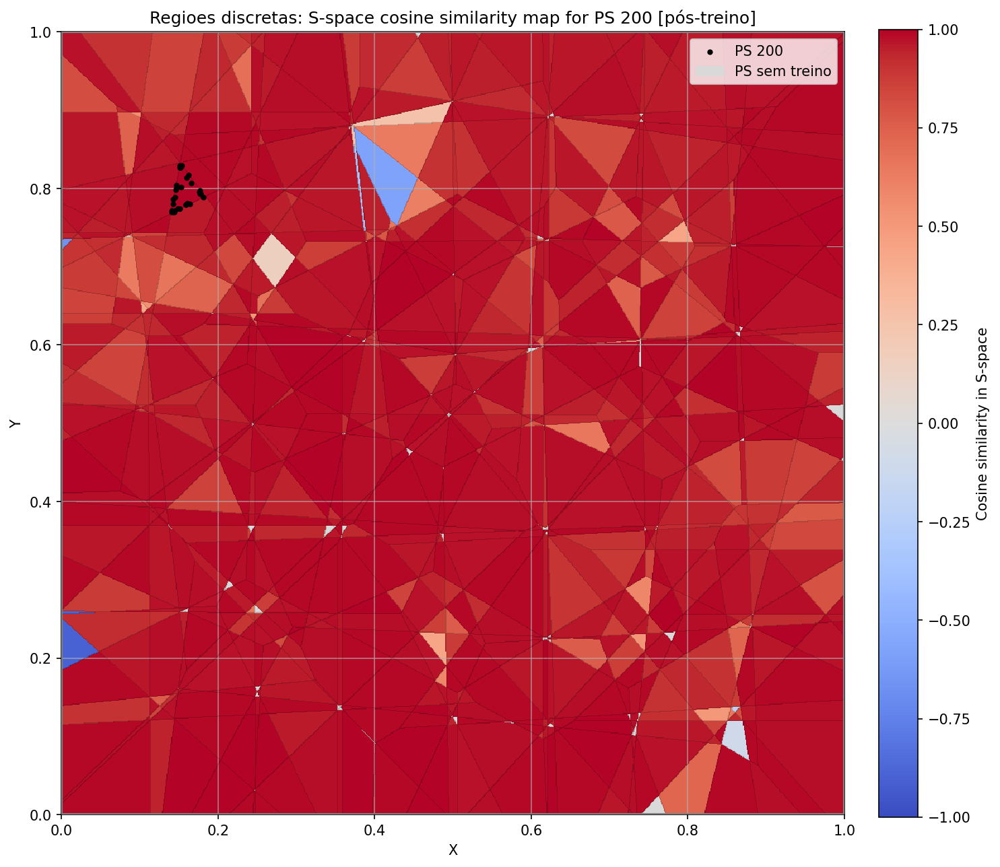

In [140]:
plot_representation_similarity_map_discreto(
    df_states=df,
    sim_df=mechadf['s_cos'],
    current_id=200,
    similarity_id_offset=0,
    repr_name="S",
    cmap="coolwarm",
    sim_power=1.0,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag="[pós-treino]"
)
plt.show()

## Probabilidade sem gaussiana

Referencia: celula original 115

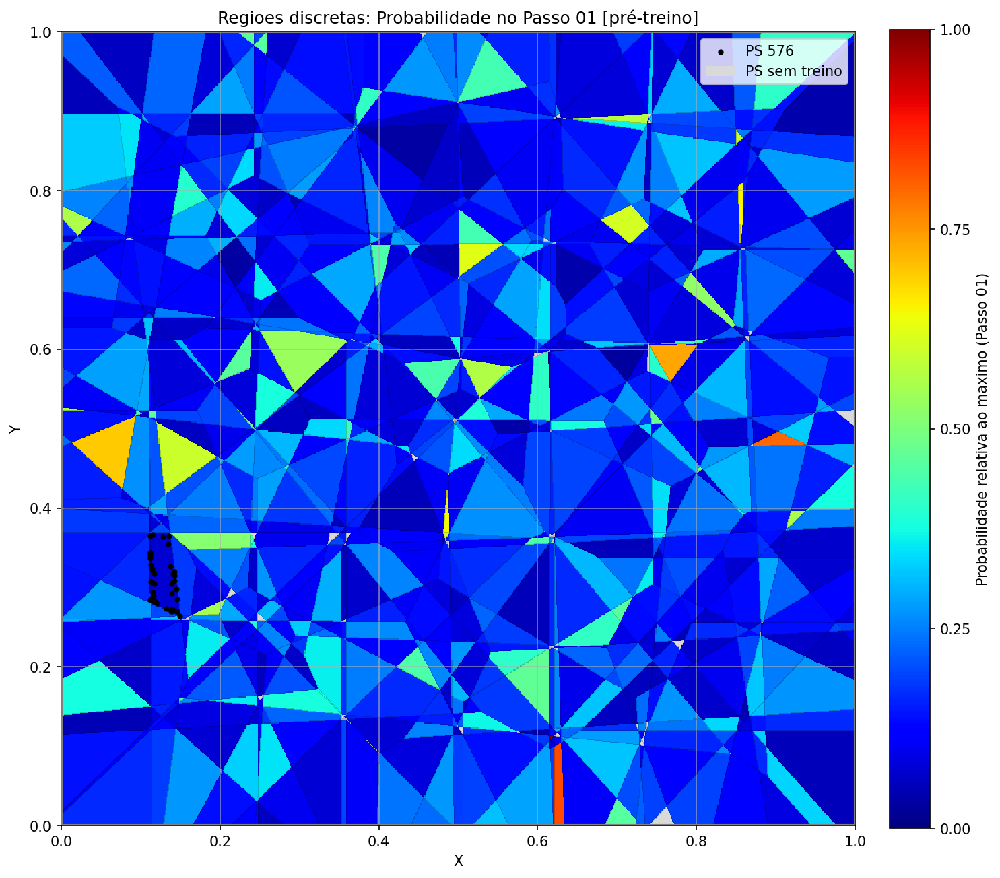

In [141]:
step_to_plot = 1
plot_next_id_probability_map_discreto(
    df_states=df,
    probs_df=snapshot_steps_df(full_fwd_pre_train, 'probs'),
    current_id=current_id_for_step(full_fwd_pre_train, step_to_plot),
    step=step_to_plot,
    cmap="jet",
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag = '[pré-treino]'
)
plt.show()

Referencia: celula original 117

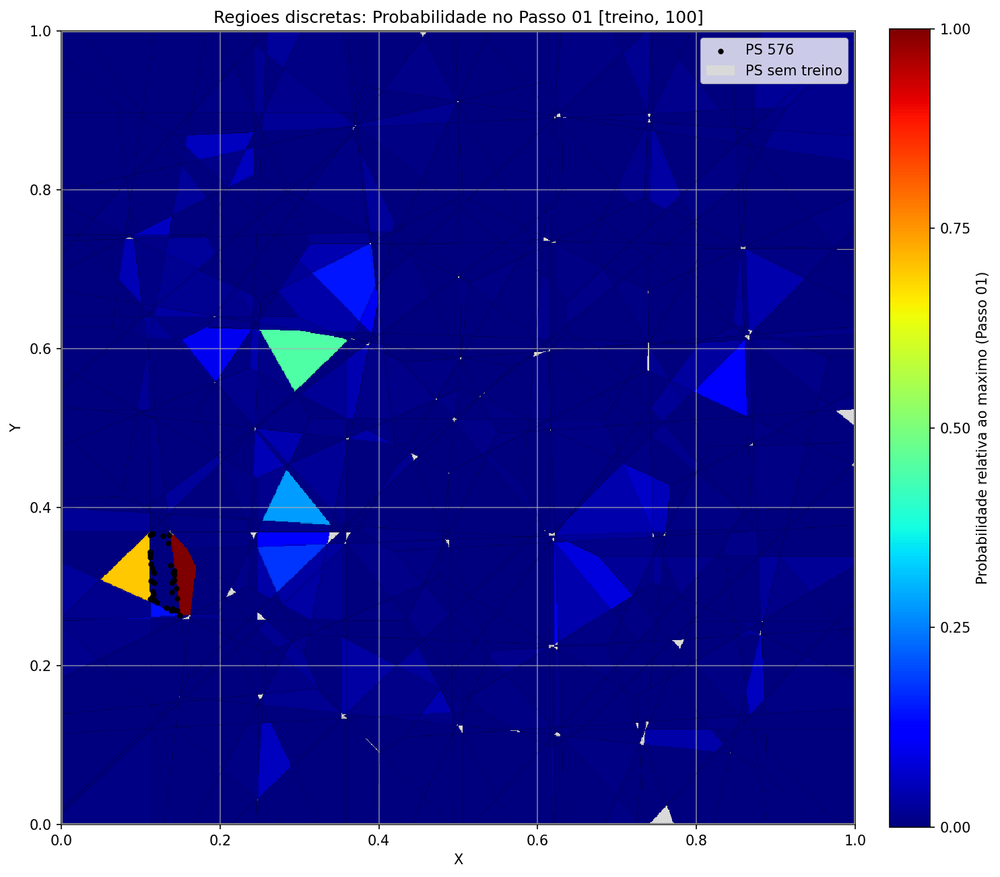

In [142]:
step_to_plot = 1
plot_next_id_probability_map_discreto(
    df_states=df,
    probs_df=snapshot_steps_df(full_fwd_100, 'probs'),
    current_id=current_id_for_step(full_fwd_100, step_to_plot),
    step=step_to_plot,
    cmap="jet",
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag = '[treino, 100]'
)
plt.show()

Referencia: celula original 120

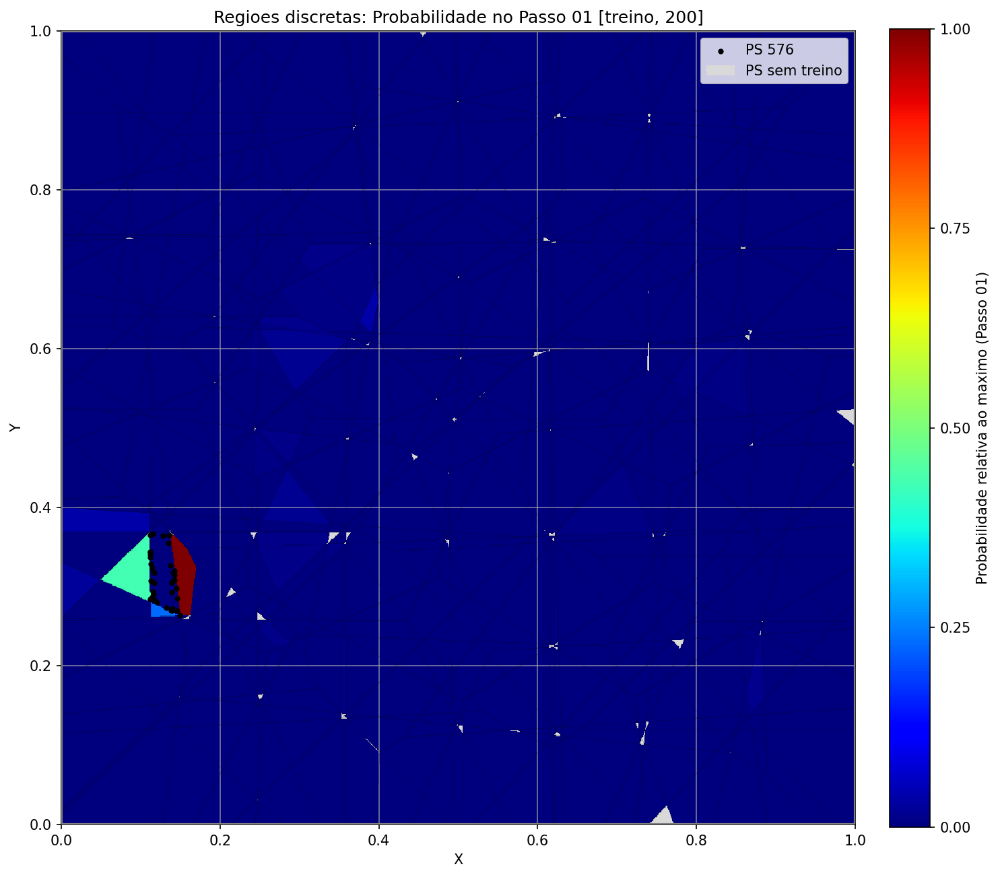

In [143]:
step_to_plot = 1
plot_next_id_probability_map_discreto(
    df_states=df,
    probs_df=snapshot_steps_df(full_fwd_200, 'probs'),
    current_id=current_id_for_step(full_fwd_200, step_to_plot),
    step=step_to_plot,
    cmap="jet",
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag = '[treino, 200]'
)
plt.show()

Referencia: celula original 122

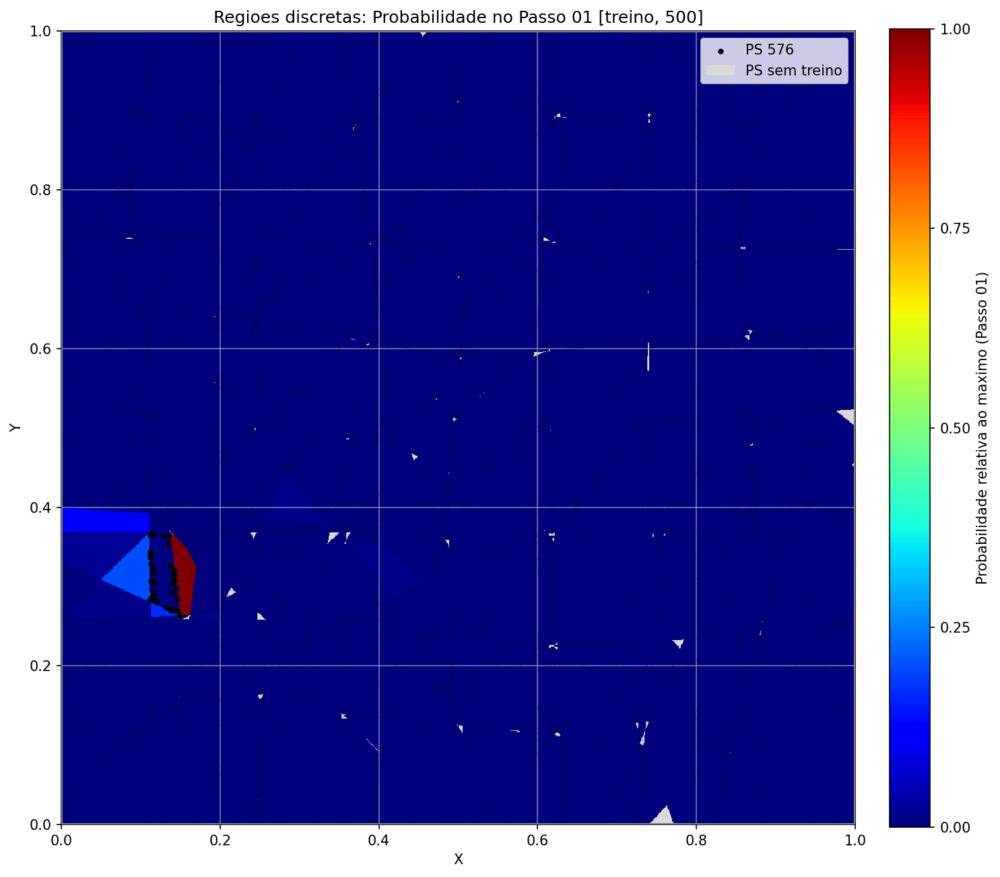

In [144]:
step_to_plot = 1
plot_next_id_probability_map_discreto(
    df_states=df,
    probs_df=snapshot_steps_df(full_fwd_500, 'probs'),
    current_id=current_id_for_step(full_fwd_500, step_to_plot),
    step=step_to_plot,
    cmap="jet",
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag = '[treino, 500]'
)
plt.show()

Referencia: celula original 124

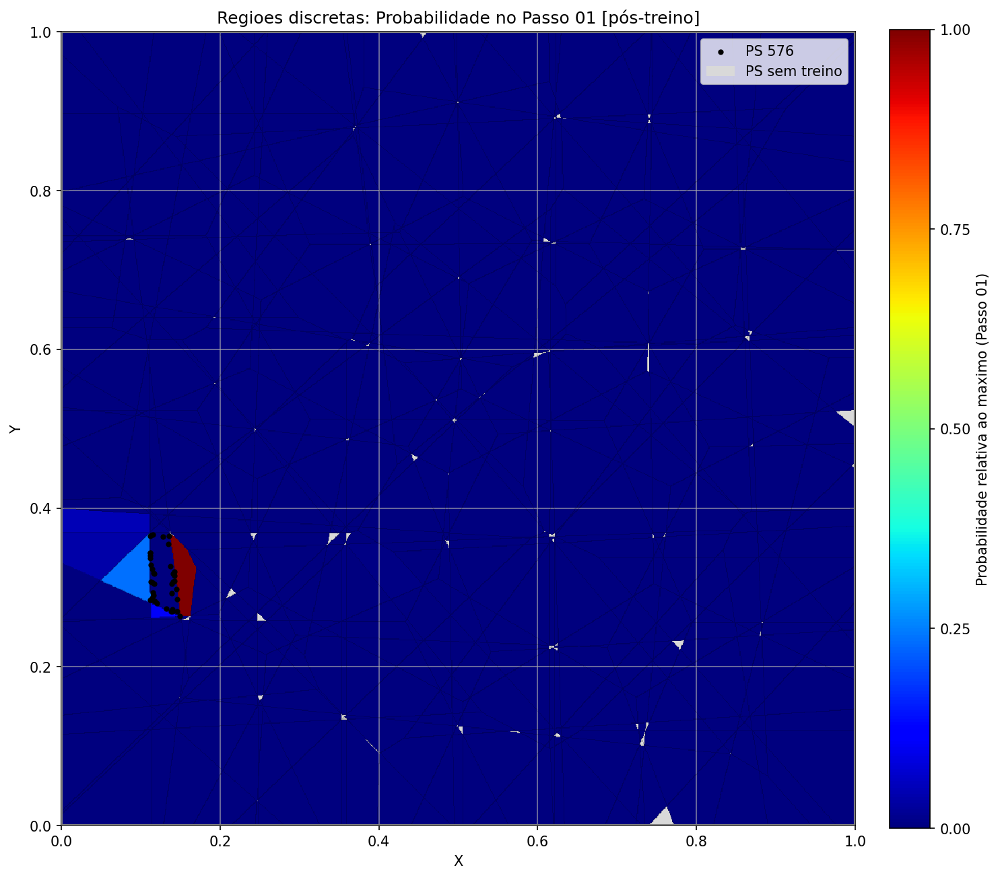

In [145]:
step_to_plot = 1
plot_next_id_probability_map_discreto(
    df_states=df,
    probs_df=snapshot_steps_df(full_fwd, 'probs'),
    current_id=current_id_for_step(full_fwd, step_to_plot),
    step=step_to_plot,
    cmap="jet",
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    title_tag = '[pós-treino]'
)
plt.show()

Referencia: celula original 127

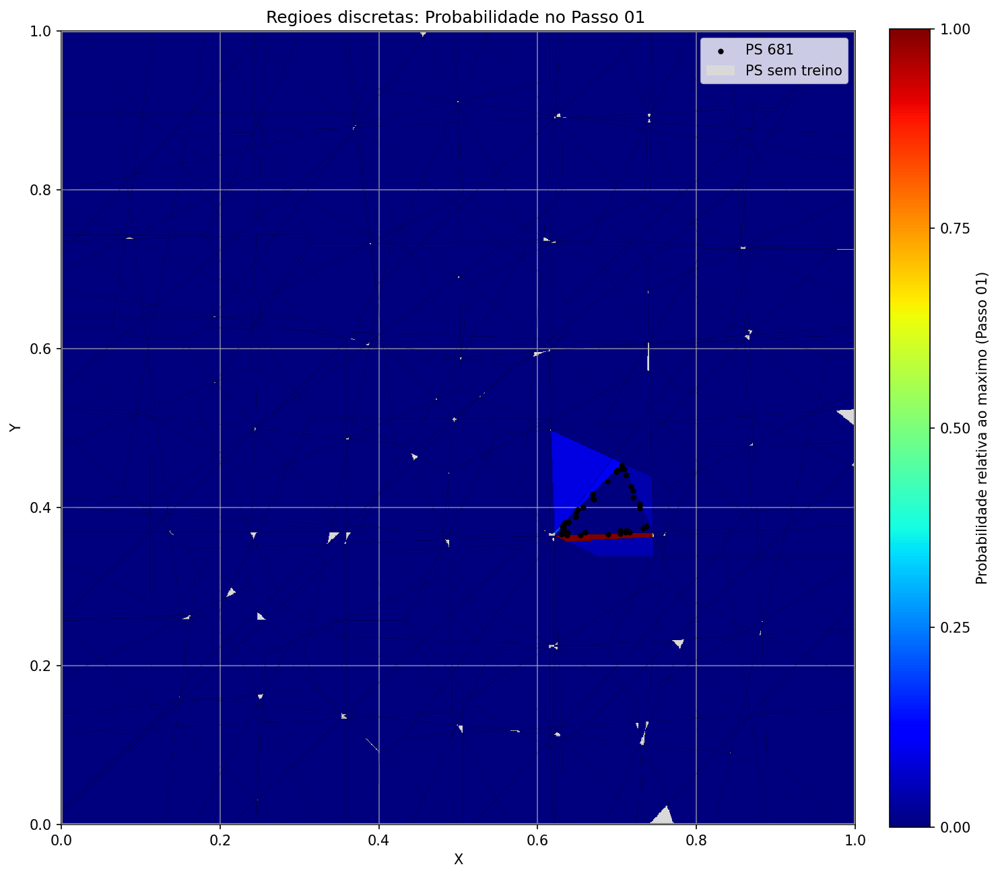

In [146]:
step_to_plot = 1
plot_next_id_probability_map_discreto(
    df_states=df,
    probs_df=distribs_probs,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="jet",
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
)
plt.show()

Referencia: celula original 128

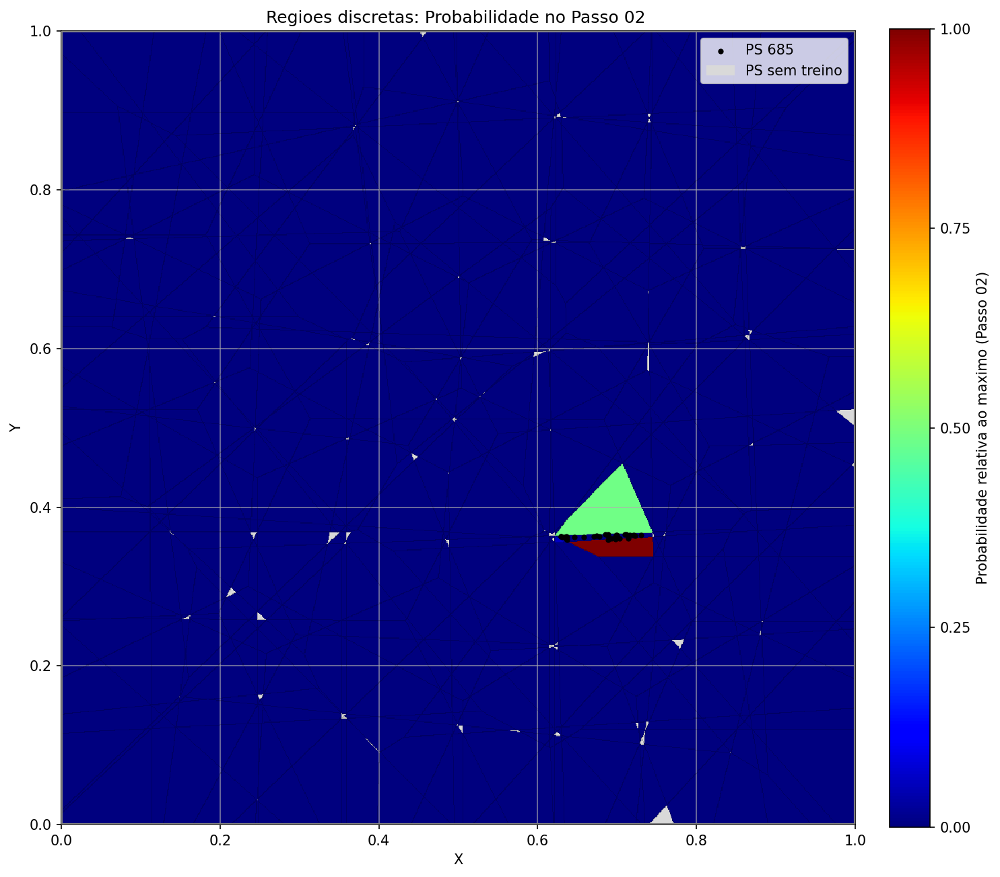

In [147]:
step_to_plot = 2
plot_next_id_probability_map_discreto(
    df_states=df,
    probs_df=distribs_probs,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="jet",
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
)
plt.show()

Referencia: celula original 129

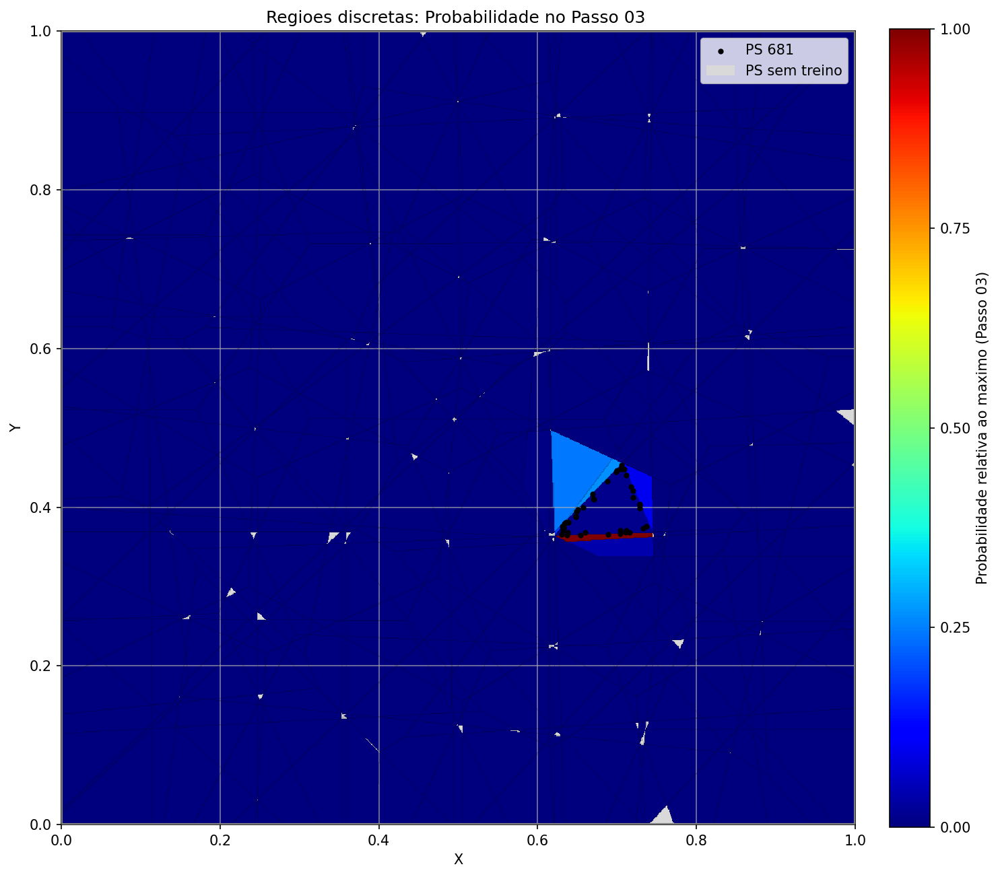

In [148]:
step_to_plot = 3
plot_next_id_probability_map_discreto(
    df_states=df,
    probs_df=distribs_probs,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="jet",
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
)
plt.show()

Referencia: celula original 130

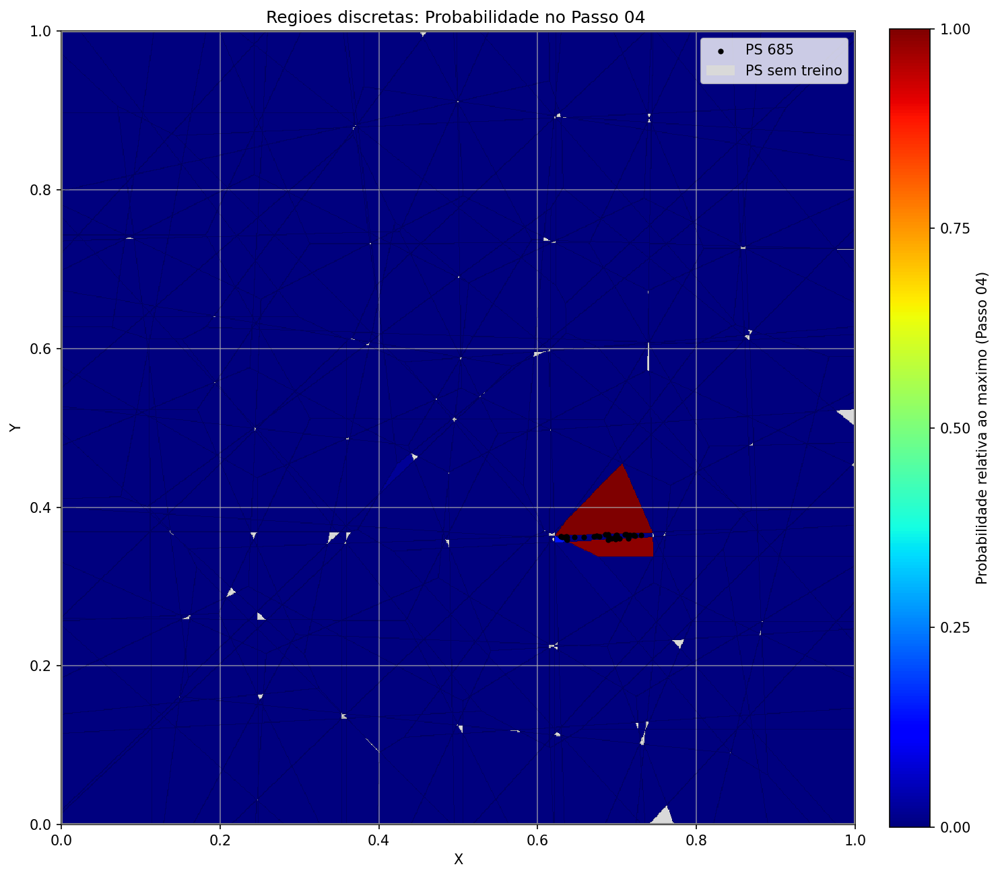

(<Figure size 1500x1500 with 2 Axes>,
 <Axes: title={'center': 'Regioes discretas: Probabilidade no Passo 04 '}, xlabel='X', ylabel='Y'>)

In [149]:
step_to_plot = 4
plot_next_id_probability_map_discreto(
    df_states=df,
    probs_df=distribs_probs,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="jet",
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
)

Referencia: celula original 131

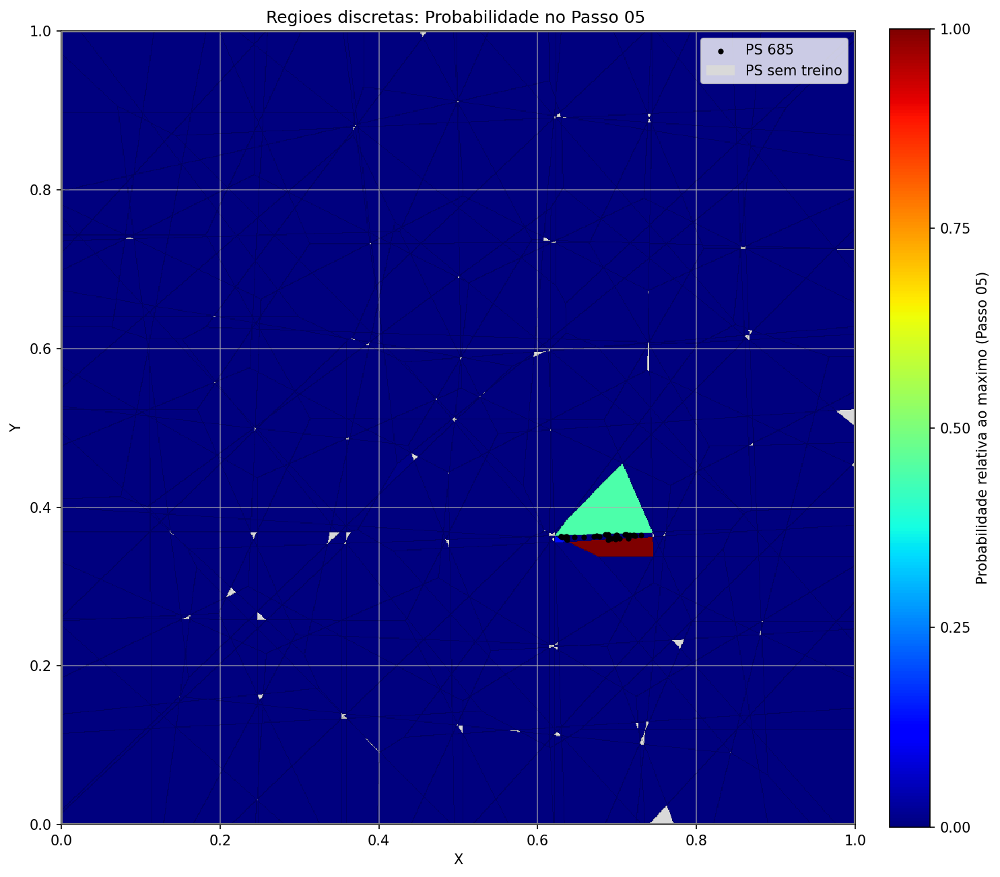

(<Figure size 1500x1500 with 2 Axes>,
 <Axes: title={'center': 'Regioes discretas: Probabilidade no Passo 05 '}, xlabel='X', ylabel='Y'>)

In [150]:
step_to_plot = 5
plot_next_id_probability_map_discreto(
    df_states=df,
    probs_df=distribs_probs,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="jet",
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
)

Referencia: celula original 132

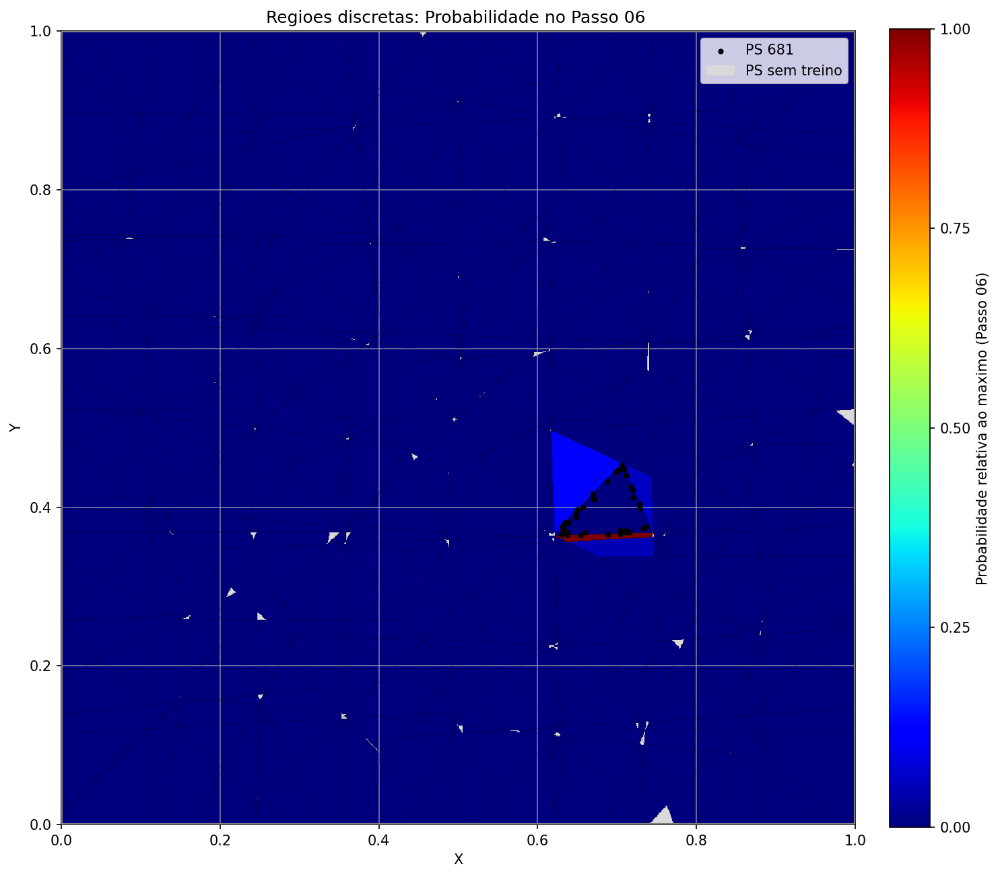

(<Figure size 1500x1500 with 2 Axes>,
 <Axes: title={'center': 'Regioes discretas: Probabilidade no Passo 06 '}, xlabel='X', ylabel='Y'>)

In [151]:
step_to_plot = 6
plot_next_id_probability_map_discreto(
    df_states=df,
    probs_df=distribs_probs,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="jet",
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
)

Referencia: celula original 133

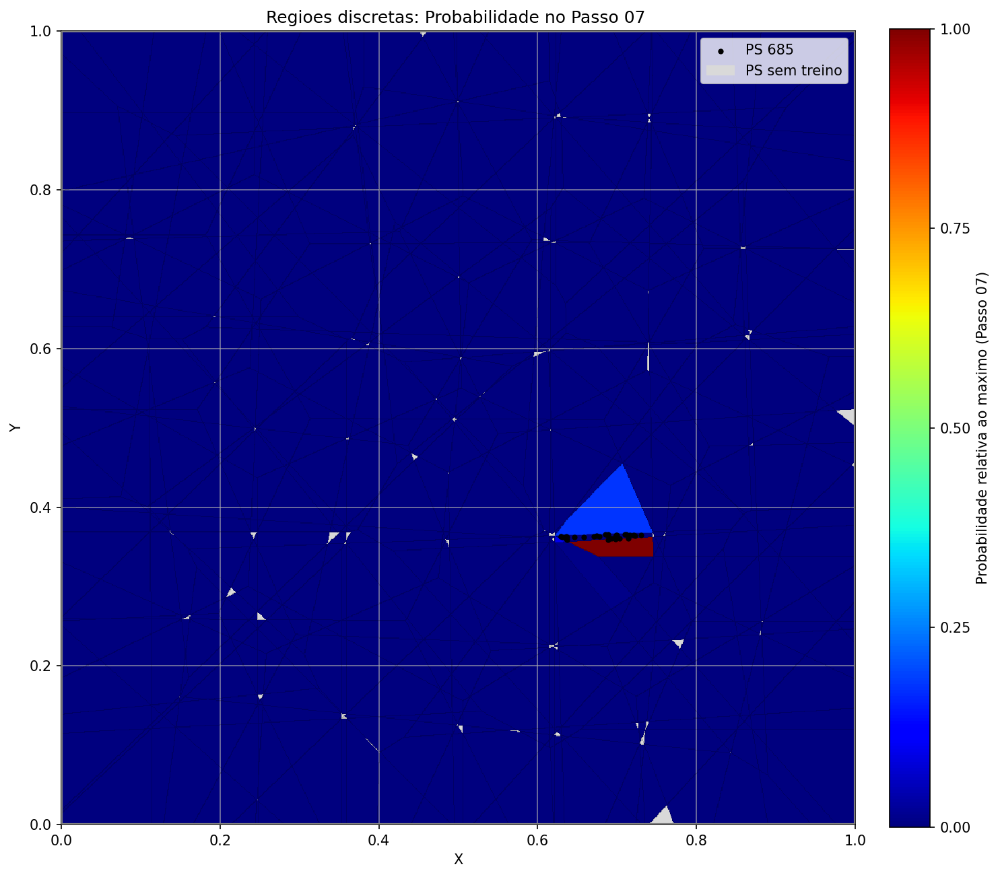

(<Figure size 1500x1500 with 2 Axes>,
 <Axes: title={'center': 'Regioes discretas: Probabilidade no Passo 07 '}, xlabel='X', ylabel='Y'>)

In [152]:
step_to_plot = 7
plot_next_id_probability_map_discreto(
    df_states=df,
    probs_df=distribs_probs,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="jet",
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
)

Referencia: celula original 134

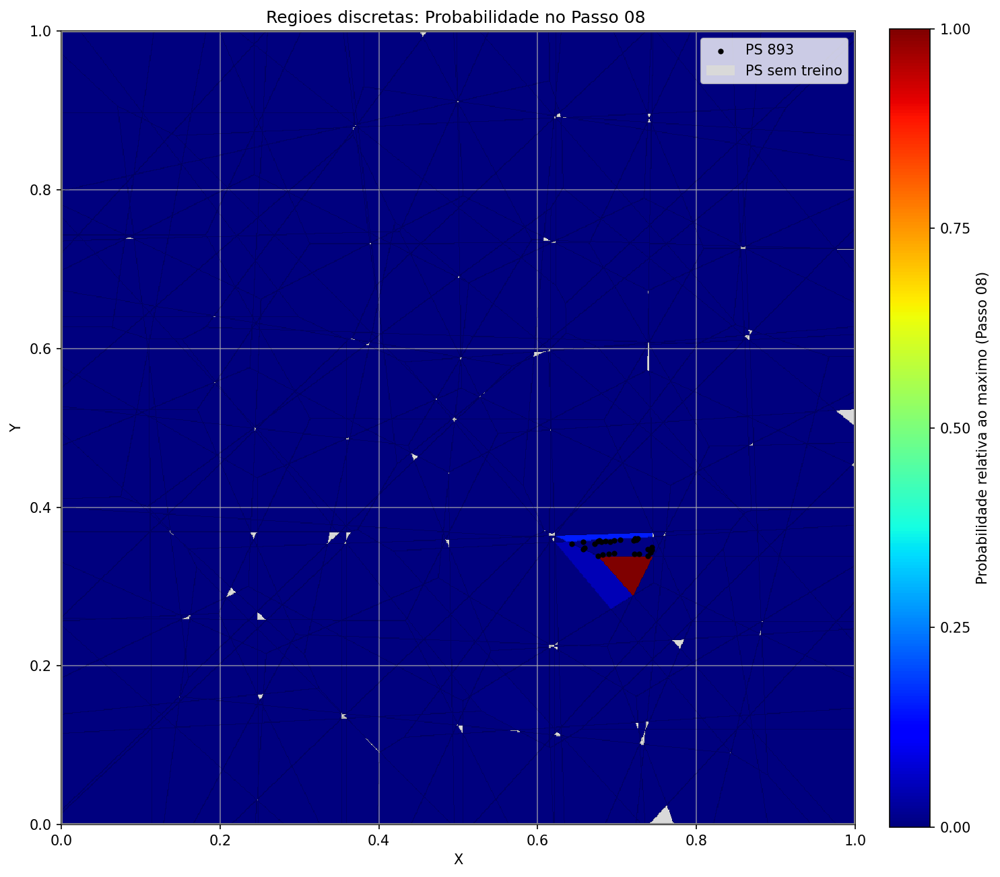

(<Figure size 1500x1500 with 2 Axes>,
 <Axes: title={'center': 'Regioes discretas: Probabilidade no Passo 08 '}, xlabel='X', ylabel='Y'>)

In [153]:
step_to_plot = 8
plot_next_id_probability_map_discreto(
    df_states=df,
    probs_df=distribs_probs,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="jet",
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
)

Referencia: celula original 135

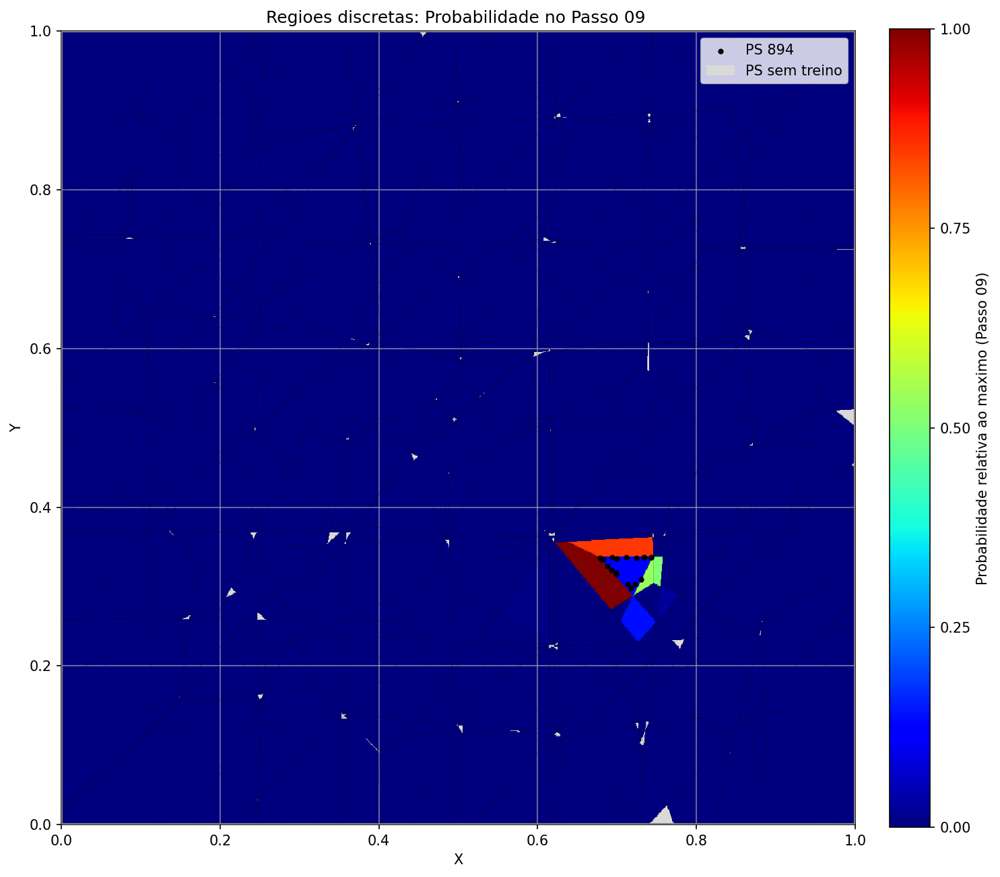

(<Figure size 1500x1500 with 2 Axes>,
 <Axes: title={'center': 'Regioes discretas: Probabilidade no Passo 09 '}, xlabel='X', ylabel='Y'>)

In [154]:
step_to_plot = 9
plot_next_id_probability_map_discreto(
    df_states=df,
    probs_df=distribs_probs,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="jet",
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
)

Referencia: celula original 136

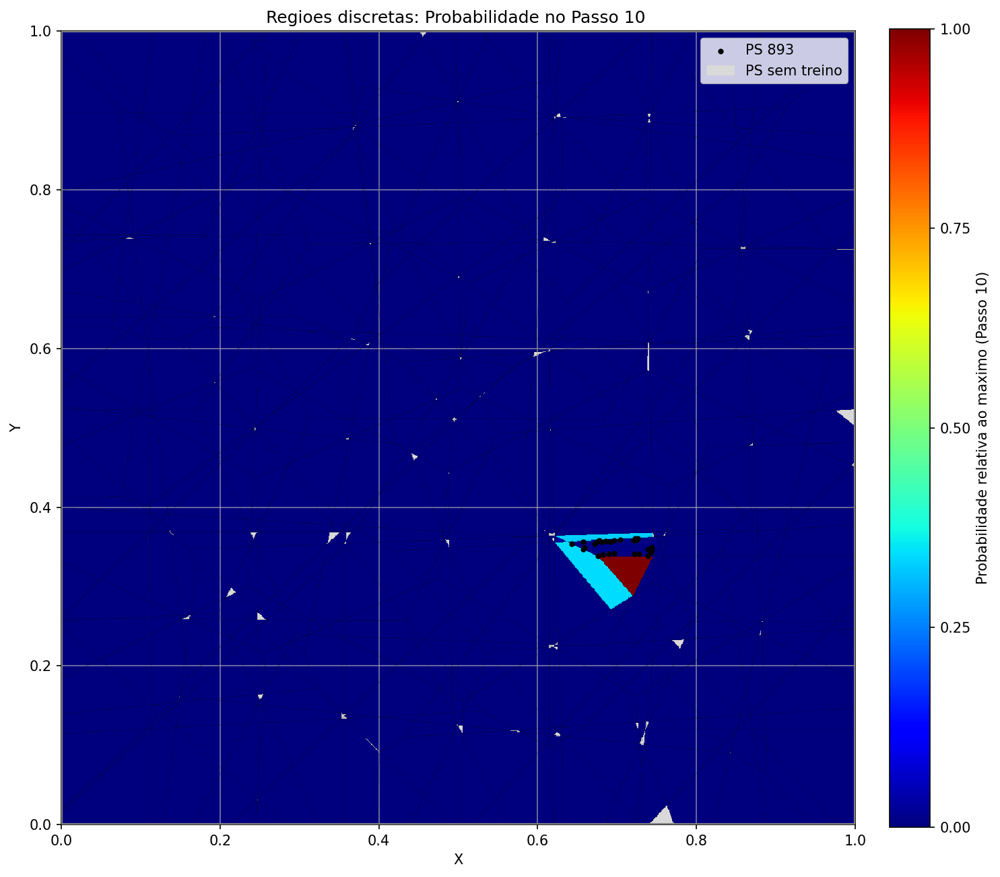

(<Figure size 1500x1500 with 2 Axes>,
 <Axes: title={'center': 'Regioes discretas: Probabilidade no Passo 10 '}, xlabel='X', ylabel='Y'>)

In [155]:
step_to_plot = 10
plot_next_id_probability_map_discreto(
    df_states=df,
    probs_df=distribs_probs,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="jet",
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
)

Referencia: celula original 140

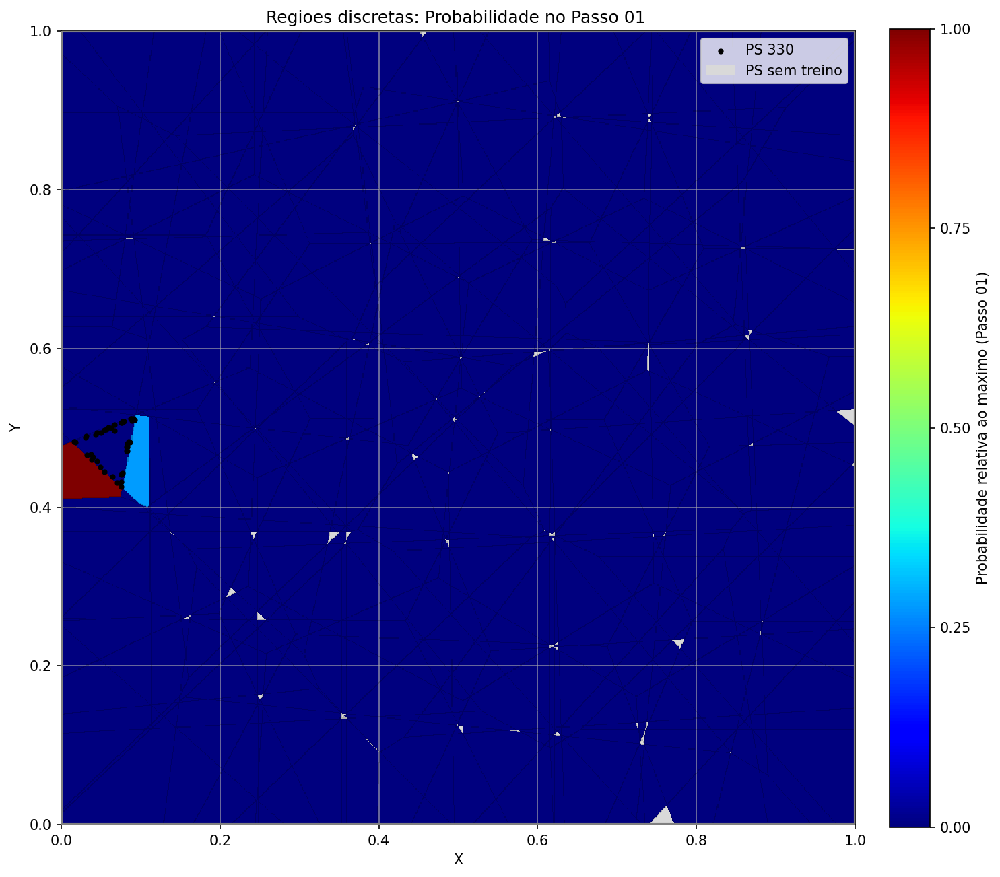

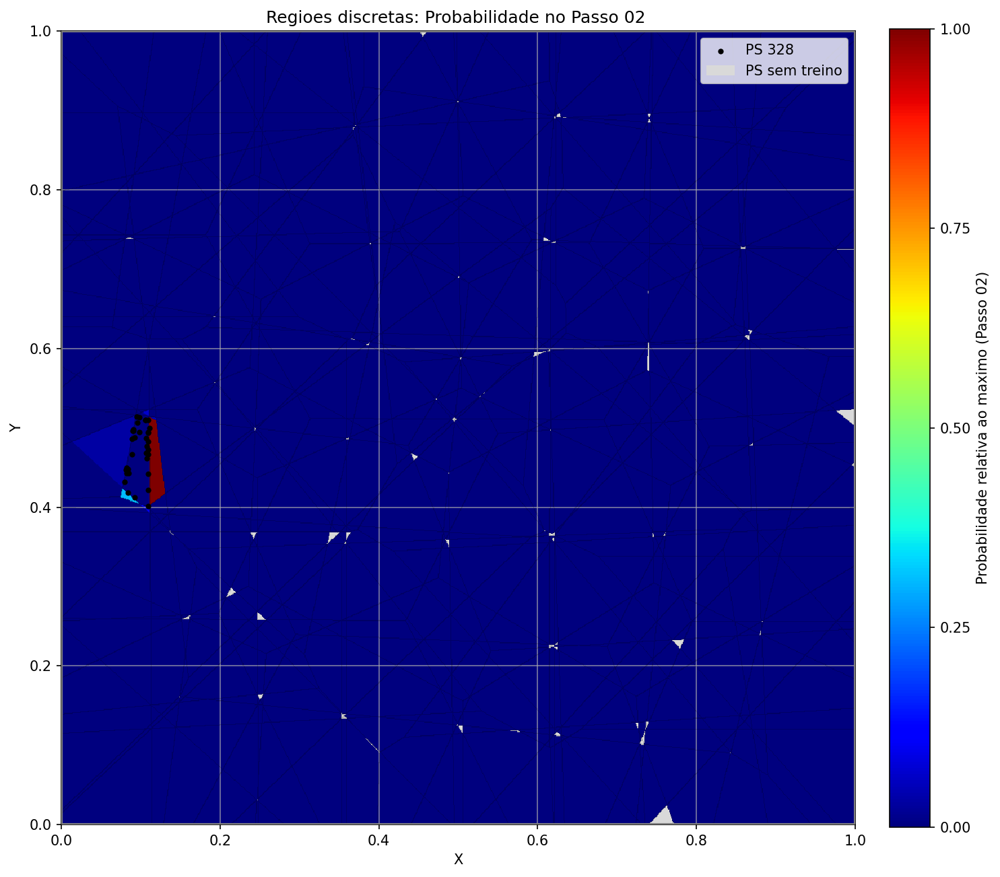

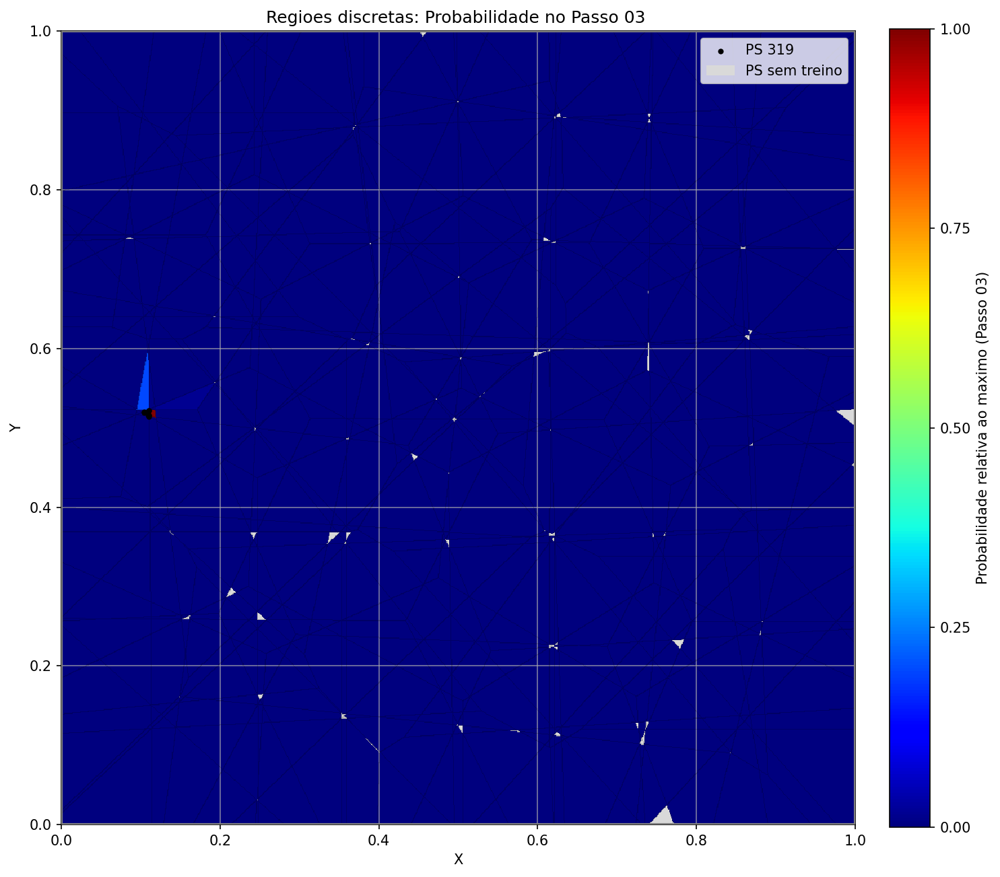

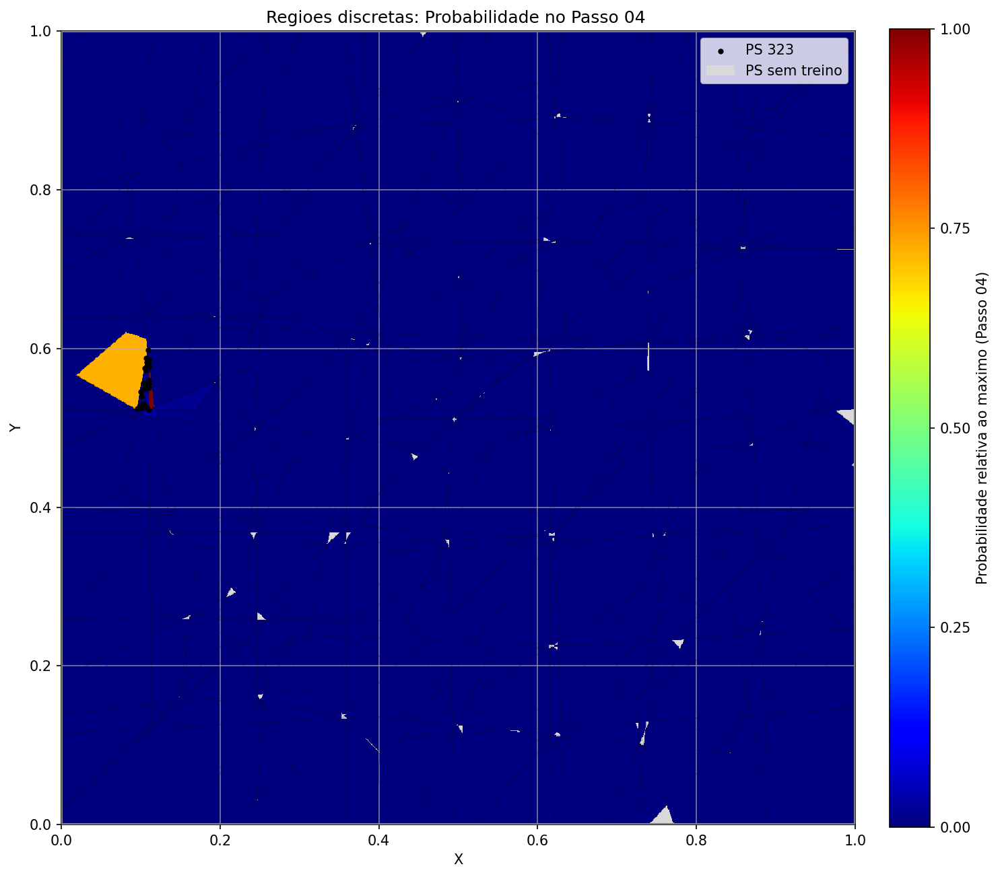

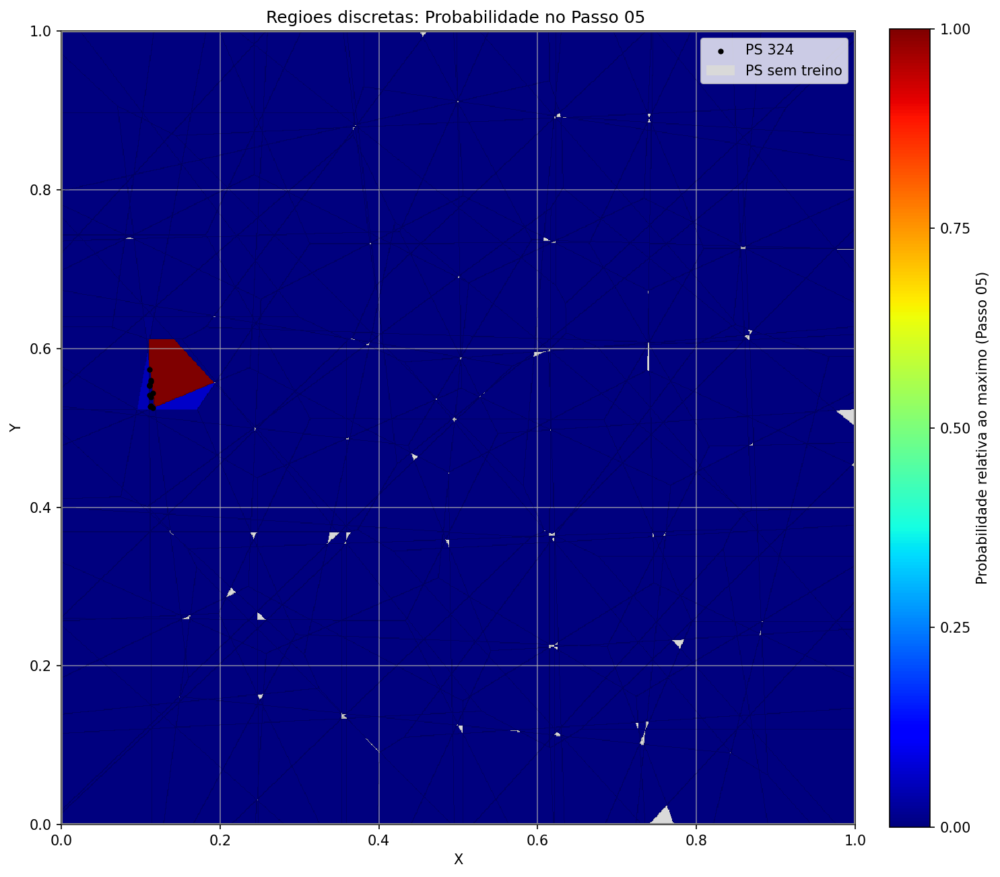

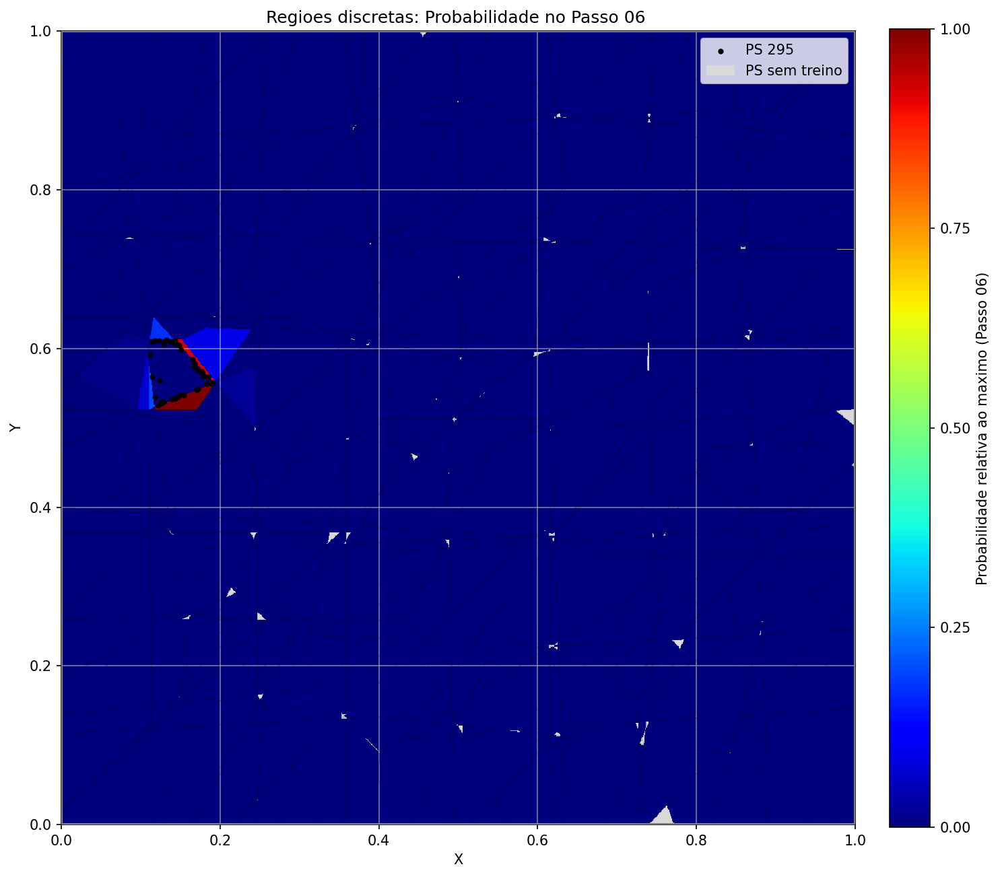

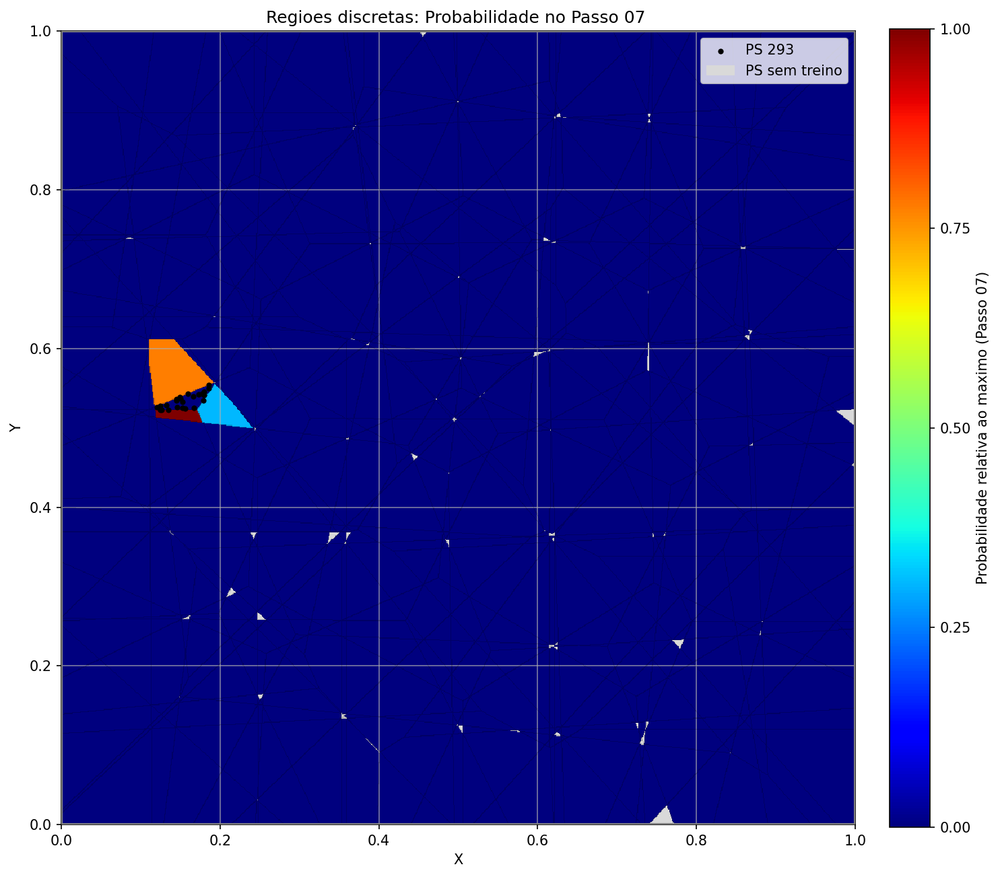

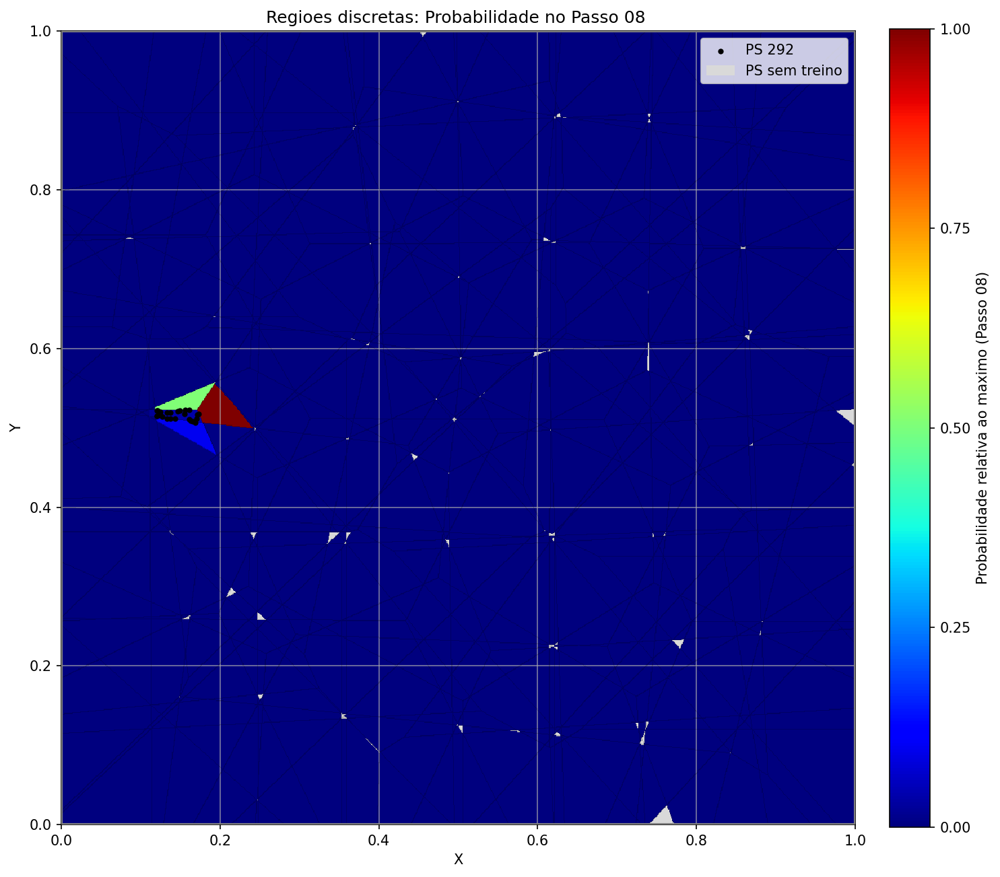

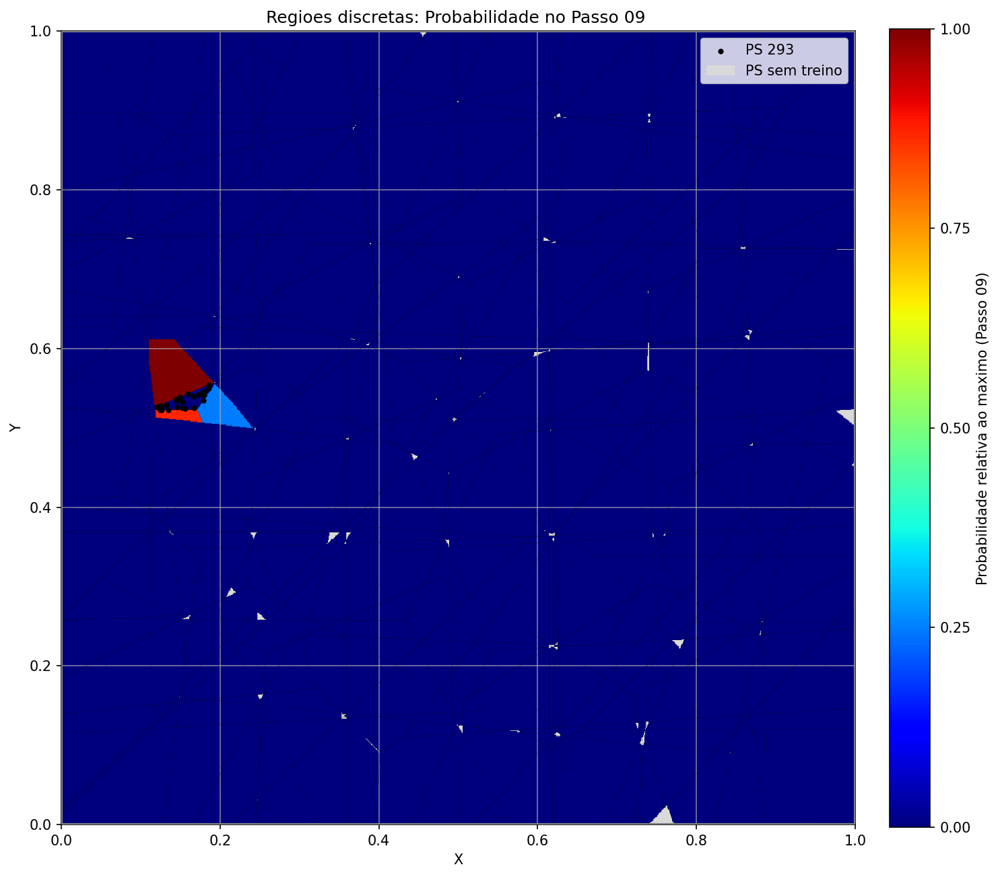

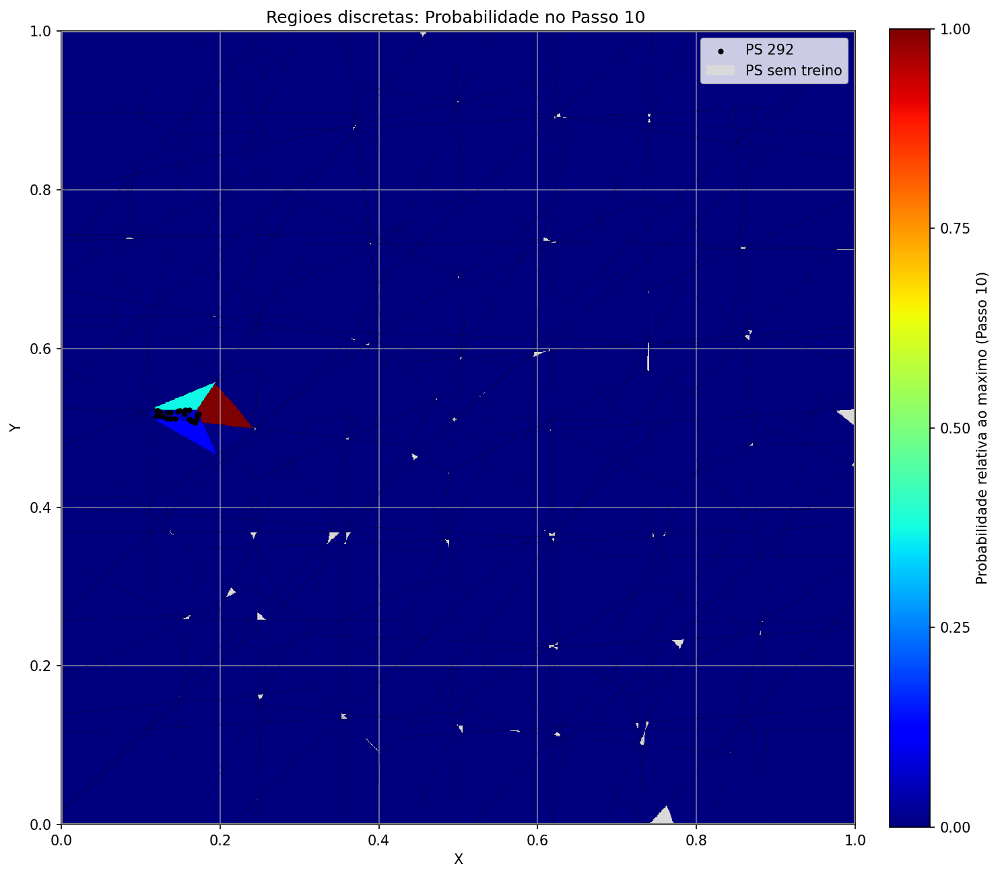

In [156]:
for i in range(1, 11):
    step_to_plot = i
    plot_next_id_probability_map_discreto(
        df_states=df,
        probs_df=distribs_probs507,
        current_id=generated_current_id(generation_507, step_to_plot),
        step=step_to_plot,
        cmap="jet",
        prob_power=1.,
        current_color="k",
        current_size=10,
        current_alpha=1,
        show_current_label=False,
    )

## Logits sem gaussiana

Referencia: celula original 152

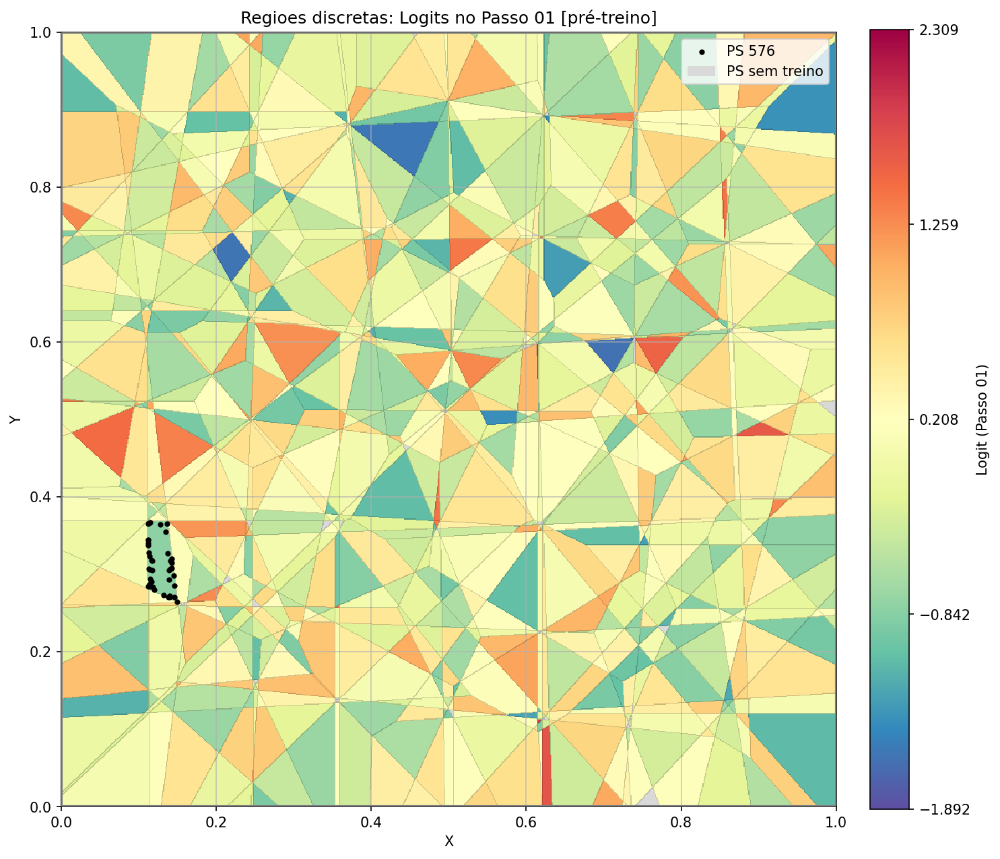

In [157]:
step_to_plot = 1
plot_next_id_logits_map_discreto(
    df_states=df,
    logits_df=snapshot_steps_df(full_fwd_pre_train, 'logits'),
    current_id=current_id_for_step(full_fwd_pre_train, step_to_plot),
    step=step_to_plot,
    cmap="Spectral_r",
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
    title_tag = '[pré-treino]'
)
plt.show()

Referencia: celula original 154

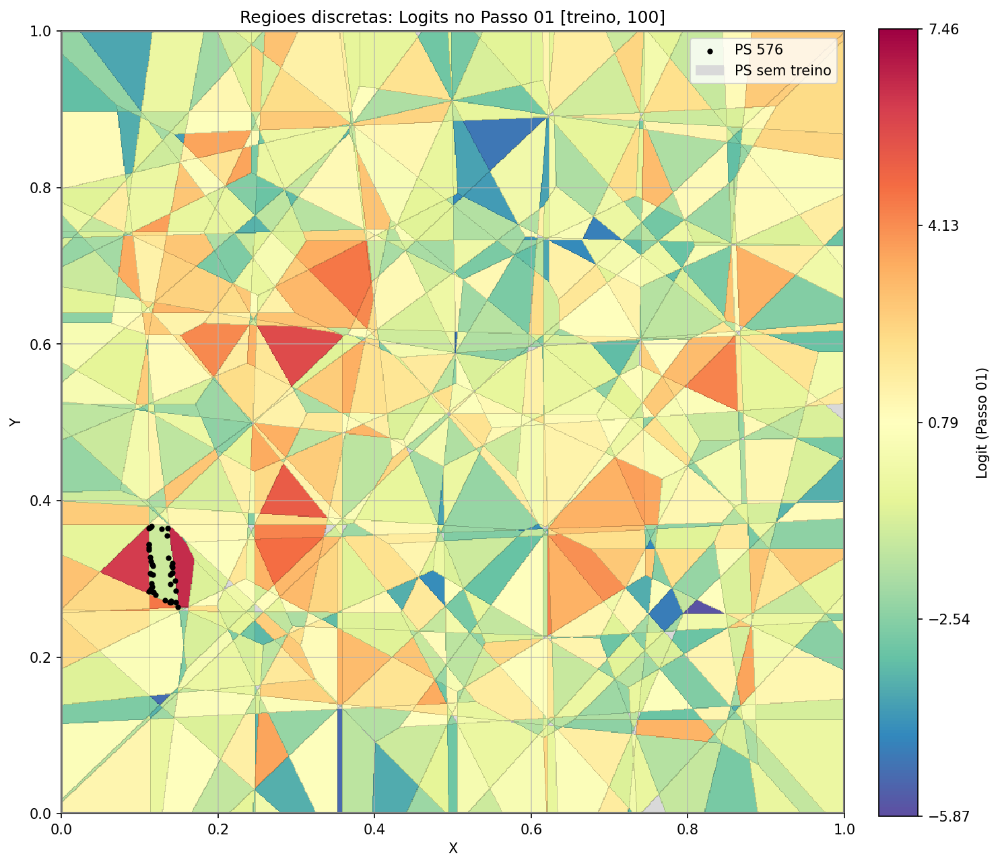

In [158]:
step_to_plot = 1
plot_next_id_logits_map_discreto(
    df_states=df,
    logits_df=snapshot_steps_df(full_fwd_100, 'logits'),
    current_id=current_id_for_step(full_fwd_100, step_to_plot),
    step=step_to_plot,
    cmap="Spectral_r",
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
    title_tag = '[treino, 100]'
)
plt.show()

Referencia: celula original 156

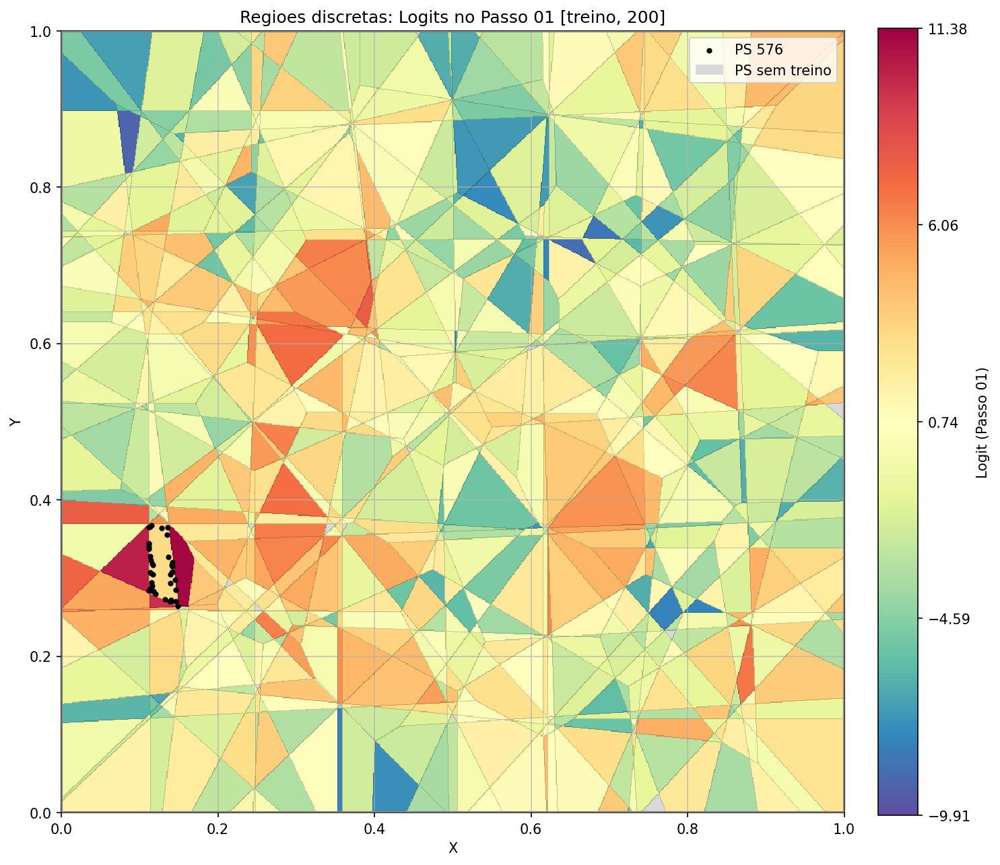

In [159]:
step_to_plot = 1
plot_next_id_logits_map_discreto(
    df_states=df,
    logits_df=snapshot_steps_df(full_fwd_200, 'logits'),
    current_id=current_id_for_step(full_fwd_200, step_to_plot),
    step=step_to_plot,
    cmap="Spectral_r",
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
    title_tag = '[treino, 200]'
)
plt.show()

Referencia: celula original 158

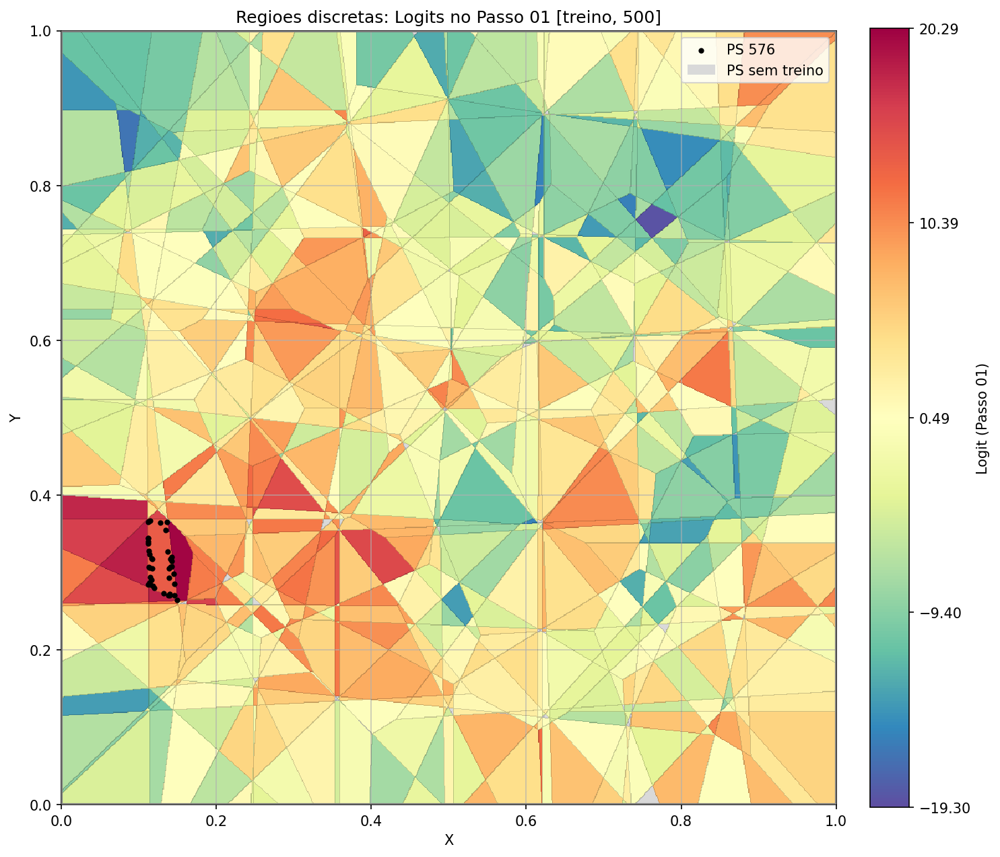

In [160]:
step_to_plot = 1
plot_next_id_logits_map_discreto(
    df_states=df,
    logits_df=snapshot_steps_df(full_fwd_500, 'logits'),
    current_id=current_id_for_step(full_fwd_500, step_to_plot),
    step=step_to_plot,
    cmap="Spectral_r",
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
    title_tag = '[treino, 500]'
)
plt.show()

Referencia: celula original 160

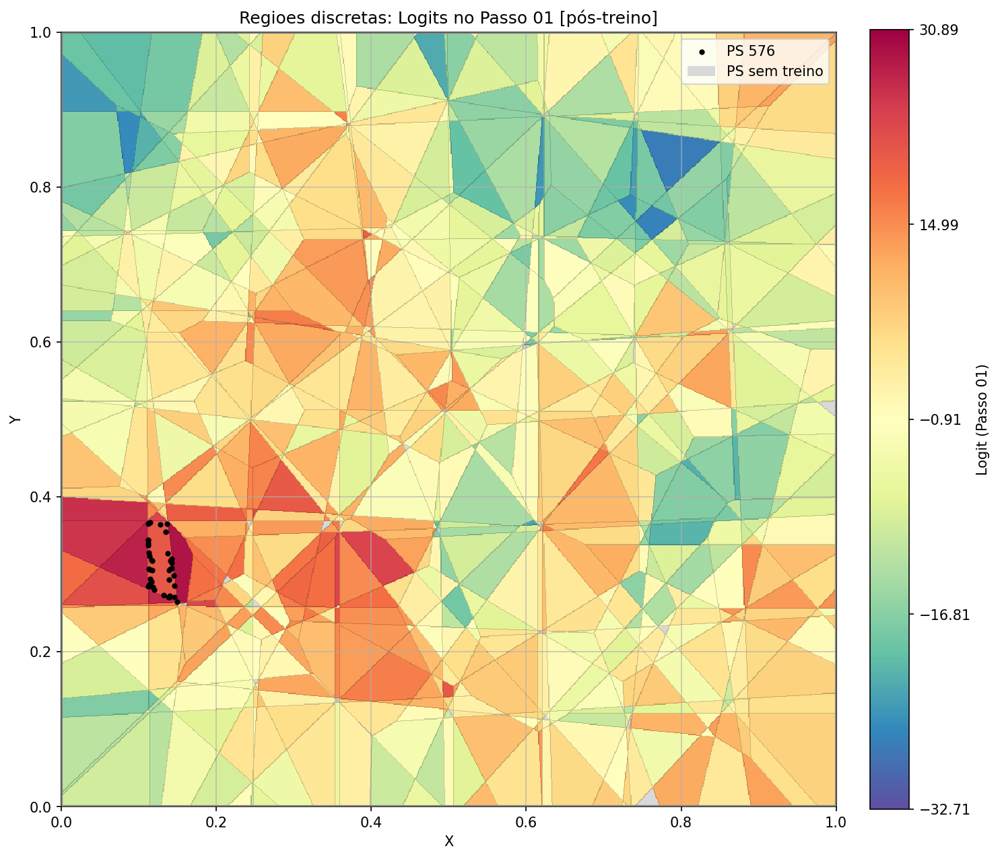

In [161]:
step_to_plot = 1
plot_next_id_logits_map_discreto(
    df_states=df,
    logits_df=snapshot_steps_df(full_fwd, 'logits'),
    current_id=current_id_for_step(full_fwd, step_to_plot),
    step=step_to_plot,
    cmap="Spectral_r",
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
    title_tag = '[pós-treino]'
)
plt.show()

Referencia: celula original 162

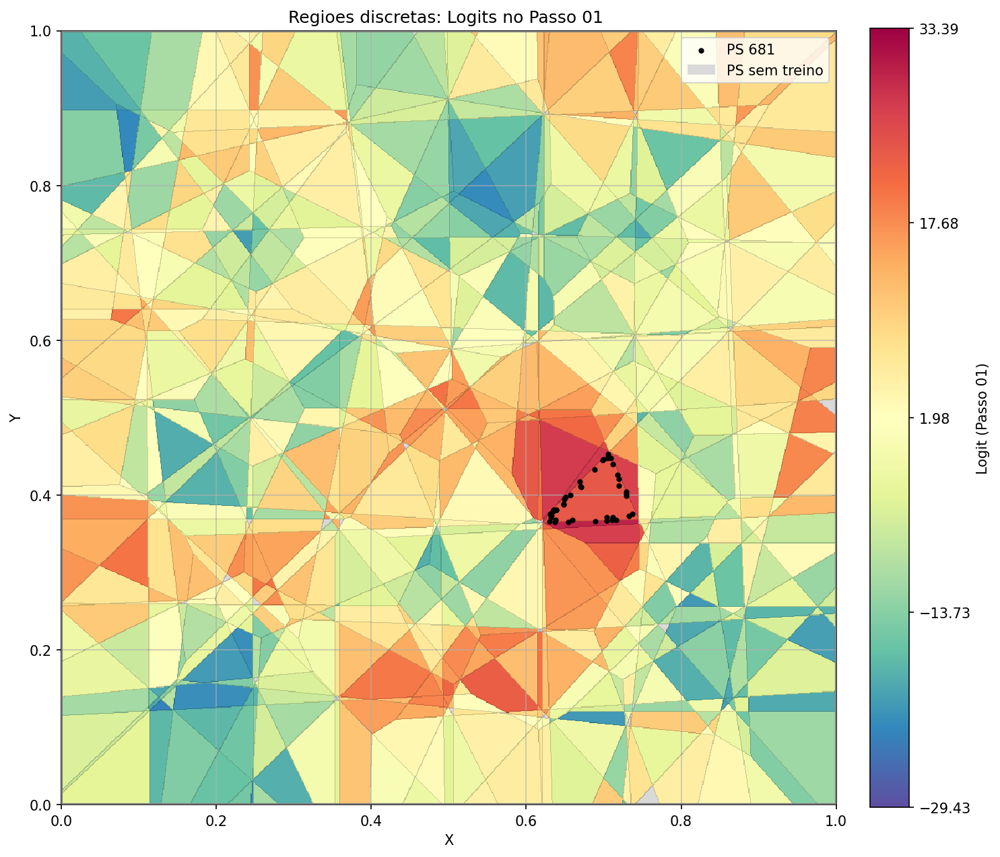

In [162]:
step_to_plot = 1
plot_next_id_logits_map_discreto(
    df_states=df,
    logits_df=distribs_logits,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="Spectral_r",
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
)
plt.show()

Referencia: celula original 163

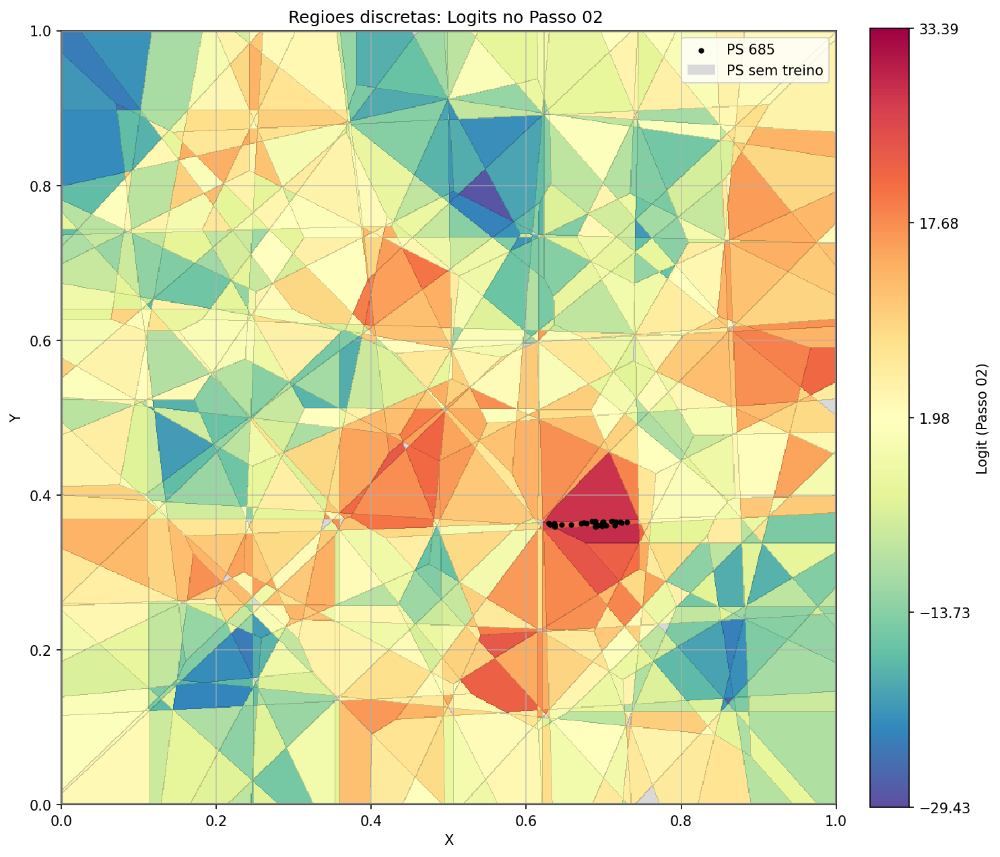

In [163]:
step_to_plot = 2
plot_next_id_logits_map_discreto(
    df_states=df,
    logits_df=distribs_logits,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="Spectral_r",
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
)
plt.show()

Referencia: celula original 164

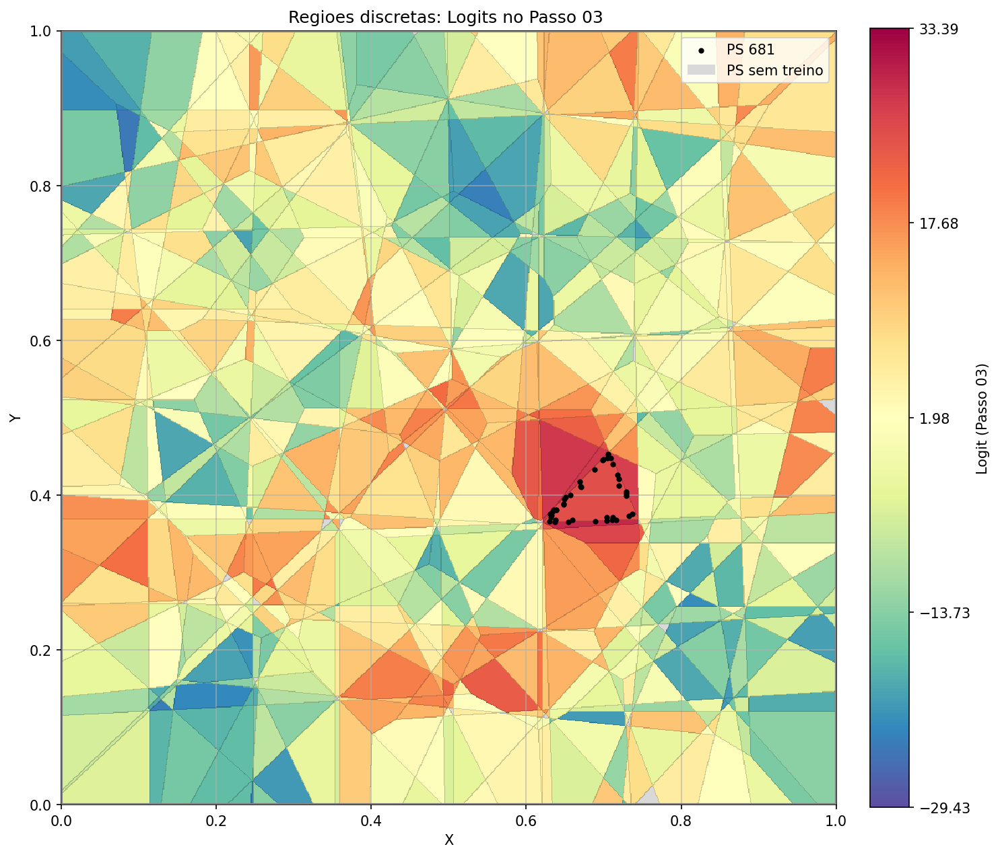

In [164]:
step_to_plot = 3
plot_next_id_logits_map_discreto(
    df_states=df,
    logits_df=distribs_logits,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="Spectral_r",
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
)
plt.show()

Referencia: celula original 165

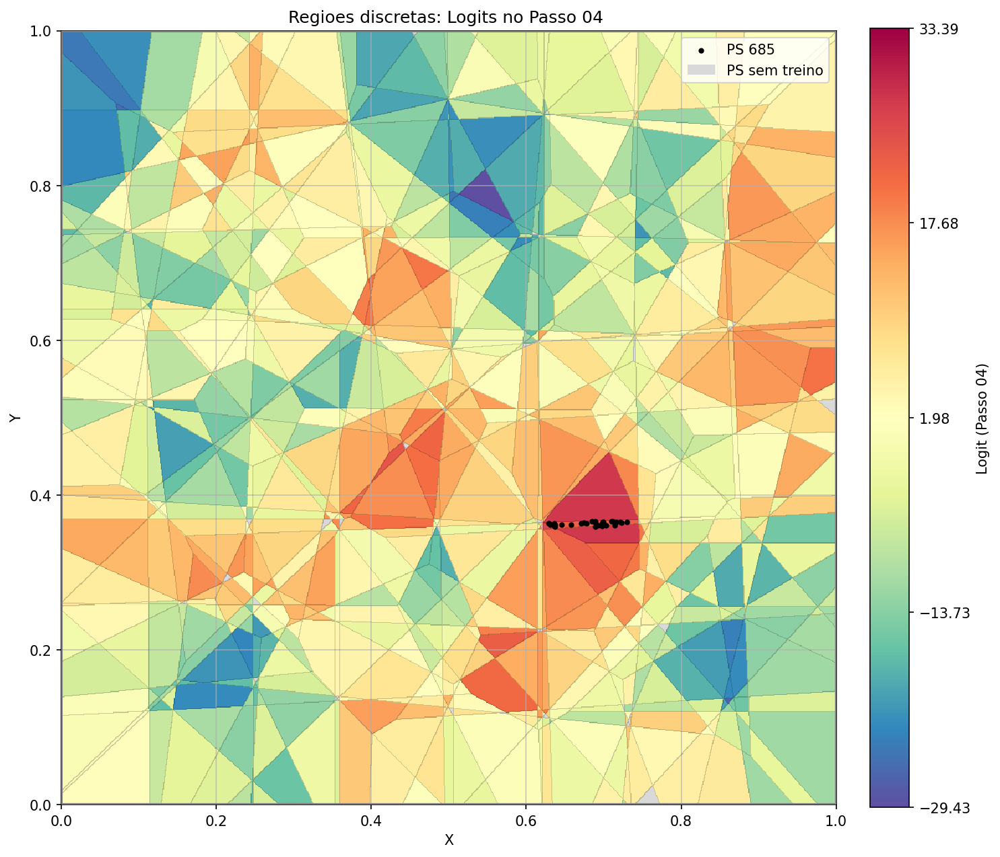

In [165]:
step_to_plot = 4
plot_next_id_logits_map_discreto(
    df_states=df,
    logits_df=distribs_logits,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="Spectral_r",
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
)
plt.show()

Referencia: celula original 166

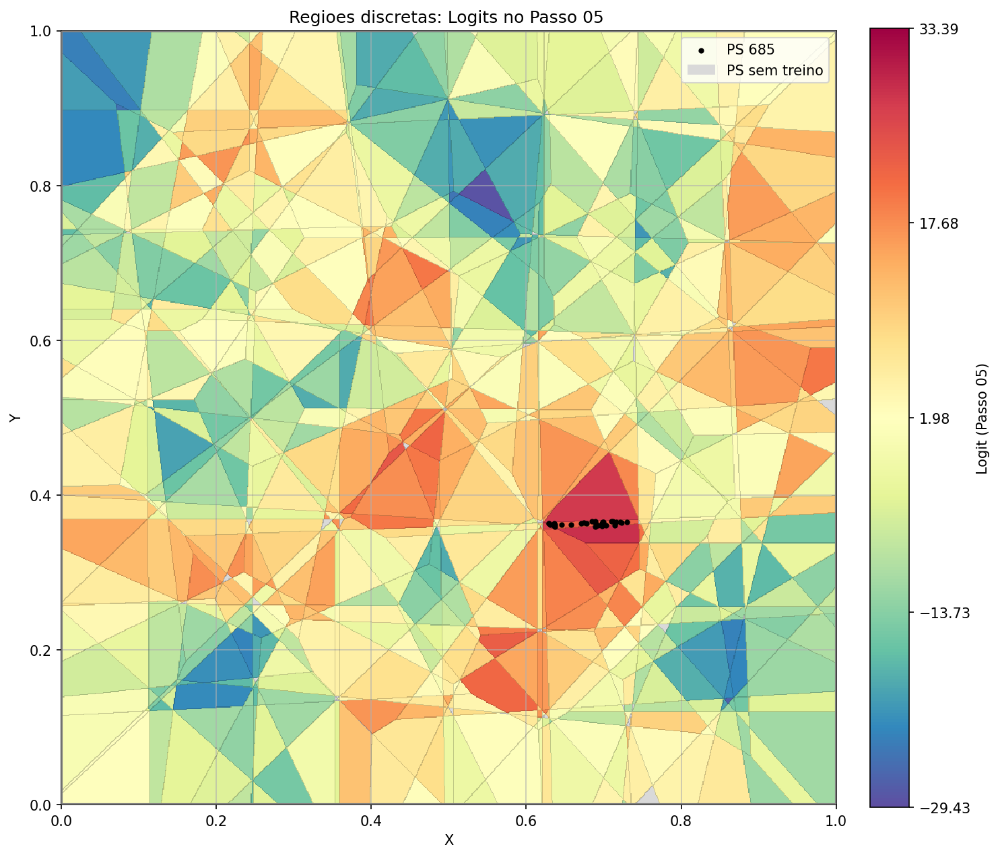

In [166]:
step_to_plot = 5
plot_next_id_logits_map_discreto(
    df_states=df,
    logits_df=distribs_logits,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="Spectral_r",
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
)
plt.show()

Referencia: celula original 167

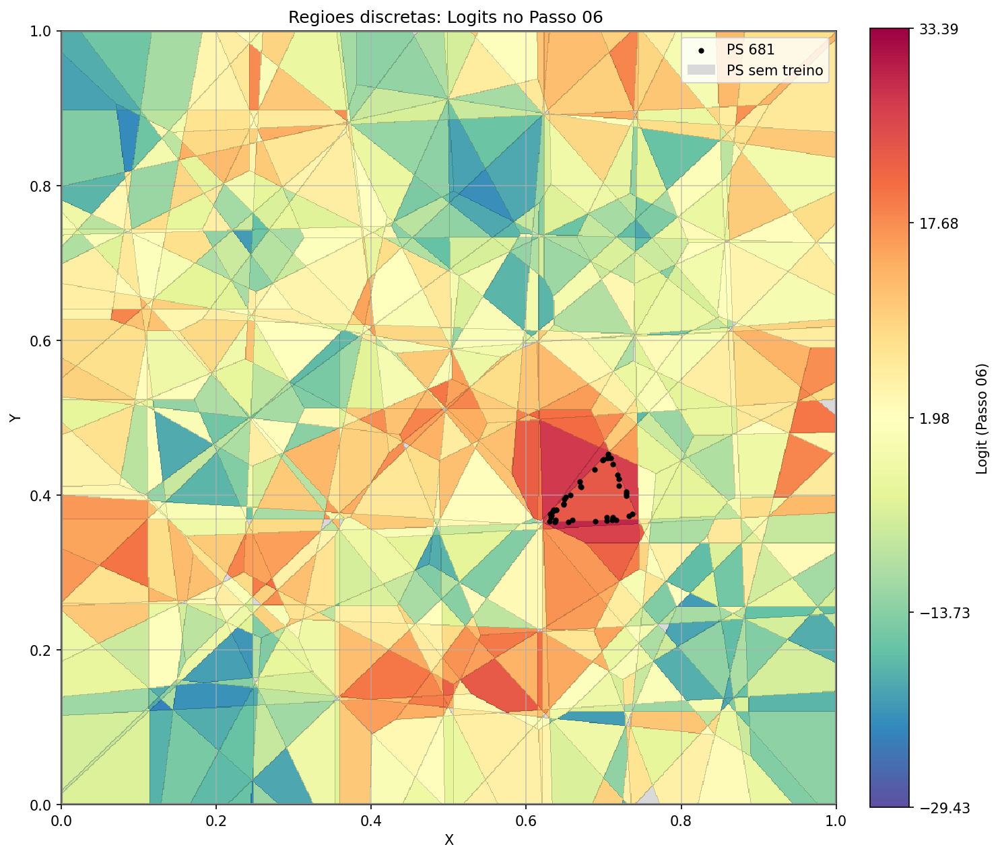

In [167]:
step_to_plot = 6
plot_next_id_logits_map_discreto(
    df_states=df,
    logits_df=distribs_logits,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="Spectral_r",
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
)
plt.show()

Referencia: celula original 168

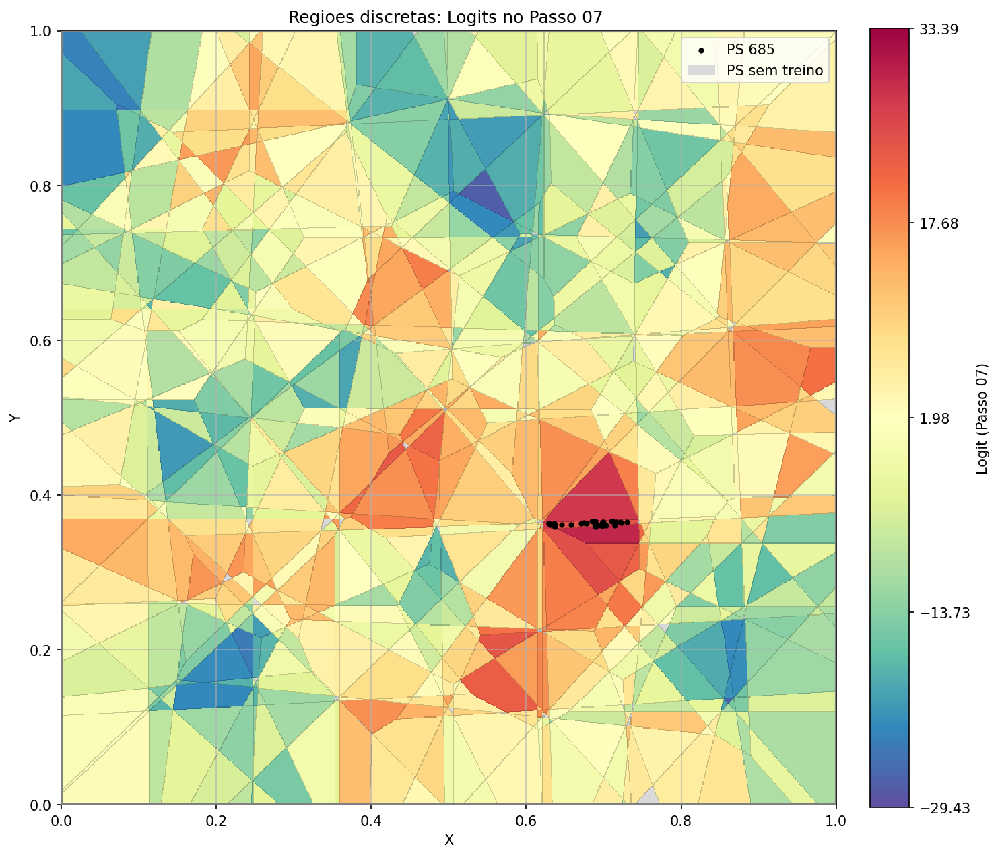

In [168]:
step_to_plot = 7
plot_next_id_logits_map_discreto(
    df_states=df,
    logits_df=distribs_logits,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="Spectral_r",
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
)
plt.show()

Referencia: celula original 169

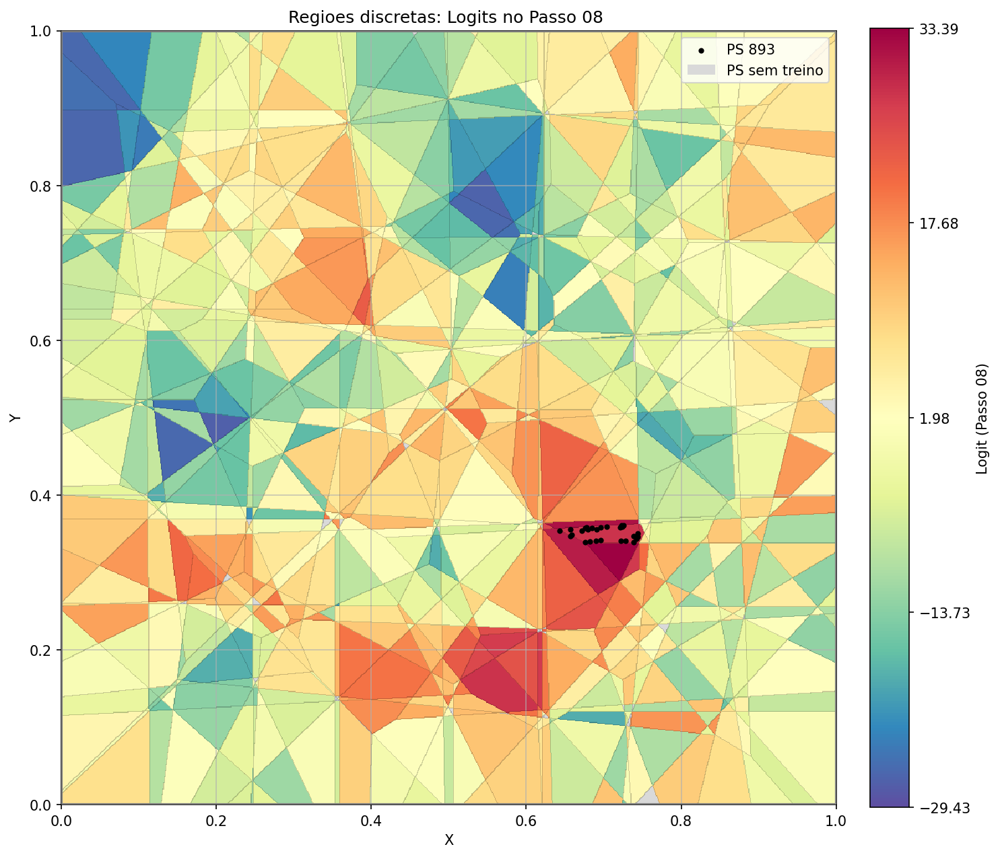

In [169]:
step_to_plot = 8
plot_next_id_logits_map_discreto(
    df_states=df,
    logits_df=distribs_logits,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="Spectral_r",
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
)
plt.show()

Referencia: celula original 170

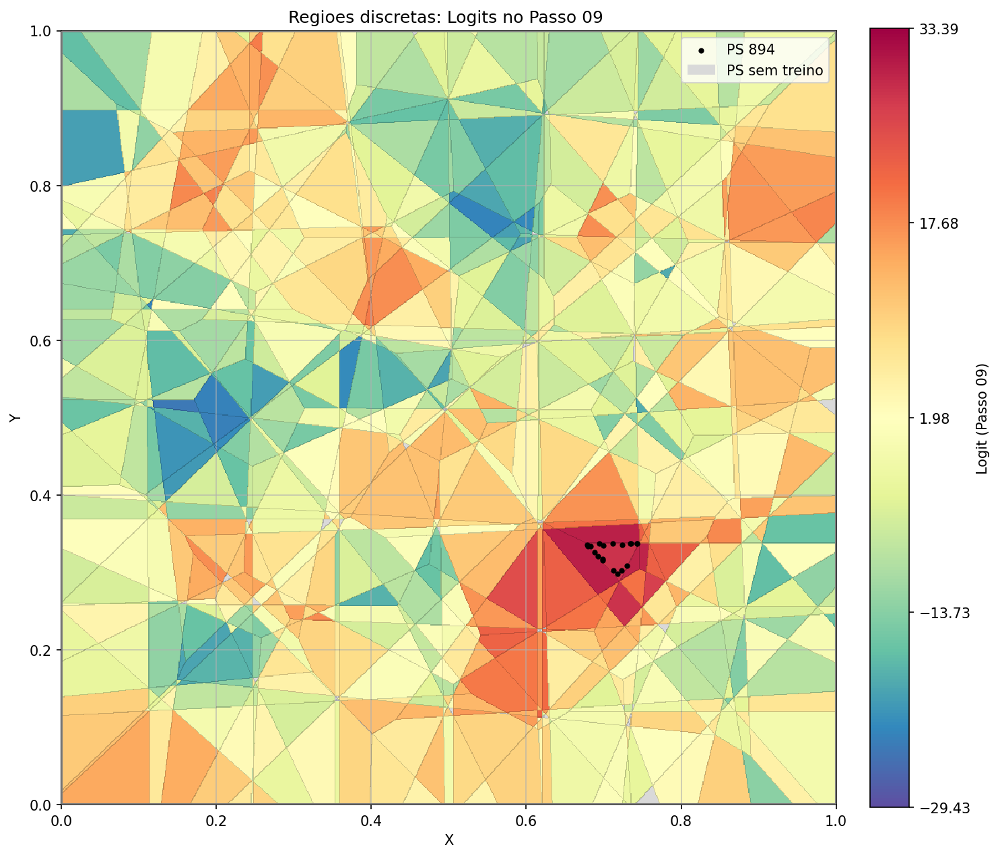

In [170]:
step_to_plot = 9
plot_next_id_logits_map_discreto(
    df_states=df,
    logits_df=distribs_logits,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="Spectral_r",
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
)
plt.show()

Referencia: celula original 171

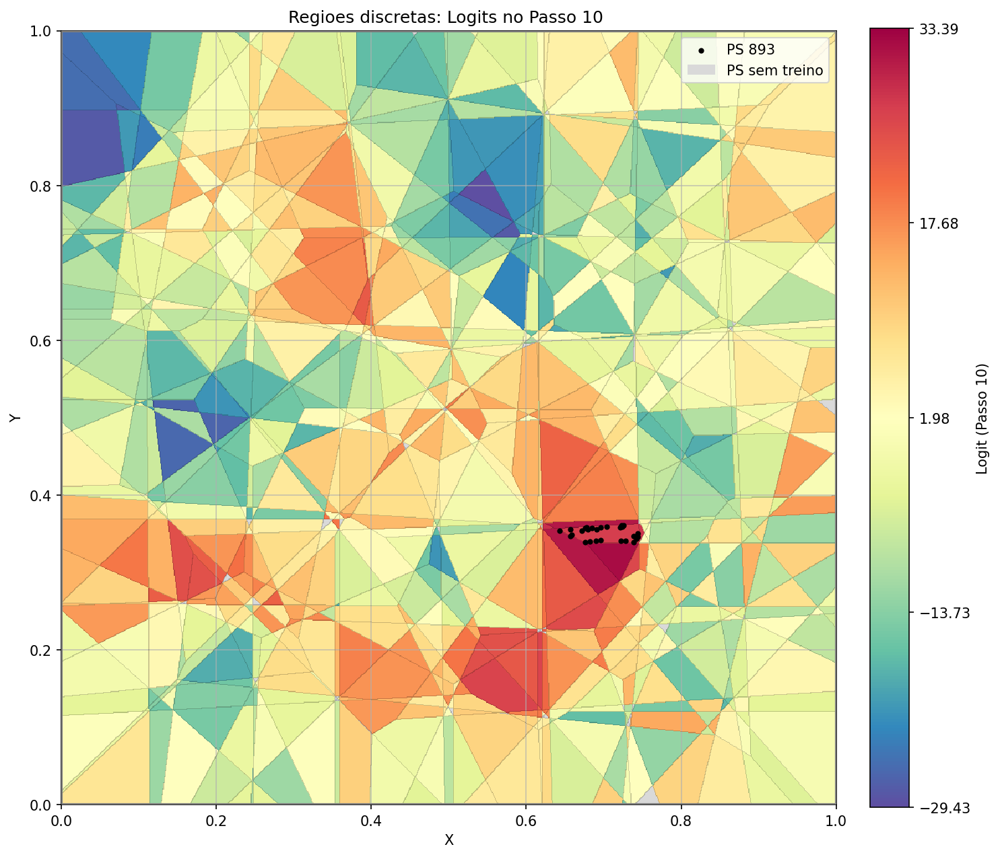

In [171]:
step_to_plot = 10
plot_next_id_logits_map_discreto(
    df_states=df,
    logits_df=distribs_logits,
    current_id=generated_current_id(generation_681, step_to_plot),
    step=step_to_plot,
    cmap="Spectral_r",
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
)
plt.show()

Referencia: celula original 173

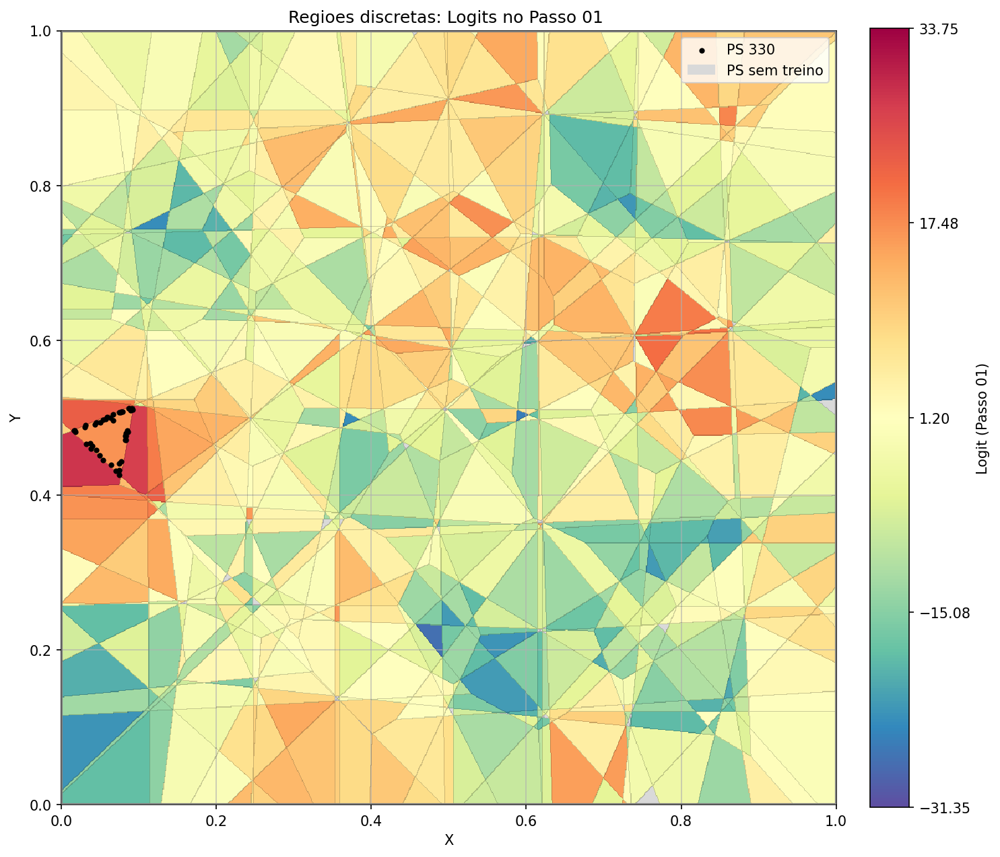

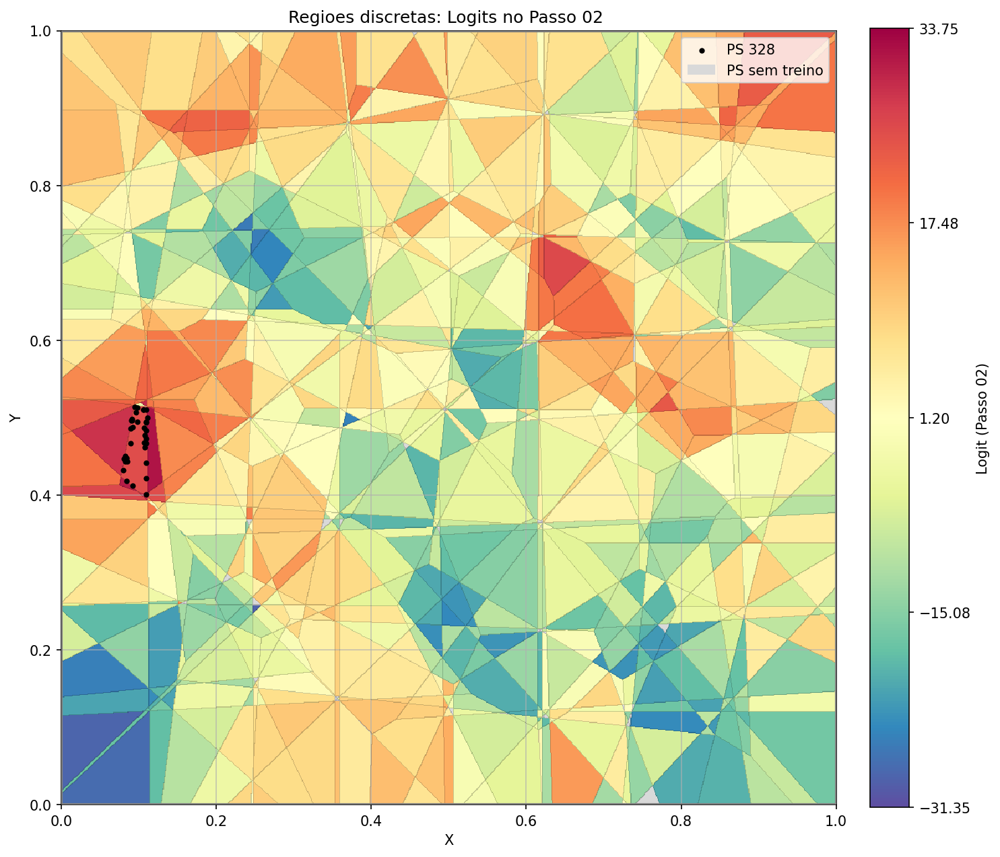

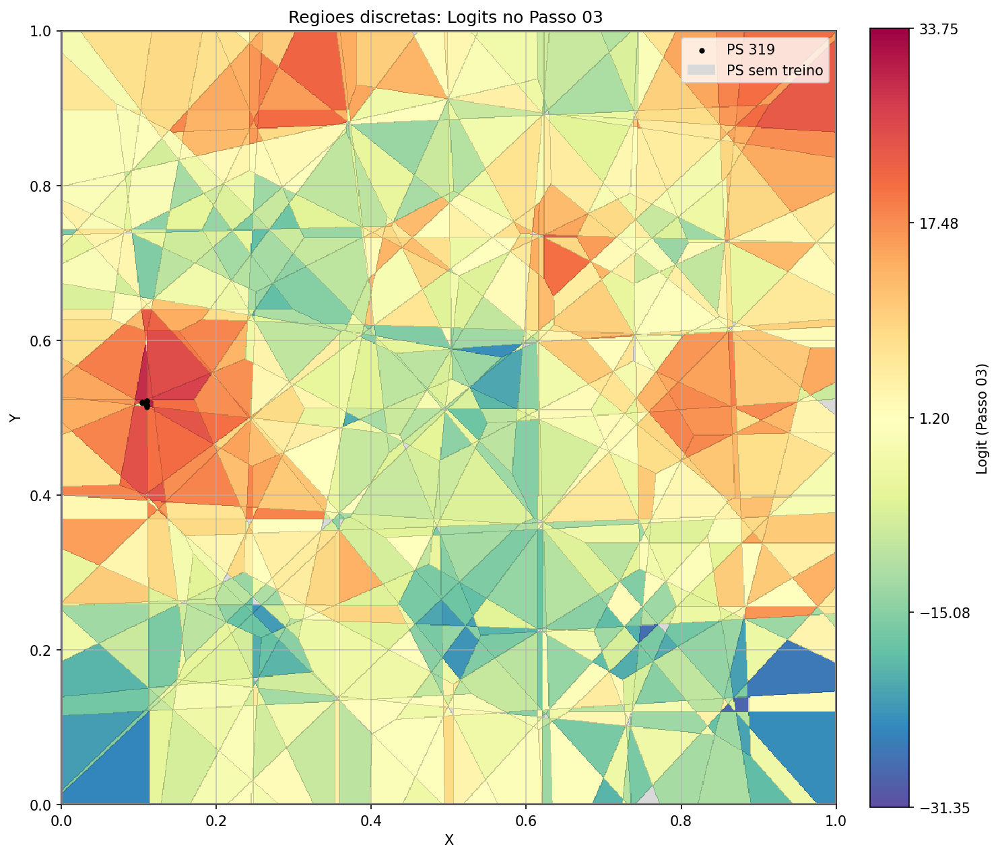

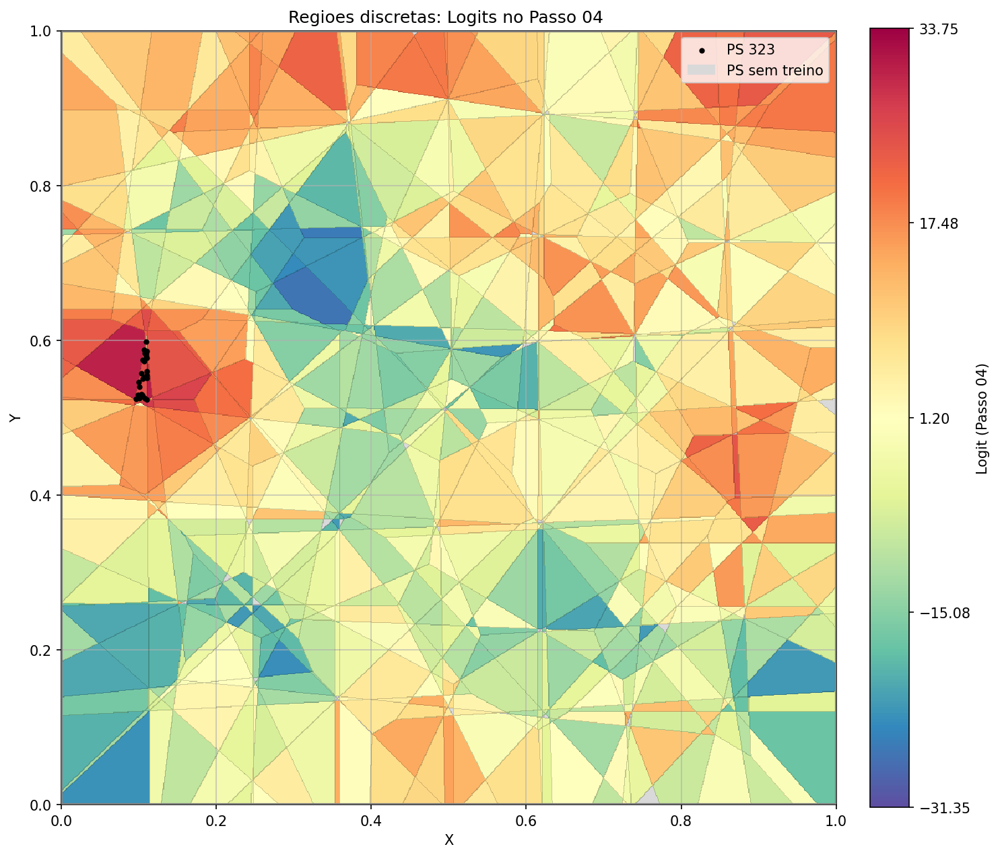

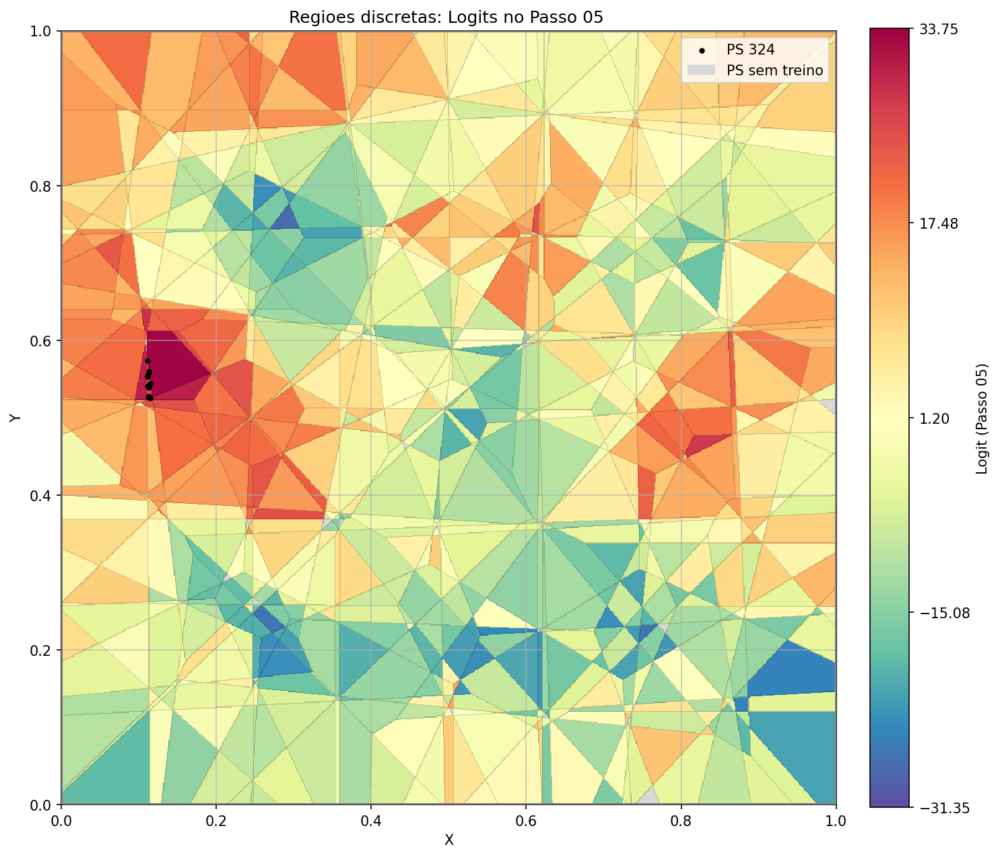

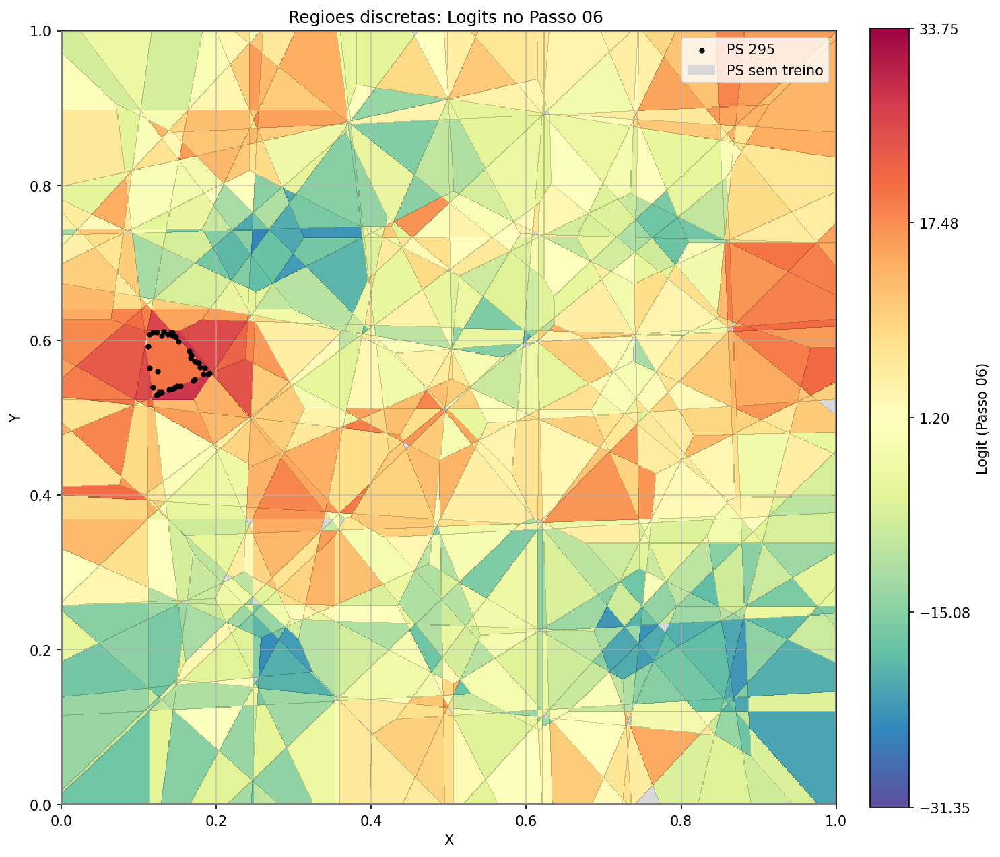

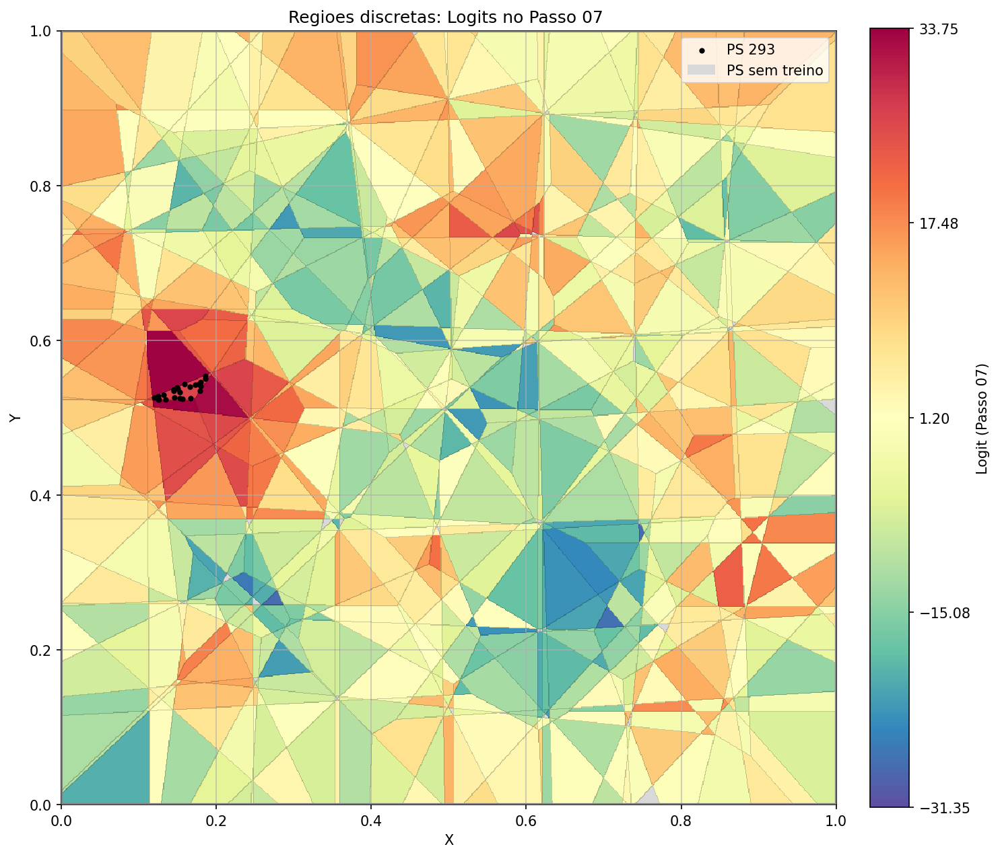

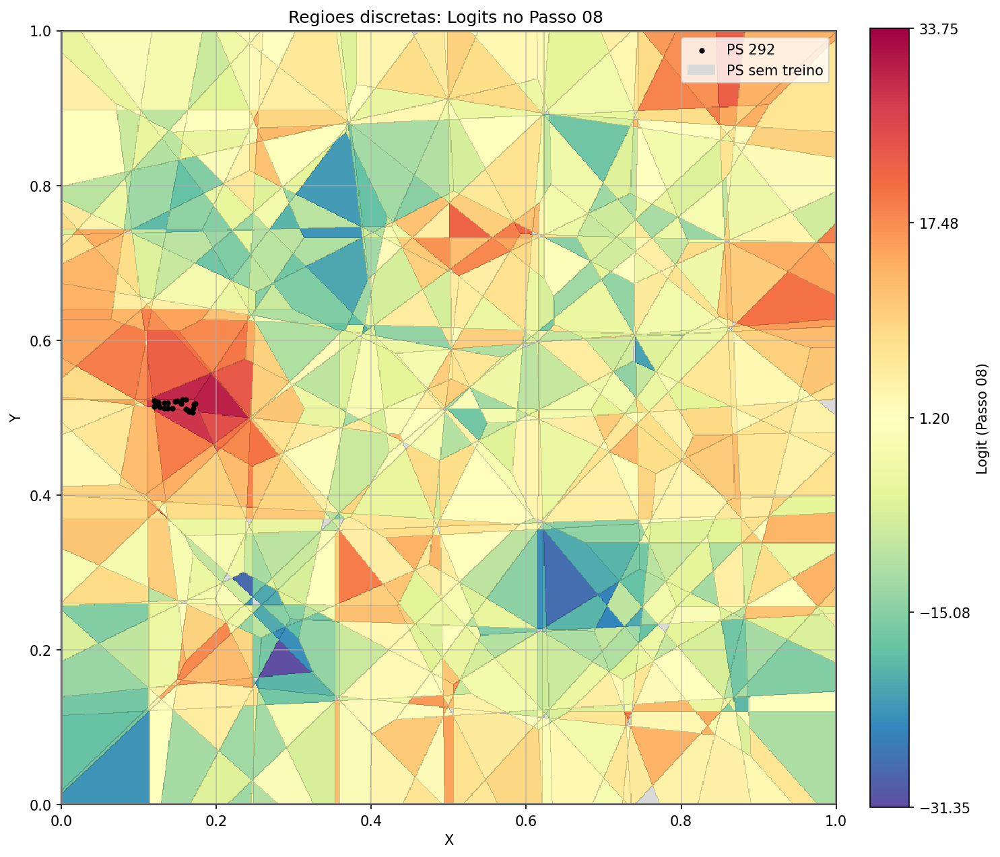

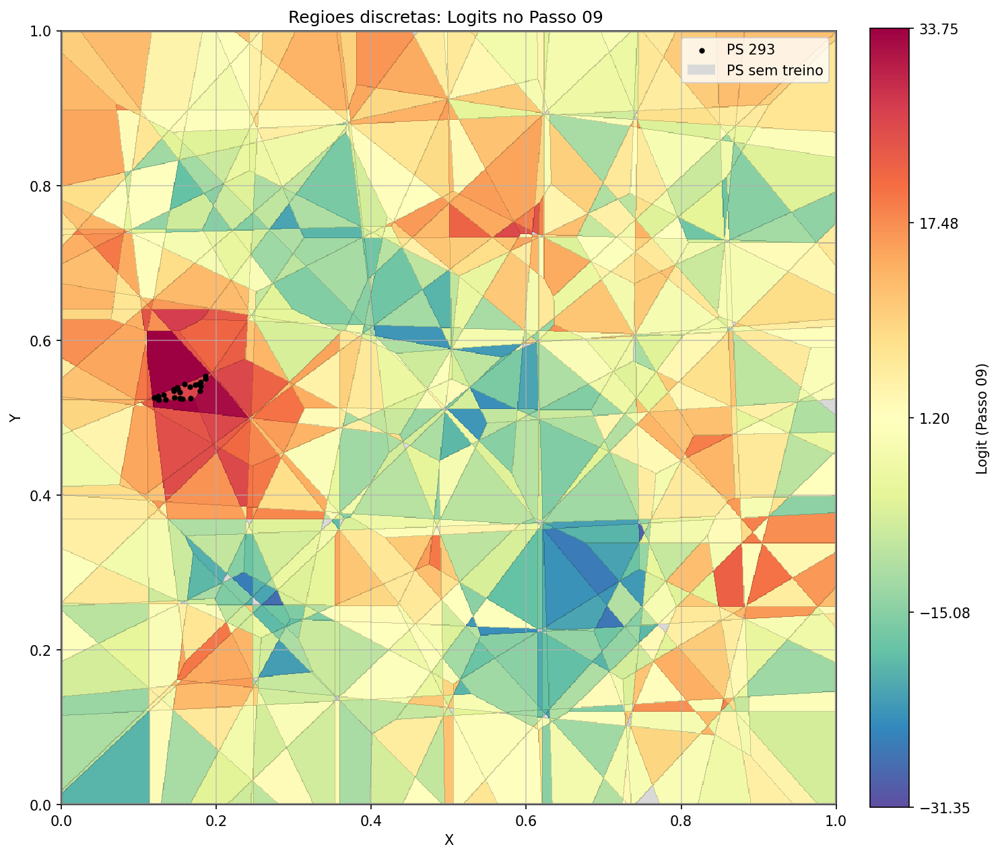

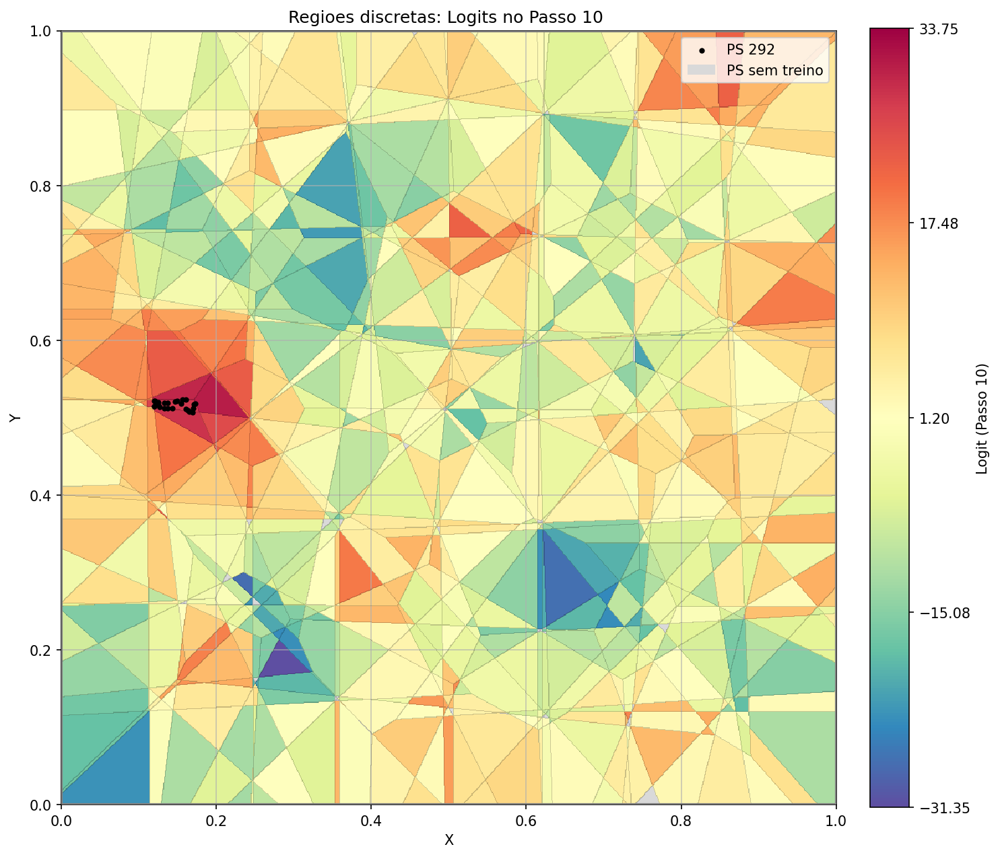

In [172]:
for i in range(1, 11):
    step_to_plot = i
    plot_next_id_logits_map_discreto(
        df_states=df,
        logits_df=distribs_logits507,
        current_id=generated_current_id(generation_507, step_to_plot),
        step=step_to_plot,
        cmap="Spectral_r",
        logit_power=1.,
        current_color="k",
        current_size=10,
        current_alpha=1,
        show_current_label=False,
        center_colormap_at_zero=False,
    )
    plt.show()